# Experiment 2 — Research Visualization Redesign (EXERCISE-2)

**Course:** M.E. CSE — Data Visualization Lab
**Task:** take fifteen published research-paper figures, identify the visual
design problems that make them hard to read, and rebuild them as clear,
honest Python/Matplotlib visualizations.

| | |
|---|---|
| **Inputs** | `15-paper-redesign/15_paper_selection_table.csv` (paper, source, year, chart type, redesign problem) |
| **Scripts** | `15-paper-redesign/python/paper_01_improved.py` … `paper_15_improved.py` (one per paper) |
| **Runner** | `15-paper-redesign/python/run_all_visualizations.py` |
| **Exercise data** | `python/research_visualization_redesigns.py` (three EXERCISE-2 figures) |
| **Outputs** | `visualizations/paper_XX_improved.png` — on Kaggle: `/kaggle/working/visualizations` |

> **Academic-integrity note.** Original research figures are identified by paper
> and figure number. Where exact numerical values were not available in the
> accessible text or tables, the redesign is an *educational / conceptual
> reconstruction*: it does **not** claim to reproduce the authors' empirical
> results. The improved figures are original Python-generated designs.


## 1. Environment

The notebook is fully self-contained: it only needs `numpy` and
`matplotlib`, both of which ship with the Kaggle Python runtime.


In [1]:

import os
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np

# Every figure this notebook saves goes here (works locally and on Kaggle).
os.environ.setdefault("EX2_VIS_DIR", str(Path.cwd() / "visualizations"))
VIS_DIR = Path(os.environ["EX2_VIS_DIR"])
VIS_DIR.mkdir(parents=True, exist_ok=True)

print("Python      :", sys.version.split()[0])
print("NumPy       :", np.__version__)
print("Matplotlib  :", matplotlib.__version__)
print("Figure output:", VIS_DIR)


Python      : 3.11.9
NumPy       : 2.4.6
Matplotlib  : 3.11.2
Figure output: C:\Users\agnes\AppData\Local\Temp\opencode\exp2_kaggle_vis


## 2. EXERCISE-2 visualizations

Three figures belonging to the exercise itself (comprehension score,
decision intention, presentation preference), plotted from the published
summary statistics. Raw scores are on a 0–6 scale; percentages are of
participants choosing each format.


**Trial A — mean comprehension score (0–6).** Horizontal bars with the standard deviation as an error bar; the value labels sit next to the bar so no legend lookup is needed.


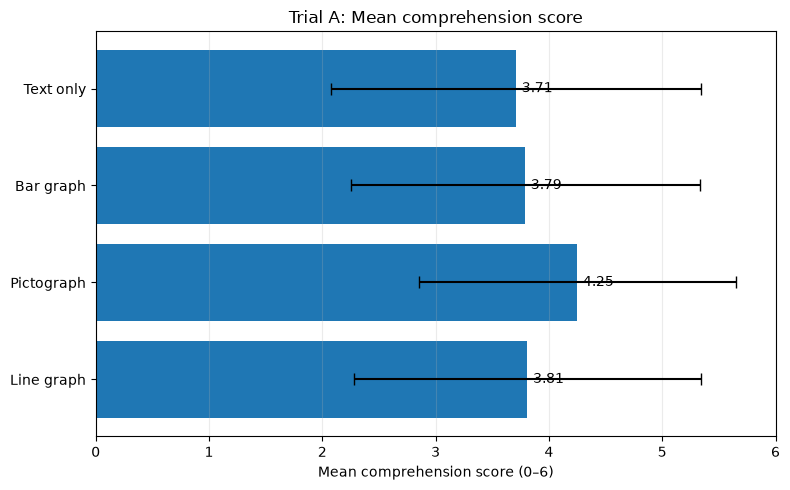

In [2]:
# VISUALIZATION 1 — COMPREHENSION SCORE

import matplotlib.pyplot as plt
import numpy as np

groups = ["Text only", "Bar graph", "Pictograph", "Line graph"]
mean = [3.71, 3.79, 4.25, 3.81]
sd = [1.63, 1.54, 1.40, 1.53]

fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(groups))

ax.barh(y, mean, xerr=sd, capsize=4)
ax.set_yticks(y, groups)
ax.invert_yaxis()
ax.set_xlim(0, 6)
ax.set_xlabel("Mean comprehension score (0–6)")
ax.set_title("Trial A: Mean comprehension score")
ax.grid(axis="x", alpha=0.25)

for i, value in enumerate(mean):
    ax.text(value + 0.05, i, f"{value:.2f}", va="center")

plt.tight_layout()
plt.show()


**Trial A — decision intention before vs after.** Grouped bars make the before/after comparison a distance the eye can measure directly.


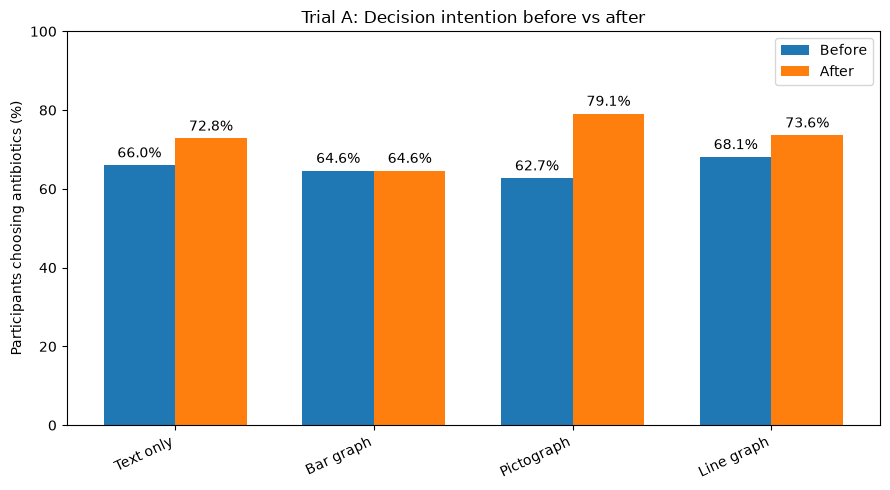

In [3]:
# VISUALIZATION 2 — DECISION INTENTION

import matplotlib.pyplot as plt
import numpy as np

groups = ["Text only", "Bar graph", "Pictograph", "Line graph"]
before = [66.0, 64.6, 62.7, 68.1]
after  = [72.8, 64.6, 79.1, 73.6]

x = np.arange(len(groups))
width = 0.36

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - width/2, before, width, label="Before")
ax.bar(x + width/2, after, width, label="After")

ax.set_xticks(x, groups, rotation=25, ha="right")
ax.set_ylim(0, 100)
ax.set_ylabel("Participants choosing antibiotics (%)")
ax.set_title("Trial A: Decision intention before vs after")
ax.legend()

for i, value in enumerate(before):
    ax.text(i - width/2, value + 2, f"{value:.1f}%", ha="center")
for i, value in enumerate(after):
    ax.text(i + width/2, value + 2, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()


**Visual presentation preference.** Percentage bars with the share written at the end of each bar — one unit (per cent) for every mark.


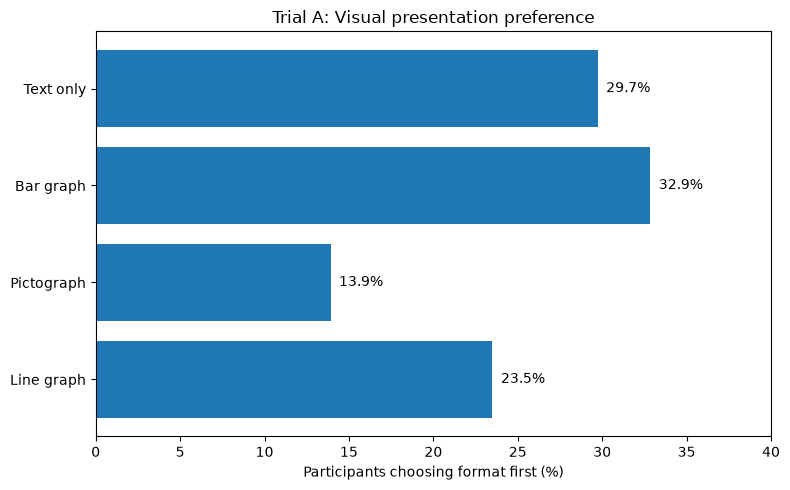

In [4]:
# VISUALIZATION 3 — PRESENTATION PREFERENCE

import matplotlib.pyplot as plt

labels = ["Text only", "Bar graph", "Pictograph", "Line graph"]
counts = [124, 137, 58, 98]
total = sum(counts)
percent = [c / total * 100 for c in counts]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(labels[::-1], percent[::-1])

ax.set_xlim(0, 40)
ax.set_xlabel("Participants choosing format first (%)")
ax.set_title("Trial A: Visual presentation preference")

for y, value in enumerate(percent[::-1]):
    ax.text(value + 0.5, y, f"{value:.1f}%", va="center")

plt.tight_layout()
plt.show()


## 3. Fifteen research-paper redesigns

### Redesign principles applied

| # | Principle | What it changes |
|---|-----------|-----------------|
| 1 | **Reduce non-data ink** | Decorative borders, heavy frames and redundant gridlines are dropped so the data carries the chart. |
| 2 | **Direct labelling** | Values sit next to their marks instead of being deferred to a distant legend. |
| 3 | **One clear reading order** | Grouping and spacing tell the eye where to start and where to go next. |
| 4 | **Restrained, consistent colour** | Colour encodes meaning (category / condition) rather than decoration. |
| 5 | **Titles that state the takeaway** | The title answers "what should I notice?" instead of only naming the variables. |

Each entry below pairs the paper with the redesign problem recorded for it and
the script that rebuilds the figure. The scripts write
`paper_XX_improved.png` into `VIS_DIR` and then render the figure inline.


#### 01. Visual Analytics: A Comprehensive Overview

*IEEE Xplore, 2019* — chart type: **Process / flow visualization**

**Redesign problem.** Dense multi-stage process can be improved through stronger hierarchy and directional grouping.


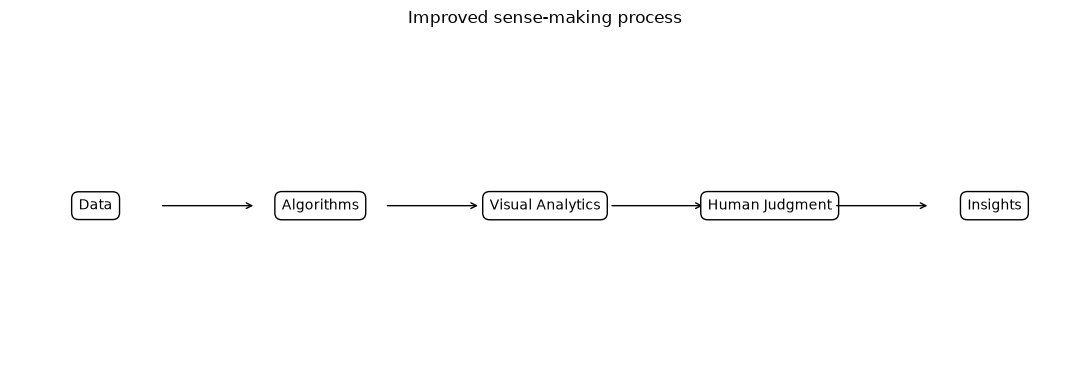

In [5]:
# Visual Analytics: A Comprehensive Overview
# Educational reconstruction for M.E. CSE Data Visualization Exercise-2.
# The reconstruction is NOT a reproduction of the authors' research findings.
# Replace only with published numerical values when the source provides them.
import matplotlib.pyplot as plt
import numpy as np


import os
from pathlib import Path as _Path


def _visualizations_dir() -> _Path:
    """Where saved figures go: env override -> repo folder -> cwd fallback."""
    if os.environ.get("EX2_VIS_DIR"):
        out = _Path(os.environ["EX2_VIS_DIR"])
    else:
        try:
            out = _Path(__file__).resolve().parent.parent / "visualizations"
        except NameError:  # exec()'d inside a notebook cell: no __file__
            out = _Path.cwd() / "visualizations"
    out.mkdir(parents=True, exist_ok=True)
    return out


# Illustrative reconstruction data / structure:
labels=["Data","Algorithms","Visual Analytics","Human Judgment","Insights"]

# Plot:
fig,ax=plt.subplots(figsize=(11,4)); ax.axis("off")
xs=np.linspace(.08,.92,5)
for k,(x,l) in enumerate(zip(xs,labels)):
    ax.text(x,.5,l,ha="center",va="center",bbox=dict(boxstyle="round,pad=.5",facecolor="white",edgecolor="black"))
    if k<4: ax.annotate("",(xs[k+1]-.06,.5),(x+.06,.5),arrowprops=dict(arrowstyle="->"))
ax.set_title("Improved sense-making process")

plt.tight_layout()
plt.savefig(_visualizations_dir() / "paper_01_improved.png", dpi=300, bbox_inches="tight")
plt.show()


paper_01_improved.png -> C:\Users\agnes\AppData\Local\Temp\opencode\exp2_kaggle_vis\paper_01_improved.png (55,339 bytes)


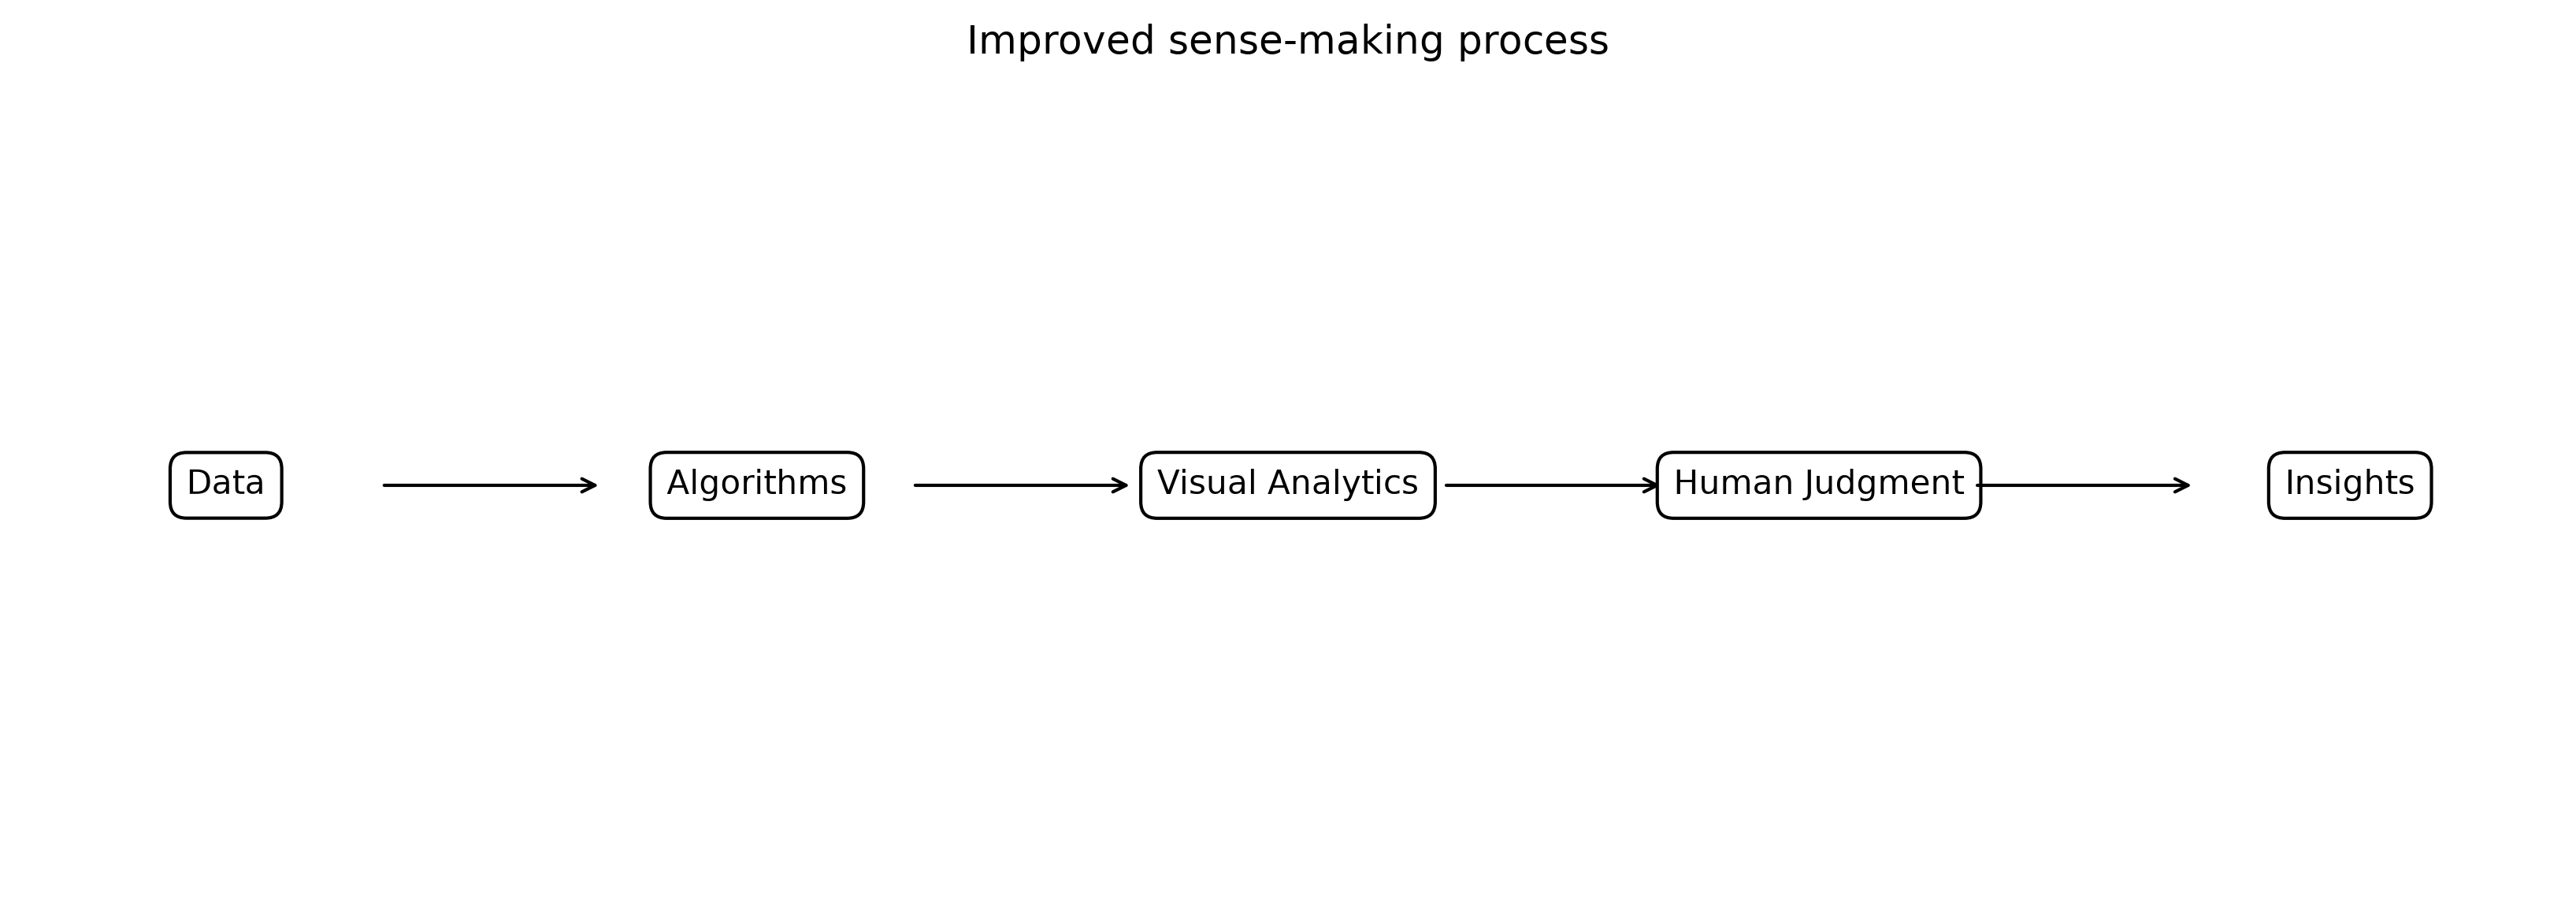

In [6]:

from IPython.display import Image, display
saved = VIS_DIR / "paper_01_improved.png"
size = saved.stat().st_size if saved.exists() else 0
print("paper_01_improved.png ->", saved, f"({size:,} bytes)" if saved.exists() else "(not written)")
if saved.exists():
    display(Image(filename=str(saved), width=780))


#### 02. The efficacy of stacked bar charts in supporting single-attribute and overall-attribute comparisons

*ScienceDirect, 2018* — chart type: **Stacked bar chart**

**Redesign problem.** Segment alignment makes some cross-category comparisons harder than aligned-position alternatives.


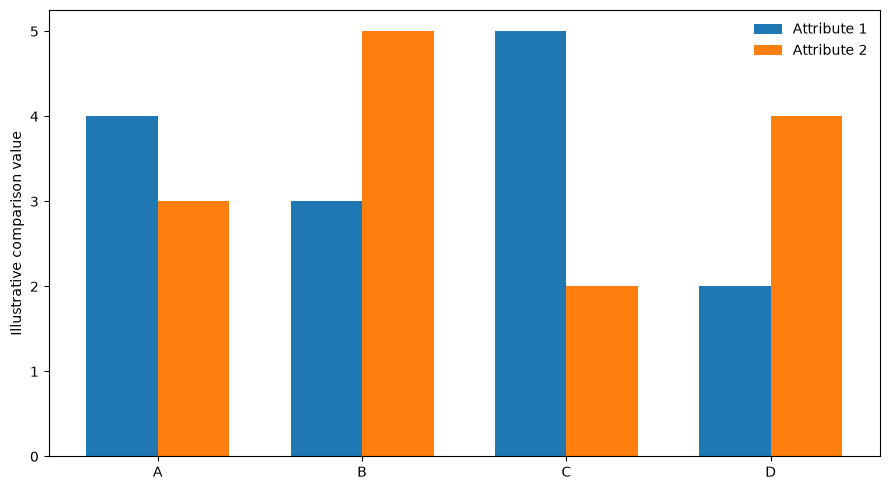

In [7]:
# The efficacy of stacked bar charts in supporting single-attribute and overall-attribute comparisons
# Educational reconstruction for M.E. CSE Data Visualization Exercise-2.
# The reconstruction is NOT a reproduction of the authors' research findings.
# Replace only with published numerical values when the source provides them.
import matplotlib.pyplot as plt
import numpy as np


import os
from pathlib import Path as _Path


def _visualizations_dir() -> _Path:
    """Where saved figures go: env override -> repo folder -> cwd fallback."""
    if os.environ.get("EX2_VIS_DIR"):
        out = _Path(os.environ["EX2_VIS_DIR"])
    else:
        try:
            out = _Path(__file__).resolve().parent.parent / "visualizations"
        except NameError:  # exec()'d inside a notebook cell: no __file__
            out = _Path.cwd() / "visualizations"
    out.mkdir(parents=True, exist_ok=True)
    return out


# Illustrative reconstruction data / structure:
cats=["A","B","C","D"]; a=np.array([4,3,5,2]); b=np.array([3,5,2,4])

# Plot:
fig,ax=plt.subplots(figsize=(9,5)); x=np.arange(4); w=.35
ax.bar(x-w/2,a,w,label="Attribute 1"); ax.bar(x+w/2,b,w,label="Attribute 2")
ax.set_xticks(x,cats); ax.set_ylabel("Illustrative comparison value"); ax.legend(frameon=False)

plt.tight_layout()
plt.savefig(_visualizations_dir() / "paper_02_improved.png", dpi=300, bbox_inches="tight")
plt.show()


paper_02_improved.png -> C:\Users\agnes\AppData\Local\Temp\opencode\exp2_kaggle_vis\paper_02_improved.png (48,932 bytes)


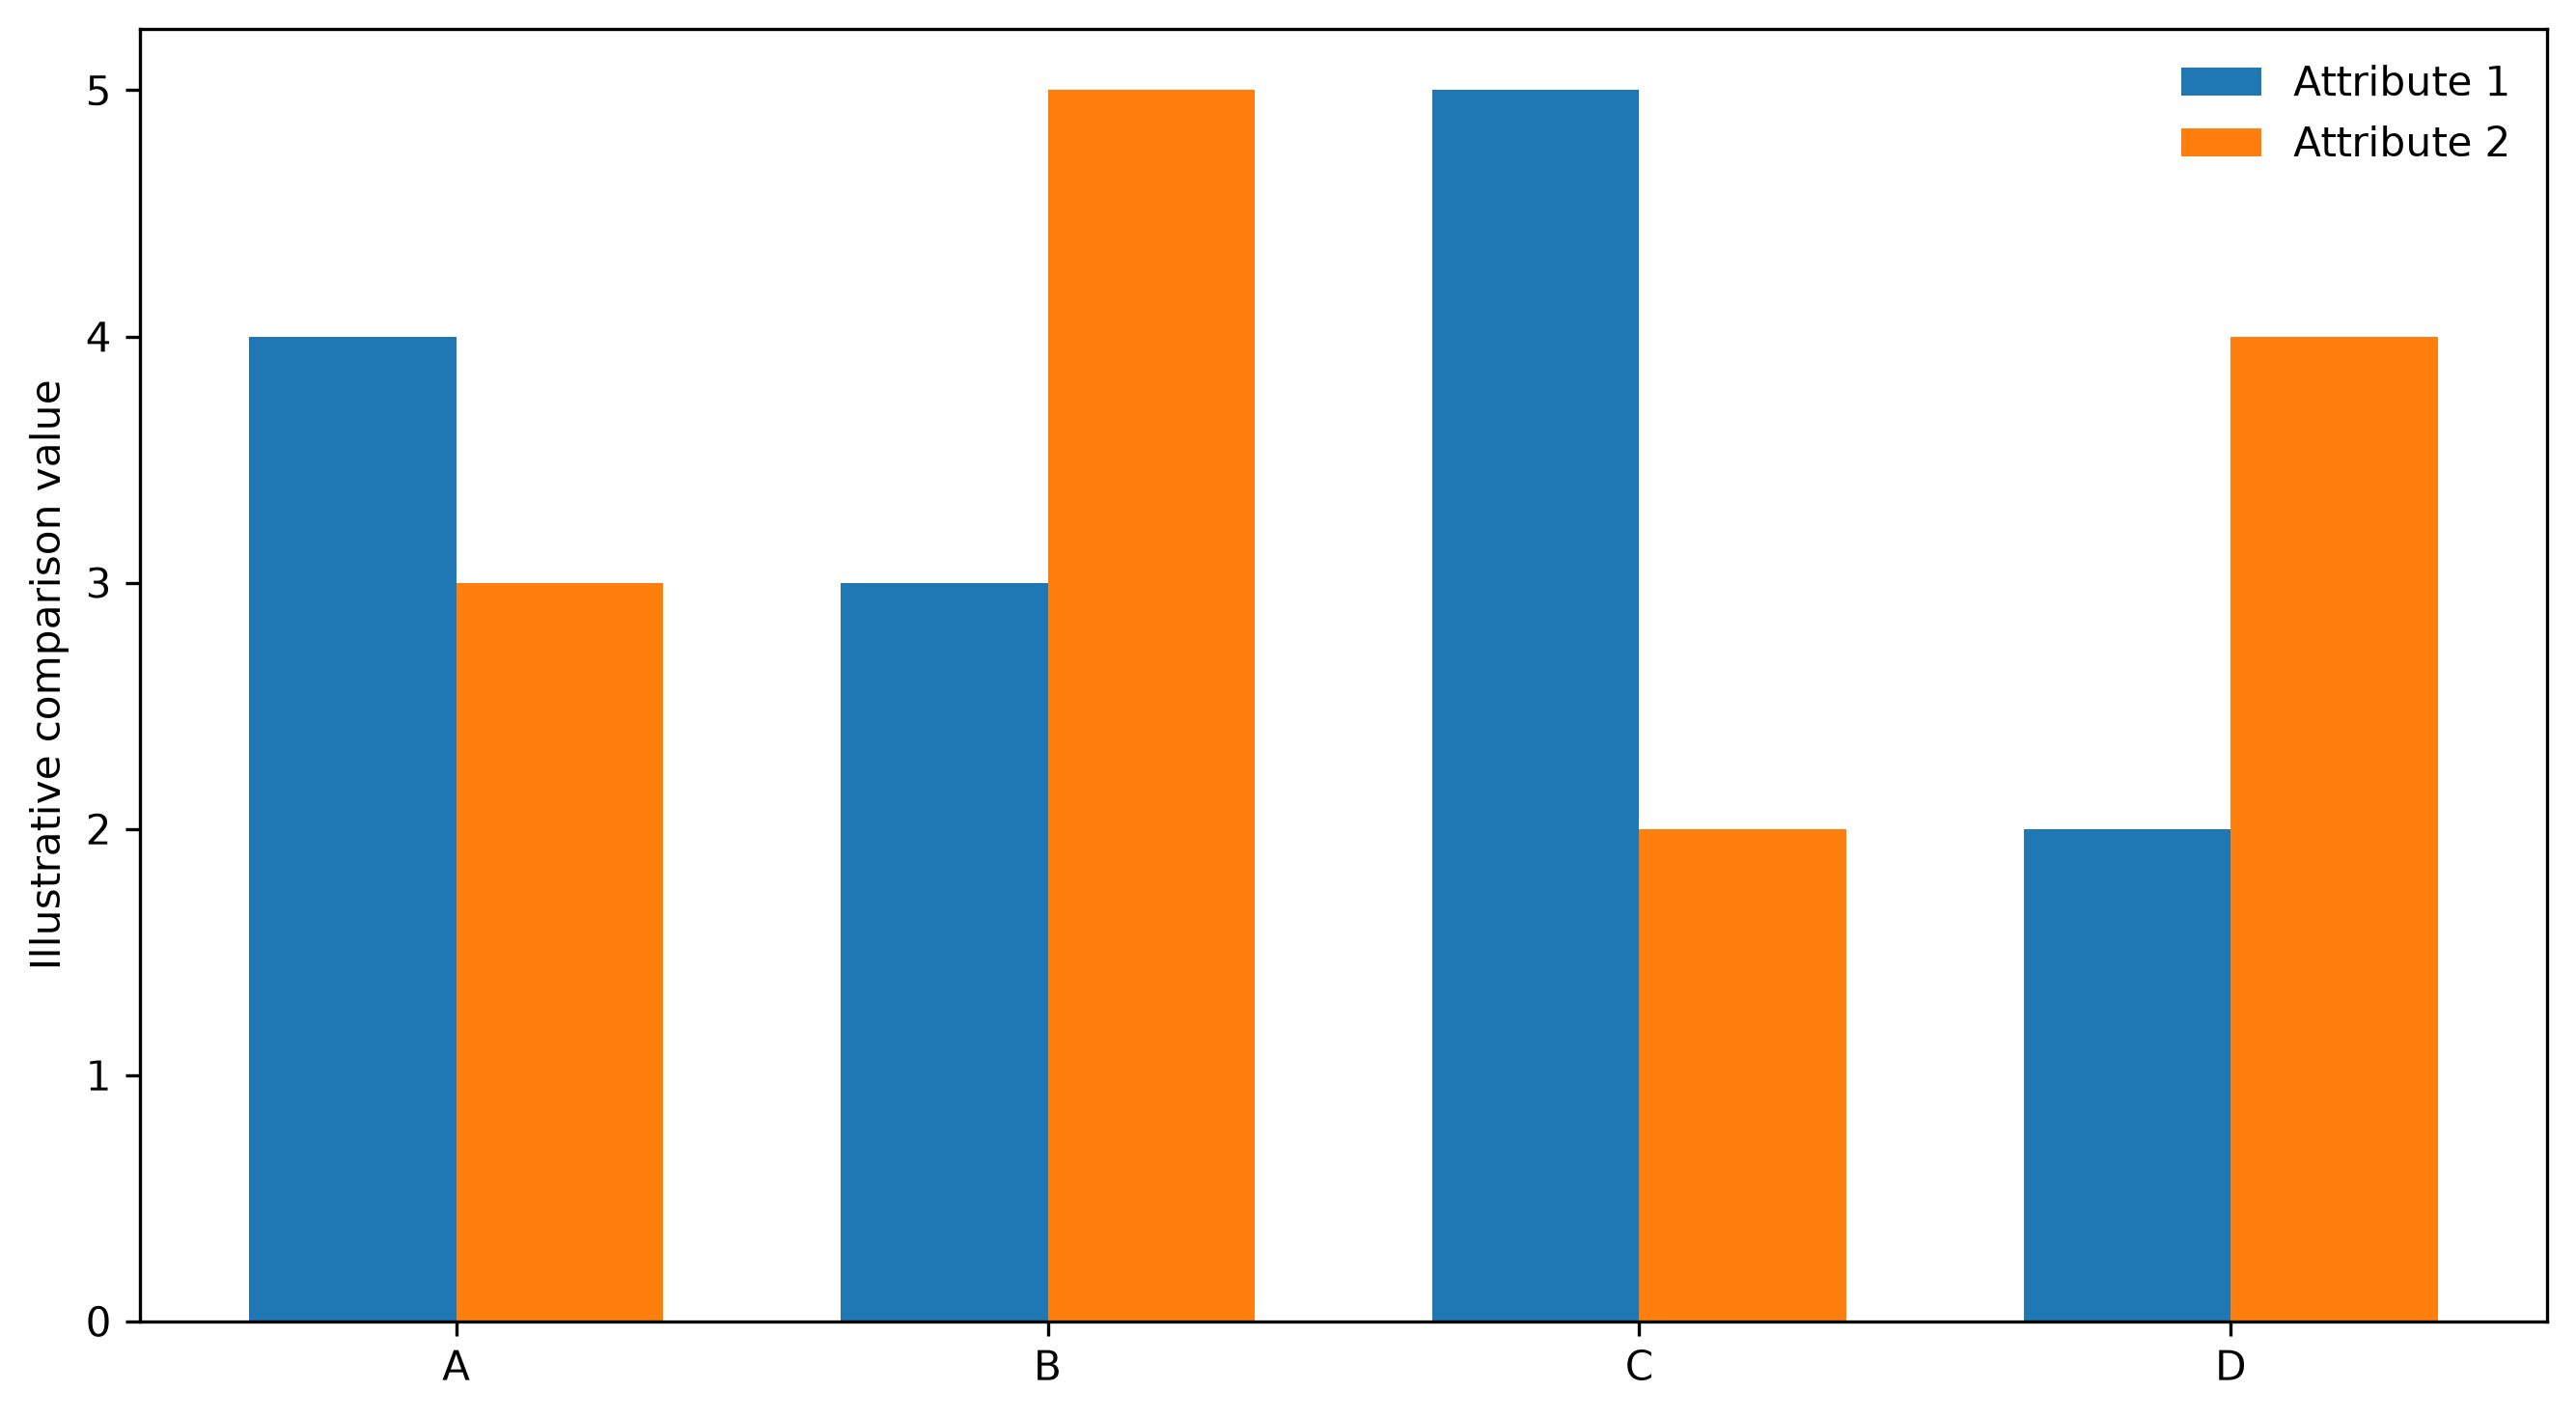

In [8]:

from IPython.display import Image, display
saved = VIS_DIR / "paper_02_improved.png"
size = saved.stat().st_size if saved.exists() else 0
print("paper_02_improved.png ->", saved, f"({size:,} bytes)" if saved.exists() else "(not written)")
if saved.exists():
    display(Image(filename=str(saved), width=780))


#### 03. Visual Analytics in Deep Learning: An Interrogative Survey for the Next Frontiers

*IEEE Xplore, 2019* — chart type: **Multidimensional framework diagram**

**Redesign problem.** Many conceptual dimensions can compete for attention; grouping and progressive emphasis can reduce cognitive load.


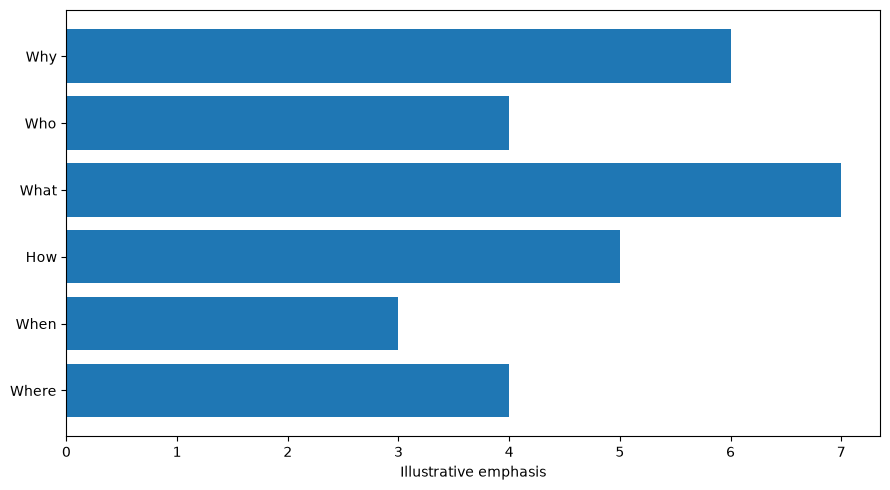

In [9]:
# Visual Analytics in Deep Learning: An Interrogative Survey for the Next Frontiers
# Educational reconstruction for M.E. CSE Data Visualization Exercise-2.
# The reconstruction is NOT a reproduction of the authors' research findings.
# Replace only with published numerical values when the source provides them.
import matplotlib.pyplot as plt
import numpy as np


import os
from pathlib import Path as _Path


def _visualizations_dir() -> _Path:
    """Where saved figures go: env override -> repo folder -> cwd fallback."""
    if os.environ.get("EX2_VIS_DIR"):
        out = _Path(os.environ["EX2_VIS_DIR"])
    else:
        try:
            out = _Path(__file__).resolve().parent.parent / "visualizations"
        except NameError:  # exec()'d inside a notebook cell: no __file__
            out = _Path.cwd() / "visualizations"
    out.mkdir(parents=True, exist_ok=True)
    return out


# Illustrative reconstruction data / structure:
cats=["Why","Who","What","How","When","Where"]; vals=[6,4,7,5,3,4]

# Plot:
fig,ax=plt.subplots(figsize=(9,5)); y=np.arange(len(cats)); ax.barh(y,vals)
ax.set_yticks(y,cats); ax.invert_yaxis(); ax.set_xlabel("Illustrative emphasis")

plt.tight_layout()
plt.savefig(_visualizations_dir() / "paper_03_improved.png", dpi=300, bbox_inches="tight")
plt.show()


paper_03_improved.png -> C:\Users\agnes\AppData\Local\Temp\opencode\exp2_kaggle_vis\paper_03_improved.png (47,726 bytes)


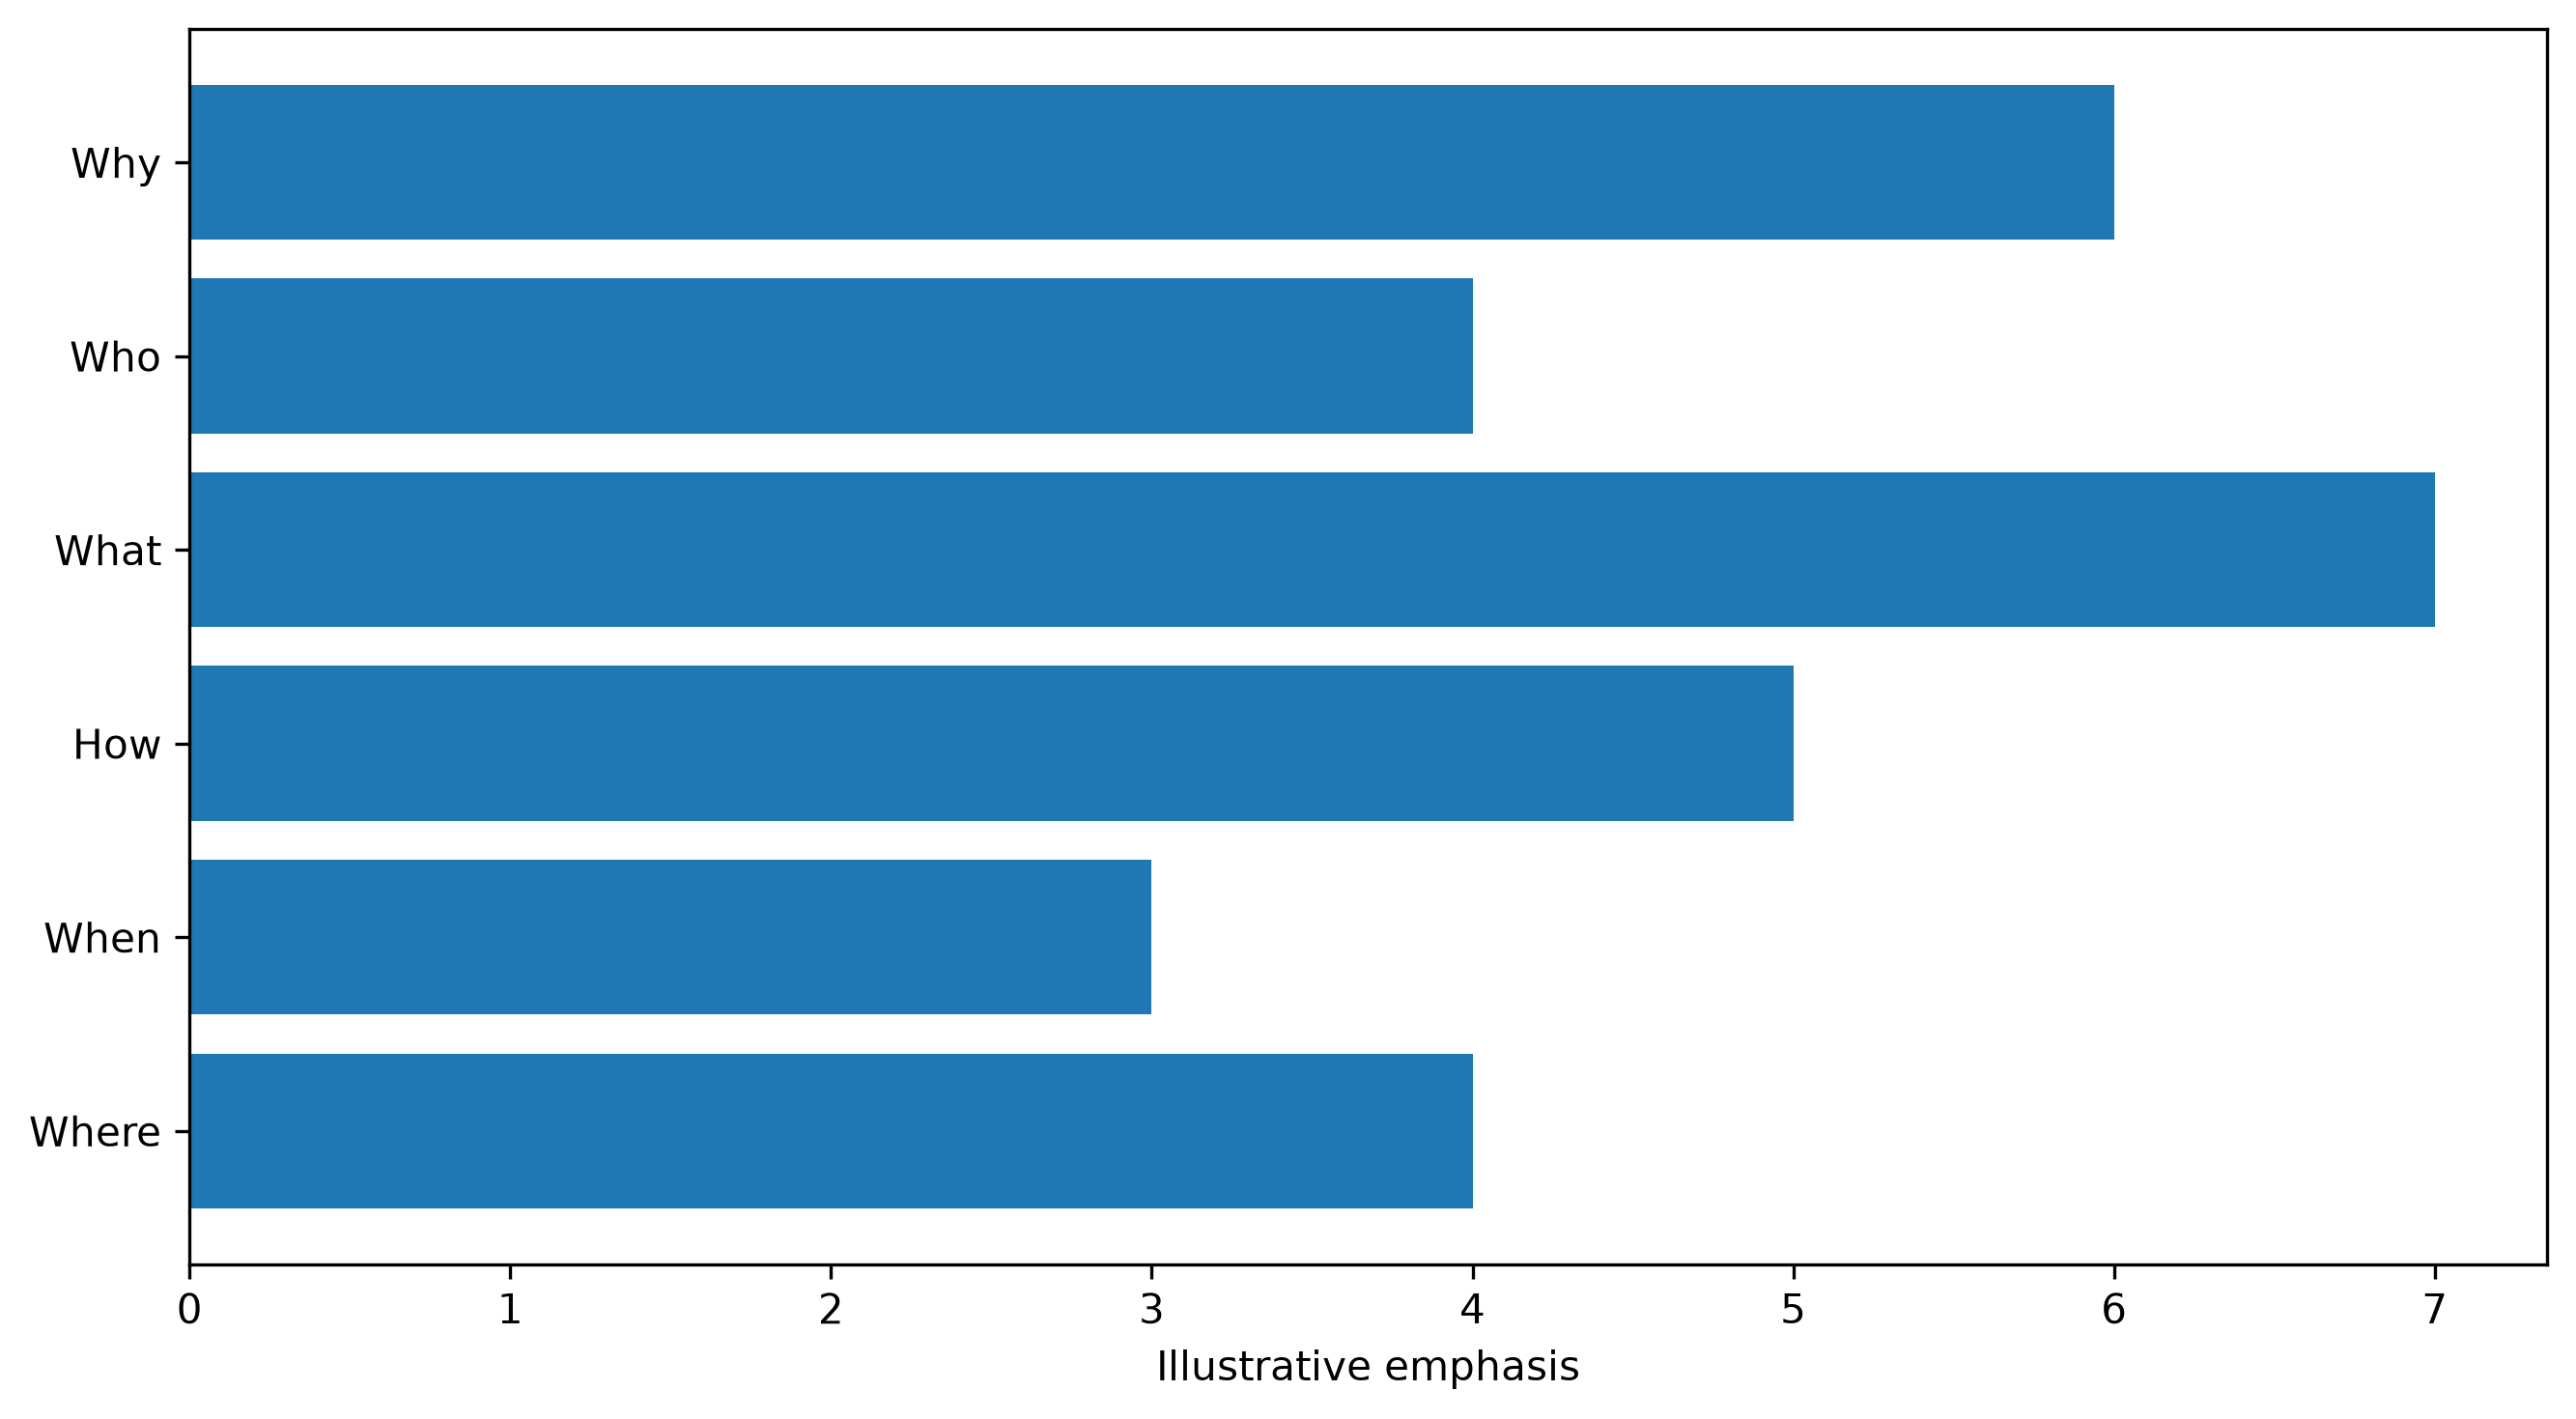

In [10]:

from IPython.display import Image, display
saved = VIS_DIR / "paper_03_improved.png"
size = saved.stat().st_size if saved.exists() else 0
print("paper_03_improved.png ->", saved, f"({size:,} bytes)" if saved.exists() else "(not written)")
if saved.exists():
    display(Image(filename=str(saved), width=780))


#### 04. Toward automatic comparison of visualization techniques: Application to graph visualization

*ScienceDirect, 2020* — chart type: **Workflow diagram**

**Redesign problem.** Multiple stages and representation types can become visually dense; explicit phase grouping improves reading order.


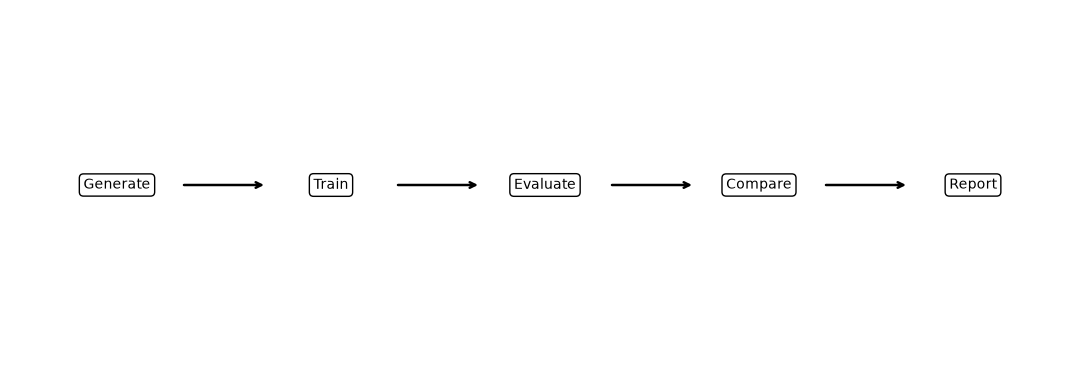

In [11]:
# Toward automatic comparison of visualization techniques: Application to graph visualization
# Educational reconstruction for M.E. CSE Data Visualization Exercise-2.
# The reconstruction is NOT a reproduction of the authors' research findings.
# Replace only with published numerical values when the source provides them.
import matplotlib.pyplot as plt
import numpy as np


import os
from pathlib import Path as _Path


def _visualizations_dir() -> _Path:
    """Where saved figures go: env override -> repo folder -> cwd fallback."""
    if os.environ.get("EX2_VIS_DIR"):
        out = _Path(os.environ["EX2_VIS_DIR"])
    else:
        try:
            out = _Path(__file__).resolve().parent.parent / "visualizations"
        except NameError:  # exec()'d inside a notebook cell: no __file__
            out = _Path.cwd() / "visualizations"
    out.mkdir(parents=True, exist_ok=True)
    return out


# Illustrative reconstruction data / structure:
stages=["Generate","Train","Evaluate","Compare","Report"]

# Plot:
fig,ax=plt.subplots(figsize=(11,3.8)); ax.axis("off"); xs=np.linspace(.1,.9,5)
for k,(x,s) in enumerate(zip(xs,stages)):
    ax.text(x,.5,s,ha="center",va="center",bbox=dict(boxstyle="round",facecolor="white",edgecolor="black"))
    if k<4: ax.annotate("",(xs[k+1]-.06,.5),(x+.06,.5),arrowprops=dict(arrowstyle="->",lw=1.8))

plt.tight_layout()
plt.savefig(_visualizations_dir() / "paper_04_improved.png", dpi=300, bbox_inches="tight")
plt.show()


paper_04_improved.png -> C:\Users\agnes\AppData\Local\Temp\opencode\exp2_kaggle_vis\paper_04_improved.png (34,919 bytes)


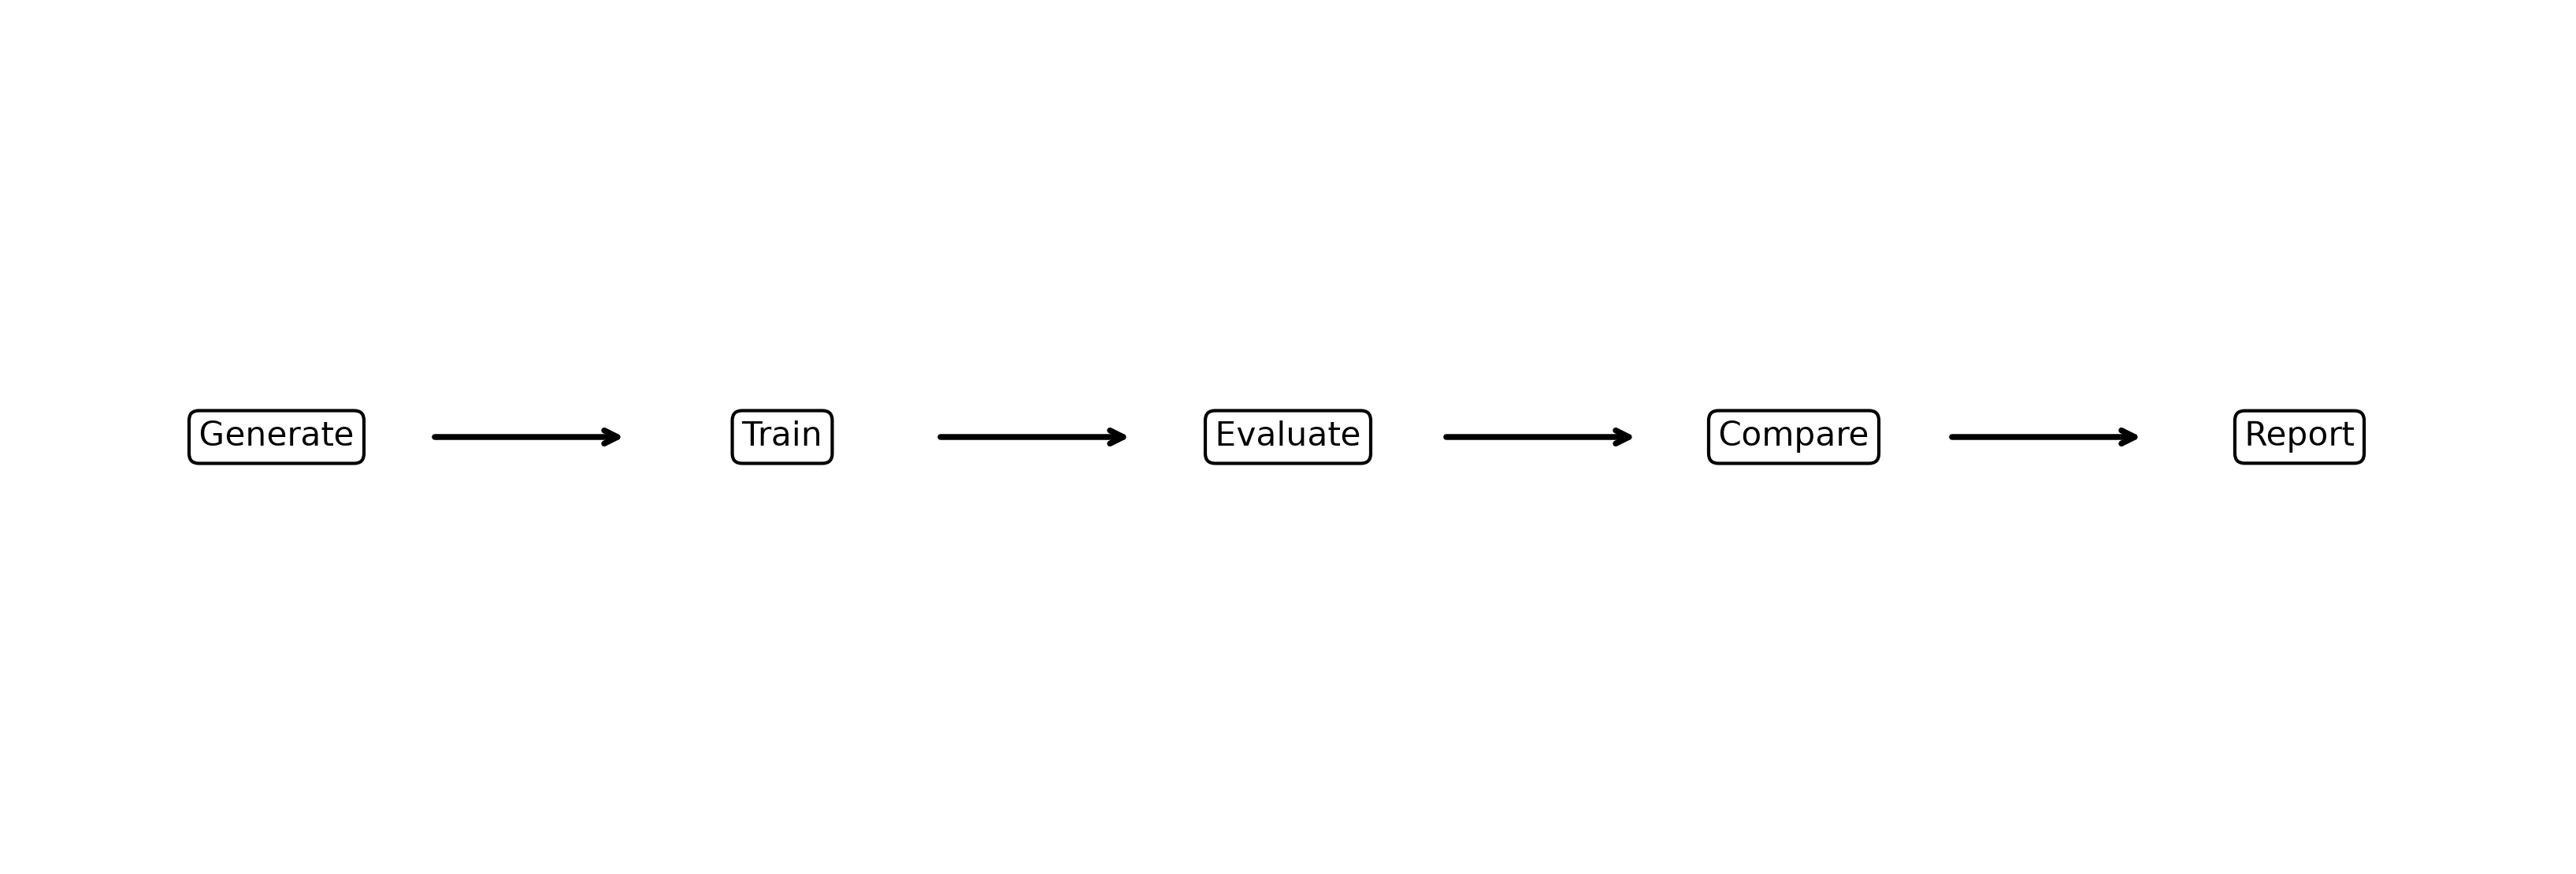

In [12]:

from IPython.display import Image, display
saved = VIS_DIR / "paper_04_improved.png"
size = saved.stat().st_size if saved.exists() else 0
print("paper_04_improved.png ->", saved, f"({size:,} bytes)" if saved.exists() else "(not written)")
if saved.exists():
    display(Image(filename=str(saved), width=780))


#### 05. A Model for Types and Levels of Automation in Visual Analytics: A Survey, a Taxonomy, and Examples

*IEEE Xplore, 2023* — chart type: **Taxonomy / matrix**

**Redesign problem.** Taxonomy levels and dimensions can be difficult to compare when the hierarchy is not visually isolated.


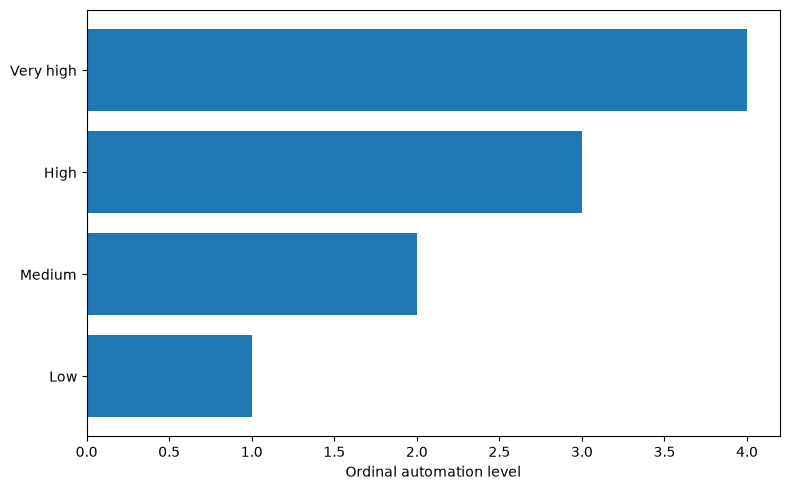

In [13]:
# A Model for Types and Levels of Automation in Visual Analytics: A Survey, a Taxonomy, and Examples
# Educational reconstruction for M.E. CSE Data Visualization Exercise-2.
# The reconstruction is NOT a reproduction of the authors' research findings.
# Replace only with published numerical values when the source provides them.
import matplotlib.pyplot as plt
import numpy as np


import os
from pathlib import Path as _Path


def _visualizations_dir() -> _Path:
    """Where saved figures go: env override -> repo folder -> cwd fallback."""
    if os.environ.get("EX2_VIS_DIR"):
        out = _Path(os.environ["EX2_VIS_DIR"])
    else:
        try:
            out = _Path(__file__).resolve().parent.parent / "visualizations"
        except NameError:  # exec()'d inside a notebook cell: no __file__
            out = _Path.cwd() / "visualizations"
    out.mkdir(parents=True, exist_ok=True)
    return out


# Illustrative reconstruction data / structure:
levels=["Low","Medium","High","Very high"]; vals=[1,2,3,4]

# Plot:
fig,ax=plt.subplots(figsize=(8,5)); ax.barh(levels,vals); ax.set_xlabel("Ordinal automation level")

plt.tight_layout()
plt.savefig(_visualizations_dir() / "paper_05_improved.png", dpi=300, bbox_inches="tight")
plt.show()


paper_05_improved.png -> C:\Users\agnes\AppData\Local\Temp\opencode\exp2_kaggle_vis\paper_05_improved.png (47,537 bytes)


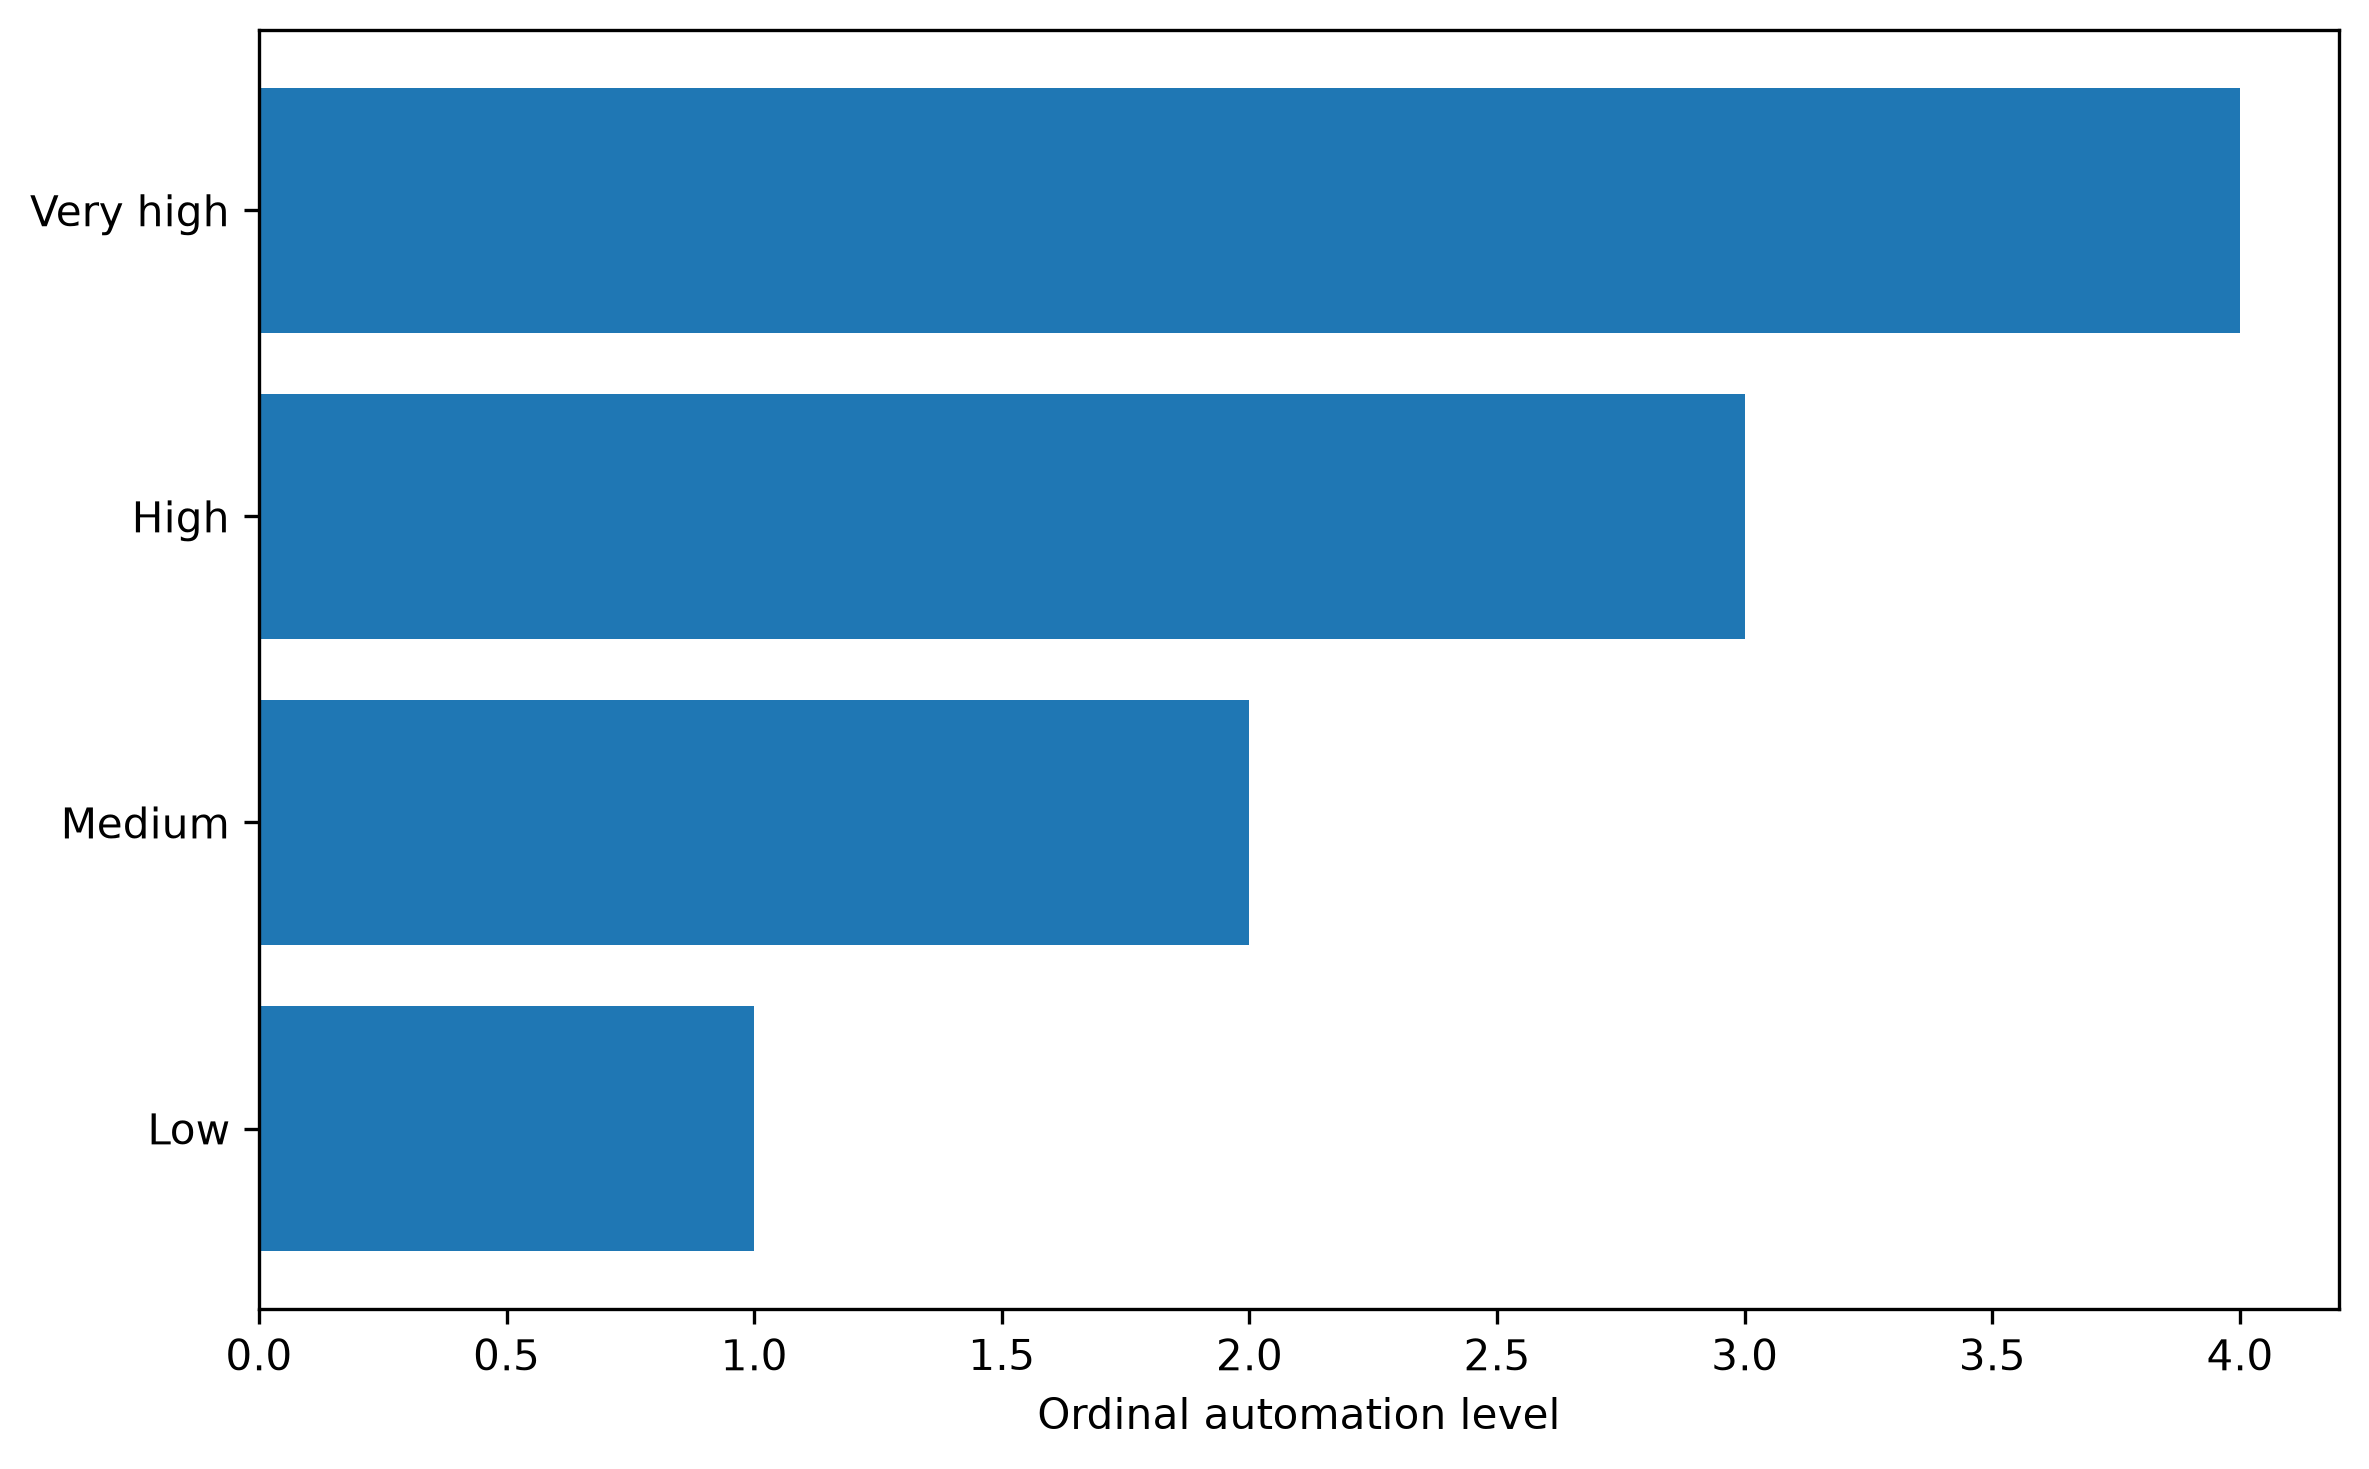

In [14]:

from IPython.display import Image, display
saved = VIS_DIR / "paper_05_improved.png"
size = saved.stat().st_size if saved.exists() else 0
print("paper_05_improved.png ->", saved, f"({size:,} bytes)" if saved.exists() else "(not written)")
if saved.exists():
    display(Image(filename=str(saved), width=780))


#### 06. DataV: Data Visualization on large high-resolution displays

*ScienceDirect, 2020* — chart type: **Architecture / dashboard layout**

**Redesign problem.** Multiple components compete for attention on large-display layouts; stronger grouping and whitespace can clarify the primary reading path.


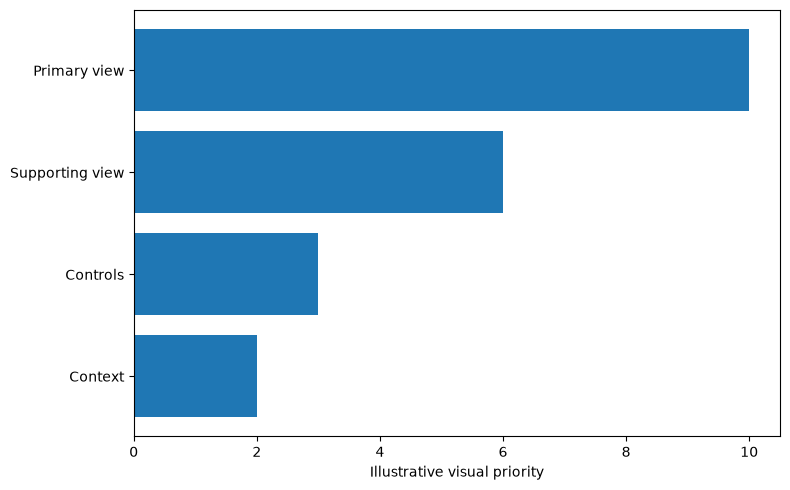

In [15]:
# DataV: Data Visualization on large high-resolution displays
# Educational reconstruction for M.E. CSE Data Visualization Exercise-2.
# The reconstruction is NOT a reproduction of the authors' research findings.
# Replace only with published numerical values when the source provides them.
import matplotlib.pyplot as plt
import numpy as np


import os
from pathlib import Path as _Path


def _visualizations_dir() -> _Path:
    """Where saved figures go: env override -> repo folder -> cwd fallback."""
    if os.environ.get("EX2_VIS_DIR"):
        out = _Path(os.environ["EX2_VIS_DIR"])
    else:
        try:
            out = _Path(__file__).resolve().parent.parent / "visualizations"
        except NameError:  # exec()'d inside a notebook cell: no __file__
            out = _Path.cwd() / "visualizations"
    out.mkdir(parents=True, exist_ok=True)
    return out


# Illustrative reconstruction data / structure:
components=["Primary view","Supporting view","Controls","Context"]; priority=[10,6,3,2]

# Plot:
fig,ax=plt.subplots(figsize=(8,5)); ax.barh(components,priority); ax.invert_yaxis(); ax.set_xlabel("Illustrative visual priority")

plt.tight_layout()
plt.savefig(_visualizations_dir() / "paper_06_improved.png", dpi=300, bbox_inches="tight")
plt.show()


paper_06_improved.png -> C:\Users\agnes\AppData\Local\Temp\opencode\exp2_kaggle_vis\paper_06_improved.png (49,880 bytes)


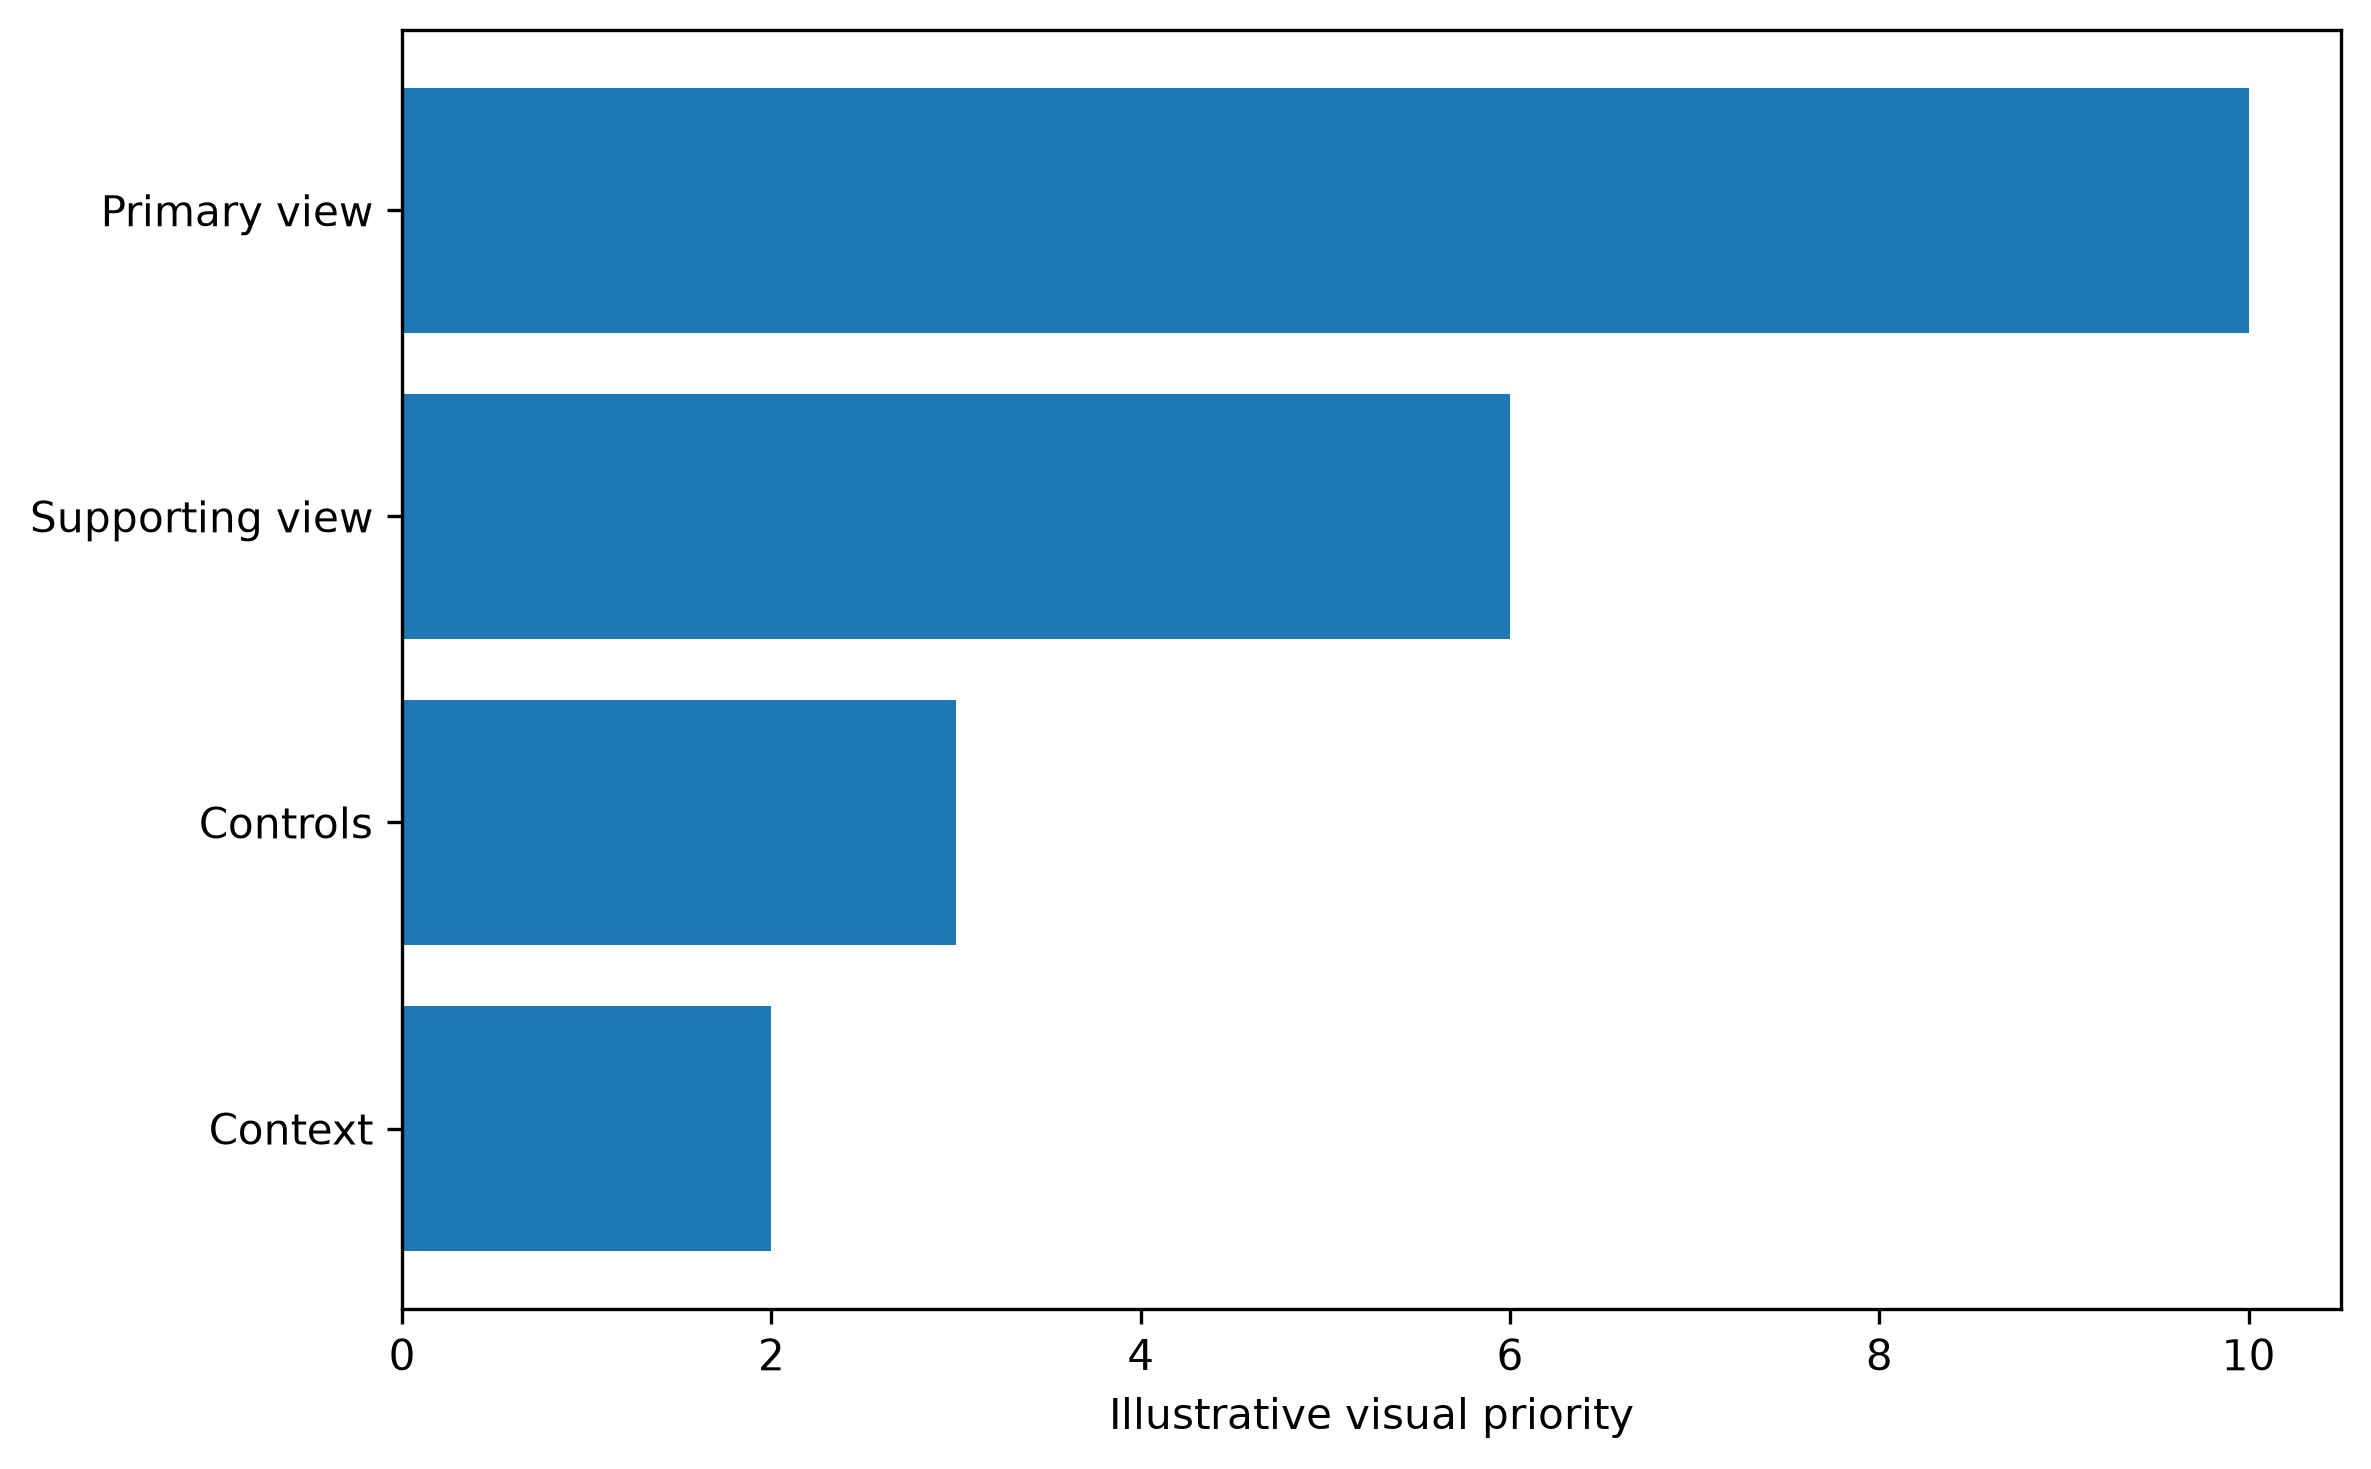

In [16]:

from IPython.display import Image, display
saved = VIS_DIR / "paper_06_improved.png"
size = saved.stat().st_size if saved.exists() else 0
print("paper_06_improved.png ->", saved, f"({size:,} bytes)" if saved.exists() else "(not written)")
if saved.exists():
    display(Image(filename=str(saved), width=780))


#### 07. MalView: Interactive Visual Analytics for Comprehending Malware Behavior

*IEEE Xplore, 2022* — chart type: **Multiview cybersecurity visualization**

**Redesign problem.** Several linked views may create visual competition; a coordinated emphasis scheme can focus attention on the active analytical task.


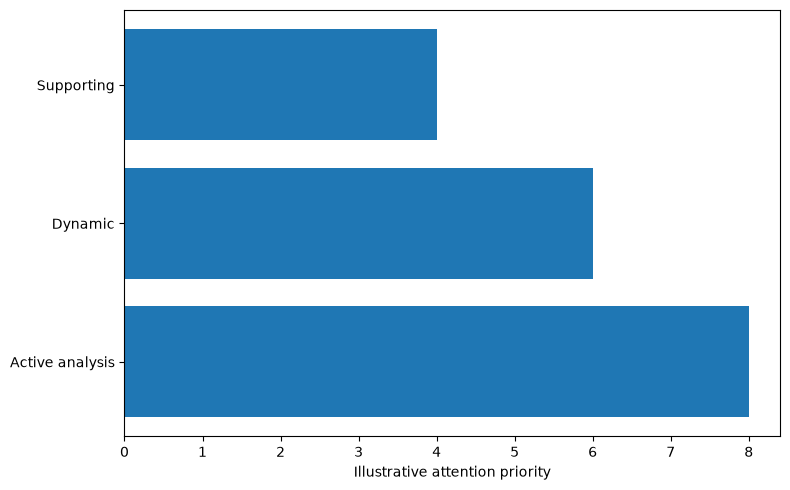

In [17]:
# MalView: Interactive Visual Analytics for Comprehending Malware Behavior
# Educational reconstruction for M.E. CSE Data Visualization Exercise-2.
# The reconstruction is NOT a reproduction of the authors' research findings.
# Replace only with published numerical values when the source provides them.
import matplotlib.pyplot as plt
import numpy as np


import os
from pathlib import Path as _Path


def _visualizations_dir() -> _Path:
    """Where saved figures go: env override -> repo folder -> cwd fallback."""
    if os.environ.get("EX2_VIS_DIR"):
        out = _Path(os.environ["EX2_VIS_DIR"])
    else:
        try:
            out = _Path(__file__).resolve().parent.parent / "visualizations"
        except NameError:  # exec()'d inside a notebook cell: no __file__
            out = _Path.cwd() / "visualizations"
    out.mkdir(parents=True, exist_ok=True)
    return out


# Illustrative reconstruction data / structure:
views=["Supporting","Dynamic","Active analysis"]; priority=[4,6,8]

# Plot:
fig,ax=plt.subplots(figsize=(8,5)); ax.barh(views,priority); ax.invert_yaxis(); ax.set_xlabel("Illustrative attention priority")

plt.tight_layout()
plt.savefig(_visualizations_dir() / "paper_07_improved.png", dpi=300, bbox_inches="tight")
plt.show()


paper_07_improved.png -> C:\Users\agnes\AppData\Local\Temp\opencode\exp2_kaggle_vis\paper_07_improved.png (45,986 bytes)


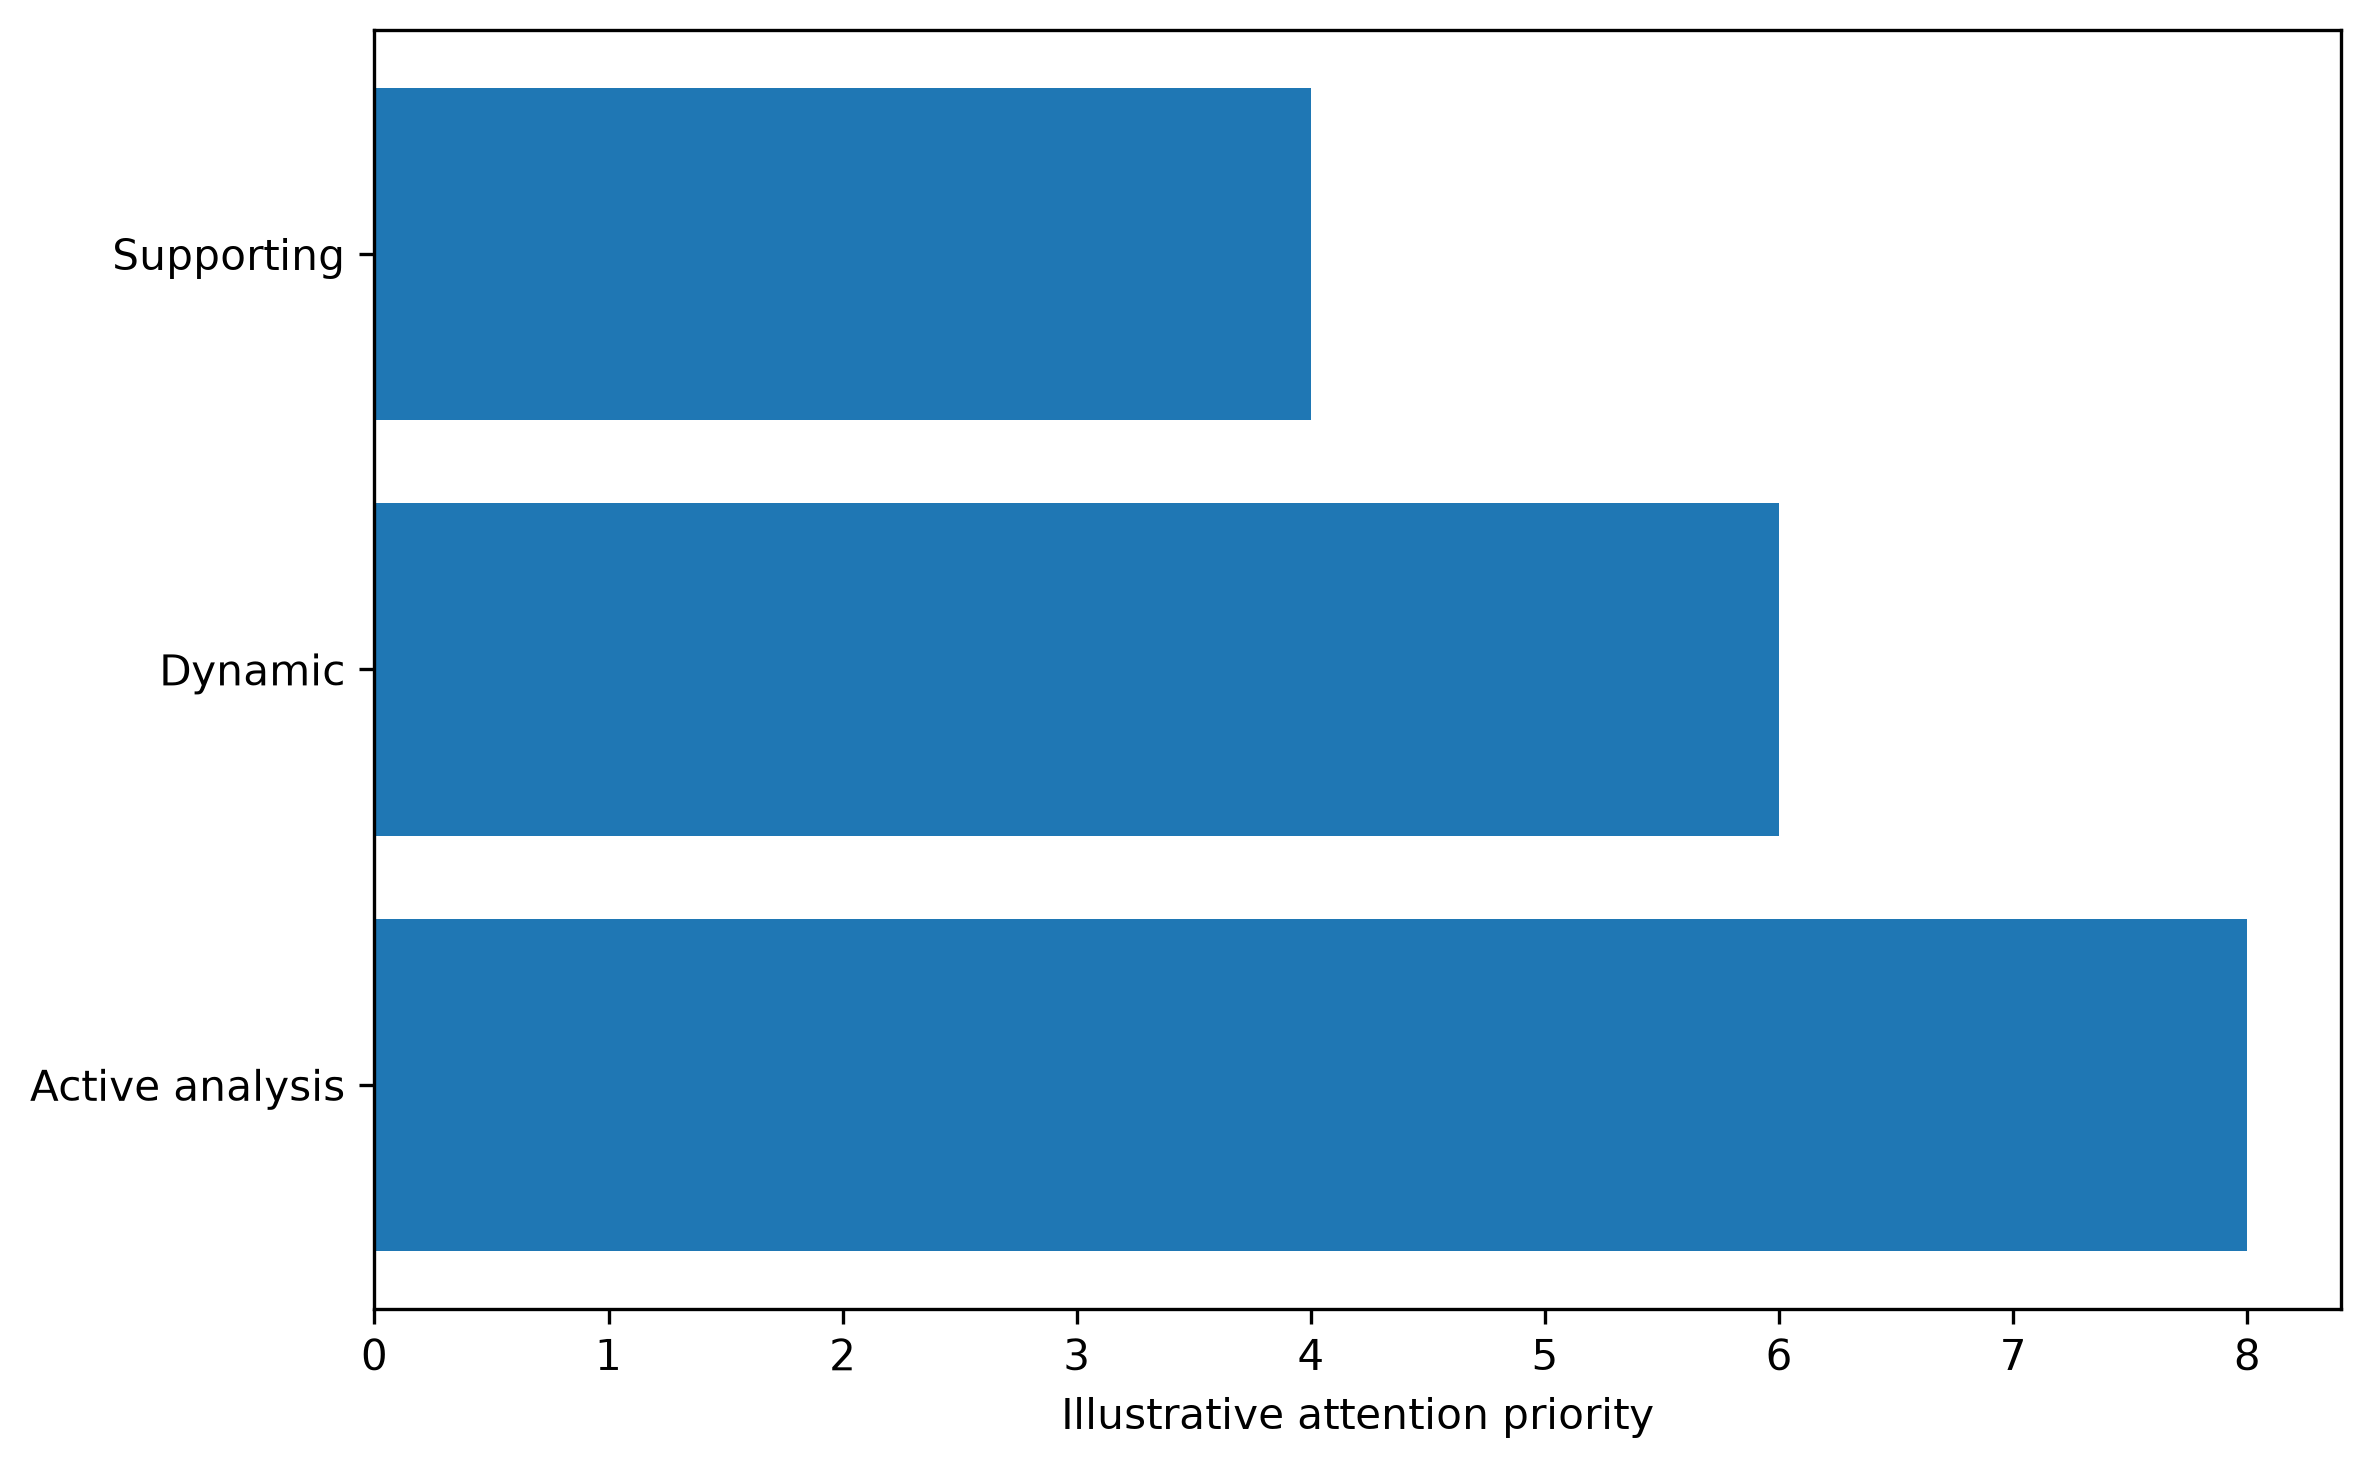

In [18]:

from IPython.display import Image, display
saved = VIS_DIR / "paper_07_improved.png"
size = saved.stat().st_size if saved.exists() else 0
print("paper_07_improved.png ->", saved, f"({size:,} bytes)" if saved.exists() else "(not written)")
if saved.exists():
    display(Image(filename=str(saved), width=780))


#### 08. VisAhoi: Towards a library to generate and integrate visualization onboarding using high-level visualization grammars

*ScienceDirect, 2024* — chart type: **Annotated multiview visualization**

**Redesign problem.** Annotation anchors and explanatory text can become cluttered if too many are simultaneously emphasized.


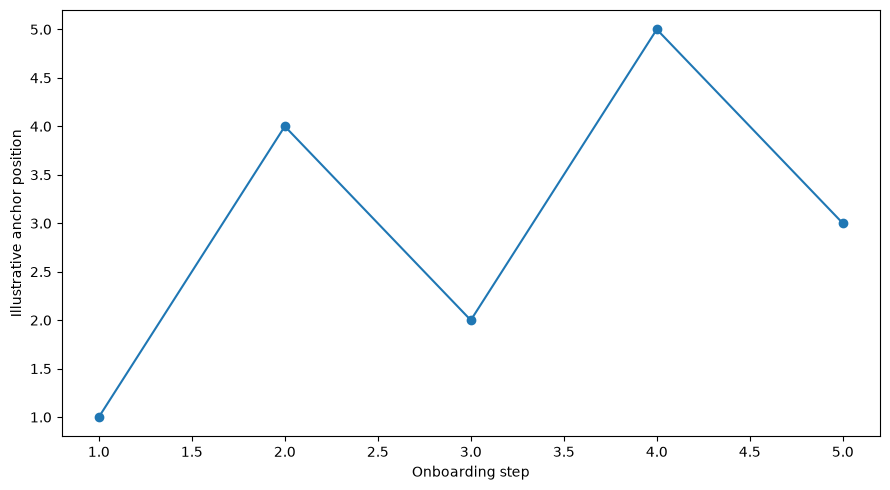

In [19]:
# VisAhoi: Towards a library to generate and integrate visualization onboarding using high-level visualization grammars
# Educational reconstruction for M.E. CSE Data Visualization Exercise-2.
# The reconstruction is NOT a reproduction of the authors' research findings.
# Replace only with published numerical values when the source provides them.
import matplotlib.pyplot as plt
import numpy as np


import os
from pathlib import Path as _Path


def _visualizations_dir() -> _Path:
    """Where saved figures go: env override -> repo folder -> cwd fallback."""
    if os.environ.get("EX2_VIS_DIR"):
        out = _Path(os.environ["EX2_VIS_DIR"])
    else:
        try:
            out = _Path(__file__).resolve().parent.parent / "visualizations"
        except NameError:  # exec()'d inside a notebook cell: no __file__
            out = _Path.cwd() / "visualizations"
    out.mkdir(parents=True, exist_ok=True)
    return out


# Illustrative reconstruction data / structure:
steps=np.arange(1,6); anchor=[1,4,2,5,3]

# Plot:
fig,ax=plt.subplots(figsize=(9,5)); ax.plot(steps,anchor,"o-"); ax.set_xlabel("Onboarding step"); ax.set_ylabel("Illustrative anchor position")

plt.tight_layout()
plt.savefig(_visualizations_dir() / "paper_08_improved.png", dpi=300, bbox_inches="tight")
plt.show()


paper_08_improved.png -> C:\Users\agnes\AppData\Local\Temp\opencode\exp2_kaggle_vis\paper_08_improved.png (131,582 bytes)


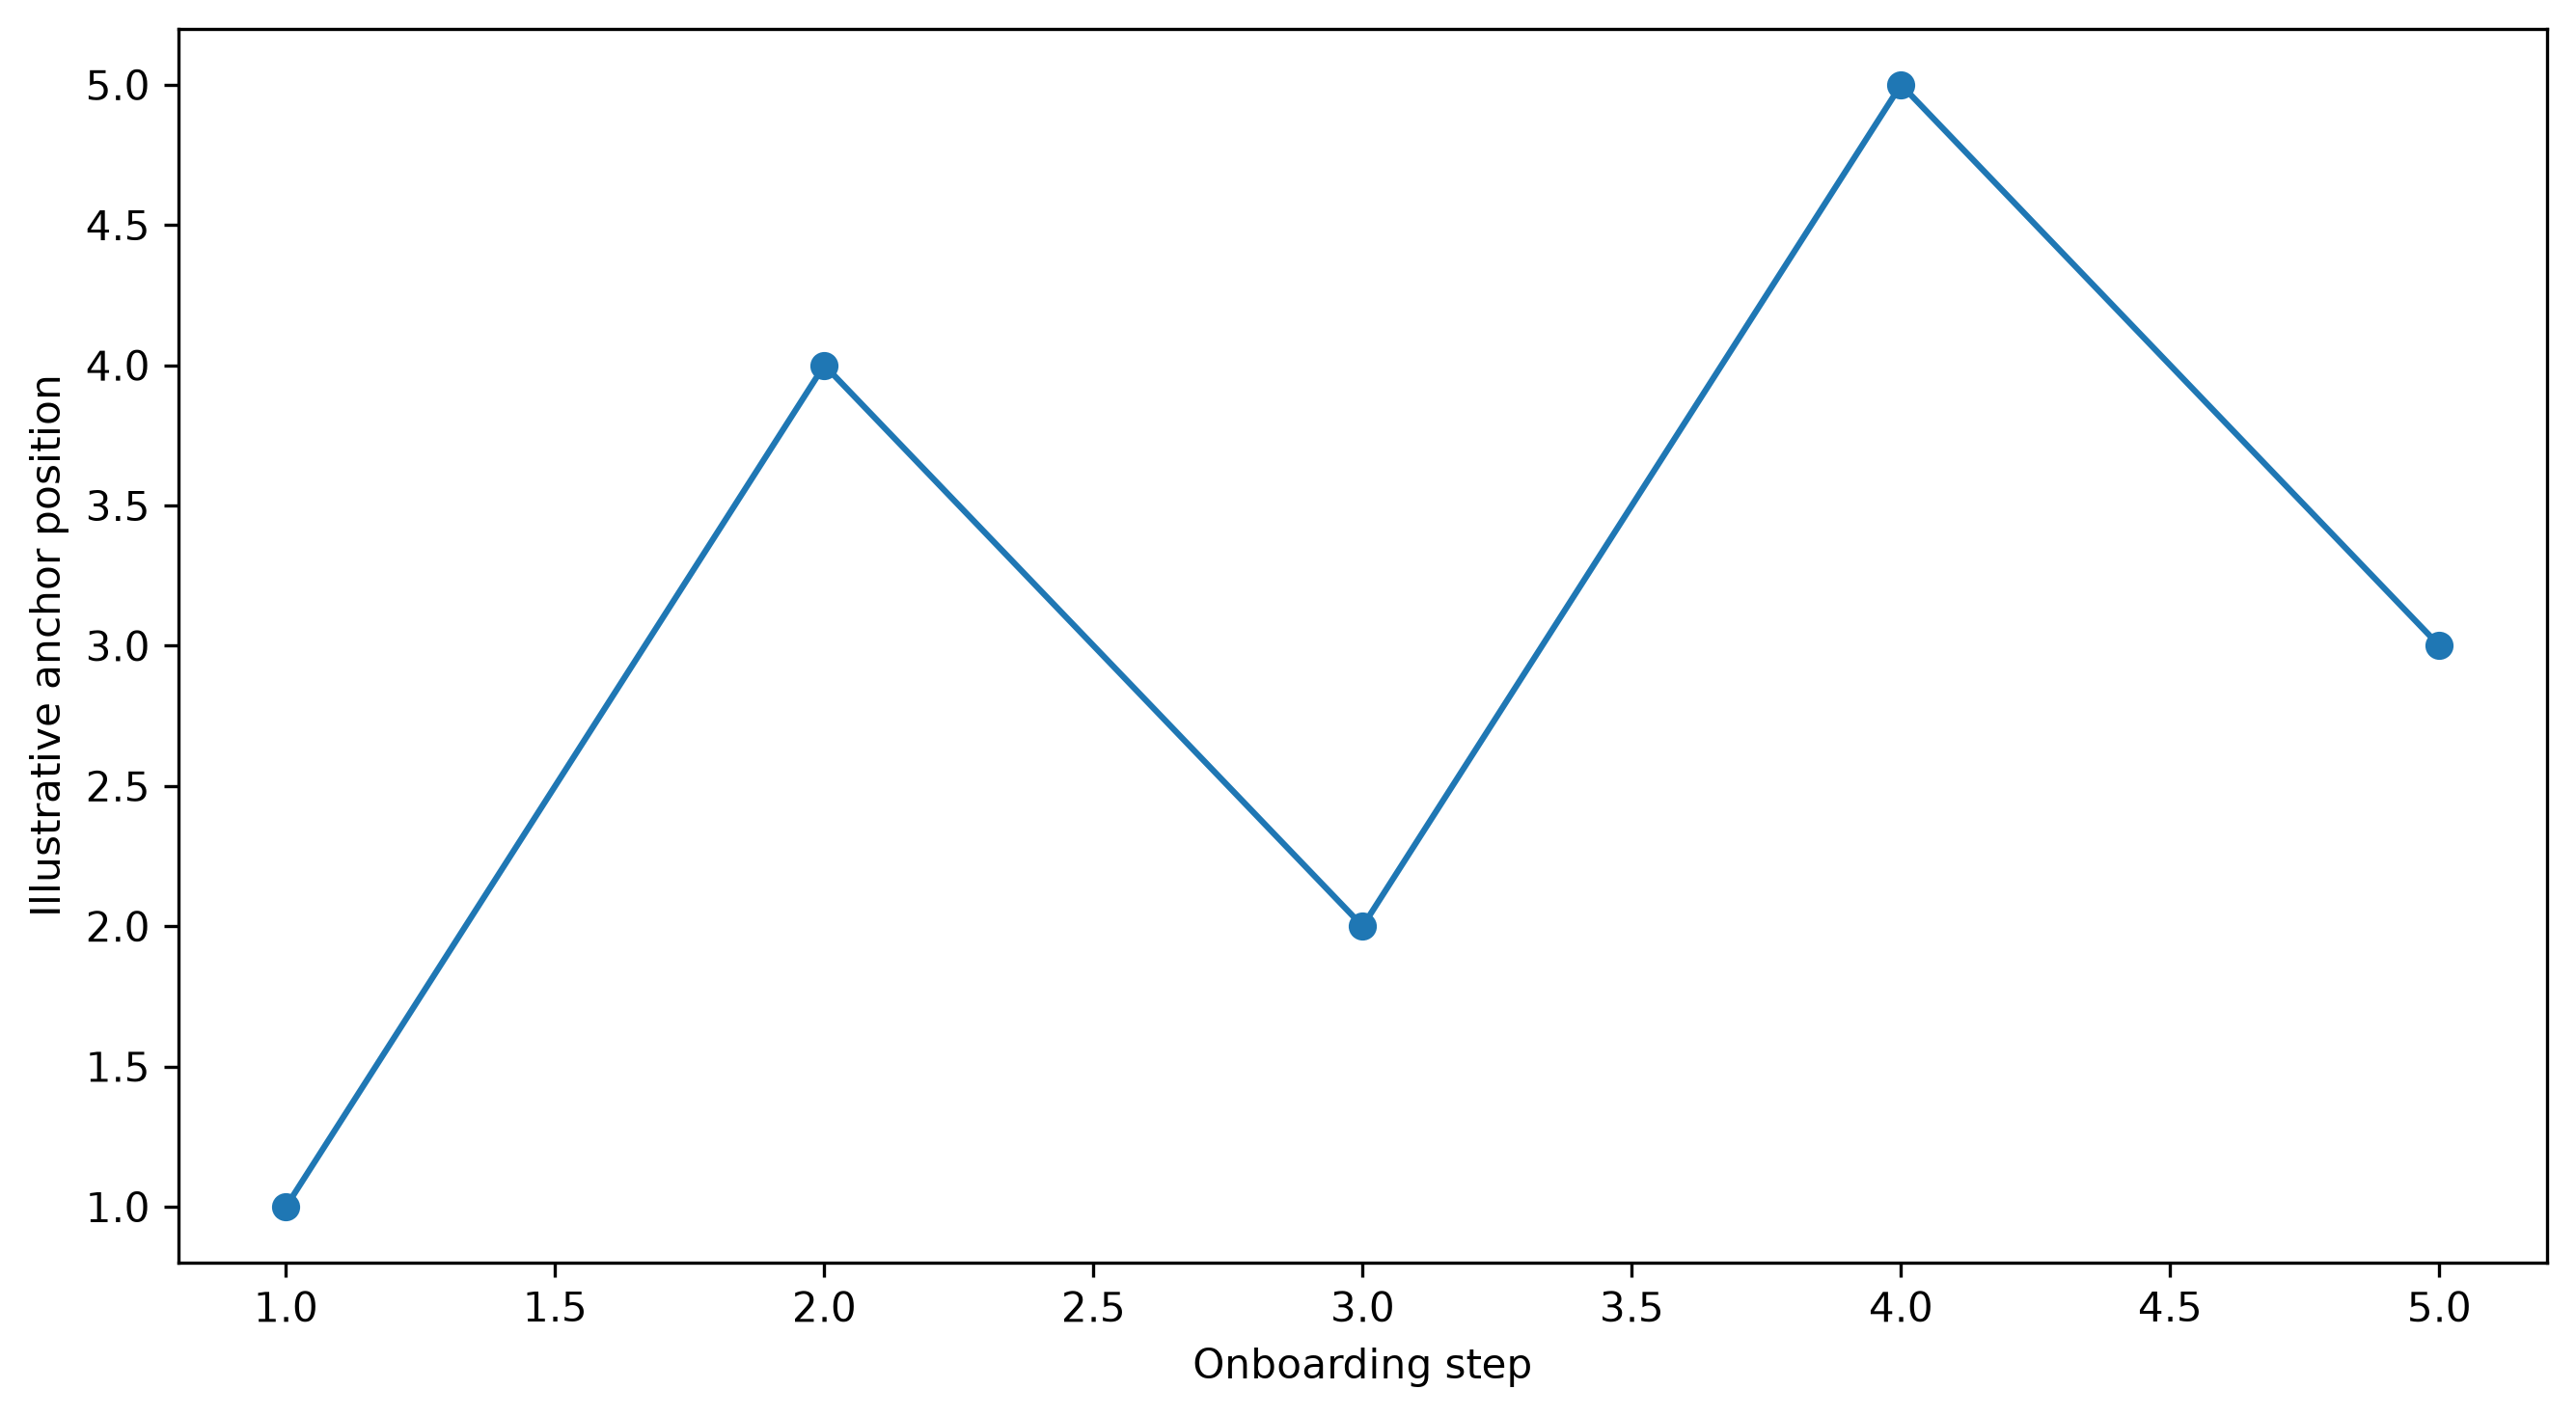

In [20]:

from IPython.display import Image, display
saved = VIS_DIR / "paper_08_improved.png"
size = saved.stat().st_size if saved.exists() else 0
print("paper_08_improved.png ->", saved, f"({size:,} bytes)" if saved.exists() else "(not written)")
if saved.exists():
    display(Image(filename=str(saved), width=780))


#### 09. A Real-Time Noise Monitoring System Based on Internet of Things for Enhanced Acoustic Comfort and Occupational Health

*IEEE Xplore, 2020* — chart type: **Time-series / heatmap**

**Redesign problem.** Time-of-day and weekday comparisons benefit from consistent axes and restrained color intensity.


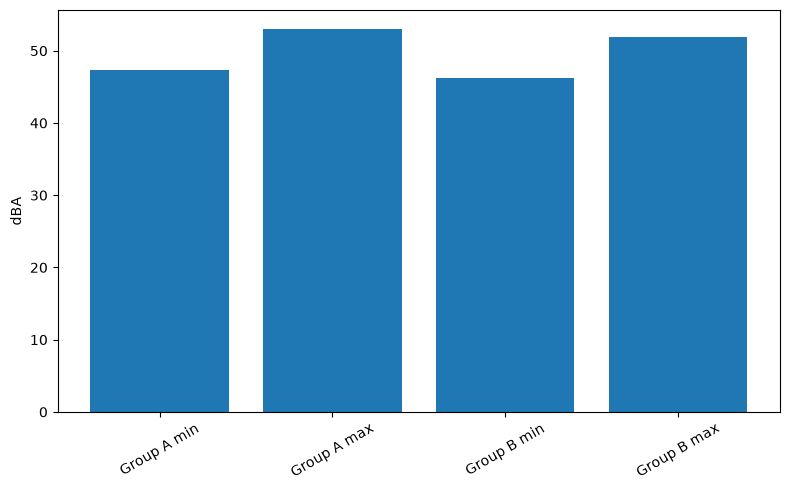

In [21]:
# A Real-Time Noise Monitoring System Based on Internet of Things for Enhanced Acoustic Comfort and Occupational Health
# Educational reconstruction for M.E. CSE Data Visualization Exercise-2.
# The reconstruction is NOT a reproduction of the authors' research findings.
# Replace only with published numerical values when the source provides them.
import matplotlib.pyplot as plt
import numpy as np


import os
from pathlib import Path as _Path


def _visualizations_dir() -> _Path:
    """Where saved figures go: env override -> repo folder -> cwd fallback."""
    if os.environ.get("EX2_VIS_DIR"):
        out = _Path(os.environ["EX2_VIS_DIR"])
    else:
        try:
            out = _Path(__file__).resolve().parent.parent / "visualizations"
        except NameError:  # exec()'d inside a notebook cell: no __file__
            out = _Path.cwd() / "visualizations"
    out.mkdir(parents=True, exist_ok=True)
    return out


# Illustrative reconstruction data / structure:
labels=["Group A min","Group A max","Group B min","Group B max"]; vals=[47.35,52.99,46.22,51.84]

# Plot:
fig,ax=plt.subplots(figsize=(8,5)); ax.bar(labels,vals); ax.tick_params(axis="x",rotation=30); ax.set_ylabel("dBA")

plt.tight_layout()
plt.savefig(_visualizations_dir() / "paper_09_improved.png", dpi=300, bbox_inches="tight")
plt.show()


paper_09_improved.png -> C:\Users\agnes\AppData\Local\Temp\opencode\exp2_kaggle_vis\paper_09_improved.png (62,982 bytes)


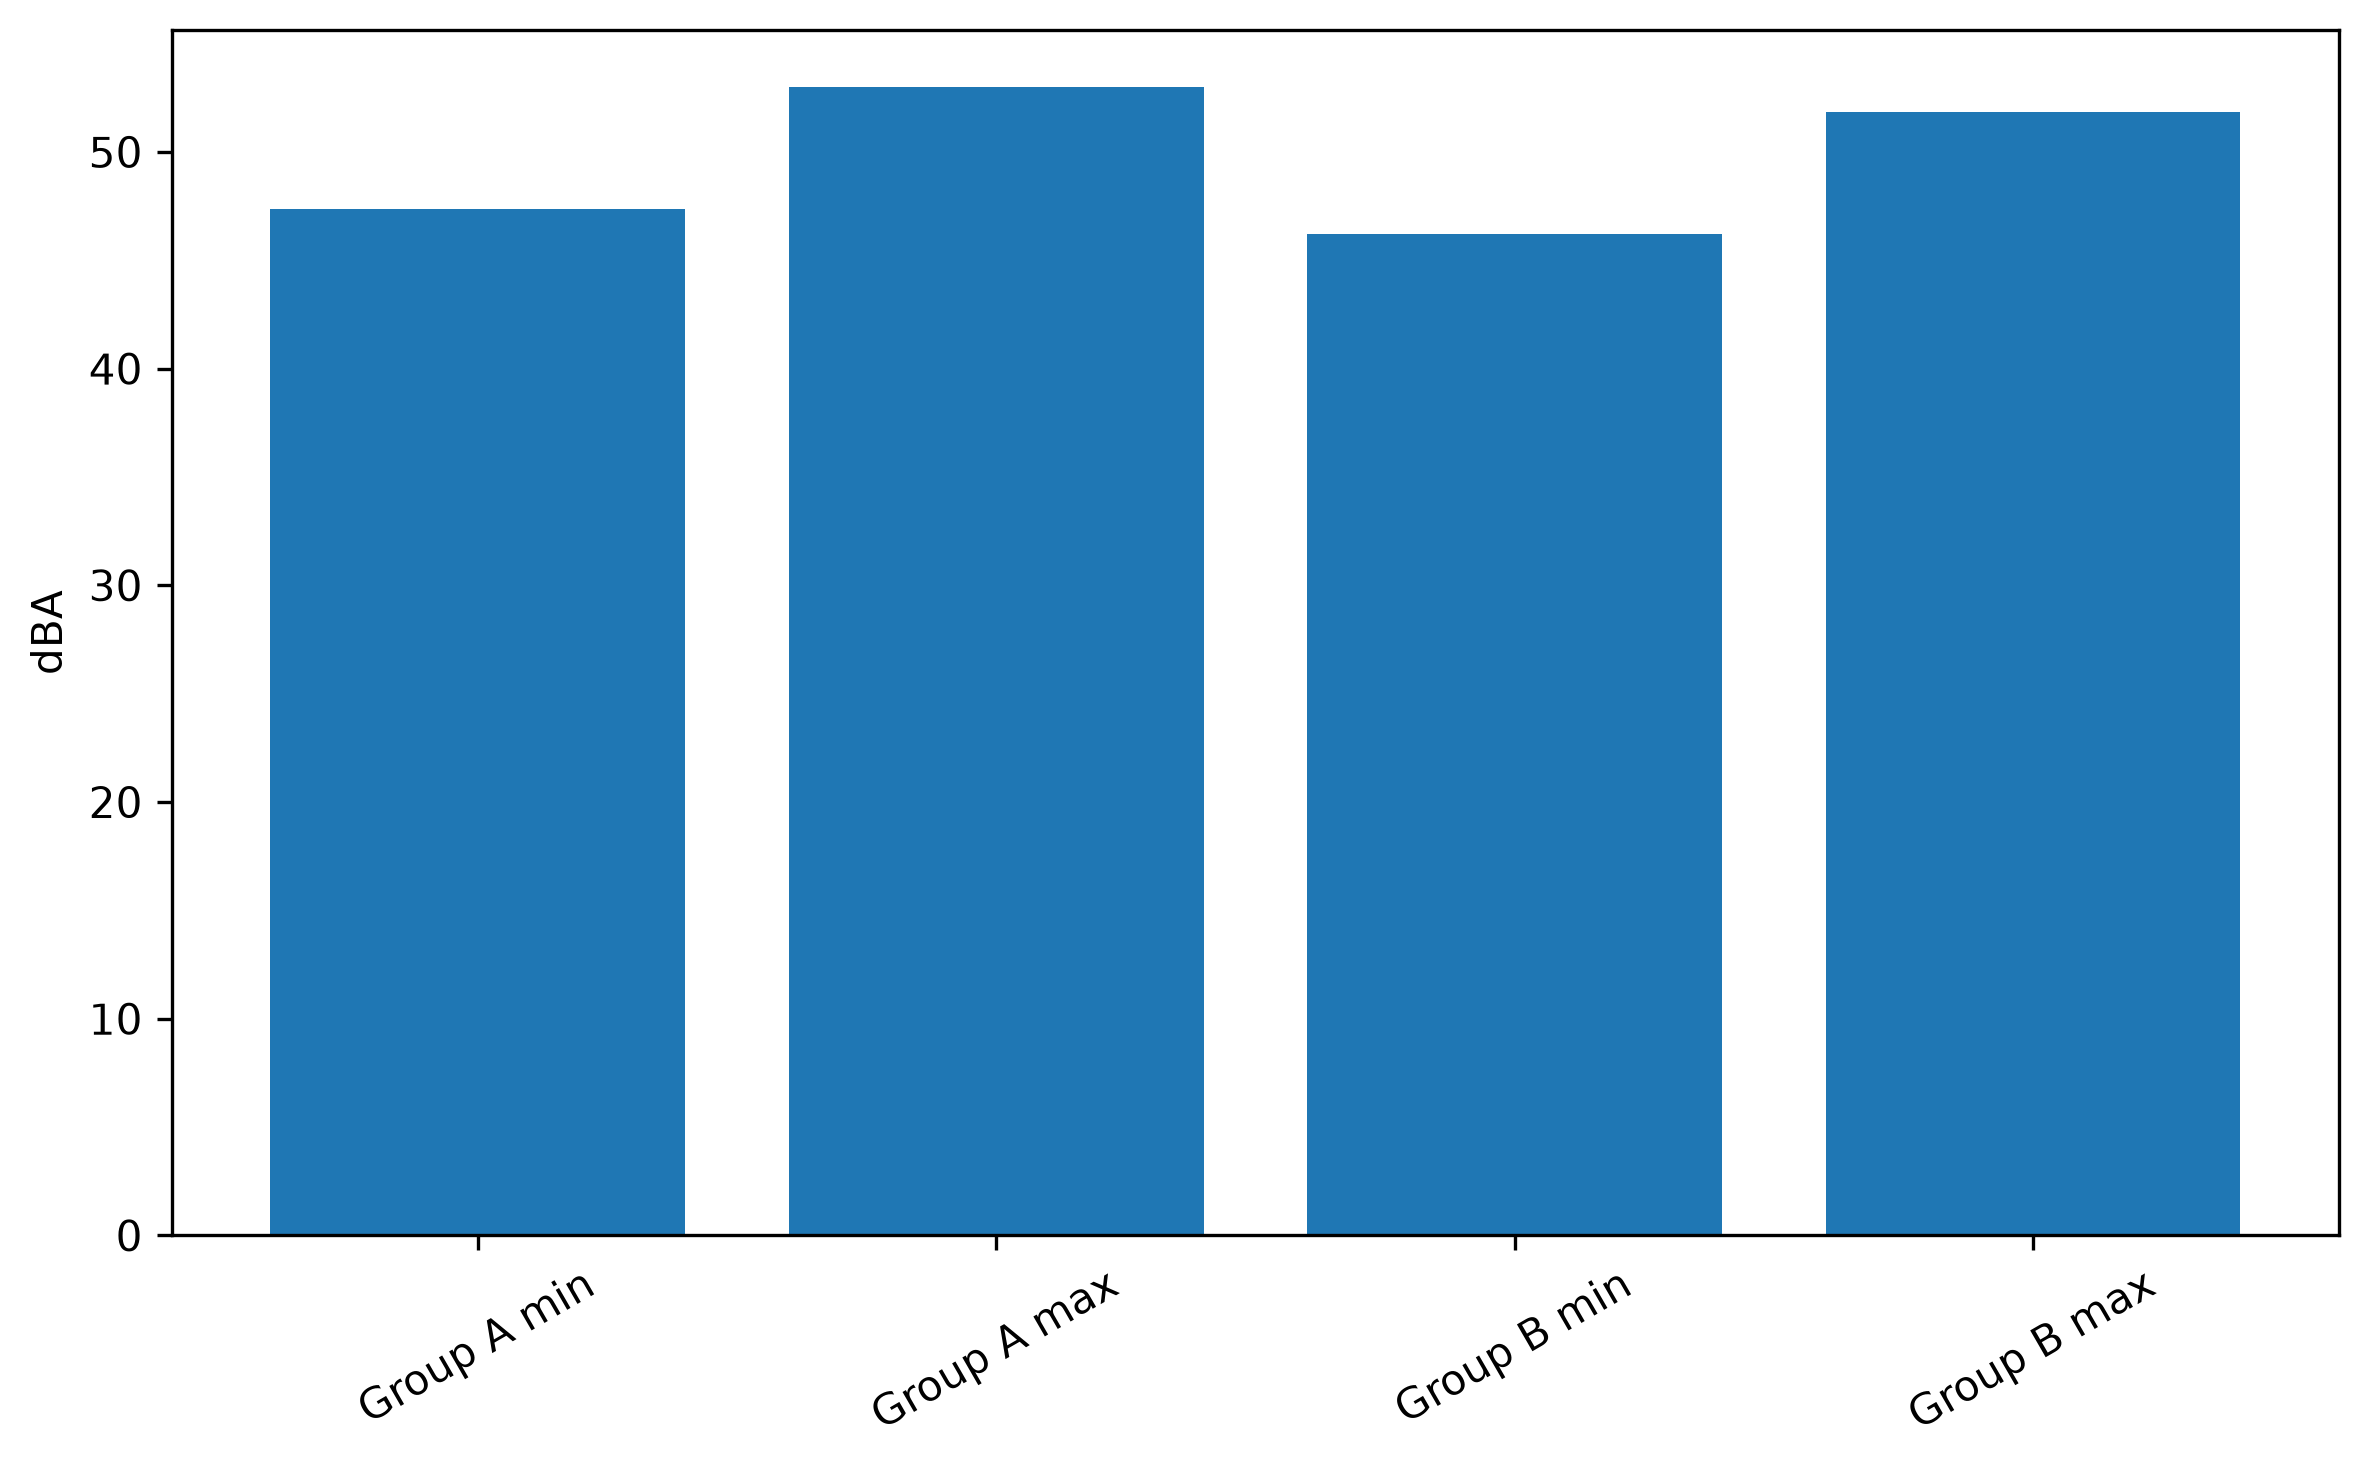

In [22]:

from IPython.display import Image, display
saved = VIS_DIR / "paper_09_improved.png"
size = saved.stat().st_size if saved.exists() else 0
print("paper_09_improved.png ->", saved, f"({size:,} bytes)" if saved.exists() else "(not written)")
if saved.exists():
    display(Image(filename=str(saved), width=780))


#### 10. PCP-Ed: Parallel coordinate plots for ensemble data

*ScienceDirect, 2023* — chart type: **Parallel coordinates**

**Redesign problem.** Overlapping polylines can obscure trends and outliers; opacity and selective highlighting reduce overplotting.


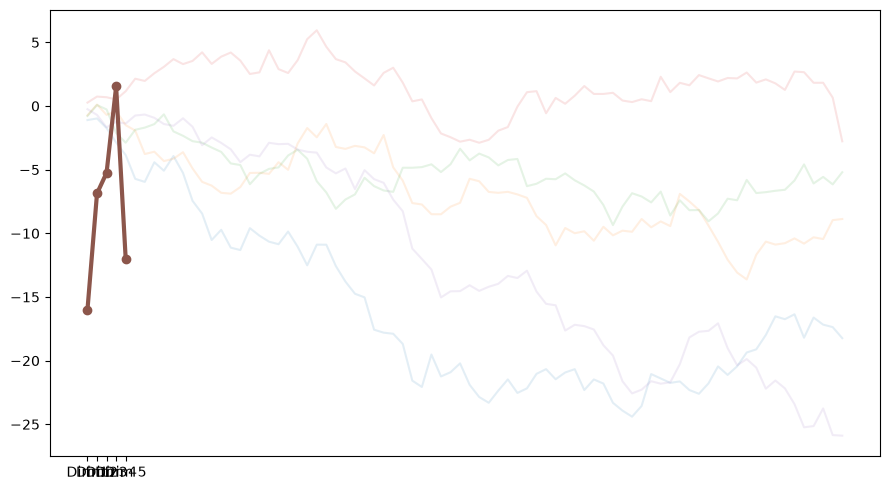

In [23]:
# PCP-Ed: Parallel coordinate plots for ensemble data
# Educational reconstruction for M.E. CSE Data Visualization Exercise-2.
# The reconstruction is NOT a reproduction of the authors' research findings.
# Replace only with published numerical values when the source provides them.
import matplotlib.pyplot as plt
import numpy as np


import os
from pathlib import Path as _Path


def _visualizations_dir() -> _Path:
    """Where saved figures go: env override -> repo folder -> cwd fallback."""
    if os.environ.get("EX2_VIS_DIR"):
        out = _Path(os.environ["EX2_VIS_DIR"])
    else:
        try:
            out = _Path(__file__).resolve().parent.parent / "visualizations"
        except NameError:  # exec()'d inside a notebook cell: no __file__
            out = _Path.cwd() / "visualizations"
    out.mkdir(parents=True, exist_ok=True)
    return out


# Illustrative reconstruction data / structure:
rng=np.random.default_rng(10); data=np.cumsum(rng.normal(0,1,(80,5)),axis=0)

# Plot:
fig,ax=plt.subplots(figsize=(9,5))
for c in range(5): ax.plot(data[:,c],alpha=.12)
ax.plot(data.mean(axis=0),lw=3,marker="o"); ax.set_xticks(range(5),[f"Dim {k}" for k in range(1,6)])

plt.tight_layout()
plt.savefig(_visualizations_dir() / "paper_10_improved.png", dpi=300, bbox_inches="tight")
plt.show()


paper_10_improved.png -> C:\Users\agnes\AppData\Local\Temp\opencode\exp2_kaggle_vis\paper_10_improved.png (221,145 bytes)


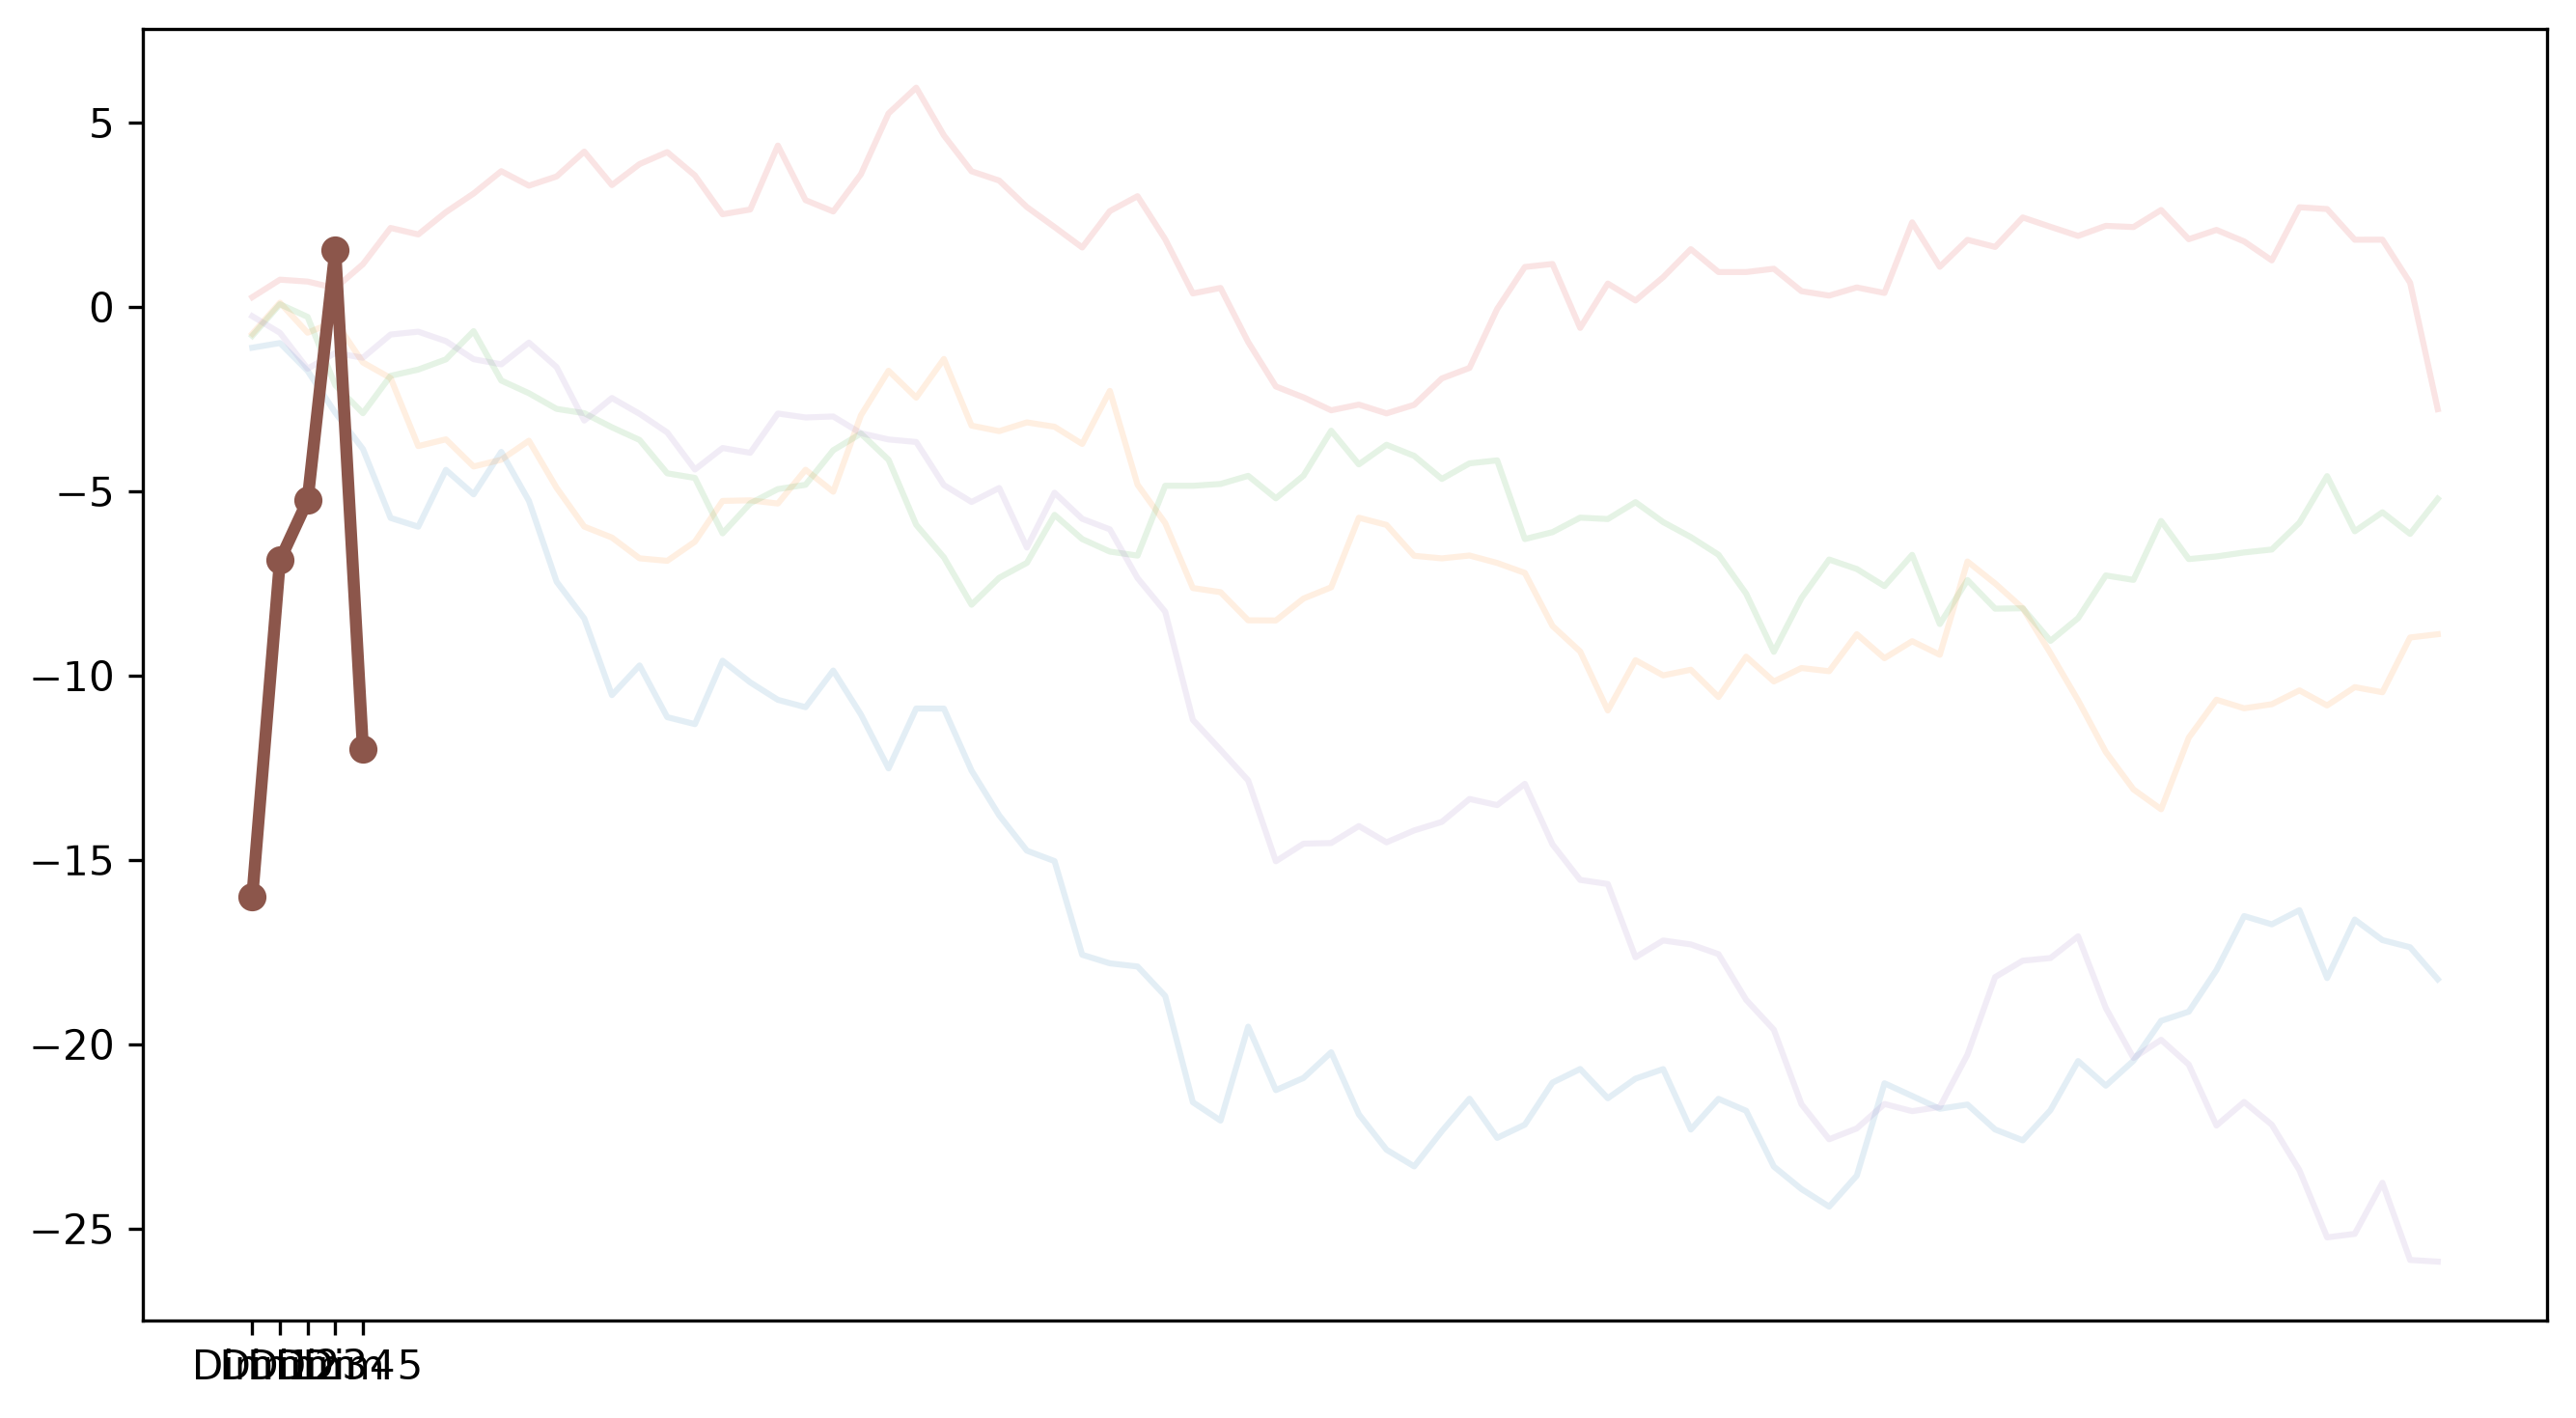

In [24]:

from IPython.display import Image, display
saved = VIS_DIR / "paper_10_improved.png"
size = saved.stat().st_size if saved.exists() else 0
print("paper_10_improved.png ->", saved, f"({size:,} bytes)" if saved.exists() else "(not written)")
if saved.exists():
    display(Image(filename=str(saved), width=780))


#### 11. VMetaFlow: A Meta-Framework for Integrating Visualizations in Coordinated View Applications

*IEEE Xplore, 2022* — chart type: **Flow / coordinated views**

**Redesign problem.** Cross-view relationships can be difficult to follow when connectors cross or lack directional emphasis.


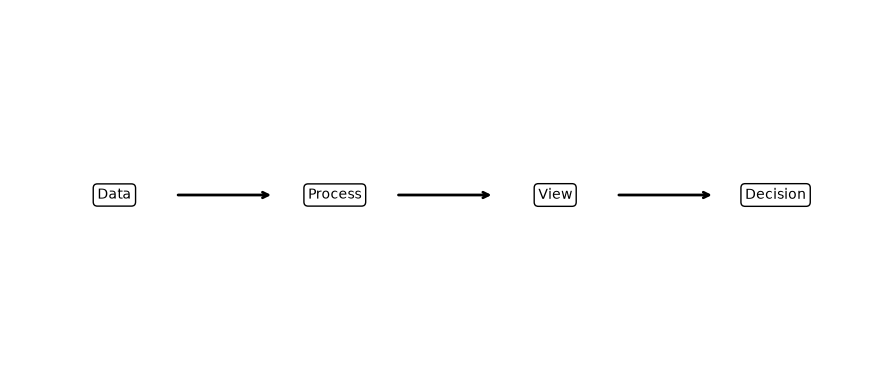

In [25]:
# VMetaFlow: A Meta-Framework for Integrating Visualizations in Coordinated View Applications
# Educational reconstruction for M.E. CSE Data Visualization Exercise-2.
# The reconstruction is NOT a reproduction of the authors' research findings.
# Replace only with published numerical values when the source provides them.
import matplotlib.pyplot as plt
import numpy as np


import os
from pathlib import Path as _Path


def _visualizations_dir() -> _Path:
    """Where saved figures go: env override -> repo folder -> cwd fallback."""
    if os.environ.get("EX2_VIS_DIR"):
        out = _Path(os.environ["EX2_VIS_DIR"])
    else:
        try:
            out = _Path(__file__).resolve().parent.parent / "visualizations"
        except NameError:  # exec()'d inside a notebook cell: no __file__
            out = _Path.cwd() / "visualizations"
    out.mkdir(parents=True, exist_ok=True)
    return out


# Illustrative reconstruction data / structure:
stages=["Data","Process","View","Decision"]

# Plot:
fig,ax=plt.subplots(figsize=(9,4)); ax.axis("off"); xs=np.linspace(.12,.88,4)
for k,(x,s) in enumerate(zip(xs,stages)):
    ax.text(x,.5,s,ha="center",va="center",bbox=dict(boxstyle="round",facecolor="white",edgecolor="black"))
    if k<3: ax.annotate("",(xs[k+1]-.07,.5),(x+.07,.5),arrowprops=dict(arrowstyle="->",lw=2))

plt.tight_layout()
plt.savefig(_visualizations_dir() / "paper_11_improved.png", dpi=300, bbox_inches="tight")
plt.show()


paper_11_improved.png -> C:\Users\agnes\AppData\Local\Temp\opencode\exp2_kaggle_vis\paper_11_improved.png (31,506 bytes)


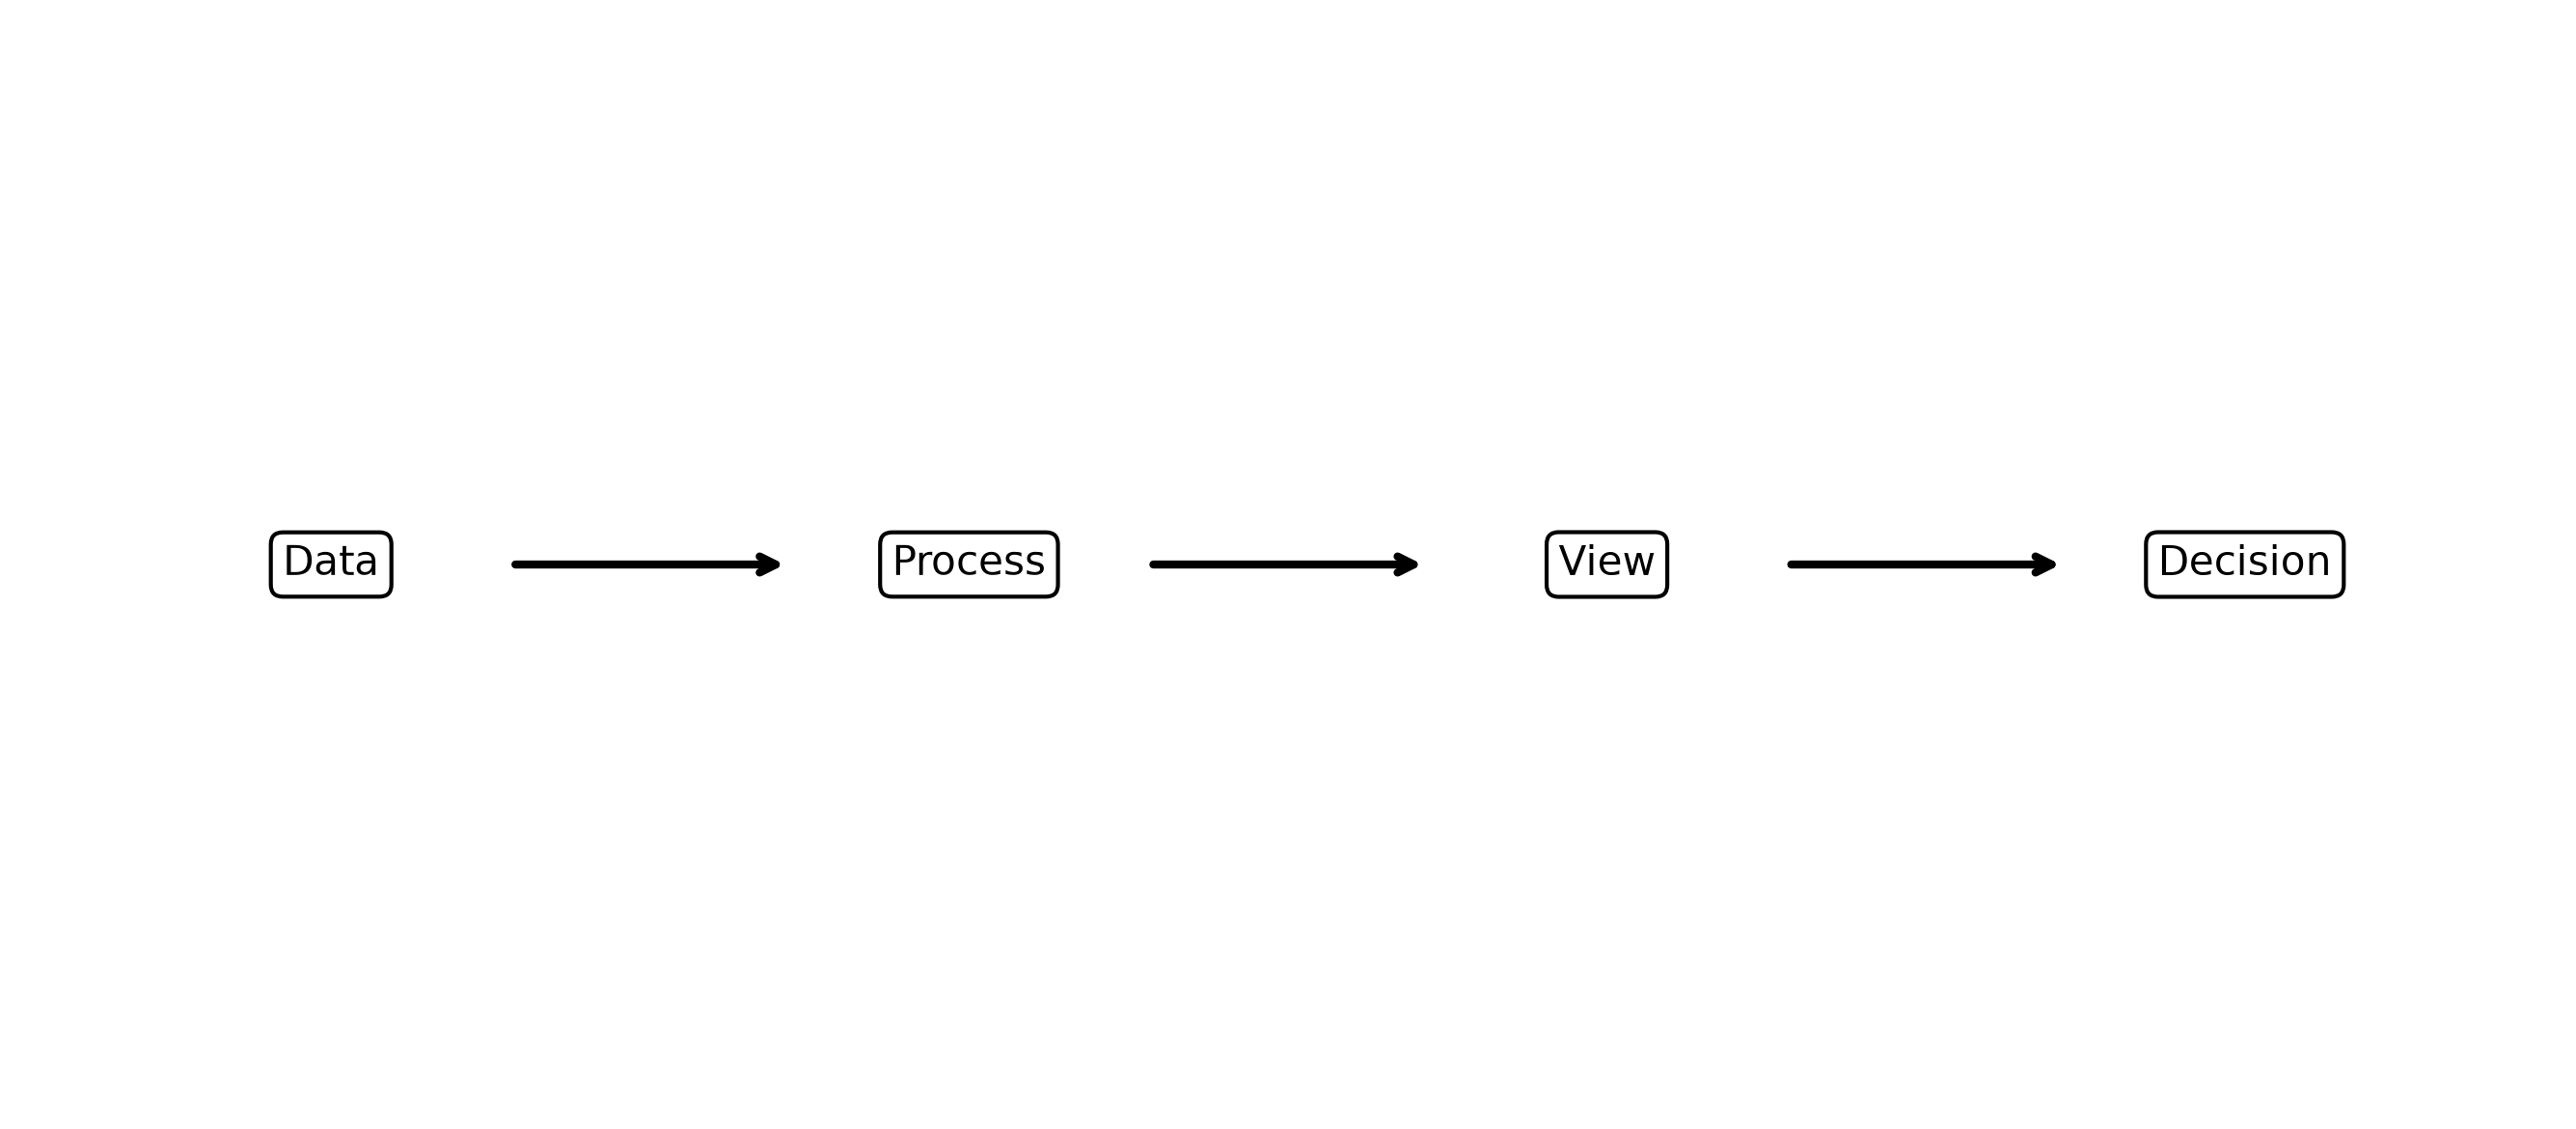

In [26]:

from IPython.display import Image, display
saved = VIS_DIR / "paper_11_improved.png"
size = saved.stat().st_size if saved.exists() else 0
print("paper_11_improved.png ->", saved, f"({size:,} bytes)" if saved.exists() else "(not written)")
if saved.exists():
    display(Image(filename=str(saved), width=780))


#### 12. Evaluating user cognition of network diagrams

*ScienceDirect, 2021* — chart type: **Network graph**

**Redesign problem.** Edge crossings and node overlap increase visual interference and can hinder path recognition.


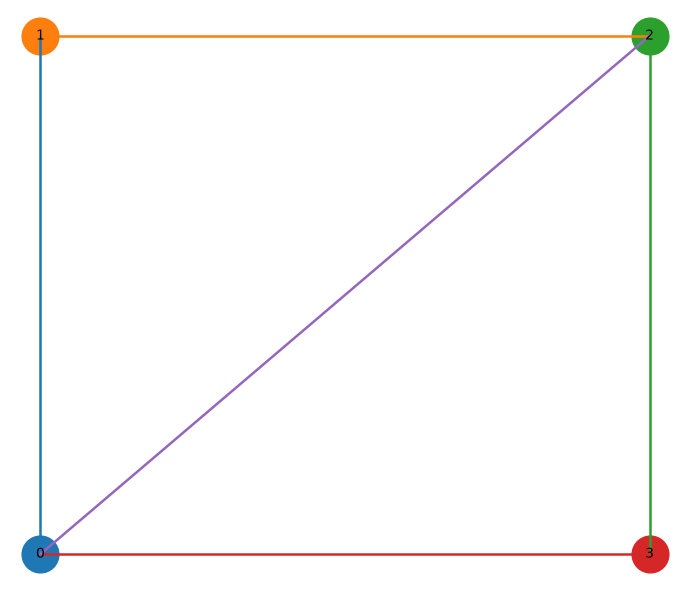

In [27]:
# Evaluating user cognition of network diagrams
# Educational reconstruction for M.E. CSE Data Visualization Exercise-2.
# The reconstruction is NOT a reproduction of the authors' research findings.
# Replace only with published numerical values when the source provides them.
import matplotlib.pyplot as plt
import numpy as np


import os
from pathlib import Path as _Path


def _visualizations_dir() -> _Path:
    """Where saved figures go: env override -> repo folder -> cwd fallback."""
    if os.environ.get("EX2_VIS_DIR"):
        out = _Path(os.environ["EX2_VIS_DIR"])
    else:
        try:
            out = _Path(__file__).resolve().parent.parent / "visualizations"
        except NameError:  # exec()'d inside a notebook cell: no __file__
            out = _Path.cwd() / "visualizations"
    out.mkdir(parents=True, exist_ok=True)
    return out


# Illustrative reconstruction data / structure:
edges=[(0,1),(1,2),(2,3),(0,3),(0,2)]; pos={0:(0,0),1:(0,1),2:(1,1),3:(1,0)}

# Plot:
fig,ax=plt.subplots(figsize=(7,6))
for a,b in edges: ax.plot([pos[a][0],pos[b][0]],[pos[a][1],pos[b][1]],lw=1.8)
for n,(x,y) in pos.items(): ax.scatter(x,y,s=700); ax.text(x,y,str(n),ha="center",va="center")
ax.axis("off")

plt.tight_layout()
plt.savefig(_visualizations_dir() / "paper_12_improved.png", dpi=300, bbox_inches="tight")
plt.show()


paper_12_improved.png -> C:\Users\agnes\AppData\Local\Temp\opencode\exp2_kaggle_vis\paper_12_improved.png (76,881 bytes)


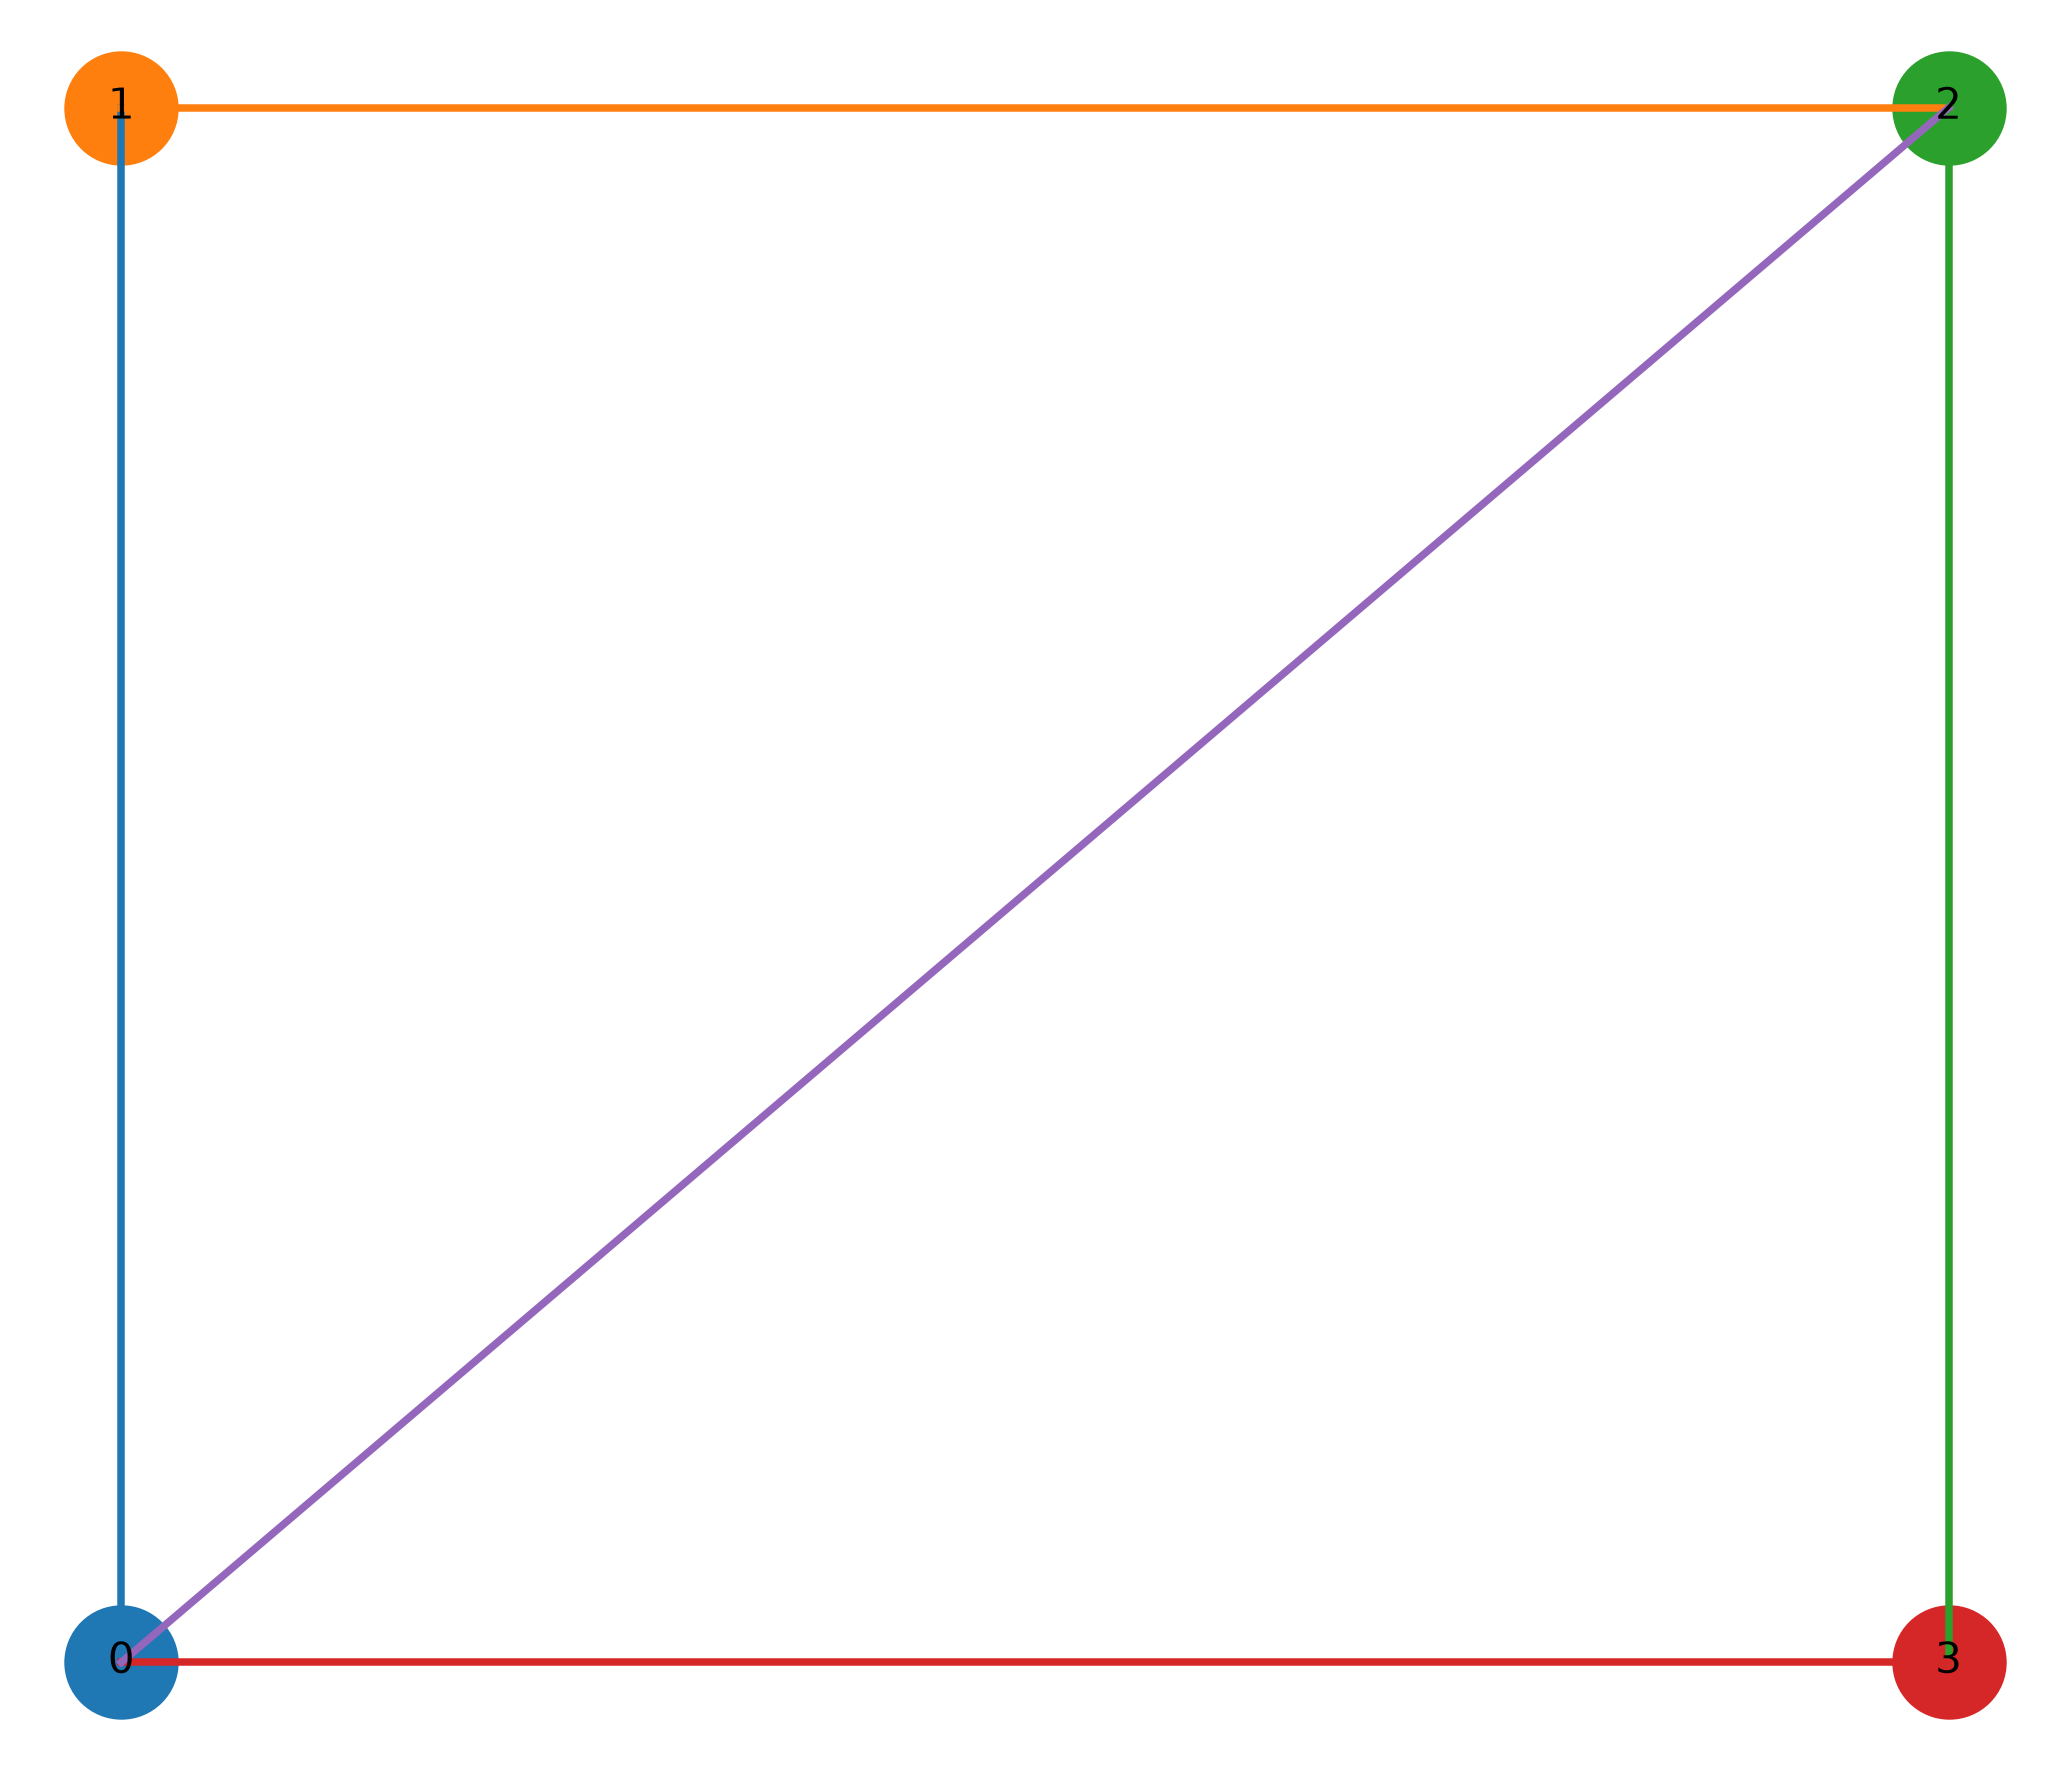

In [28]:

from IPython.display import Image, display
saved = VIS_DIR / "paper_12_improved.png"
size = saved.stat().st_size if saved.exists() else 0
print("paper_12_improved.png ->", saved, f"({size:,} bytes)" if saved.exists() else "(not written)")
if saved.exists():
    display(Image(filename=str(saved), width=780))


#### 13. Data Visualization and its Key Fundamentals: A Comprehensive Survey

*IEEE Xplore, 2022* — chart type: **Chart-type comparison / infographic**

**Redesign problem.** Many chart types shown together can create choice overload; a grouped decision structure improves scanability.


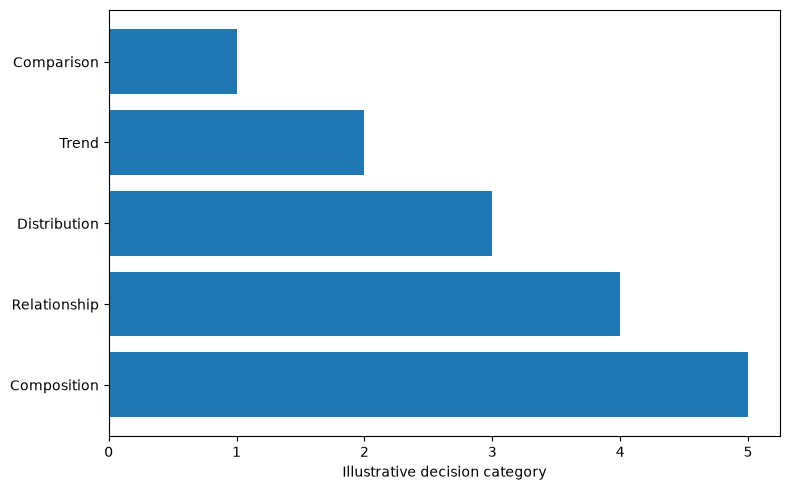

In [29]:
# Data Visualization and its Key Fundamentals: A Comprehensive Survey
# Educational reconstruction for M.E. CSE Data Visualization Exercise-2.
# The reconstruction is NOT a reproduction of the authors' research findings.
# Replace only with published numerical values when the source provides them.
import matplotlib.pyplot as plt
import numpy as np


import os
from pathlib import Path as _Path


def _visualizations_dir() -> _Path:
    """Where saved figures go: env override -> repo folder -> cwd fallback."""
    if os.environ.get("EX2_VIS_DIR"):
        out = _Path(os.environ["EX2_VIS_DIR"])
    else:
        try:
            out = _Path(__file__).resolve().parent.parent / "visualizations"
        except NameError:  # exec()'d inside a notebook cell: no __file__
            out = _Path.cwd() / "visualizations"
    out.mkdir(parents=True, exist_ok=True)
    return out


# Illustrative reconstruction data / structure:
types=["Comparison","Trend","Distribution","Relationship","Composition"]; vals=[1,2,3,4,5]

# Plot:
fig,ax=plt.subplots(figsize=(8,5)); y=np.arange(len(types)); ax.barh(y,vals); ax.set_yticks(y,types); ax.invert_yaxis()
ax.set_xlabel("Illustrative decision category")

plt.tight_layout()
plt.savefig(_visualizations_dir() / "paper_13_improved.png", dpi=300, bbox_inches="tight")
plt.show()


paper_13_improved.png -> C:\Users\agnes\AppData\Local\Temp\opencode\exp2_kaggle_vis\paper_13_improved.png (52,223 bytes)


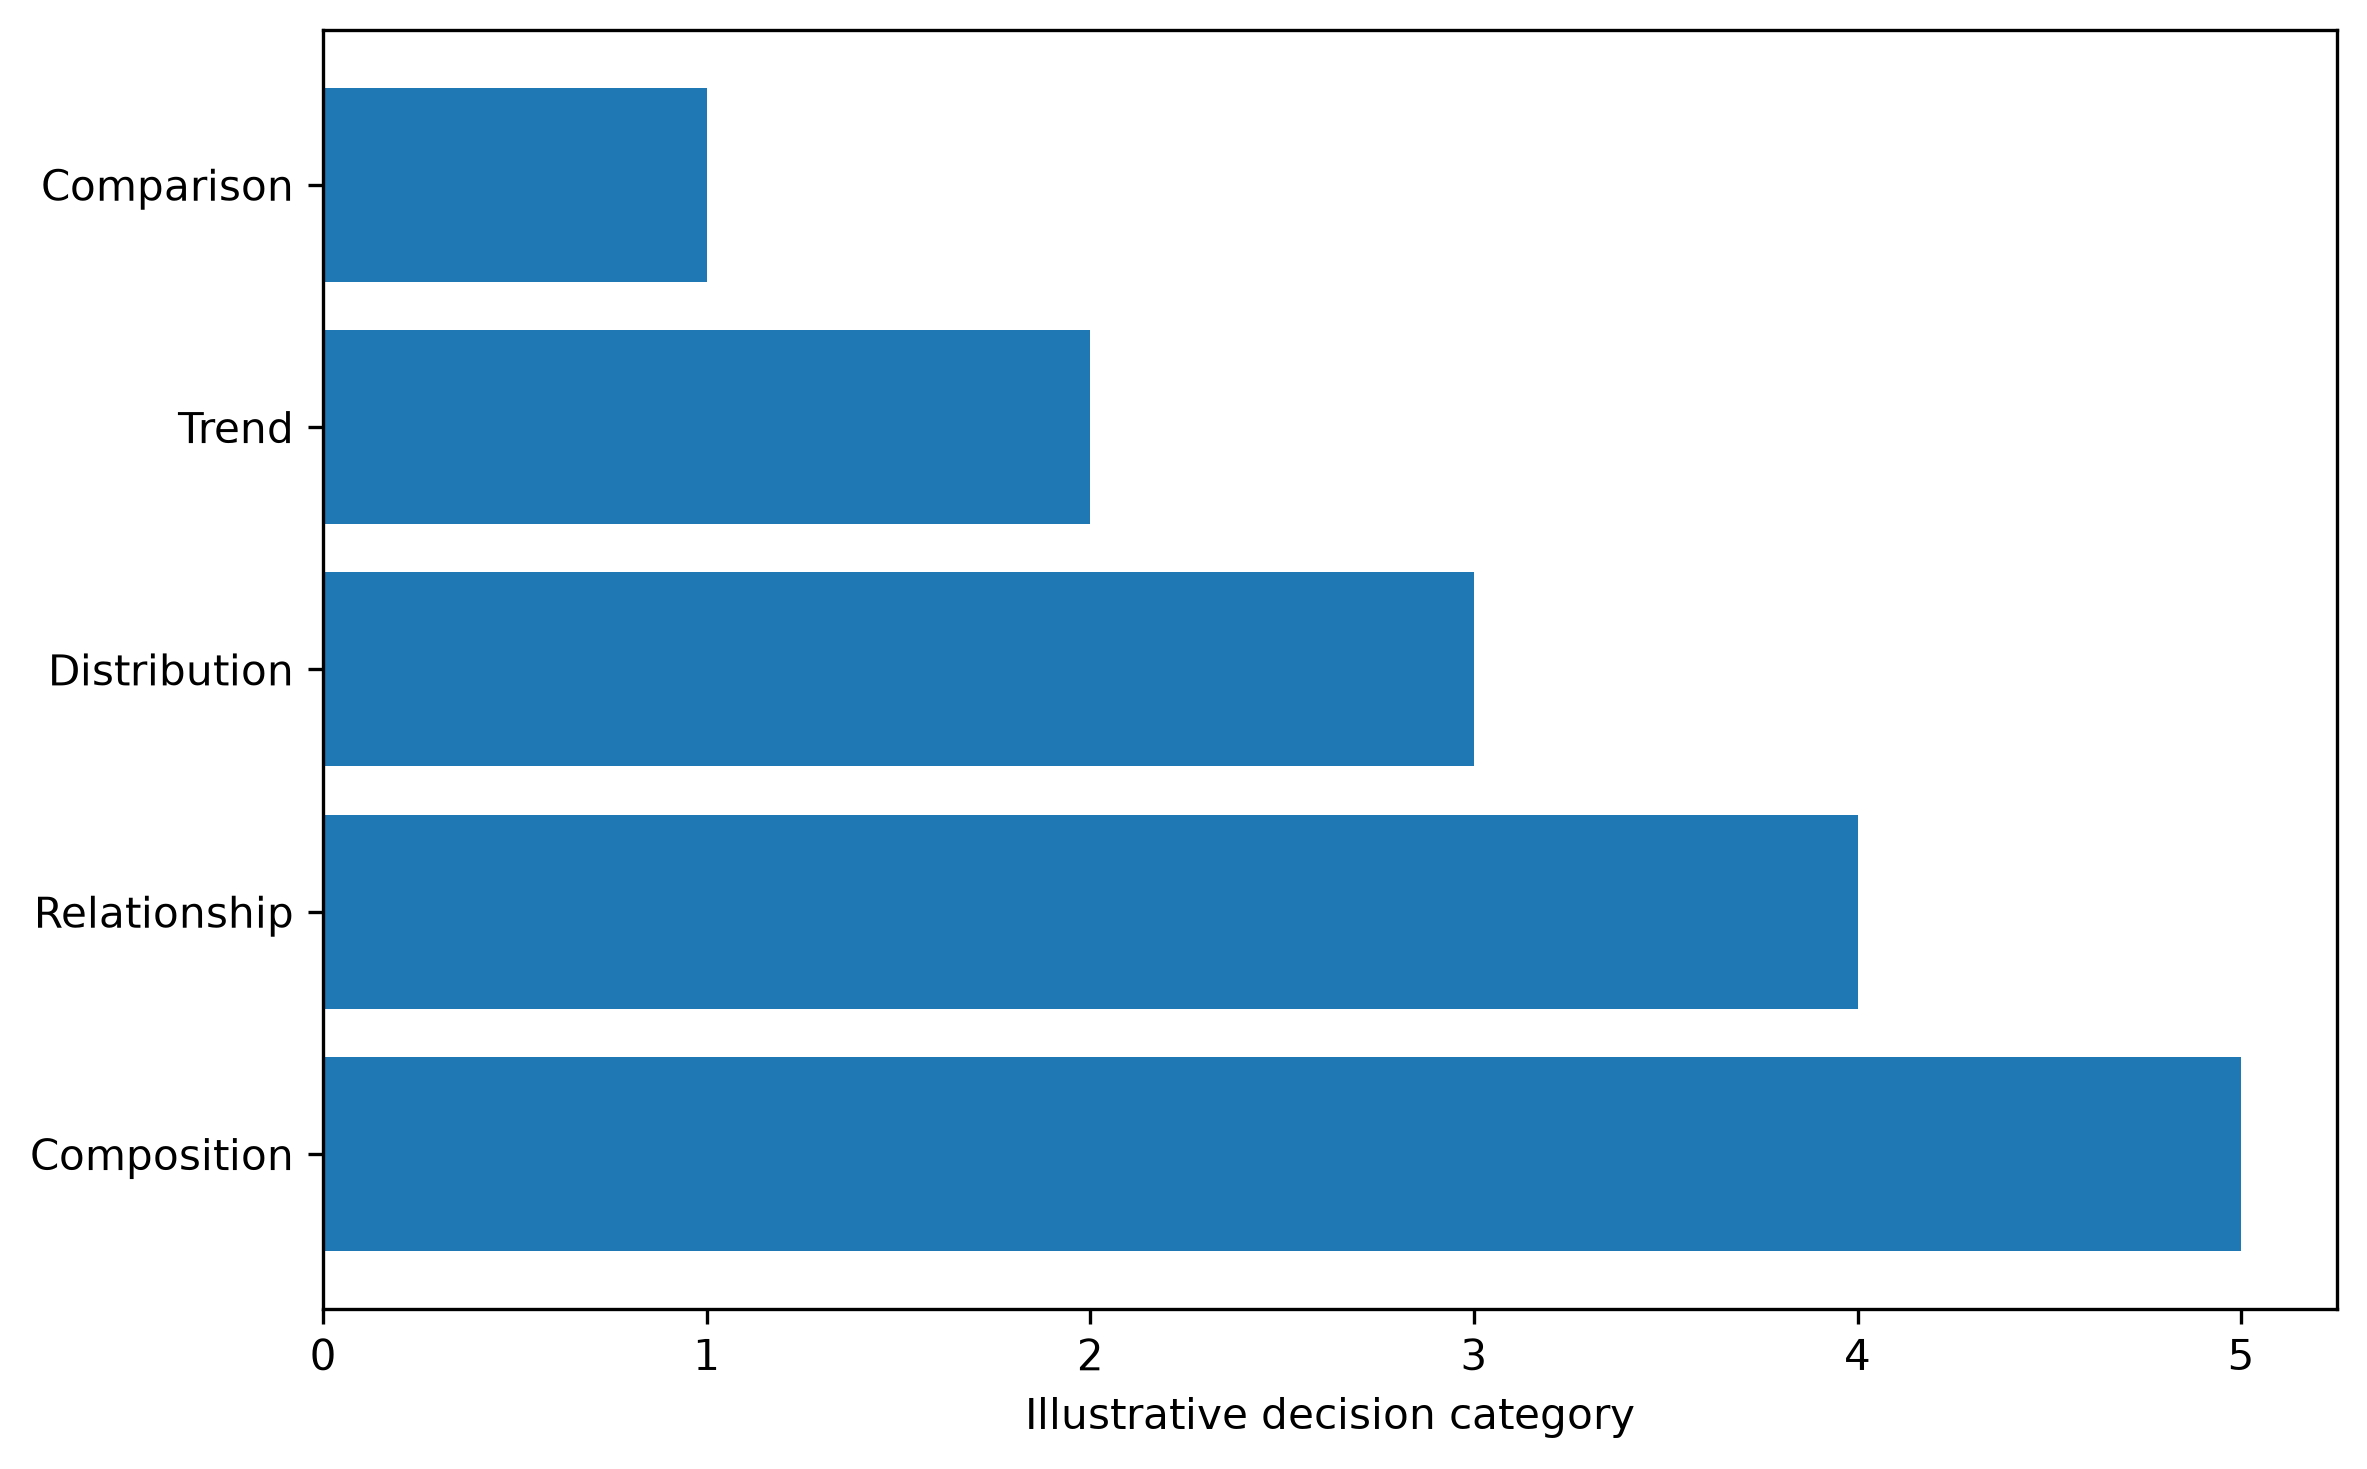

In [30]:

from IPython.display import Image, display
saved = VIS_DIR / "paper_13_improved.png"
size = saved.stat().st_size if saved.exists() else 0
print("paper_13_improved.png ->", saved, f"({size:,} bytes)" if saved.exists() else "(not written)")
if saved.exists():
    display(Image(filename=str(saved), width=780))


#### 14. Evaluation on interactive visualization data with scatterplots

*ScienceDirect, 2020* — chart type: **Scatterplot matrix / small multiples**

**Redesign problem.** Displaying many plots simultaneously increases density; small multiples with consistent scales can improve targeted comparison.


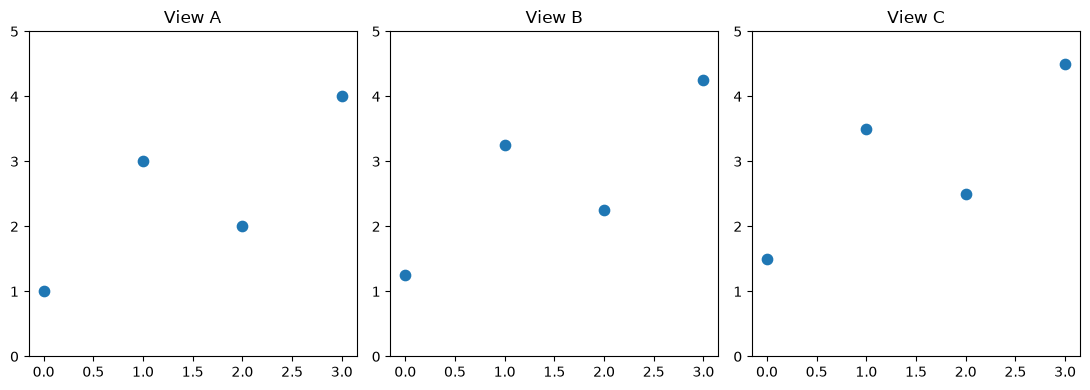

In [31]:
# Evaluation on interactive visualization data with scatterplots
# Educational reconstruction for M.E. CSE Data Visualization Exercise-2.
# The reconstruction is NOT a reproduction of the authors' research findings.
# Replace only with published numerical values when the source provides them.
import matplotlib.pyplot as plt
import numpy as np


import os
from pathlib import Path as _Path


def _visualizations_dir() -> _Path:
    """Where saved figures go: env override -> repo folder -> cwd fallback."""
    if os.environ.get("EX2_VIS_DIR"):
        out = _Path(os.environ["EX2_VIS_DIR"])
    else:
        try:
            out = _Path(__file__).resolve().parent.parent / "visualizations"
        except NameError:  # exec()'d inside a notebook cell: no __file__
            out = _Path.cwd() / "visualizations"
    out.mkdir(parents=True, exist_ok=True)
    return out


# Illustrative reconstruction data / structure:
x=np.arange(4); a=np.array([1,3,2,4]); b=np.array([2,4,1,3])

# Plot:
fig,axes=plt.subplots(1,3,figsize=(11,4))
for ax,off,title in zip(axes,[0,.25,.5],["View A","View B","View C"]):
    ax.scatter(x,a+off,s=55); ax.set_title(title); ax.set_ylim(0,5)

plt.tight_layout()
plt.savefig(_visualizations_dir() / "paper_14_improved.png", dpi=300, bbox_inches="tight")
plt.show()


paper_14_improved.png -> C:\Users\agnes\AppData\Local\Temp\opencode\exp2_kaggle_vis\paper_14_improved.png (53,371 bytes)


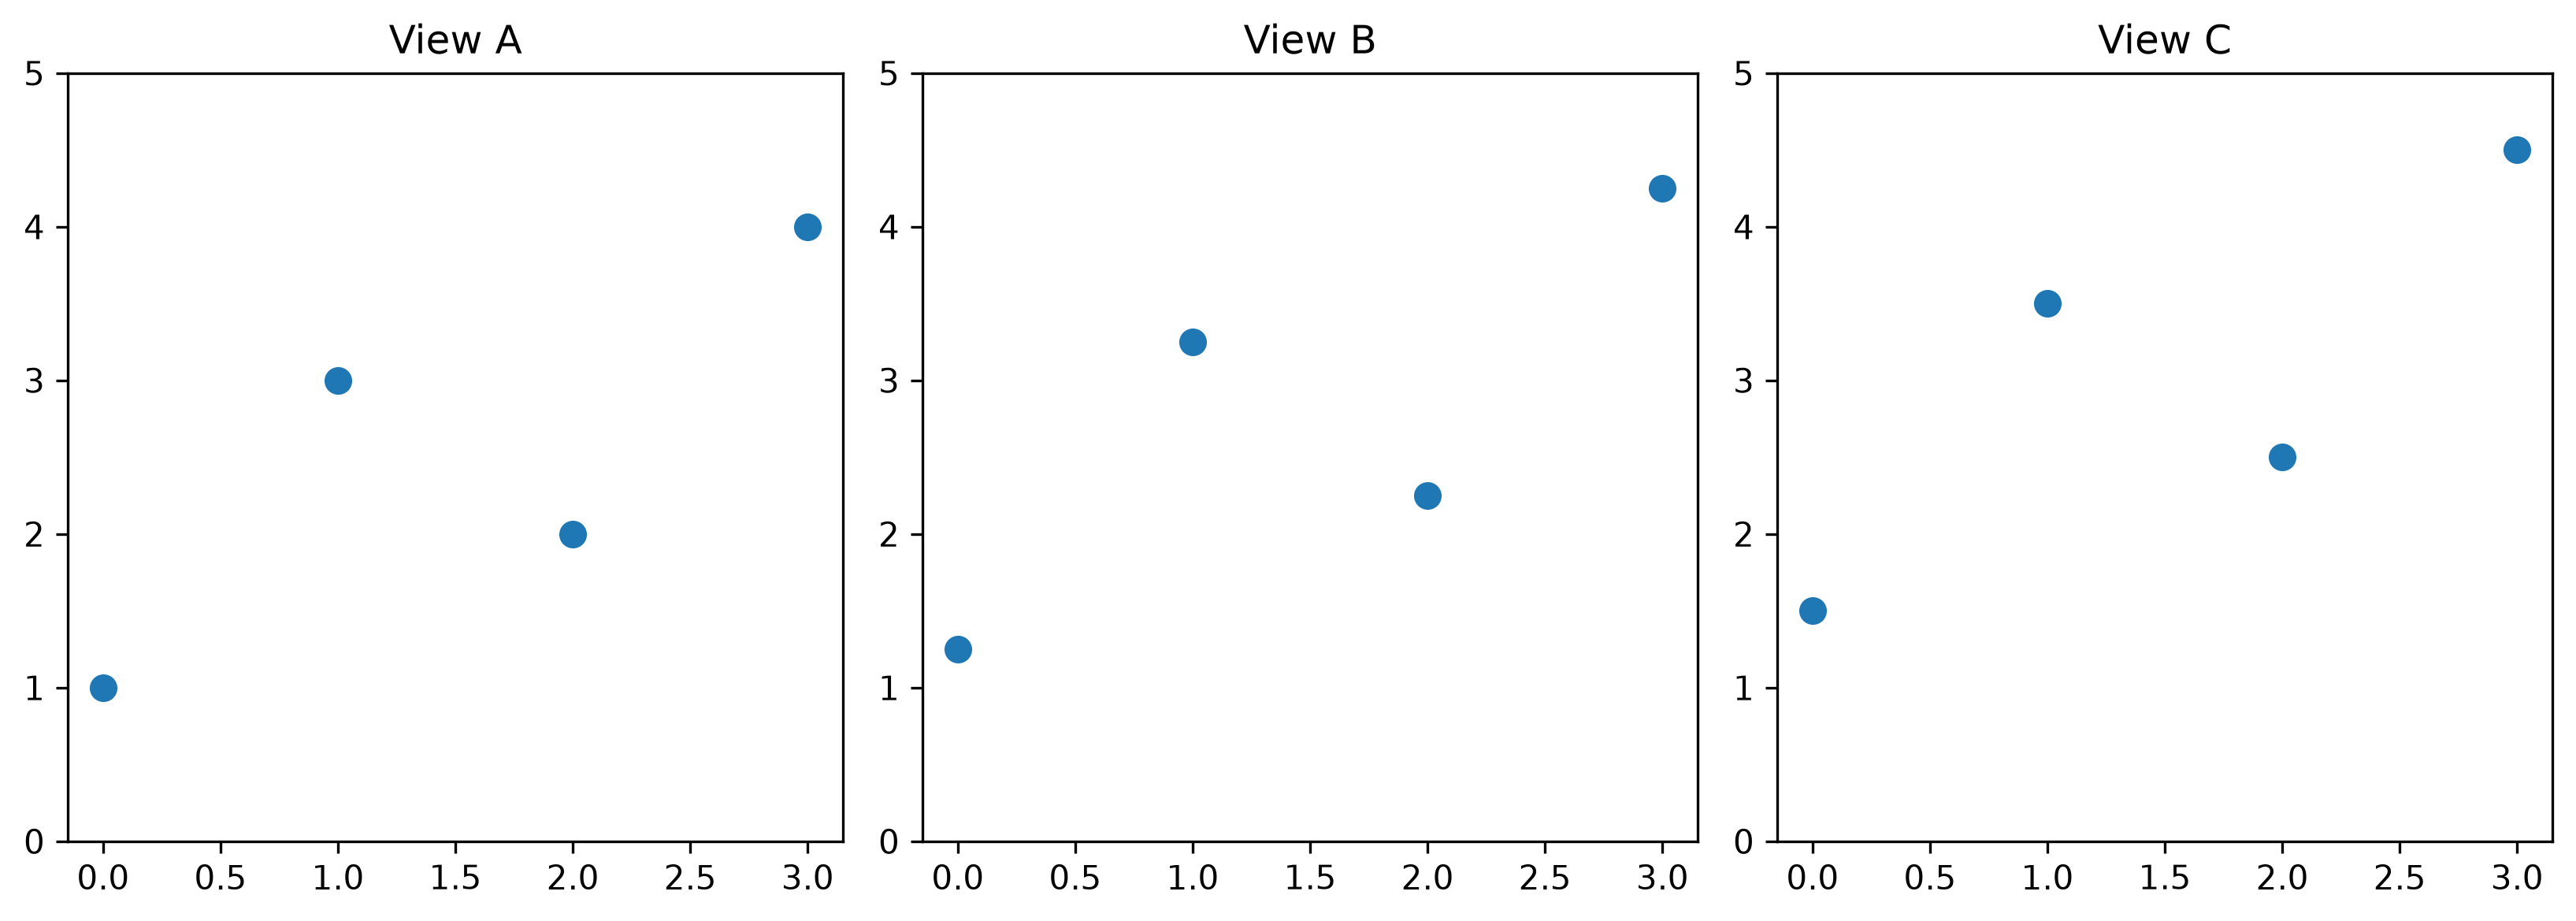

In [32]:

from IPython.display import Image, display
saved = VIS_DIR / "paper_14_improved.png"
size = saved.stat().st_size if saved.exists() else 0
print("paper_14_improved.png ->", saved, f"({size:,} bytes)" if saved.exists() else "(not written)")
if saved.exists():
    display(Image(filename=str(saved), width=780))


#### 15. Comparative eye-tracking evaluation of scatterplots and parallel coordinates

*ScienceDirect, 2017* — chart type: **Comparative plot**

**Redesign problem.** Different dimensionalities and diagram types require explicit separation to avoid mixing task conditions.


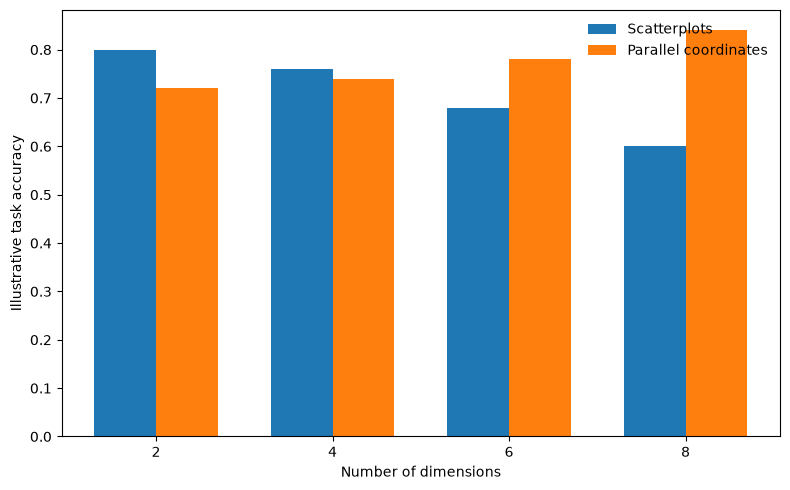

In [33]:
# Comparative eye-tracking evaluation of scatterplots and parallel coordinates
# Educational reconstruction for M.E. CSE Data Visualization Exercise-2.
# The reconstruction is NOT a reproduction of the authors' research findings.
# Replace only with published numerical values when the source provides them.
import matplotlib.pyplot as plt
import numpy as np


import os
from pathlib import Path as _Path


def _visualizations_dir() -> _Path:
    """Where saved figures go: env override -> repo folder -> cwd fallback."""
    if os.environ.get("EX2_VIS_DIR"):
        out = _Path(os.environ["EX2_VIS_DIR"])
    else:
        try:
            out = _Path(__file__).resolve().parent.parent / "visualizations"
        except NameError:  # exec()'d inside a notebook cell: no __file__
            out = _Path.cwd() / "visualizations"
    out.mkdir(parents=True, exist_ok=True)
    return out


# Illustrative reconstruction data / structure:
dims=[2,4,6,8]; scatter=[.80,.76,.68,.60]; pcp=[.72,.74,.78,.84]

# Plot:
fig,ax=plt.subplots(figsize=(8,5)); x=np.arange(len(dims)); w=.35
ax.bar(x-w/2,scatter,w,label="Scatterplots"); ax.bar(x+w/2,pcp,w,label="Parallel coordinates")
ax.set_xticks(x,dims); ax.set_xlabel("Number of dimensions"); ax.set_ylabel("Illustrative task accuracy"); ax.legend(frameon=False)

plt.tight_layout()
plt.savefig(_visualizations_dir() / "paper_15_improved.png", dpi=300, bbox_inches="tight")
plt.show()


paper_15_improved.png -> C:\Users\agnes\AppData\Local\Temp\opencode\exp2_kaggle_vis\paper_15_improved.png (69,367 bytes)


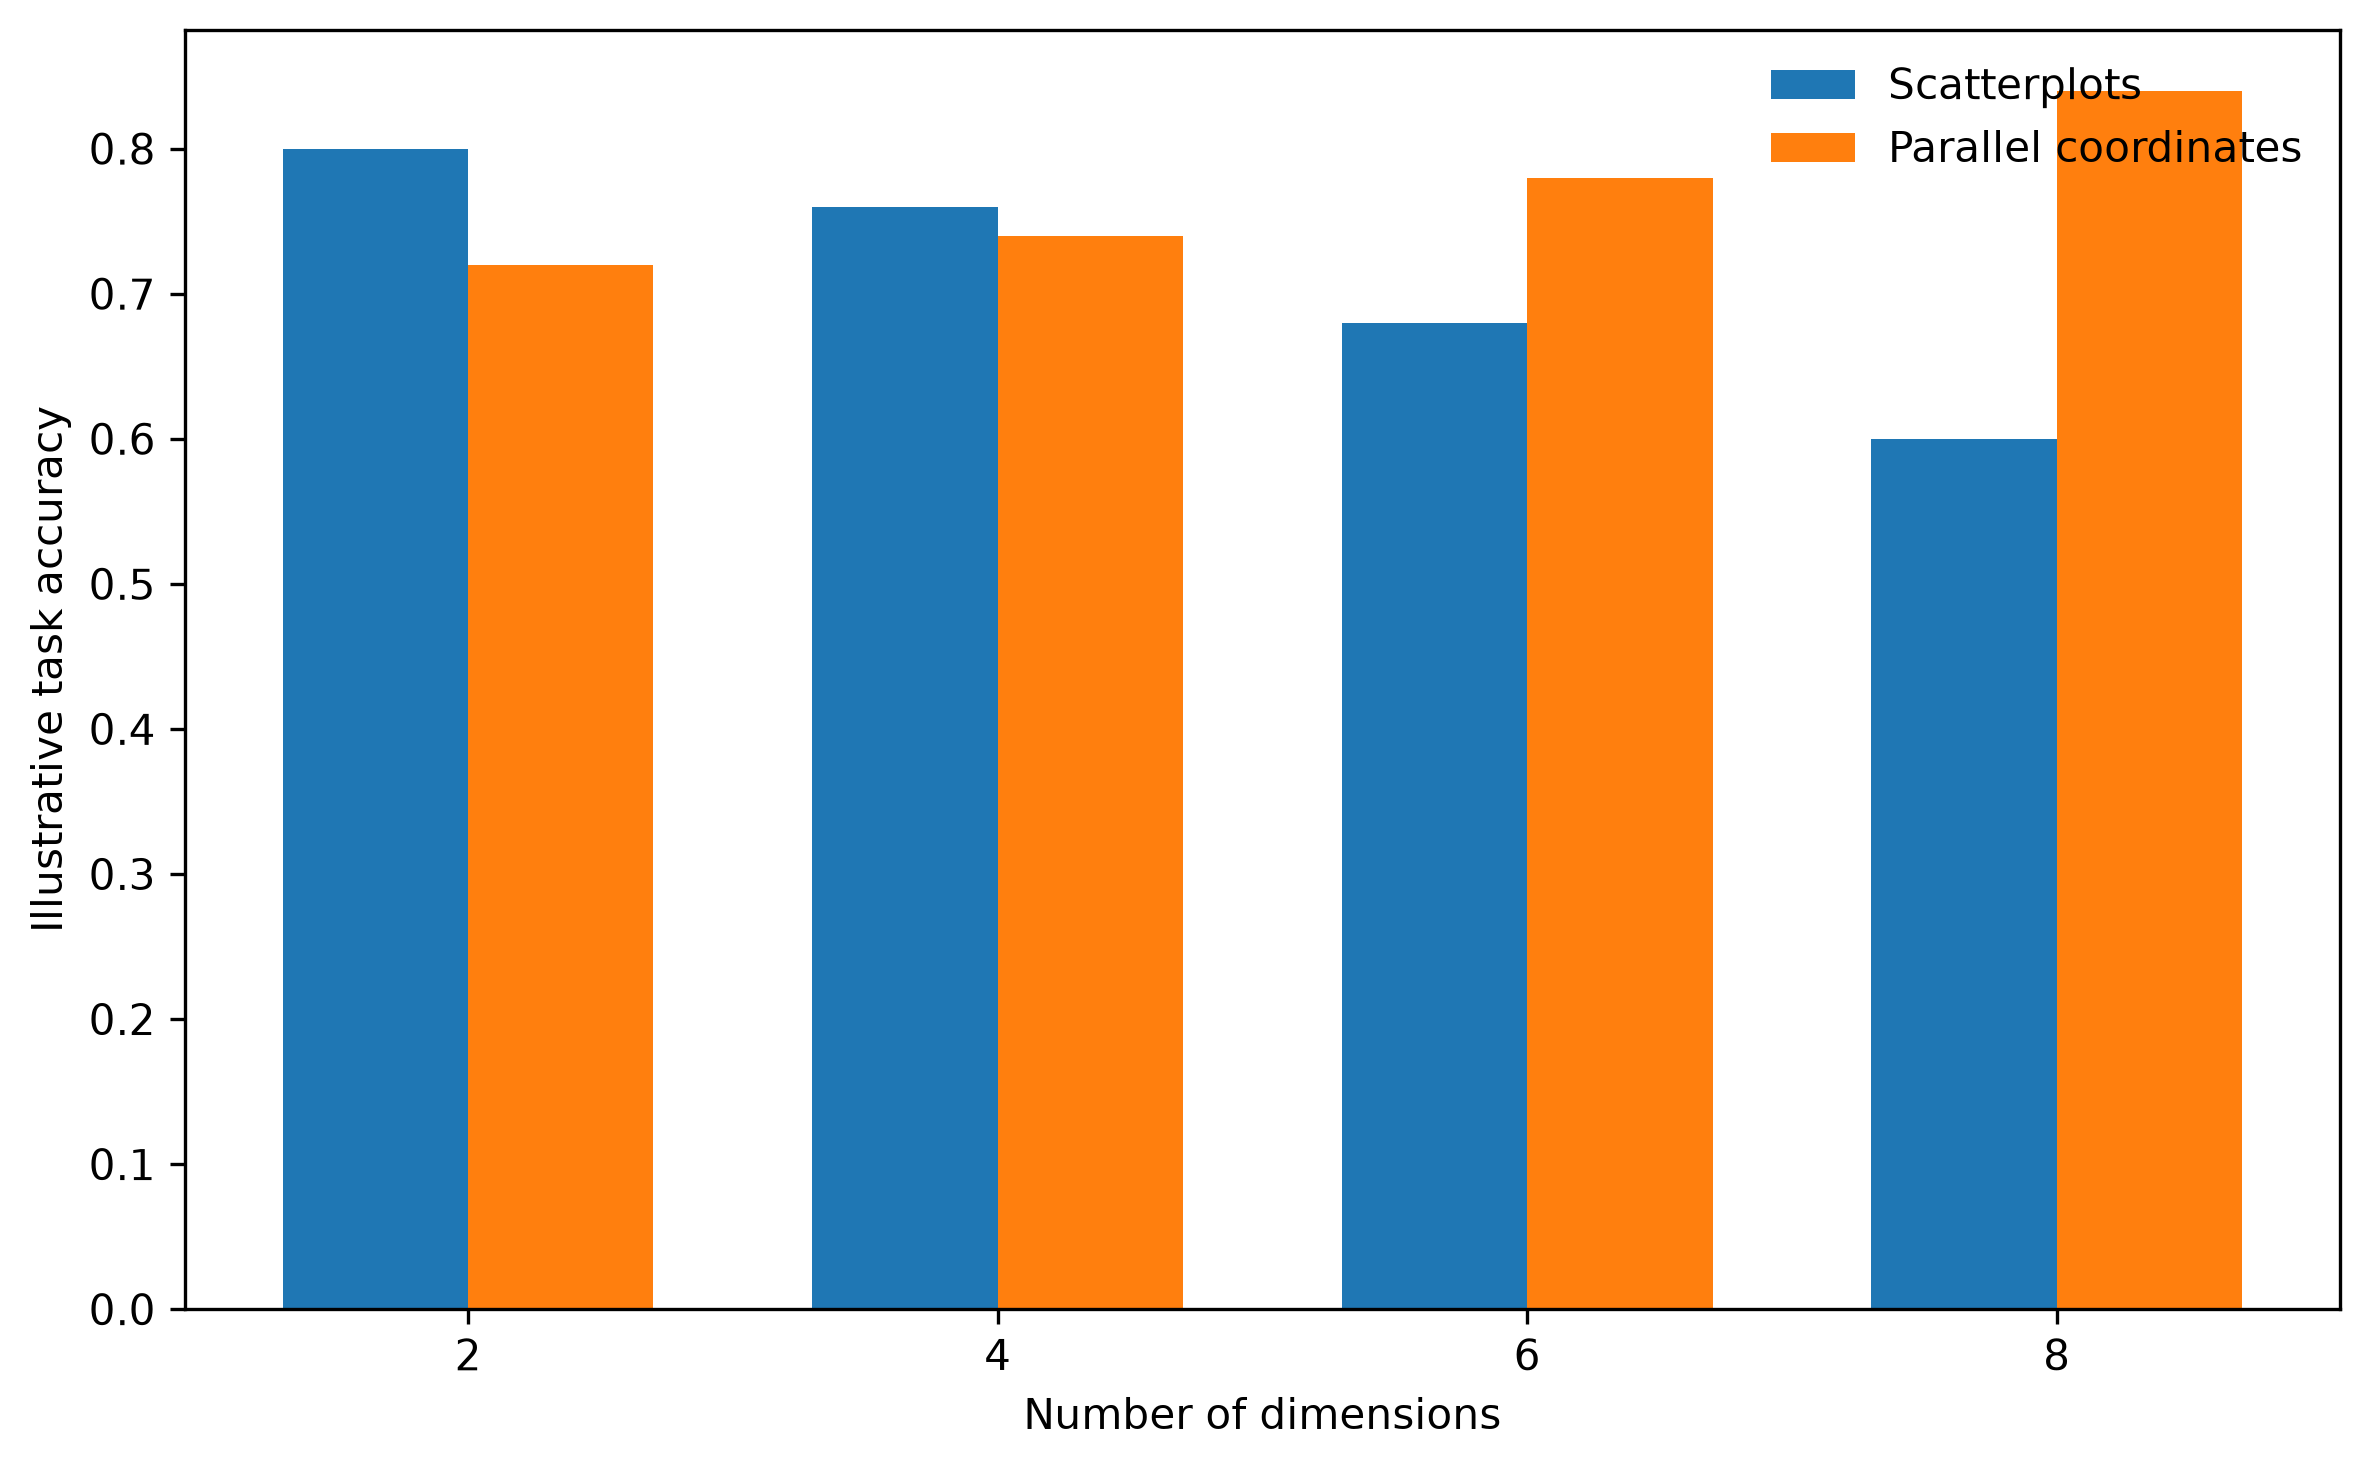

In [34]:

from IPython.display import Image, display
saved = VIS_DIR / "paper_15_improved.png"
size = saved.stat().st_size if saved.exists() else 0
print("paper_15_improved.png ->", saved, f"({size:,} bytes)" if saved.exists() else "(not written)")
if saved.exists():
    display(Image(filename=str(saved), width=780))


## 4. Output gallery

All fifteen regenerated figures, read back from the figure folder.


In [35]:

from IPython.display import Image, display

improved = sorted(VIS_DIR.glob("paper_*_improved.png"))
print(f"{len(improved)} regenerated figure(s) in {VIS_DIR}")
for path in improved:
    print(" -", path.name, f"({path.stat().st_size:,} bytes)")


15 regenerated figure(s) in C:\Users\agnes\AppData\Local\Temp\opencode\exp2_kaggle_vis
 - paper_01_improved.png (55,339 bytes)
 - paper_02_improved.png (48,932 bytes)
 - paper_03_improved.png (47,726 bytes)
 - paper_04_improved.png (34,919 bytes)
 - paper_05_improved.png (47,537 bytes)
 - paper_06_improved.png (49,880 bytes)
 - paper_07_improved.png (45,986 bytes)
 - paper_08_improved.png (131,582 bytes)
 - paper_09_improved.png (62,982 bytes)
 - paper_10_improved.png (221,145 bytes)
 - paper_11_improved.png (31,506 bytes)
 - paper_12_improved.png (76,881 bytes)
 - paper_13_improved.png (52,223 bytes)
 - paper_14_improved.png (53,371 bytes)
 - paper_15_improved.png (69,367 bytes)


### Poor baseline vs. redesigned figure

The package ships one `paper_XX_poor.png` baseline per paper. Those baselines
are **authored artefacts of the exercise** — they are *not* regenerated by any
script, so they are only shown when the image files were uploaded alongside the
notebook. When they are missing, the notebook says so instead of pretending.


15 poor-baseline figure(s) found

--- paper_01_poor.png (authored baseline) ---


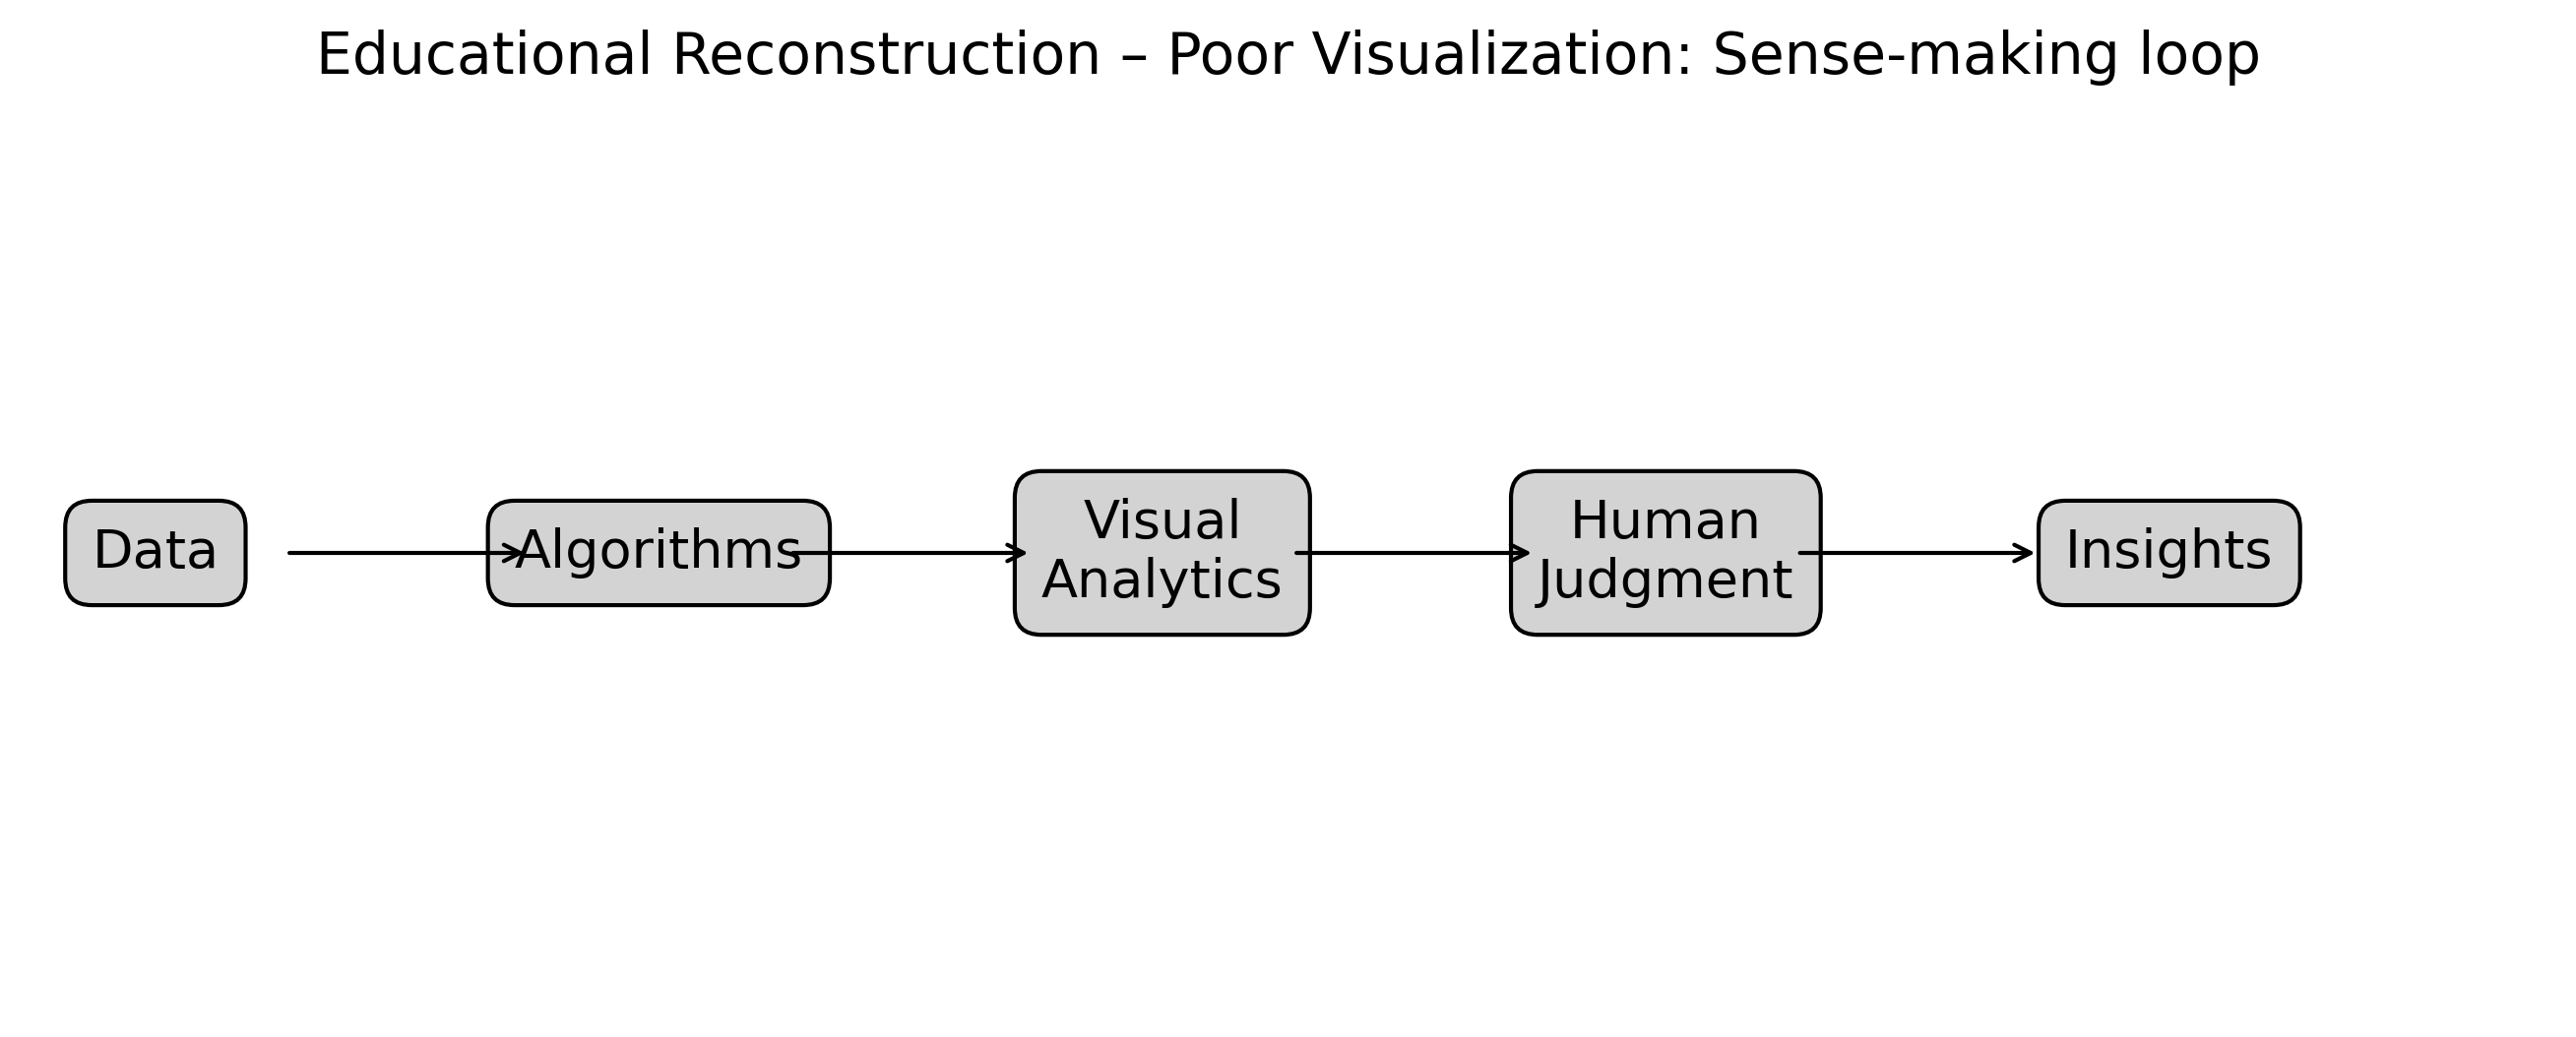

--- paper_01_improved.png (regenerated by this notebook) ---


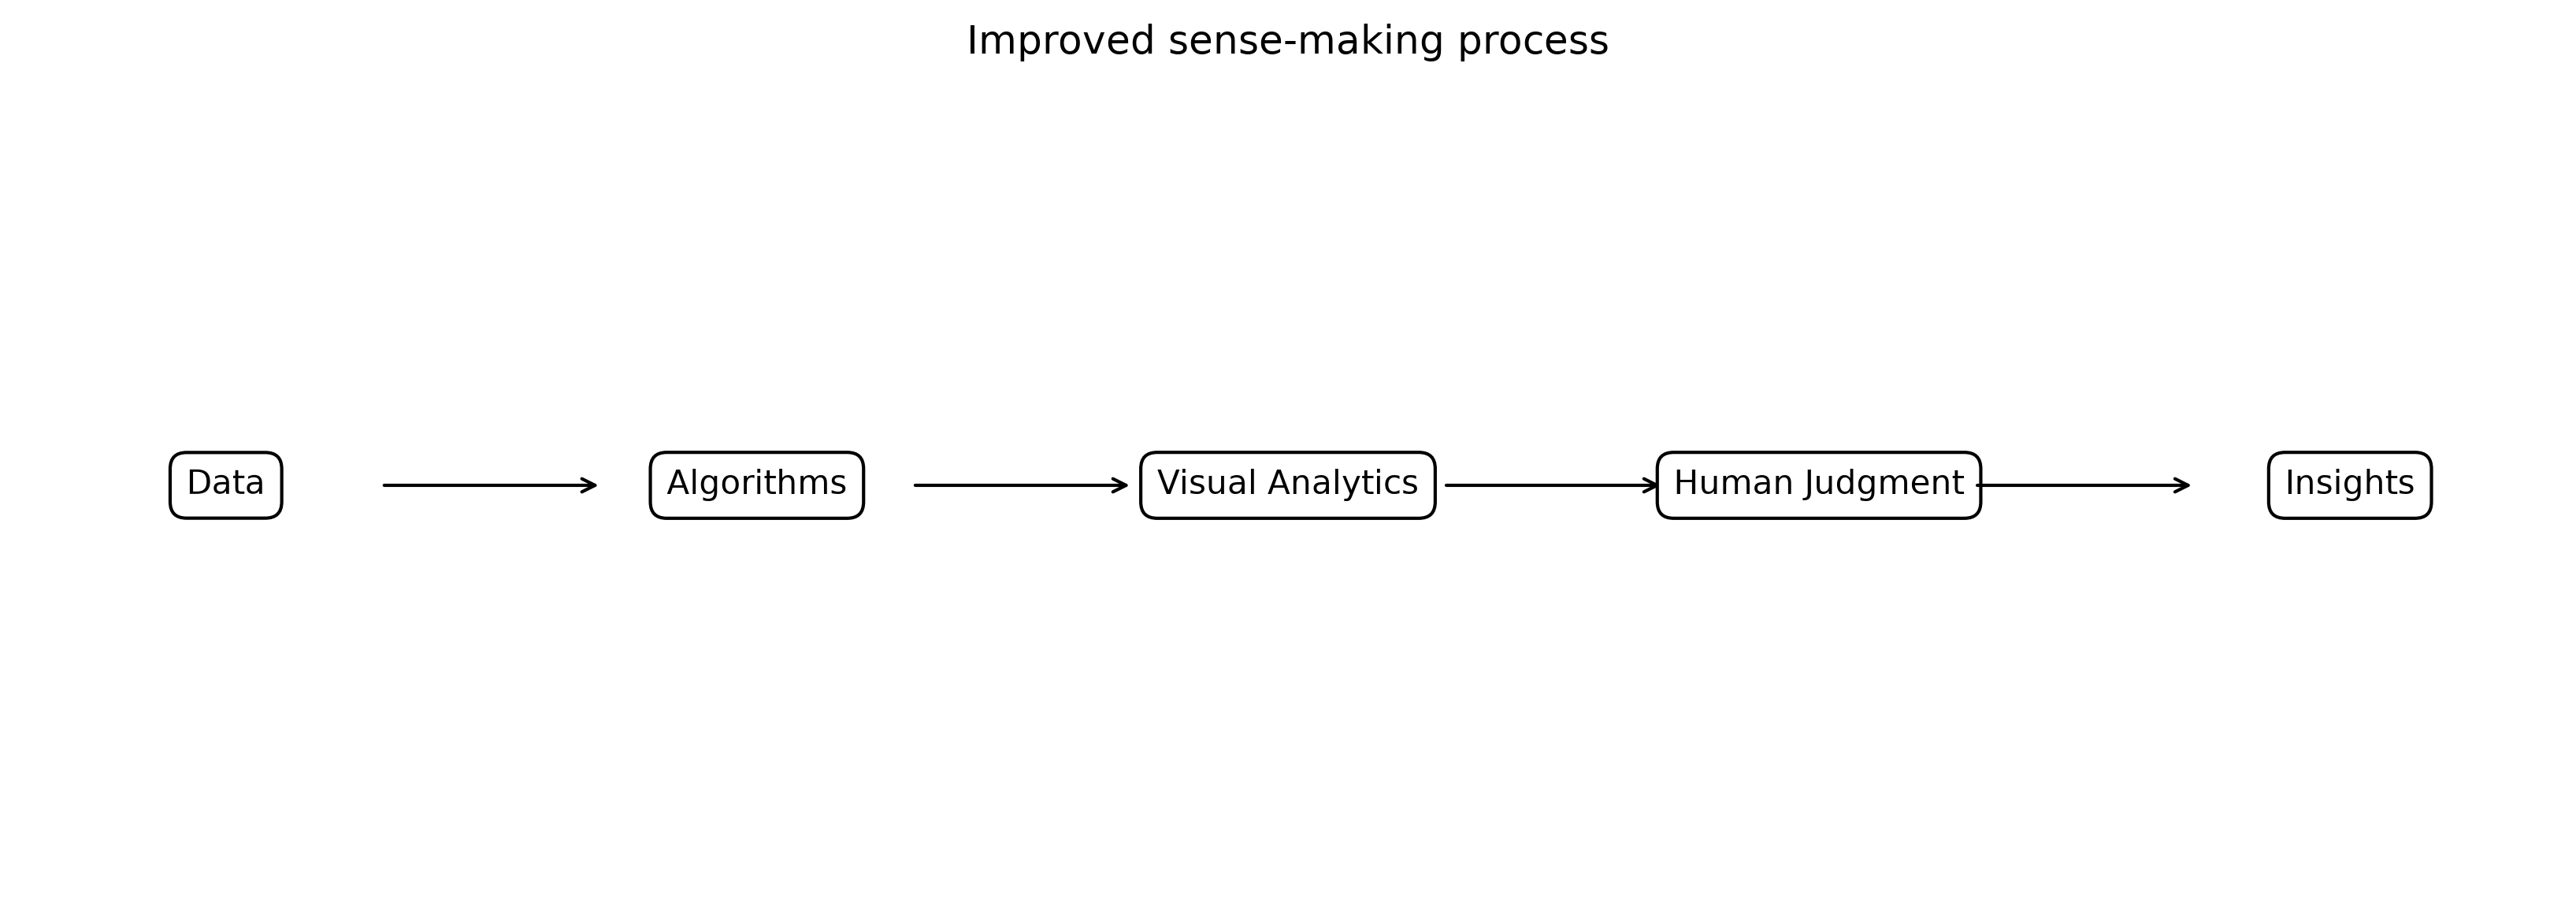


--- paper_02_poor.png (authored baseline) ---


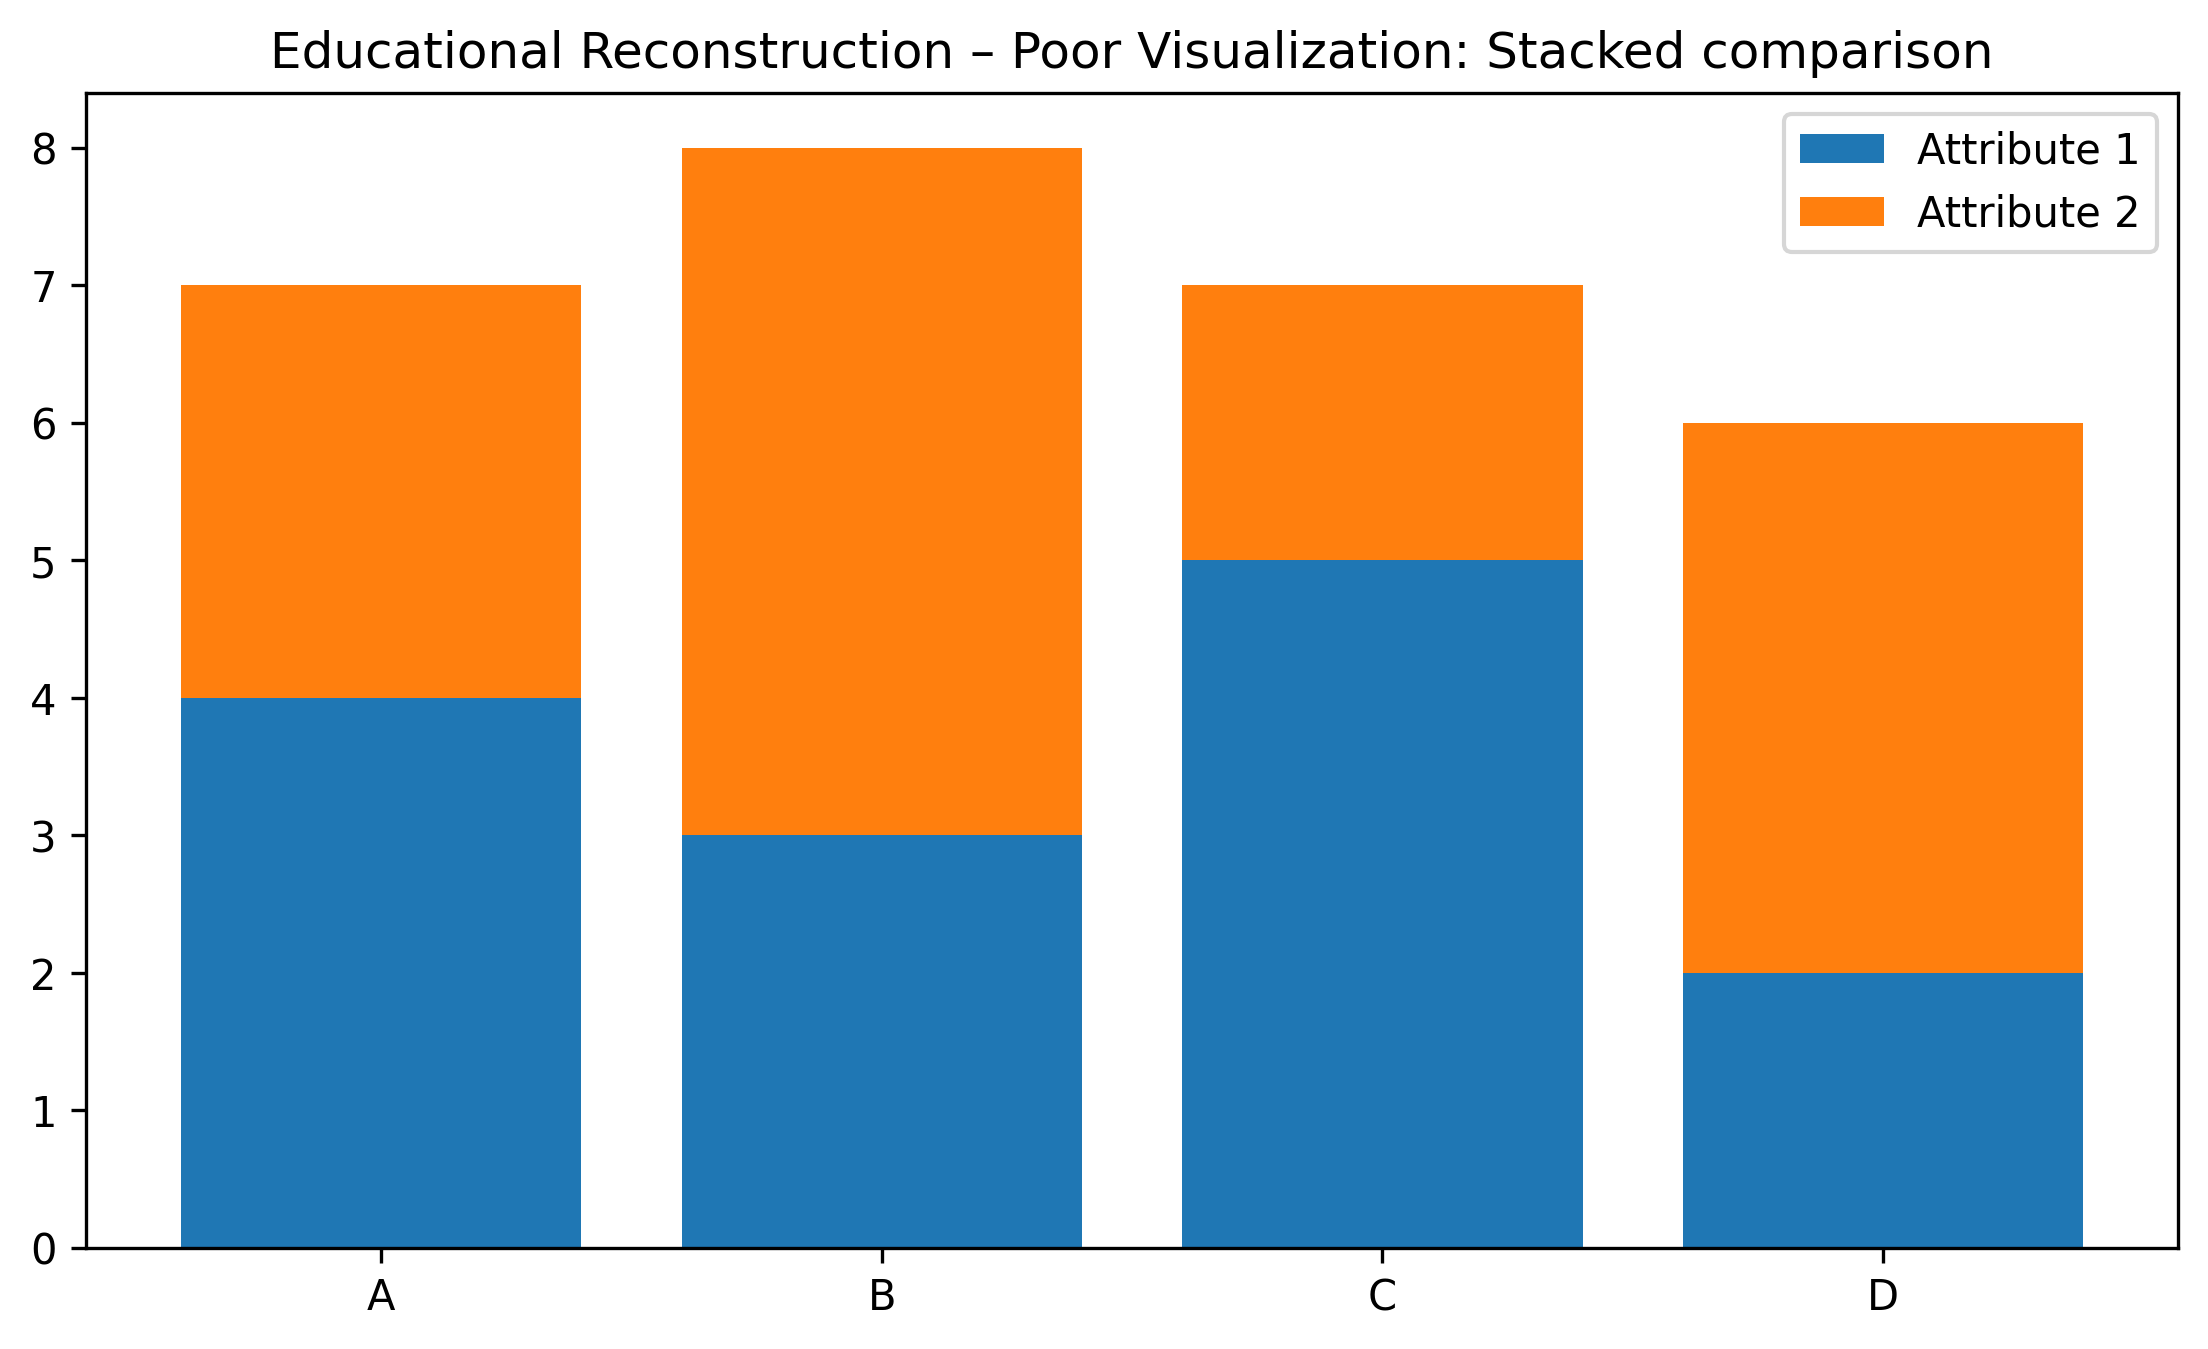

--- paper_02_improved.png (regenerated by this notebook) ---


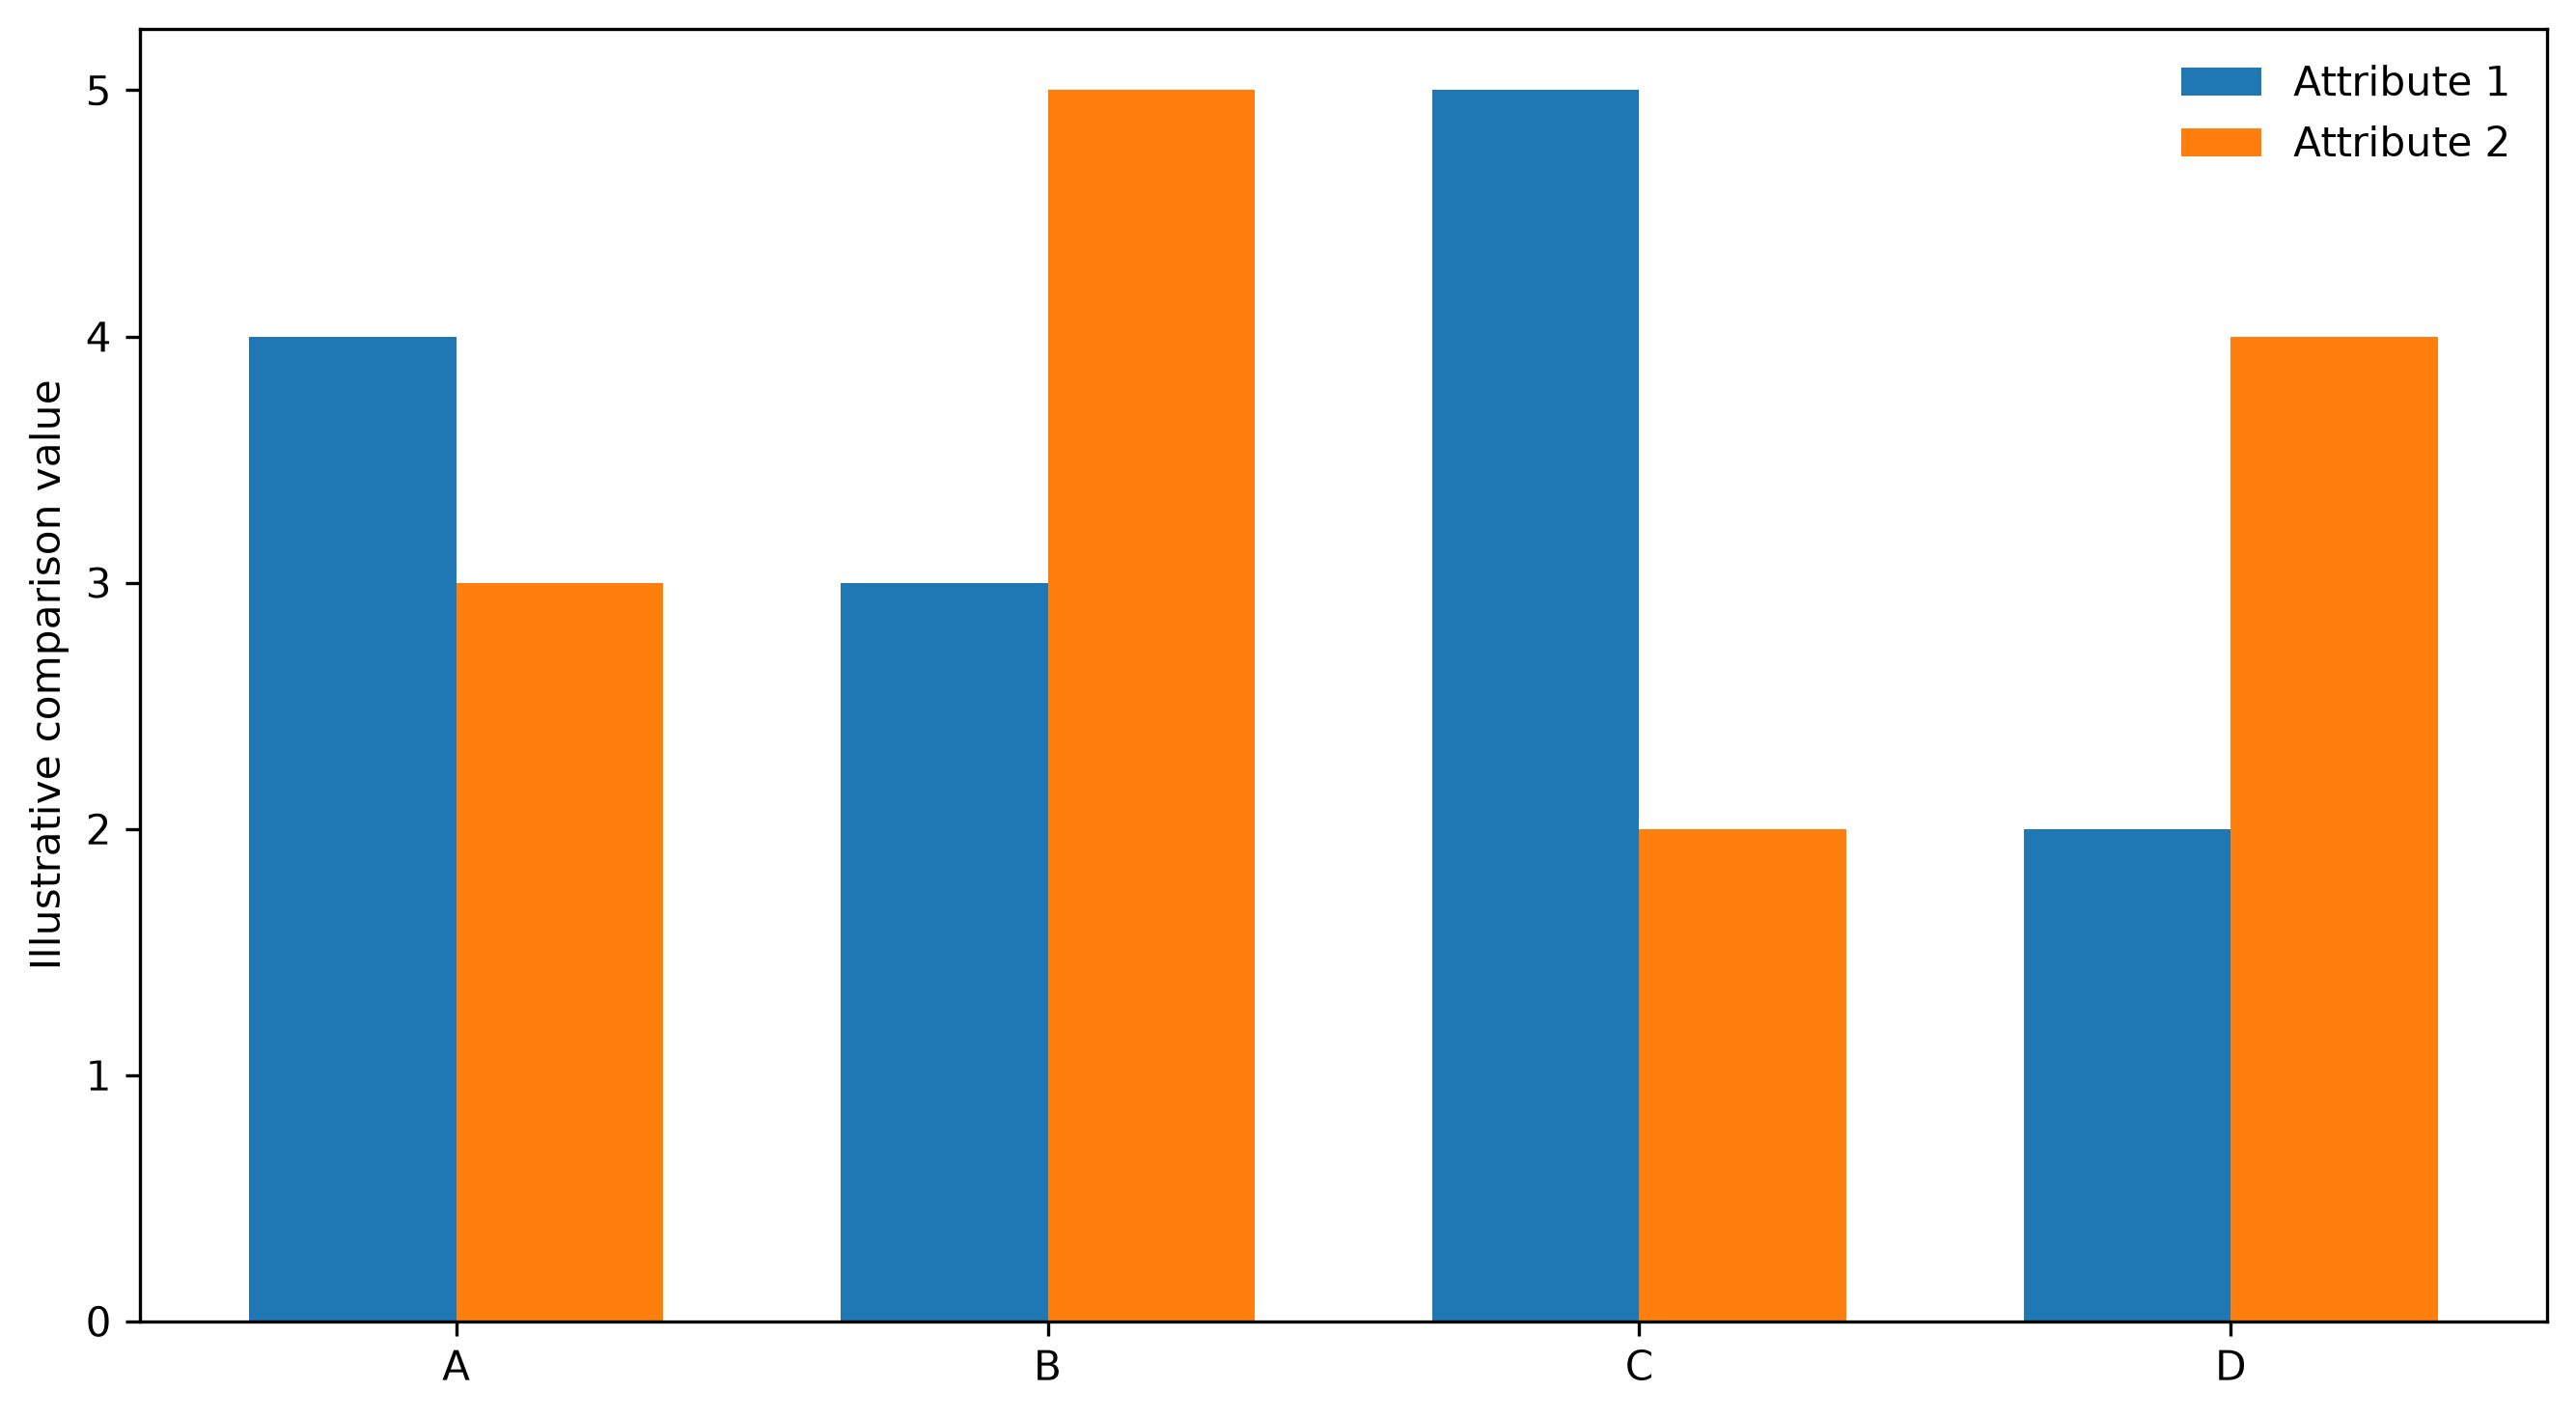


--- paper_03_poor.png (authored baseline) ---


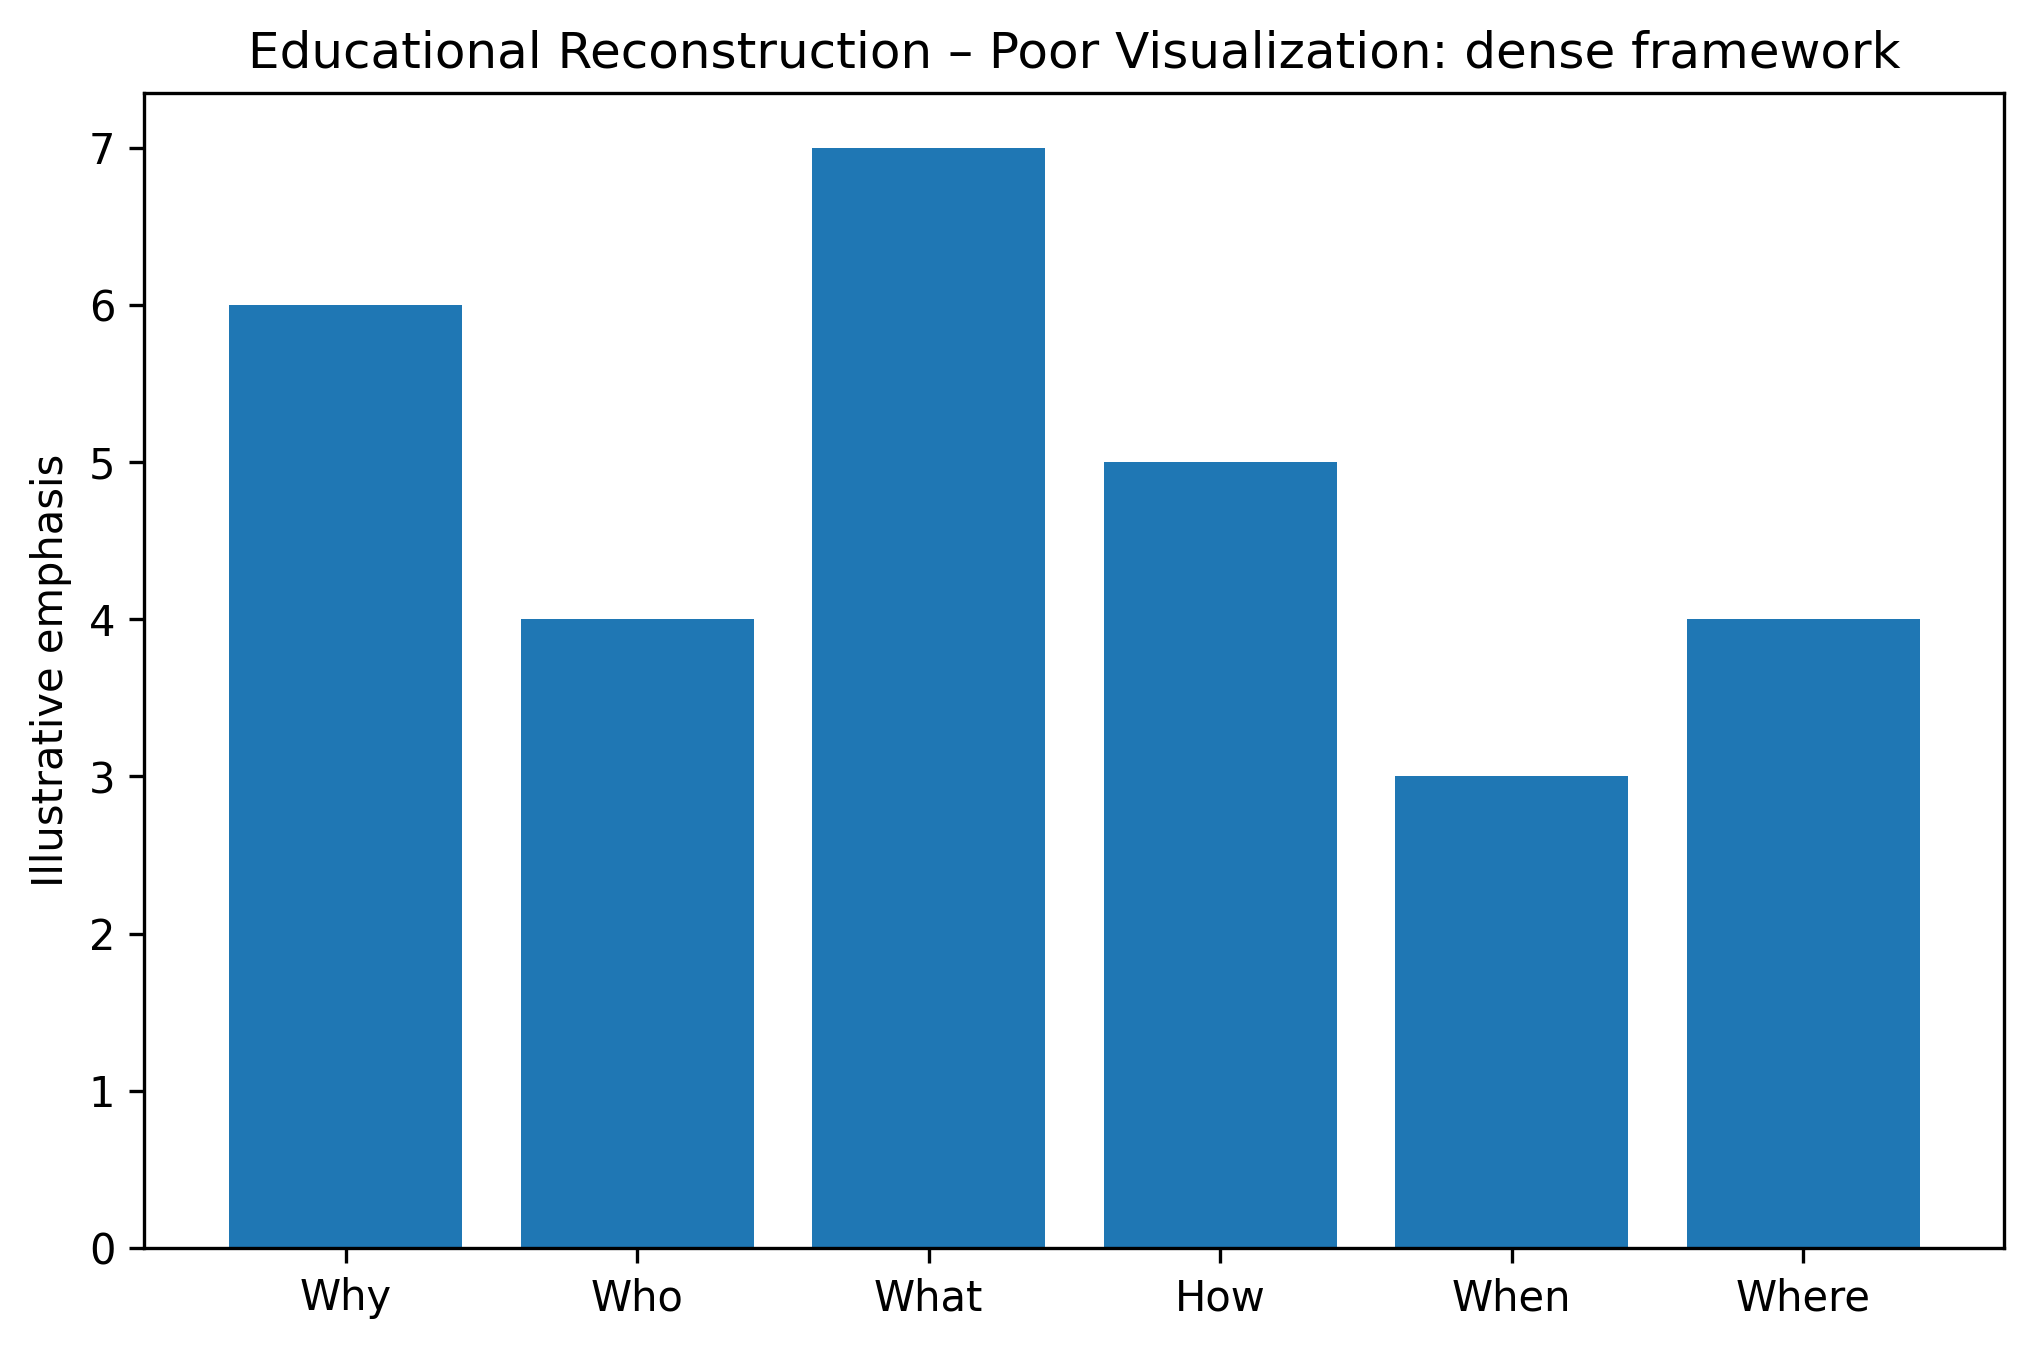

--- paper_03_improved.png (regenerated by this notebook) ---


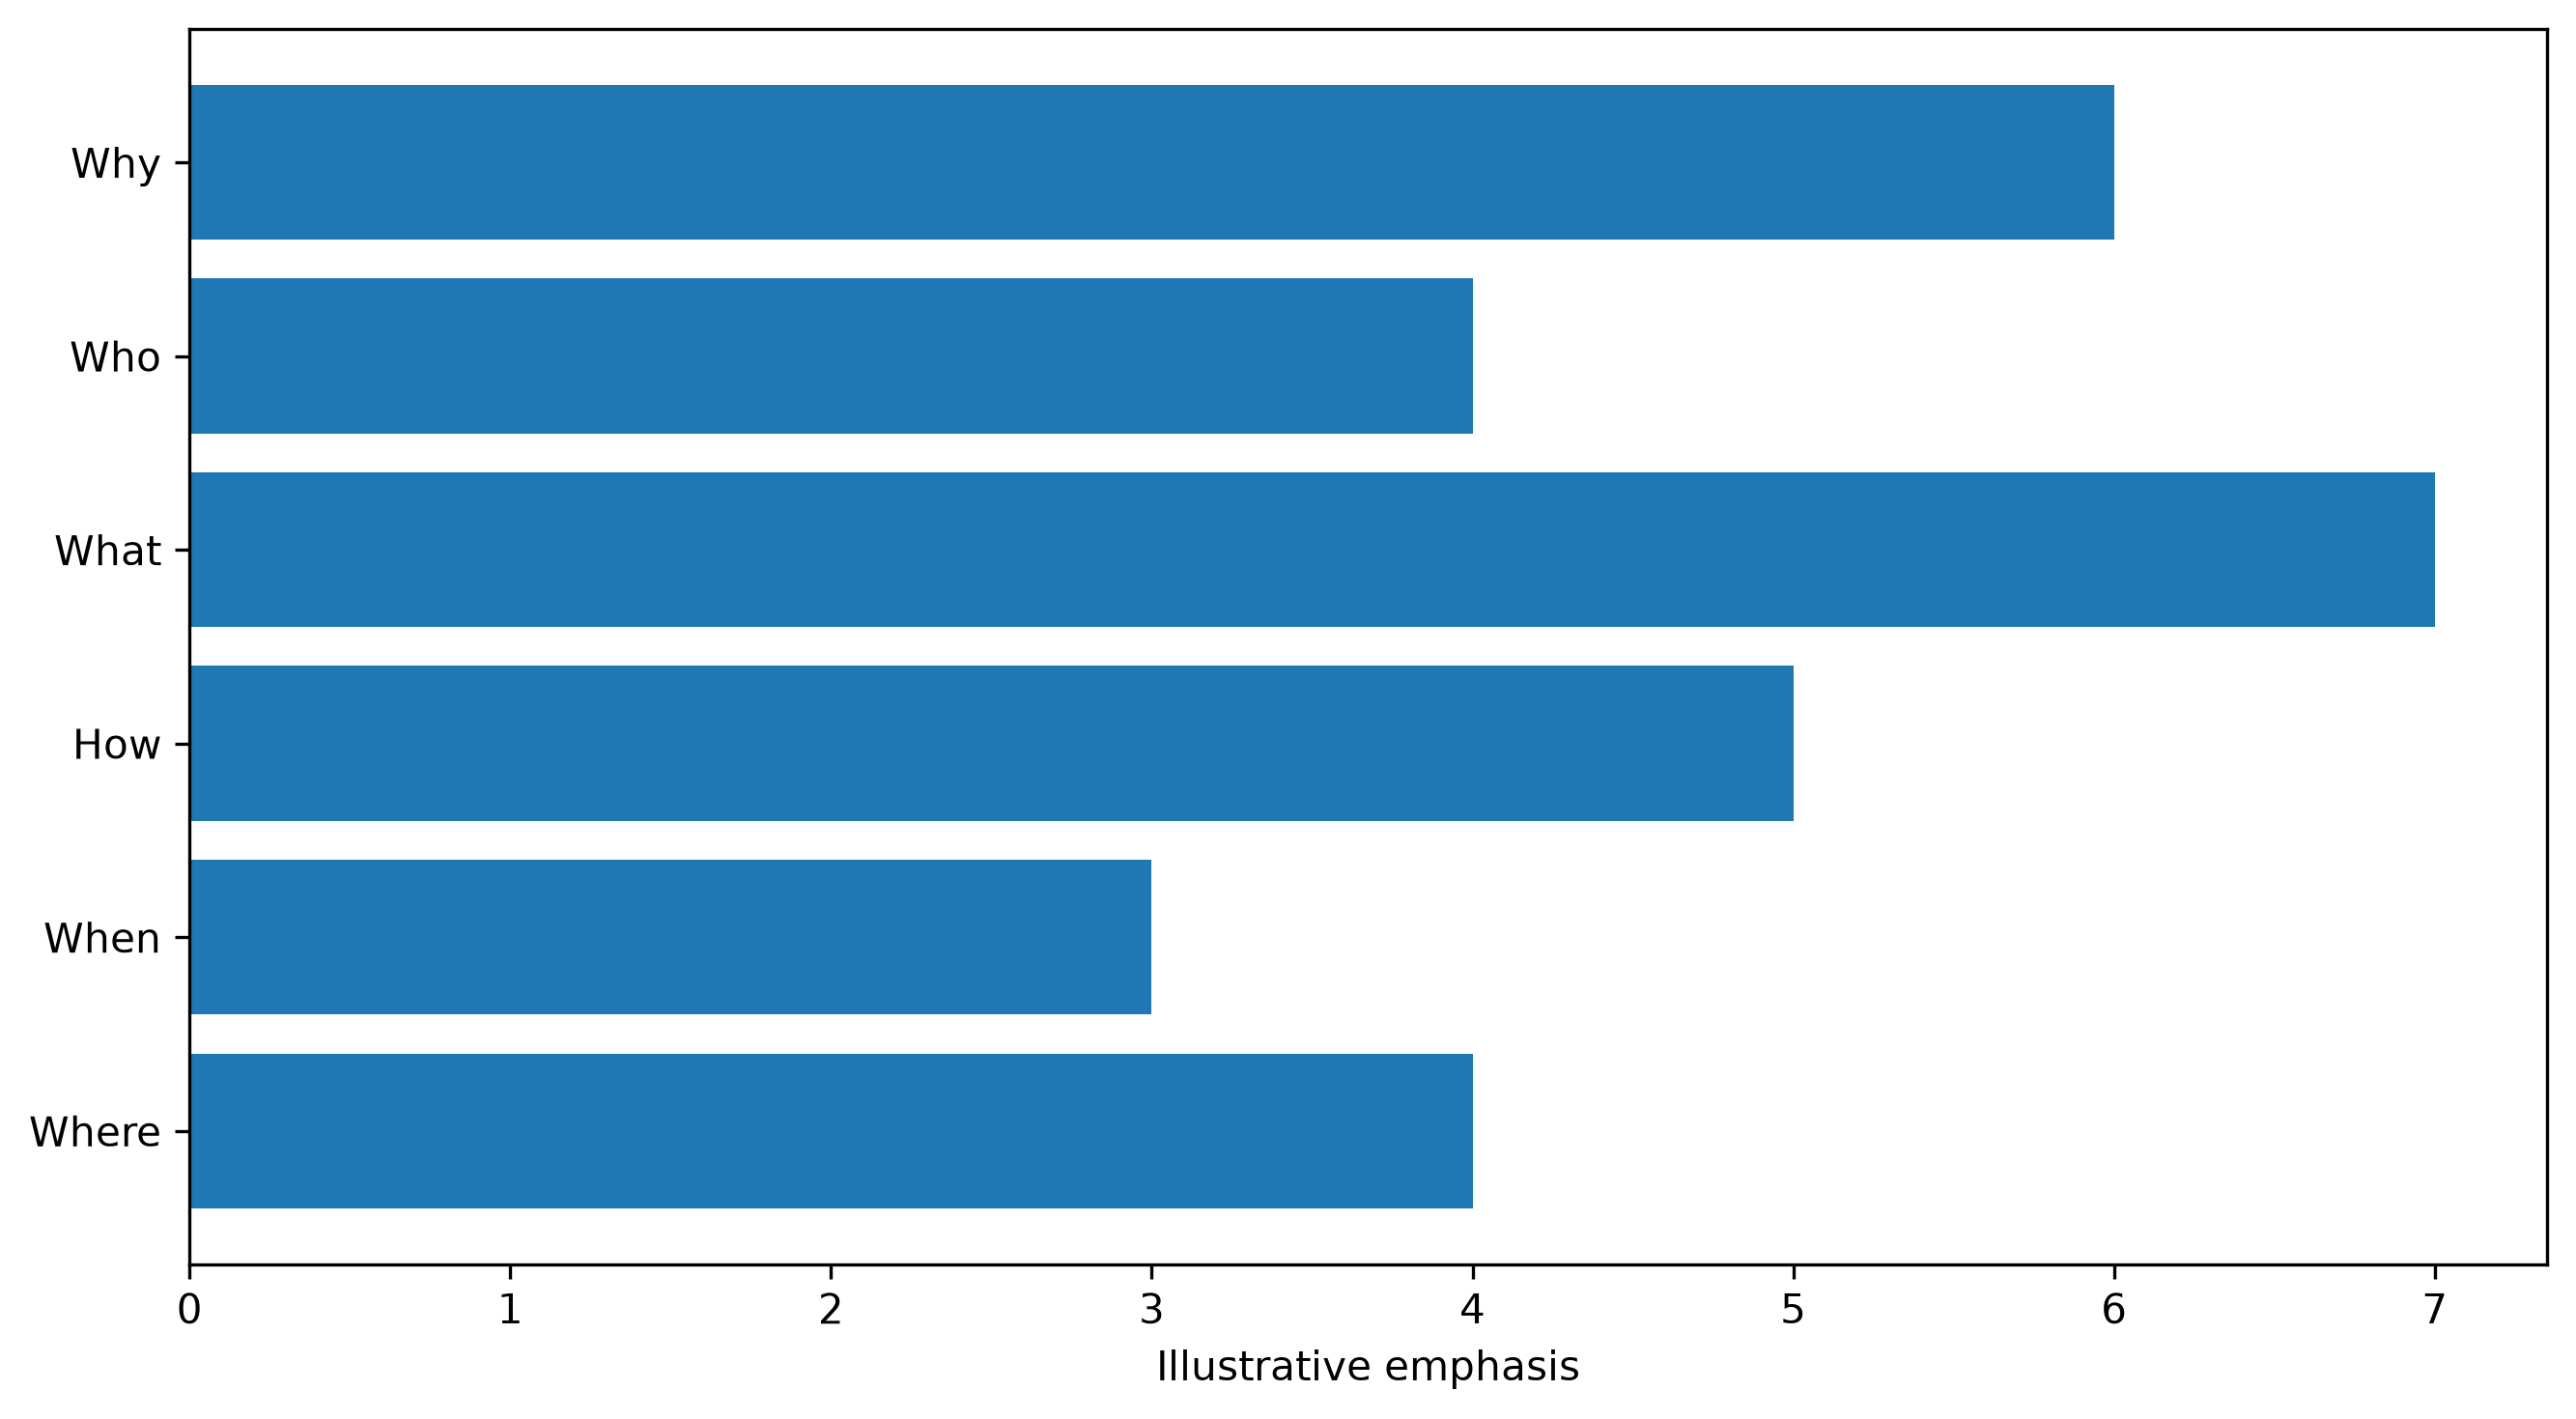


--- paper_04_poor.png (authored baseline) ---


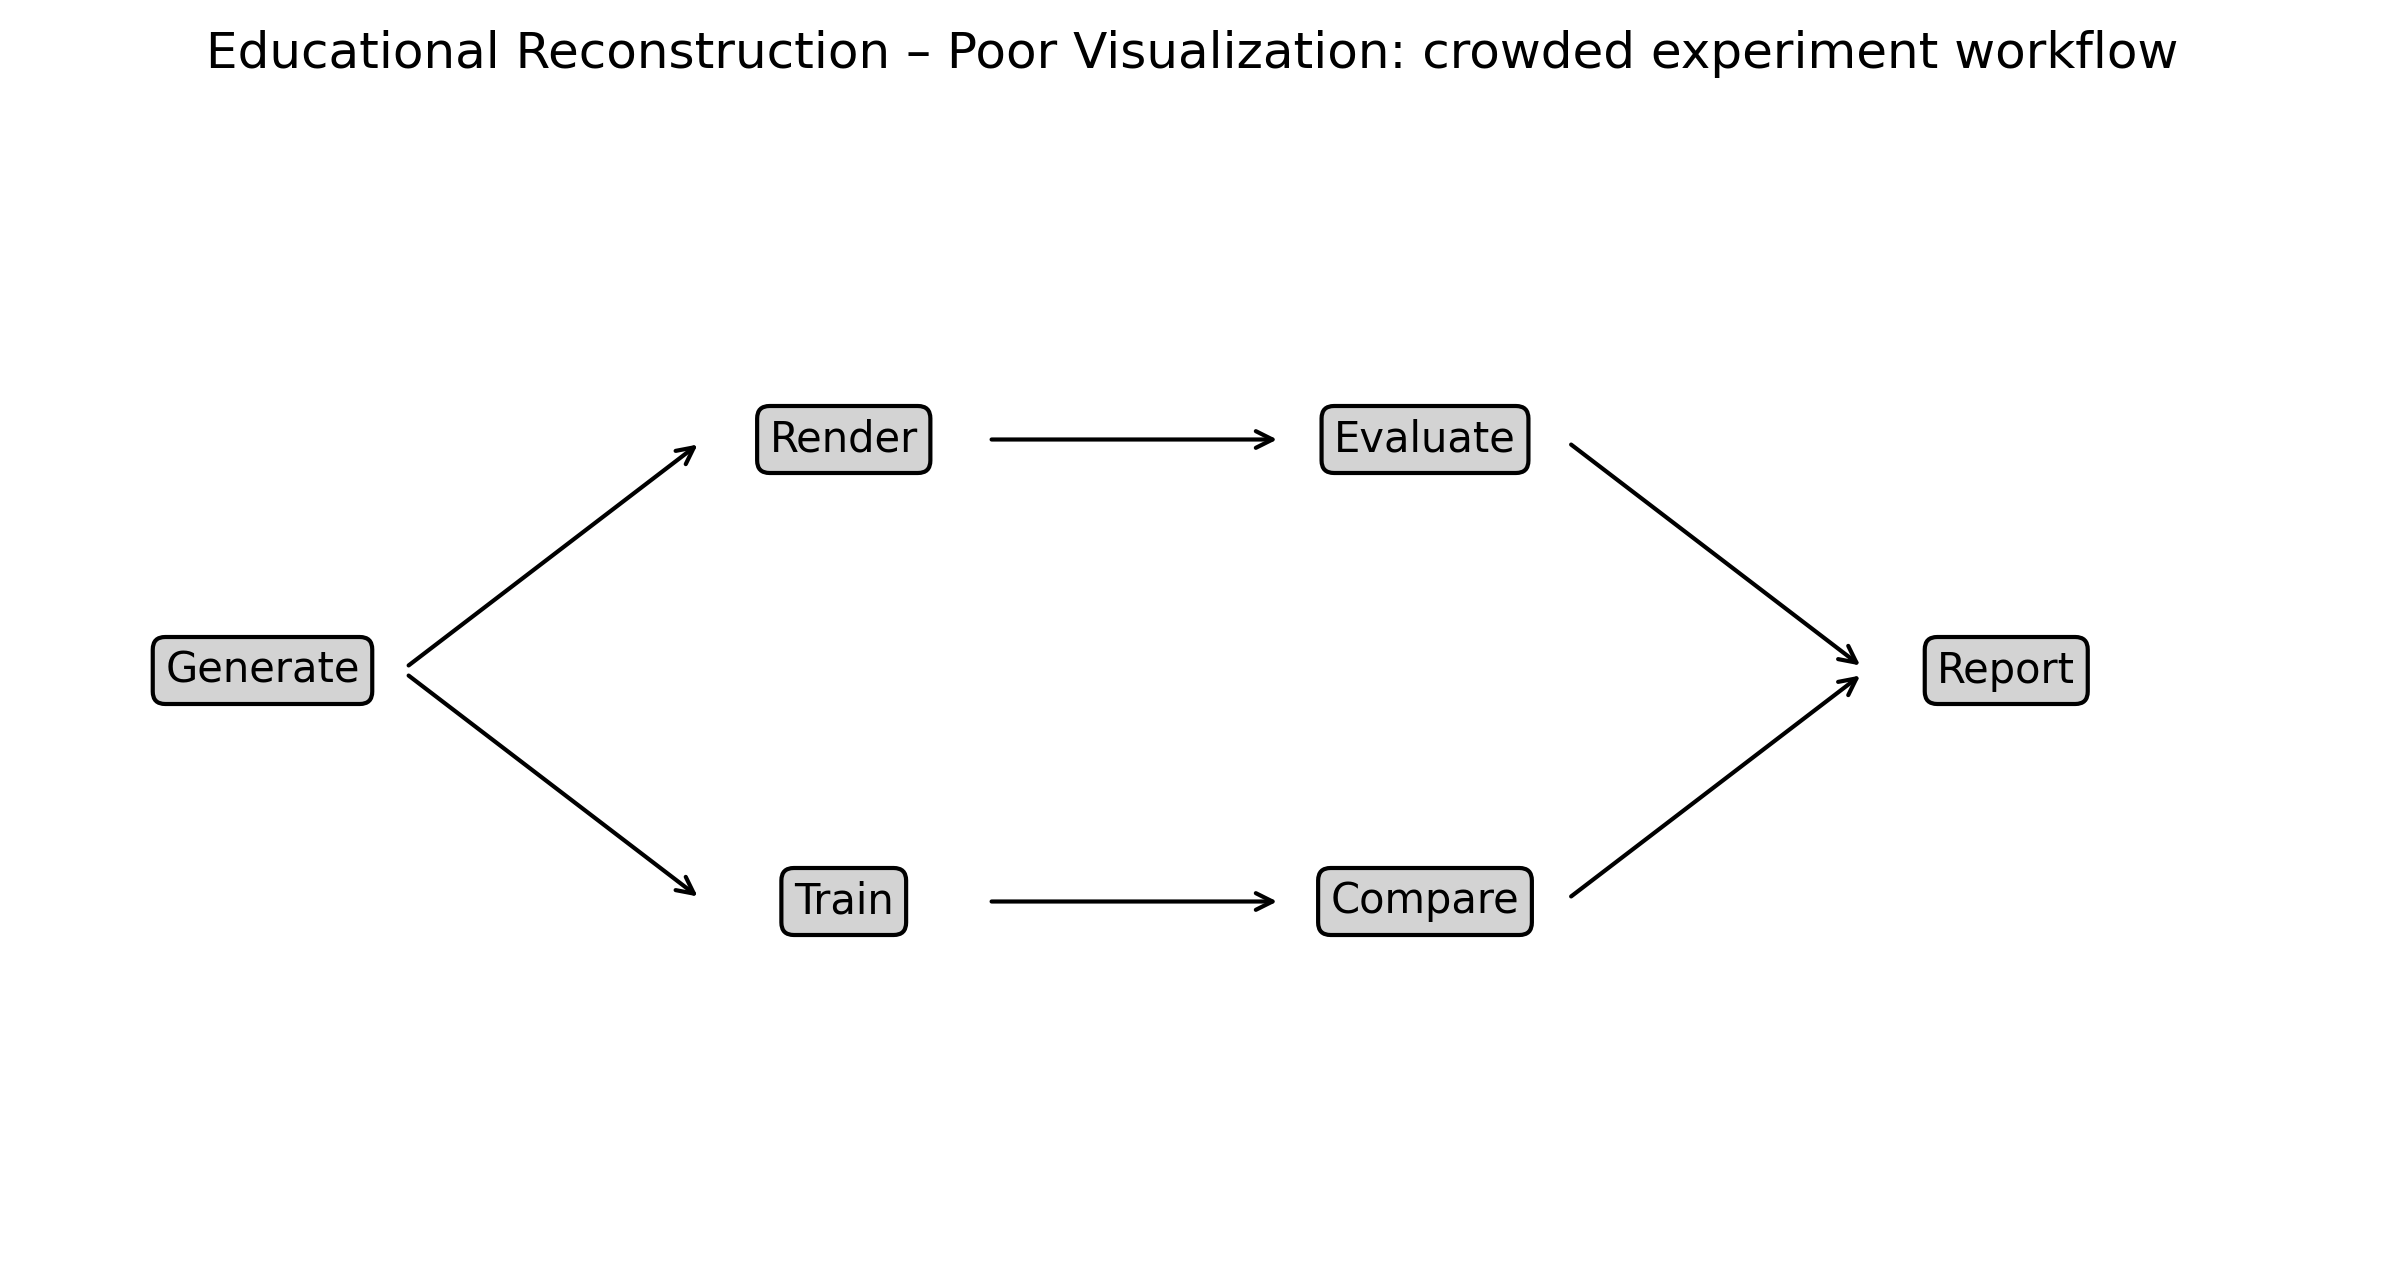

--- paper_04_improved.png (regenerated by this notebook) ---


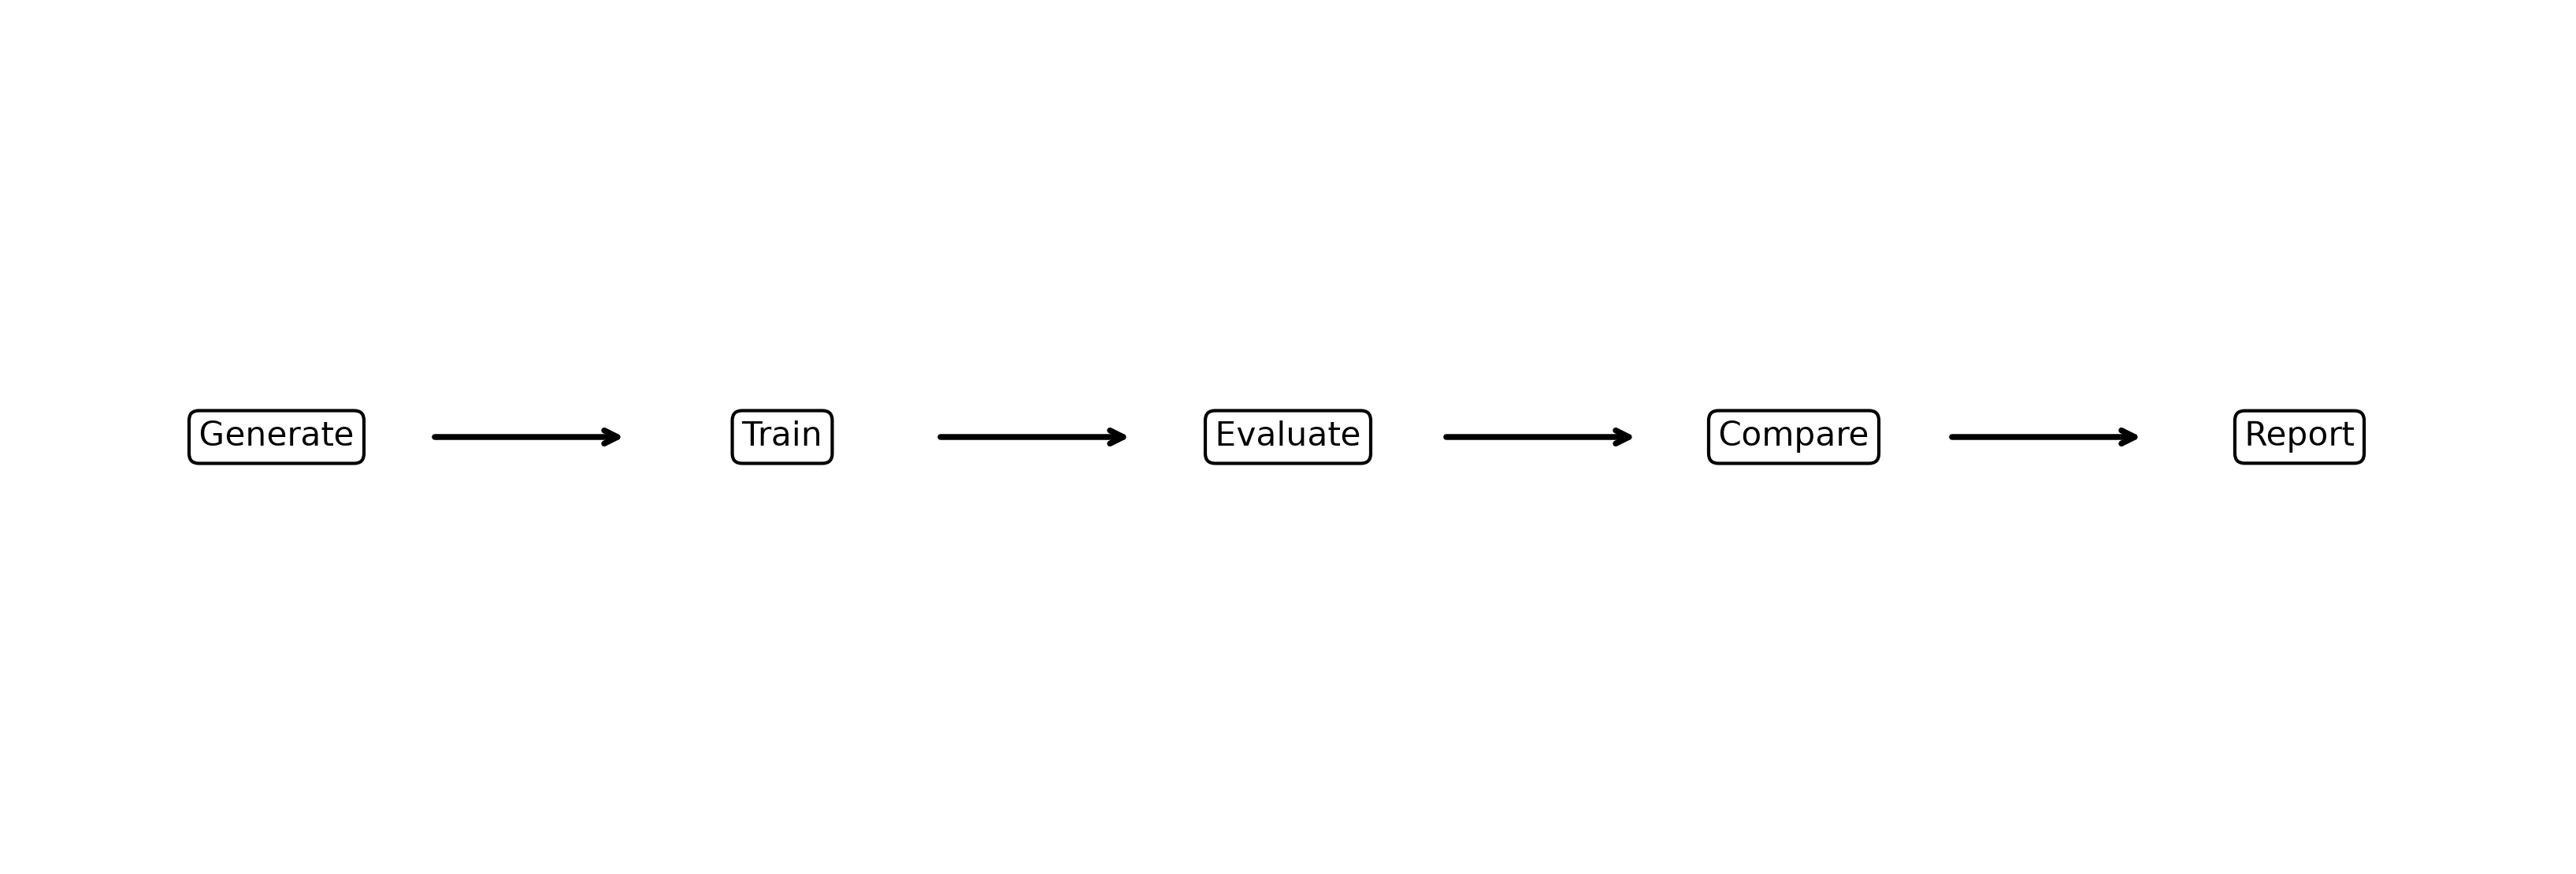


--- paper_05_poor.png (authored baseline) ---


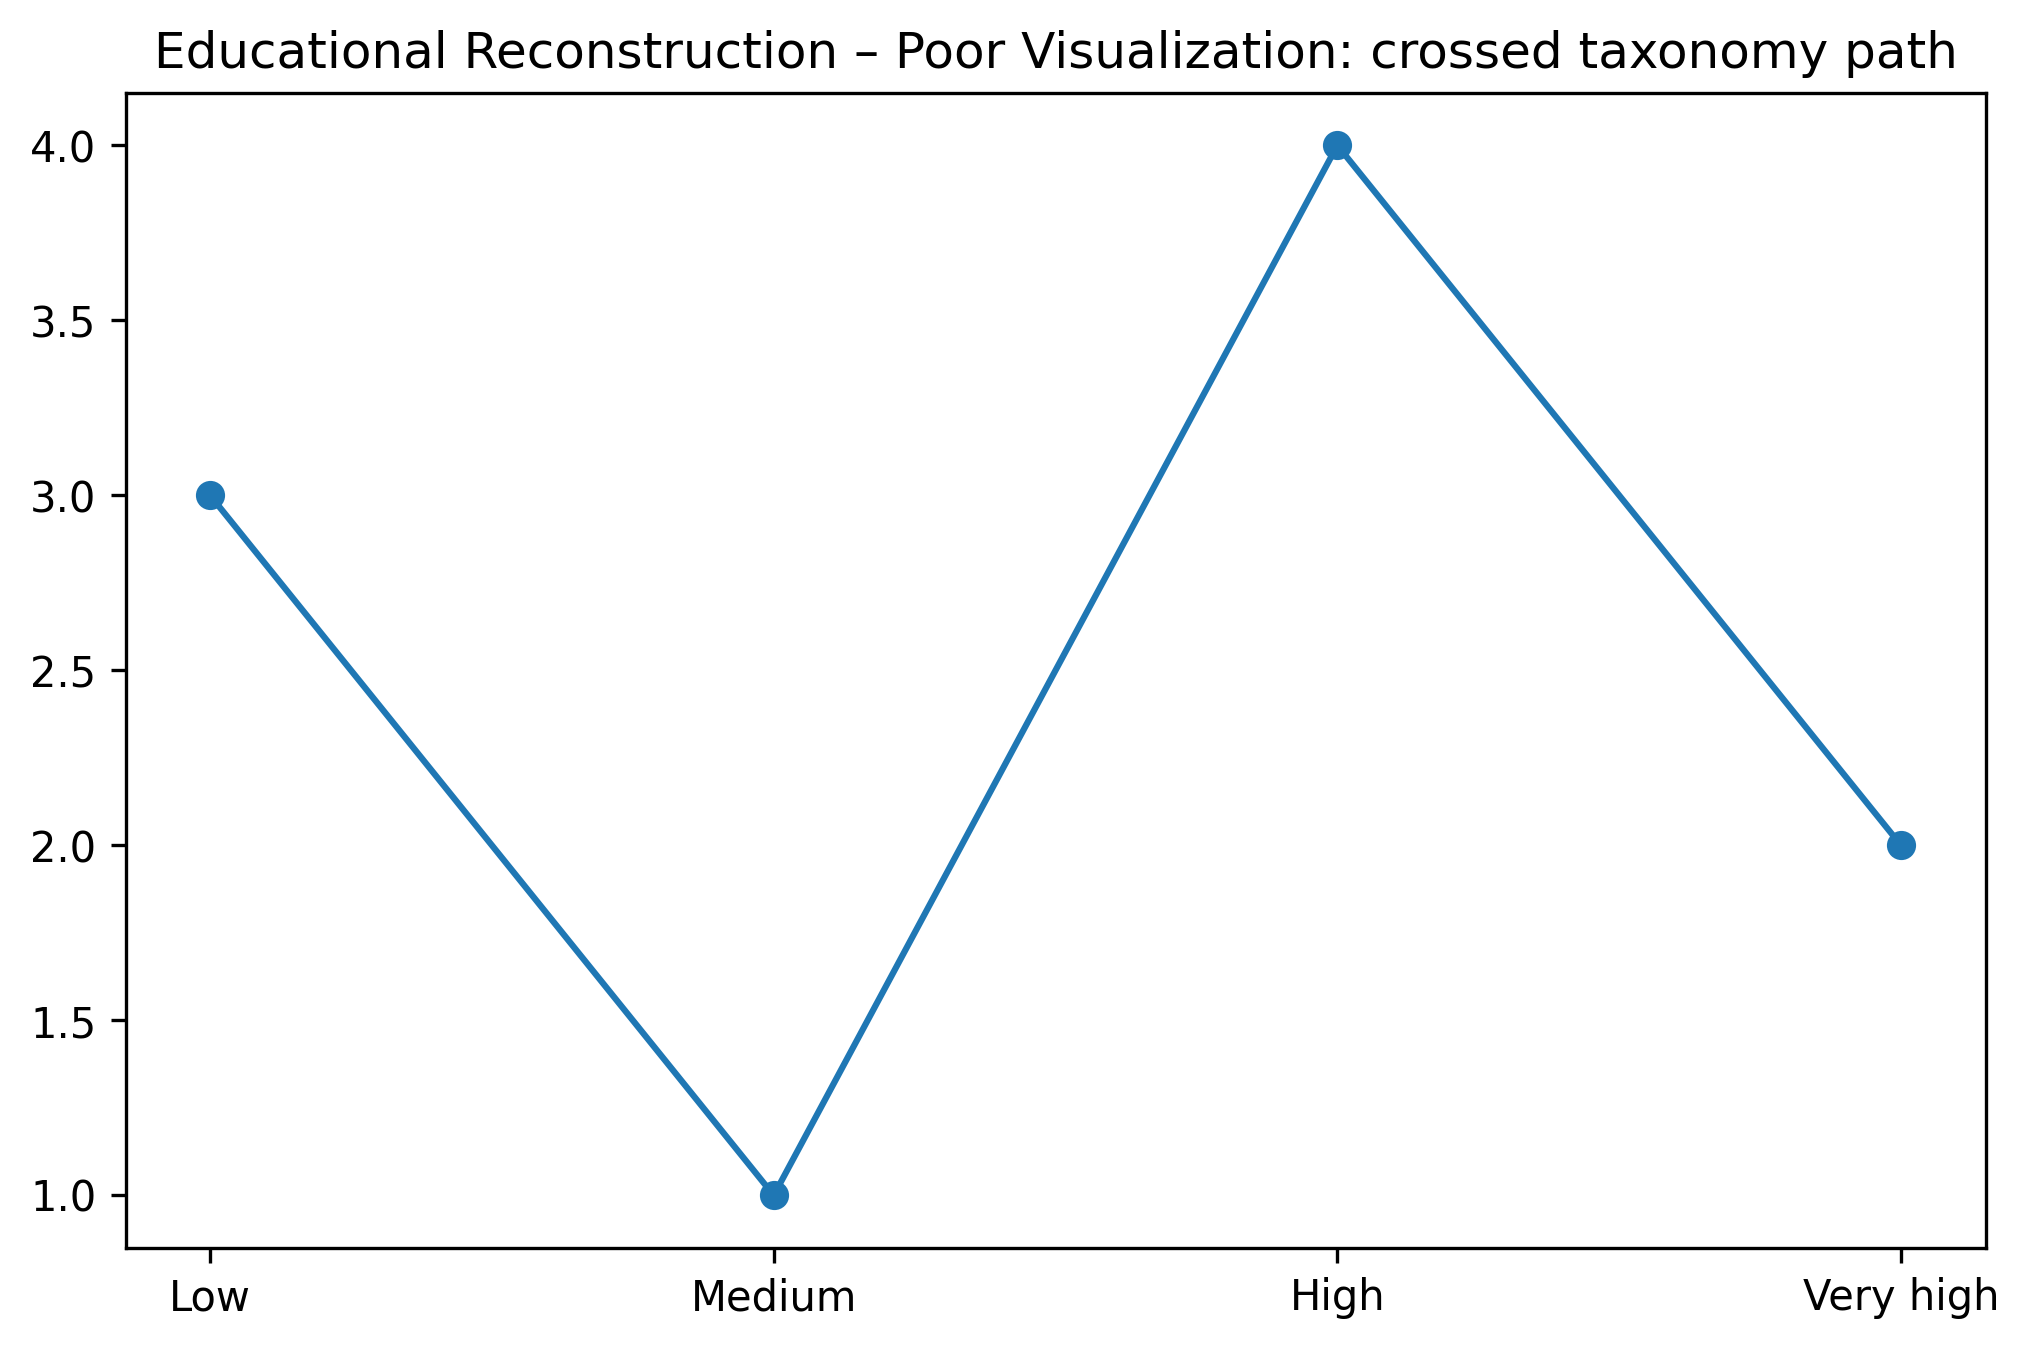

--- paper_05_improved.png (regenerated by this notebook) ---


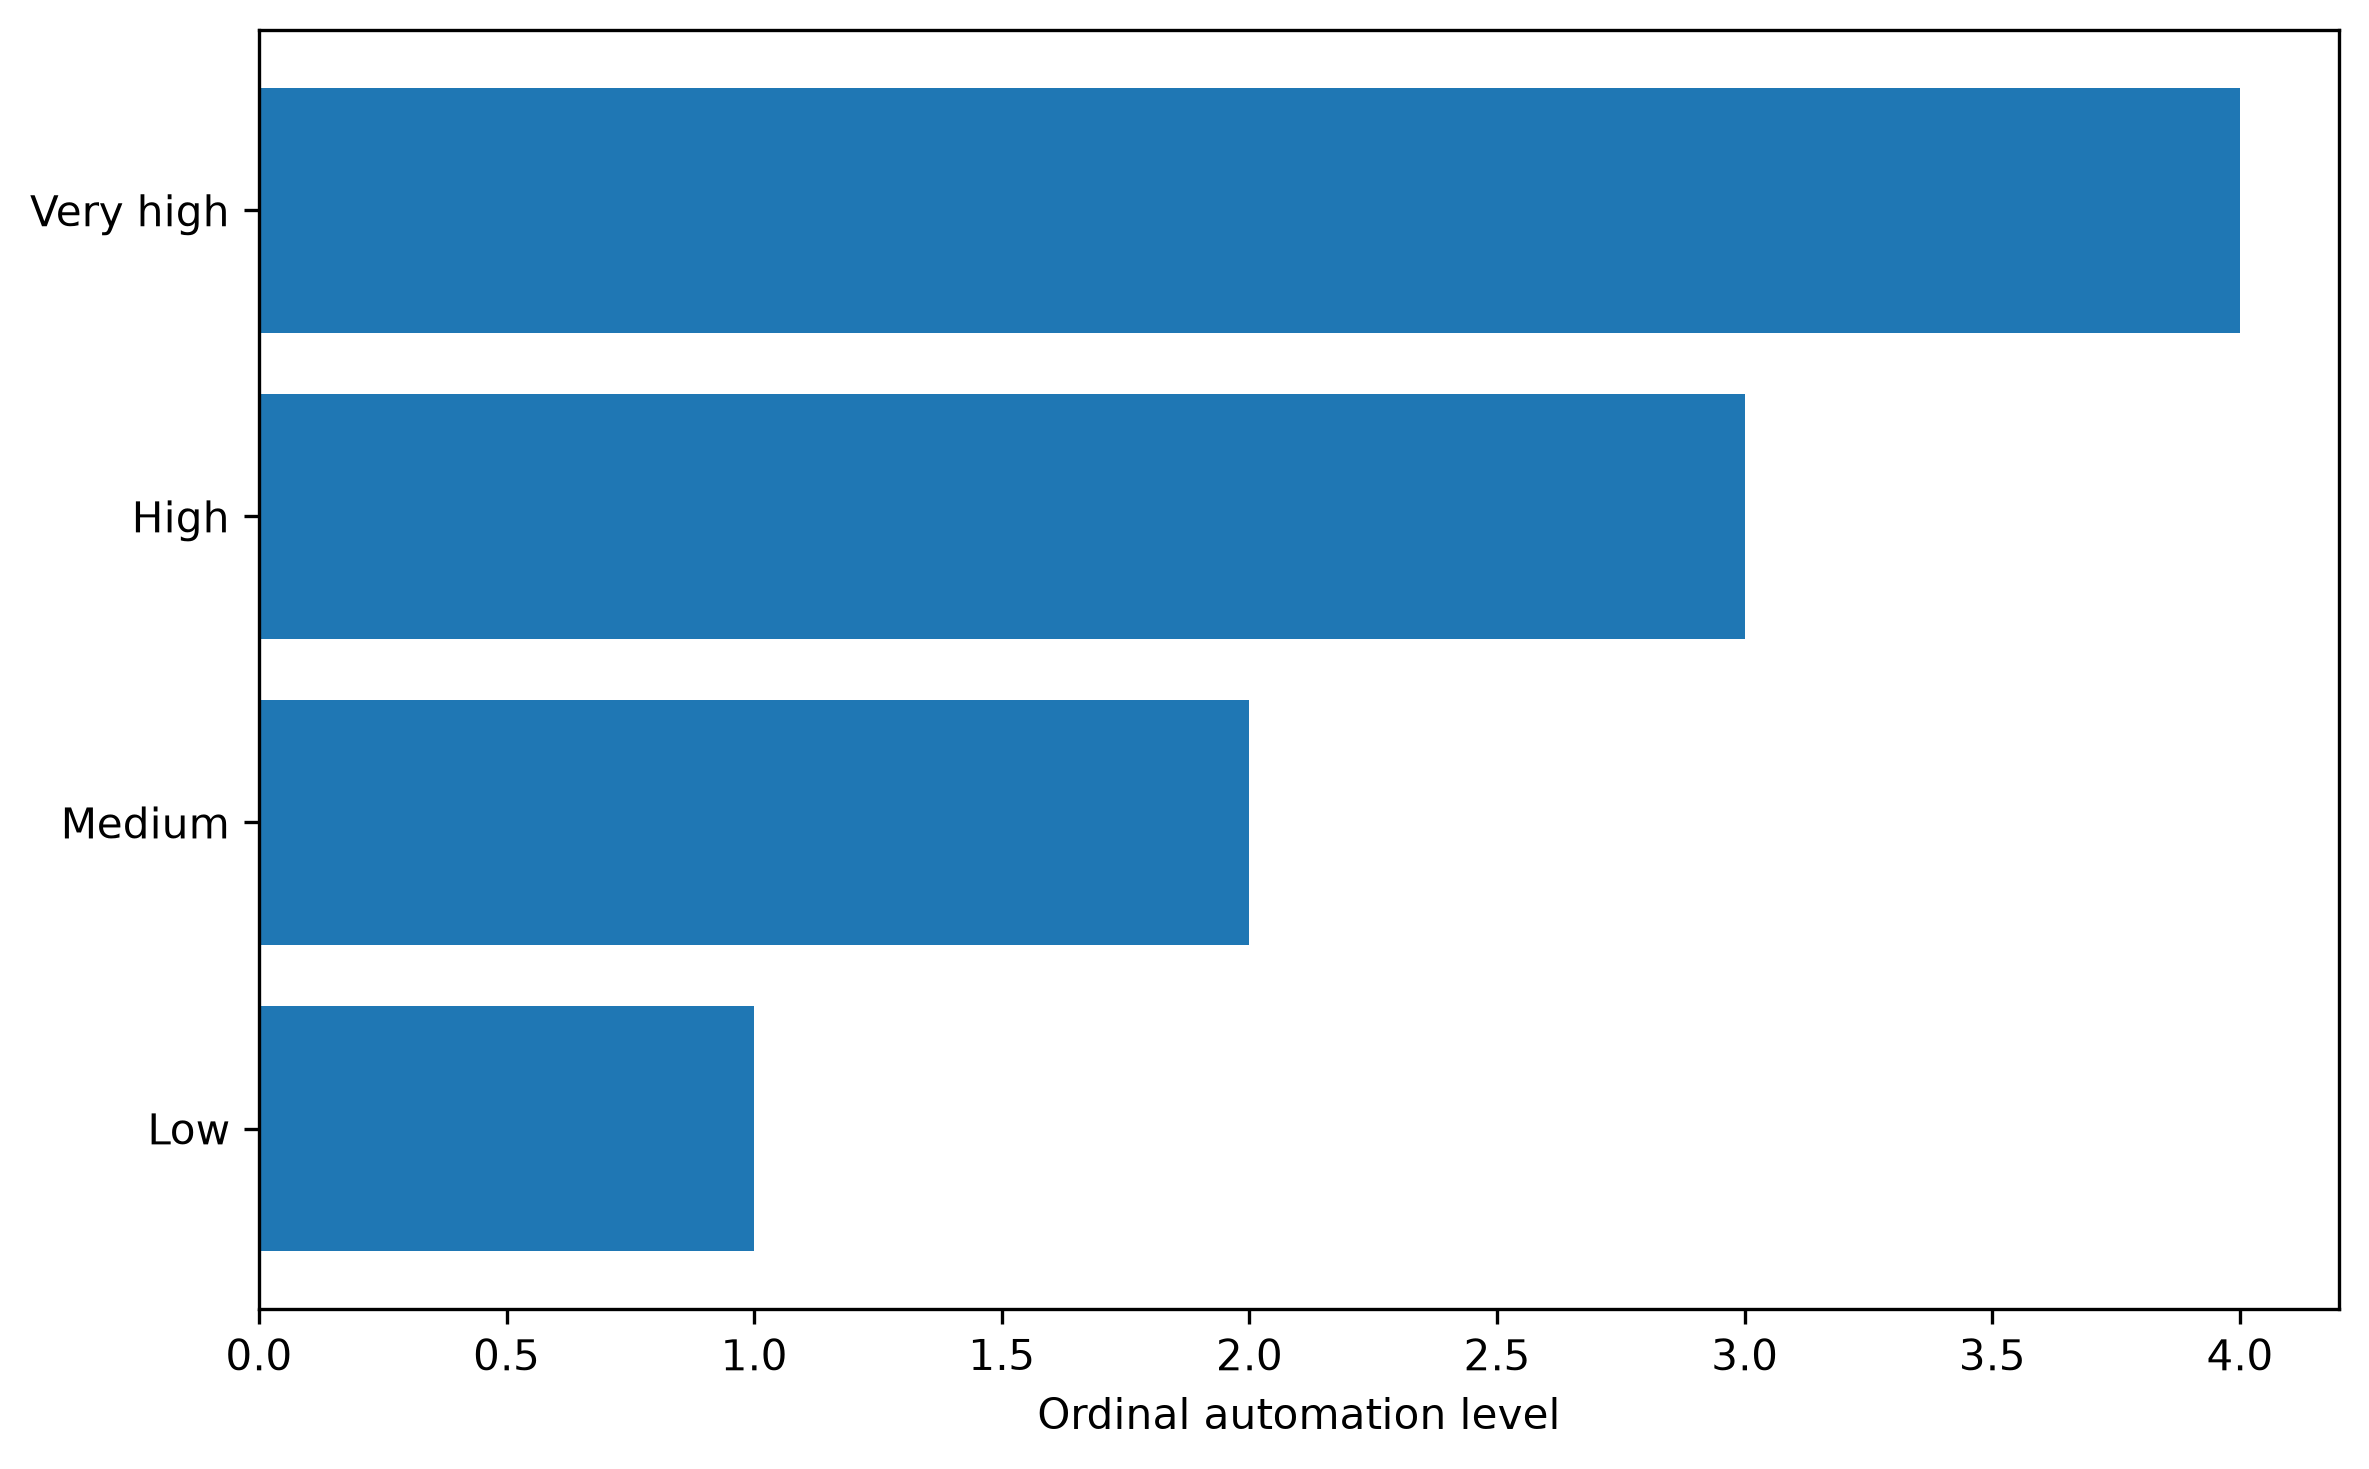


--- paper_06_poor.png (authored baseline) ---


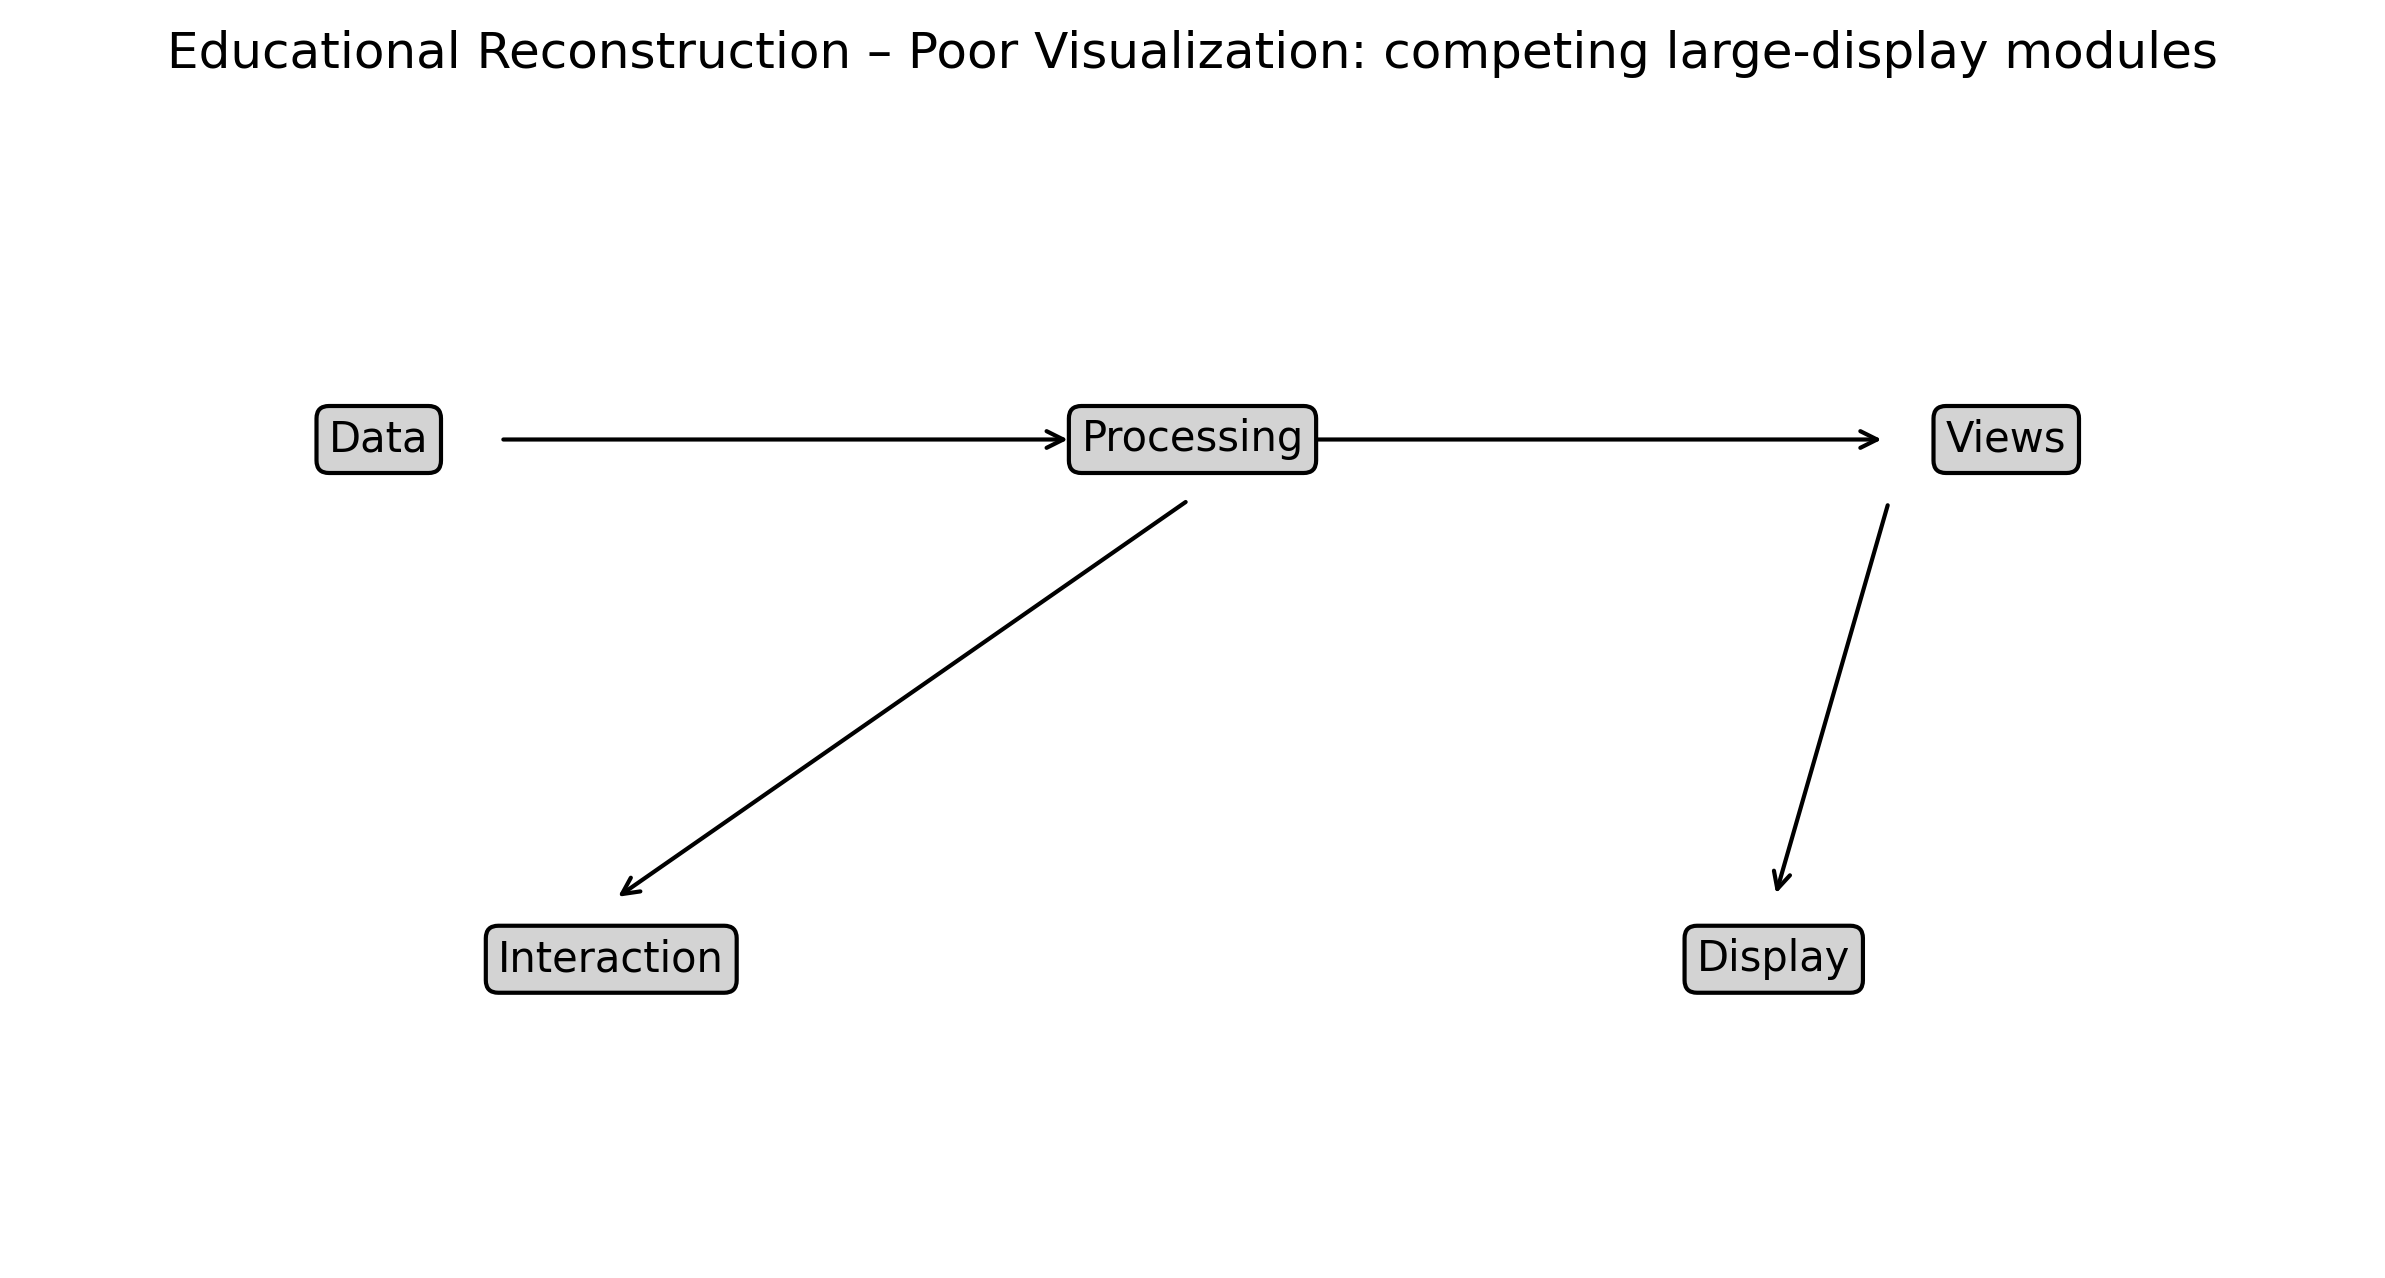

--- paper_06_improved.png (regenerated by this notebook) ---


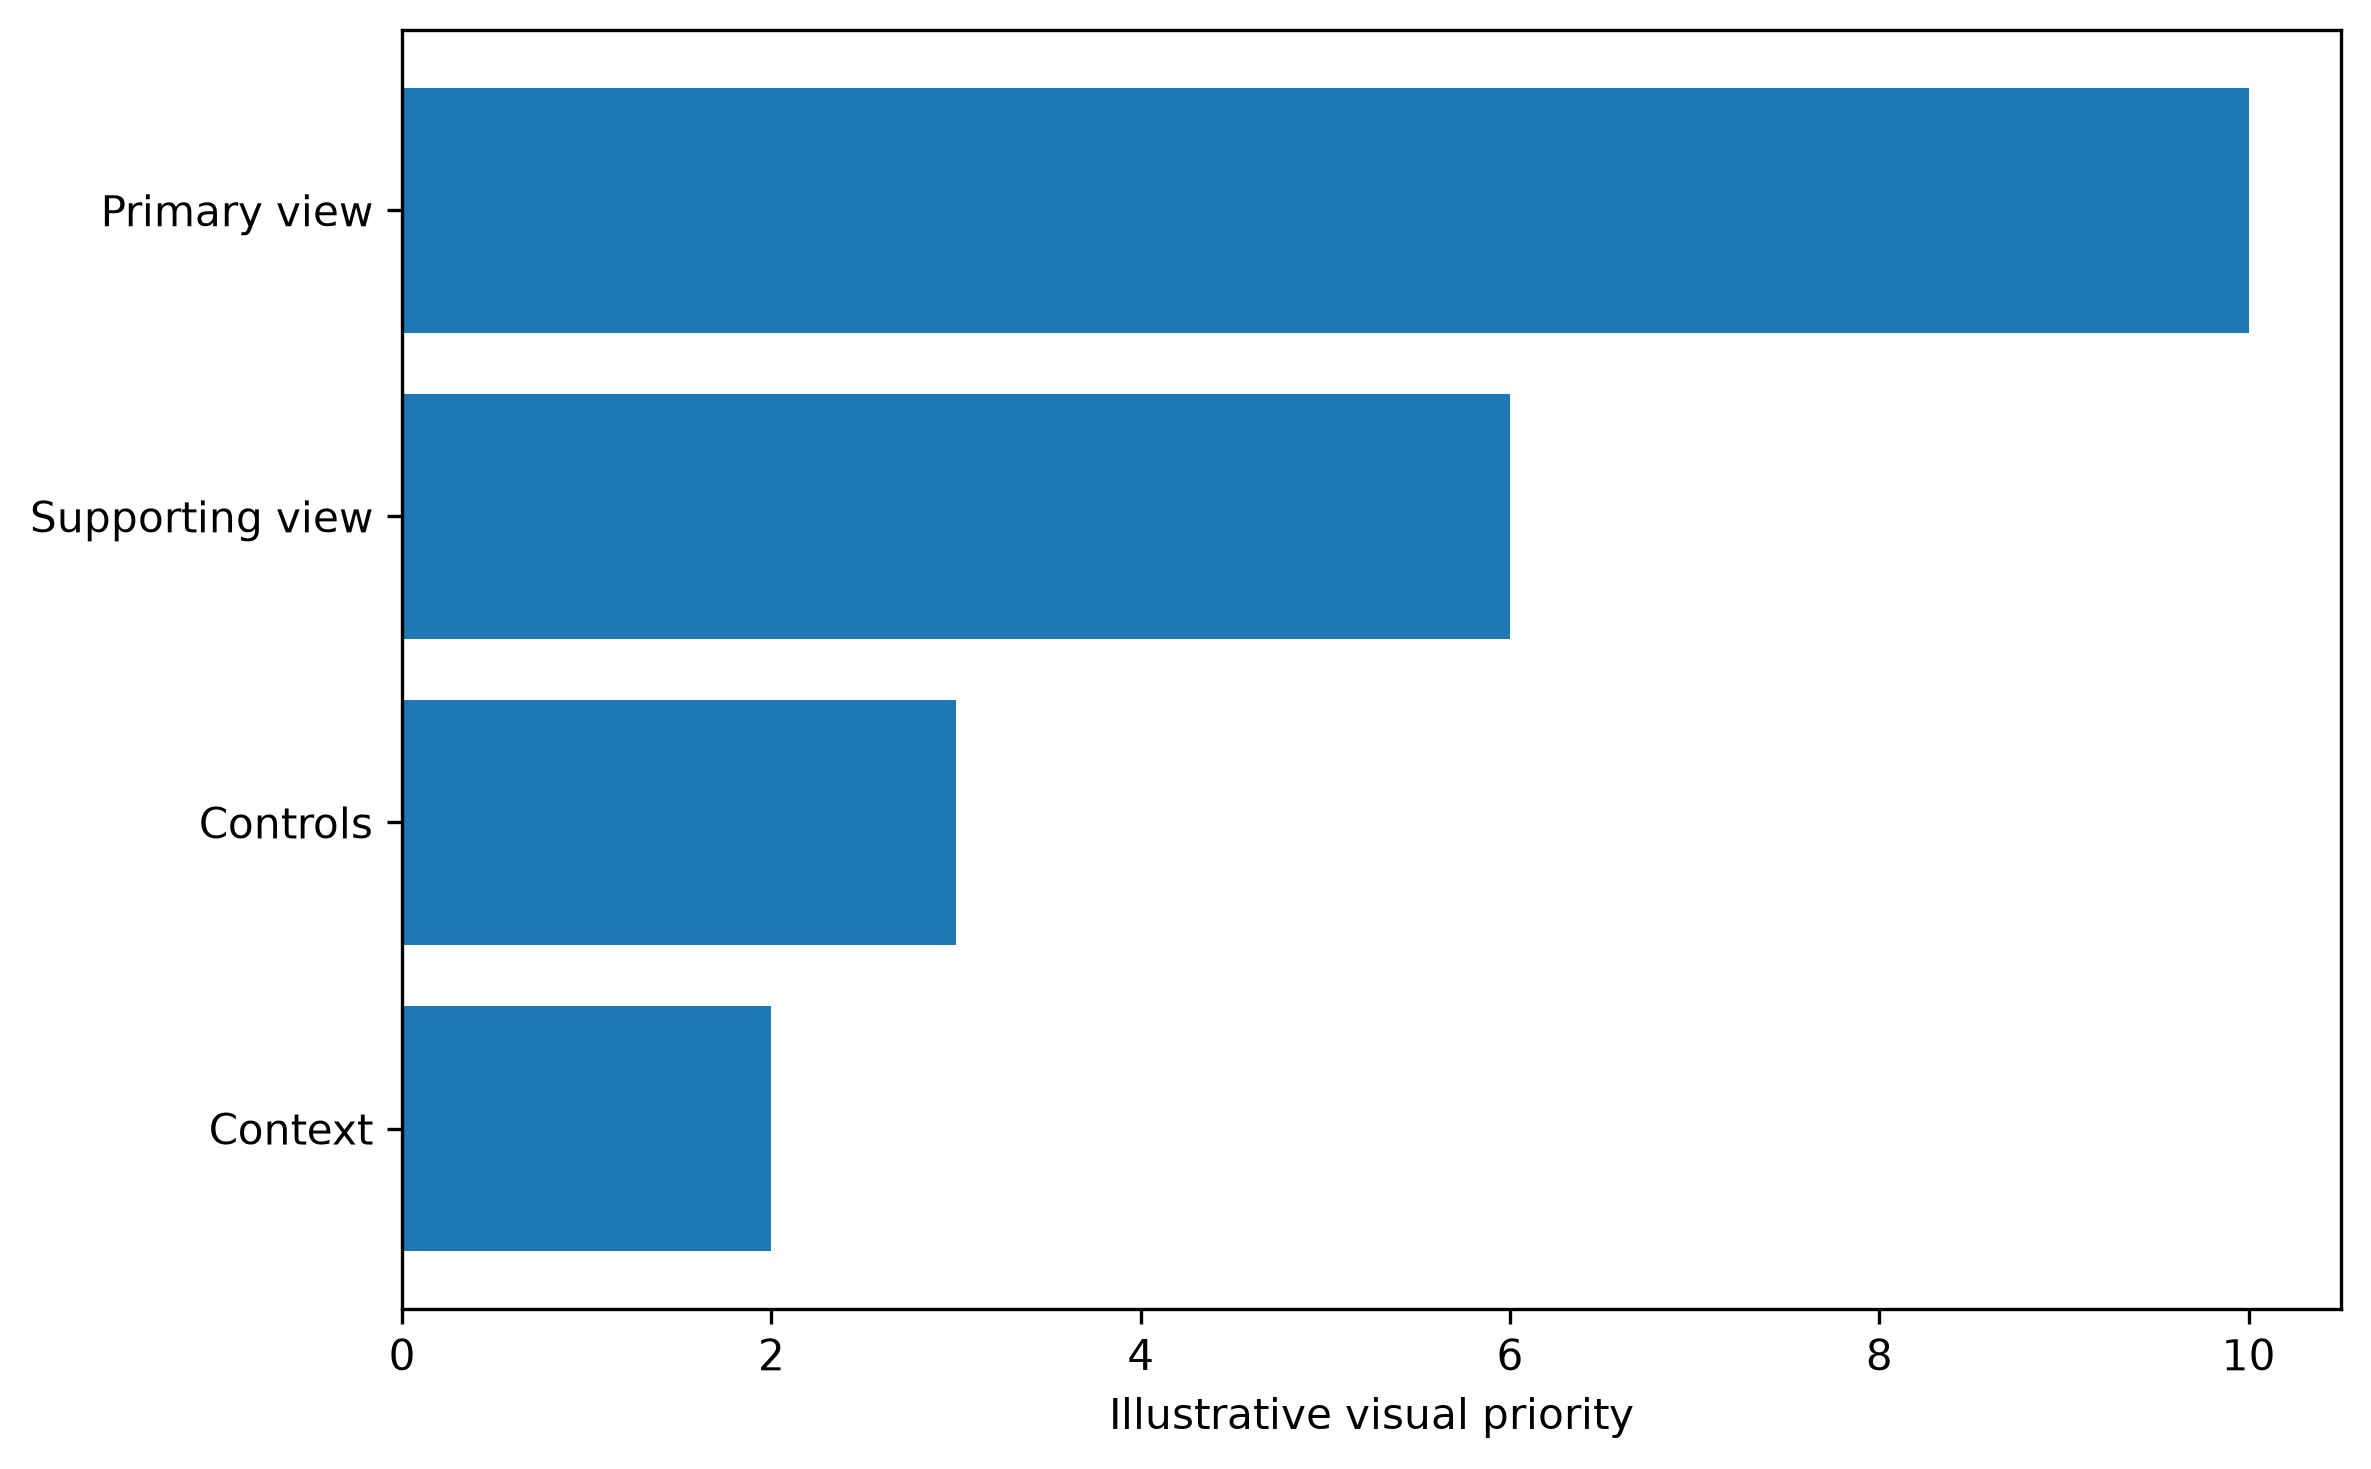


--- paper_07_poor.png (authored baseline) ---


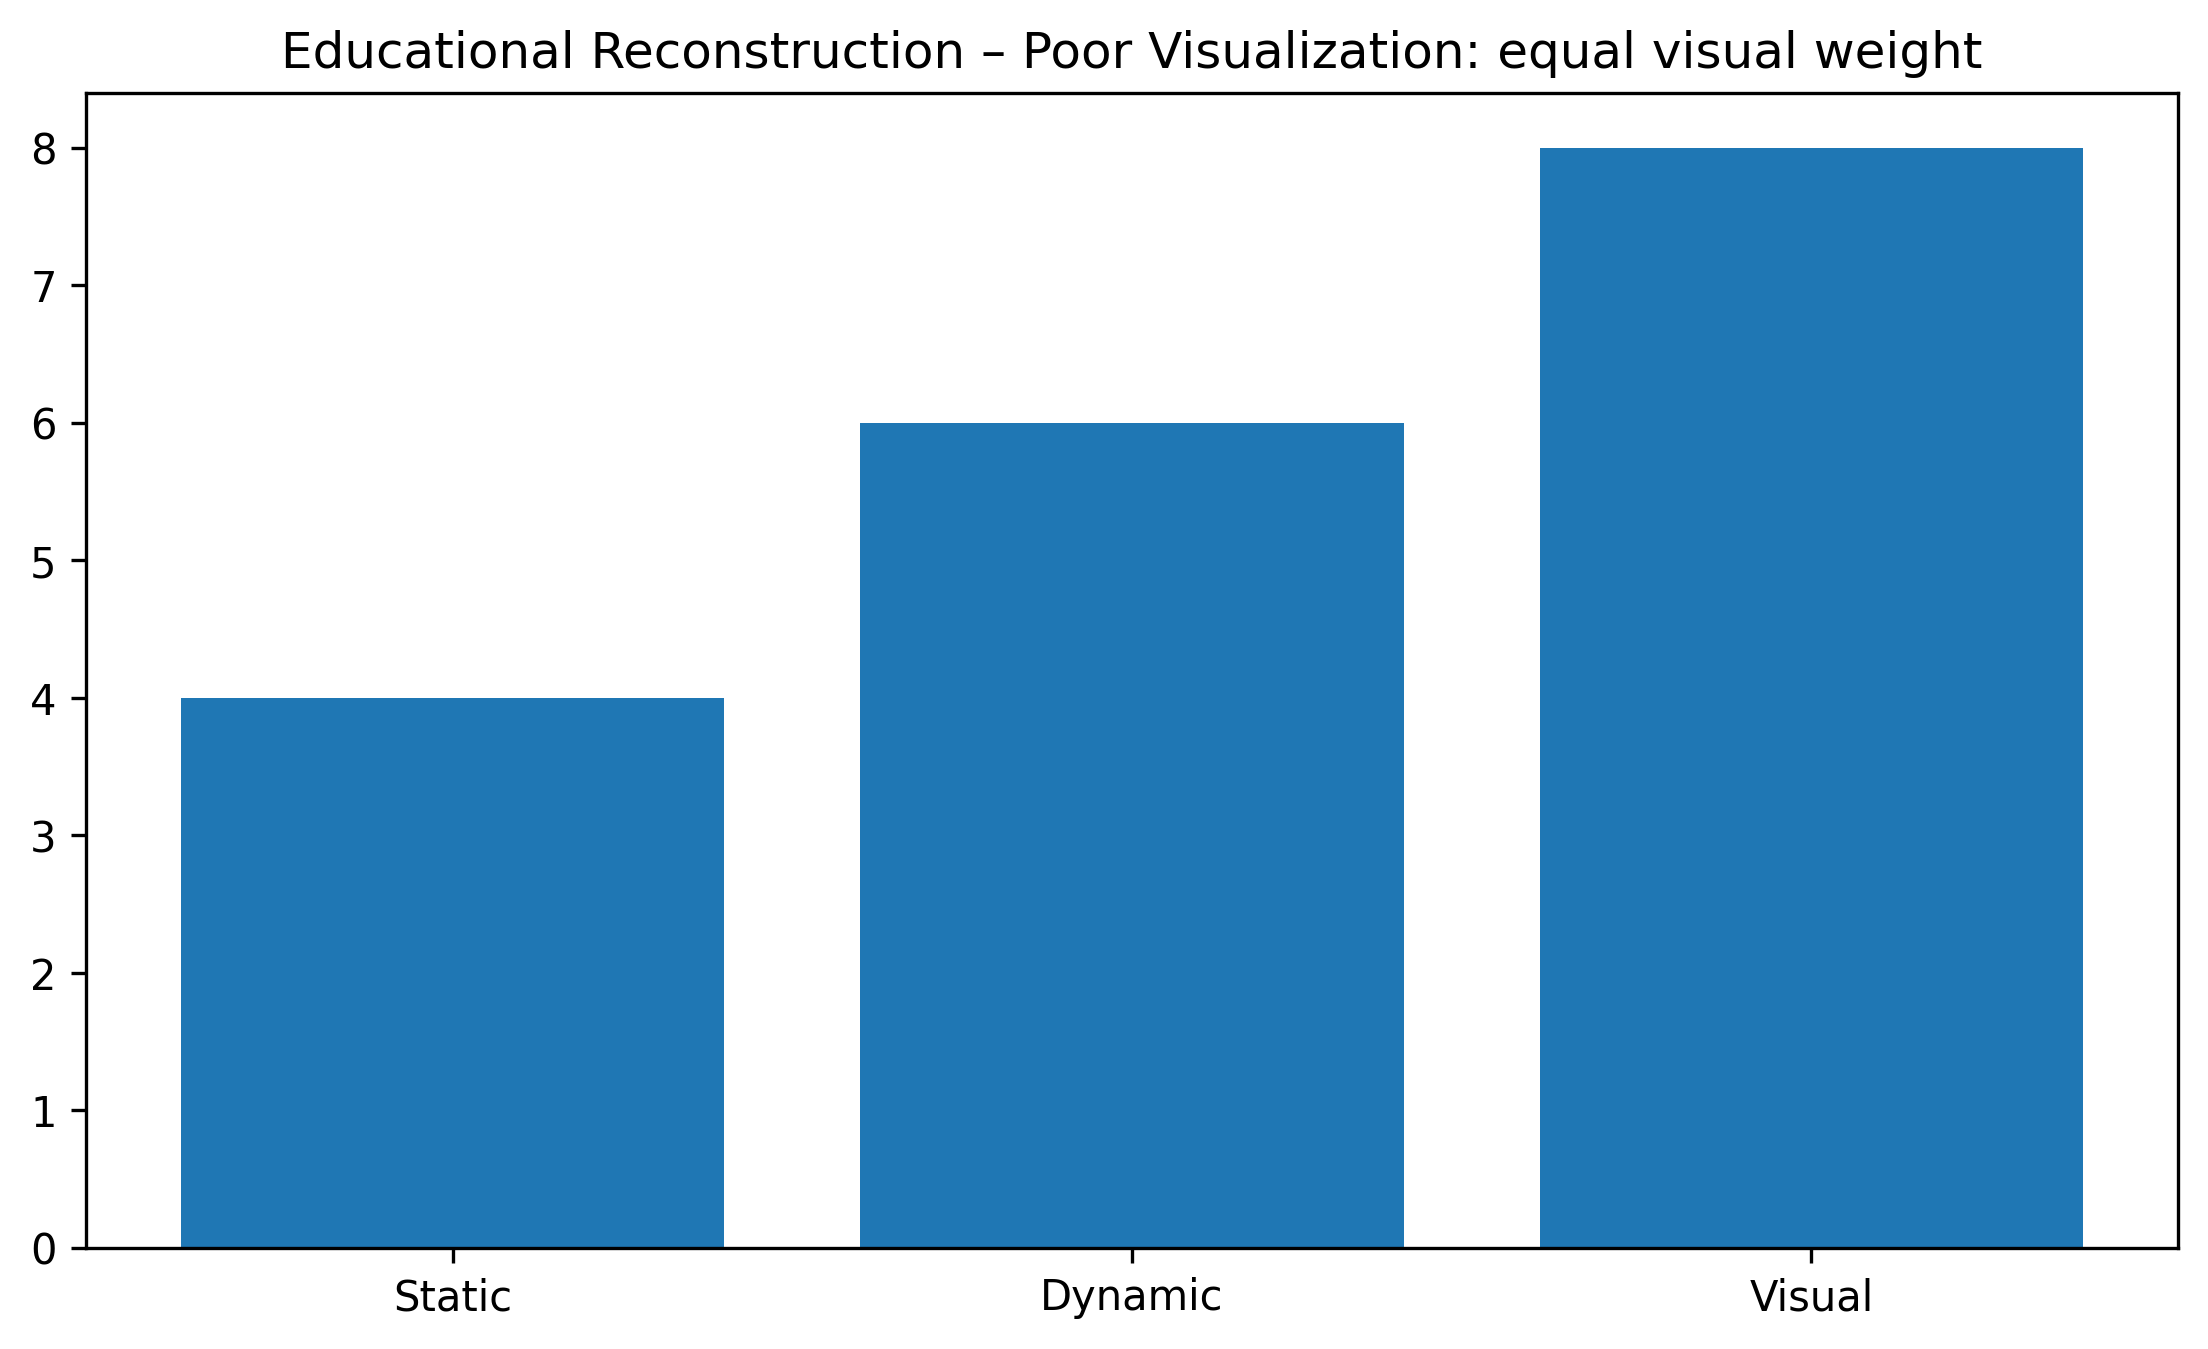

--- paper_07_improved.png (regenerated by this notebook) ---


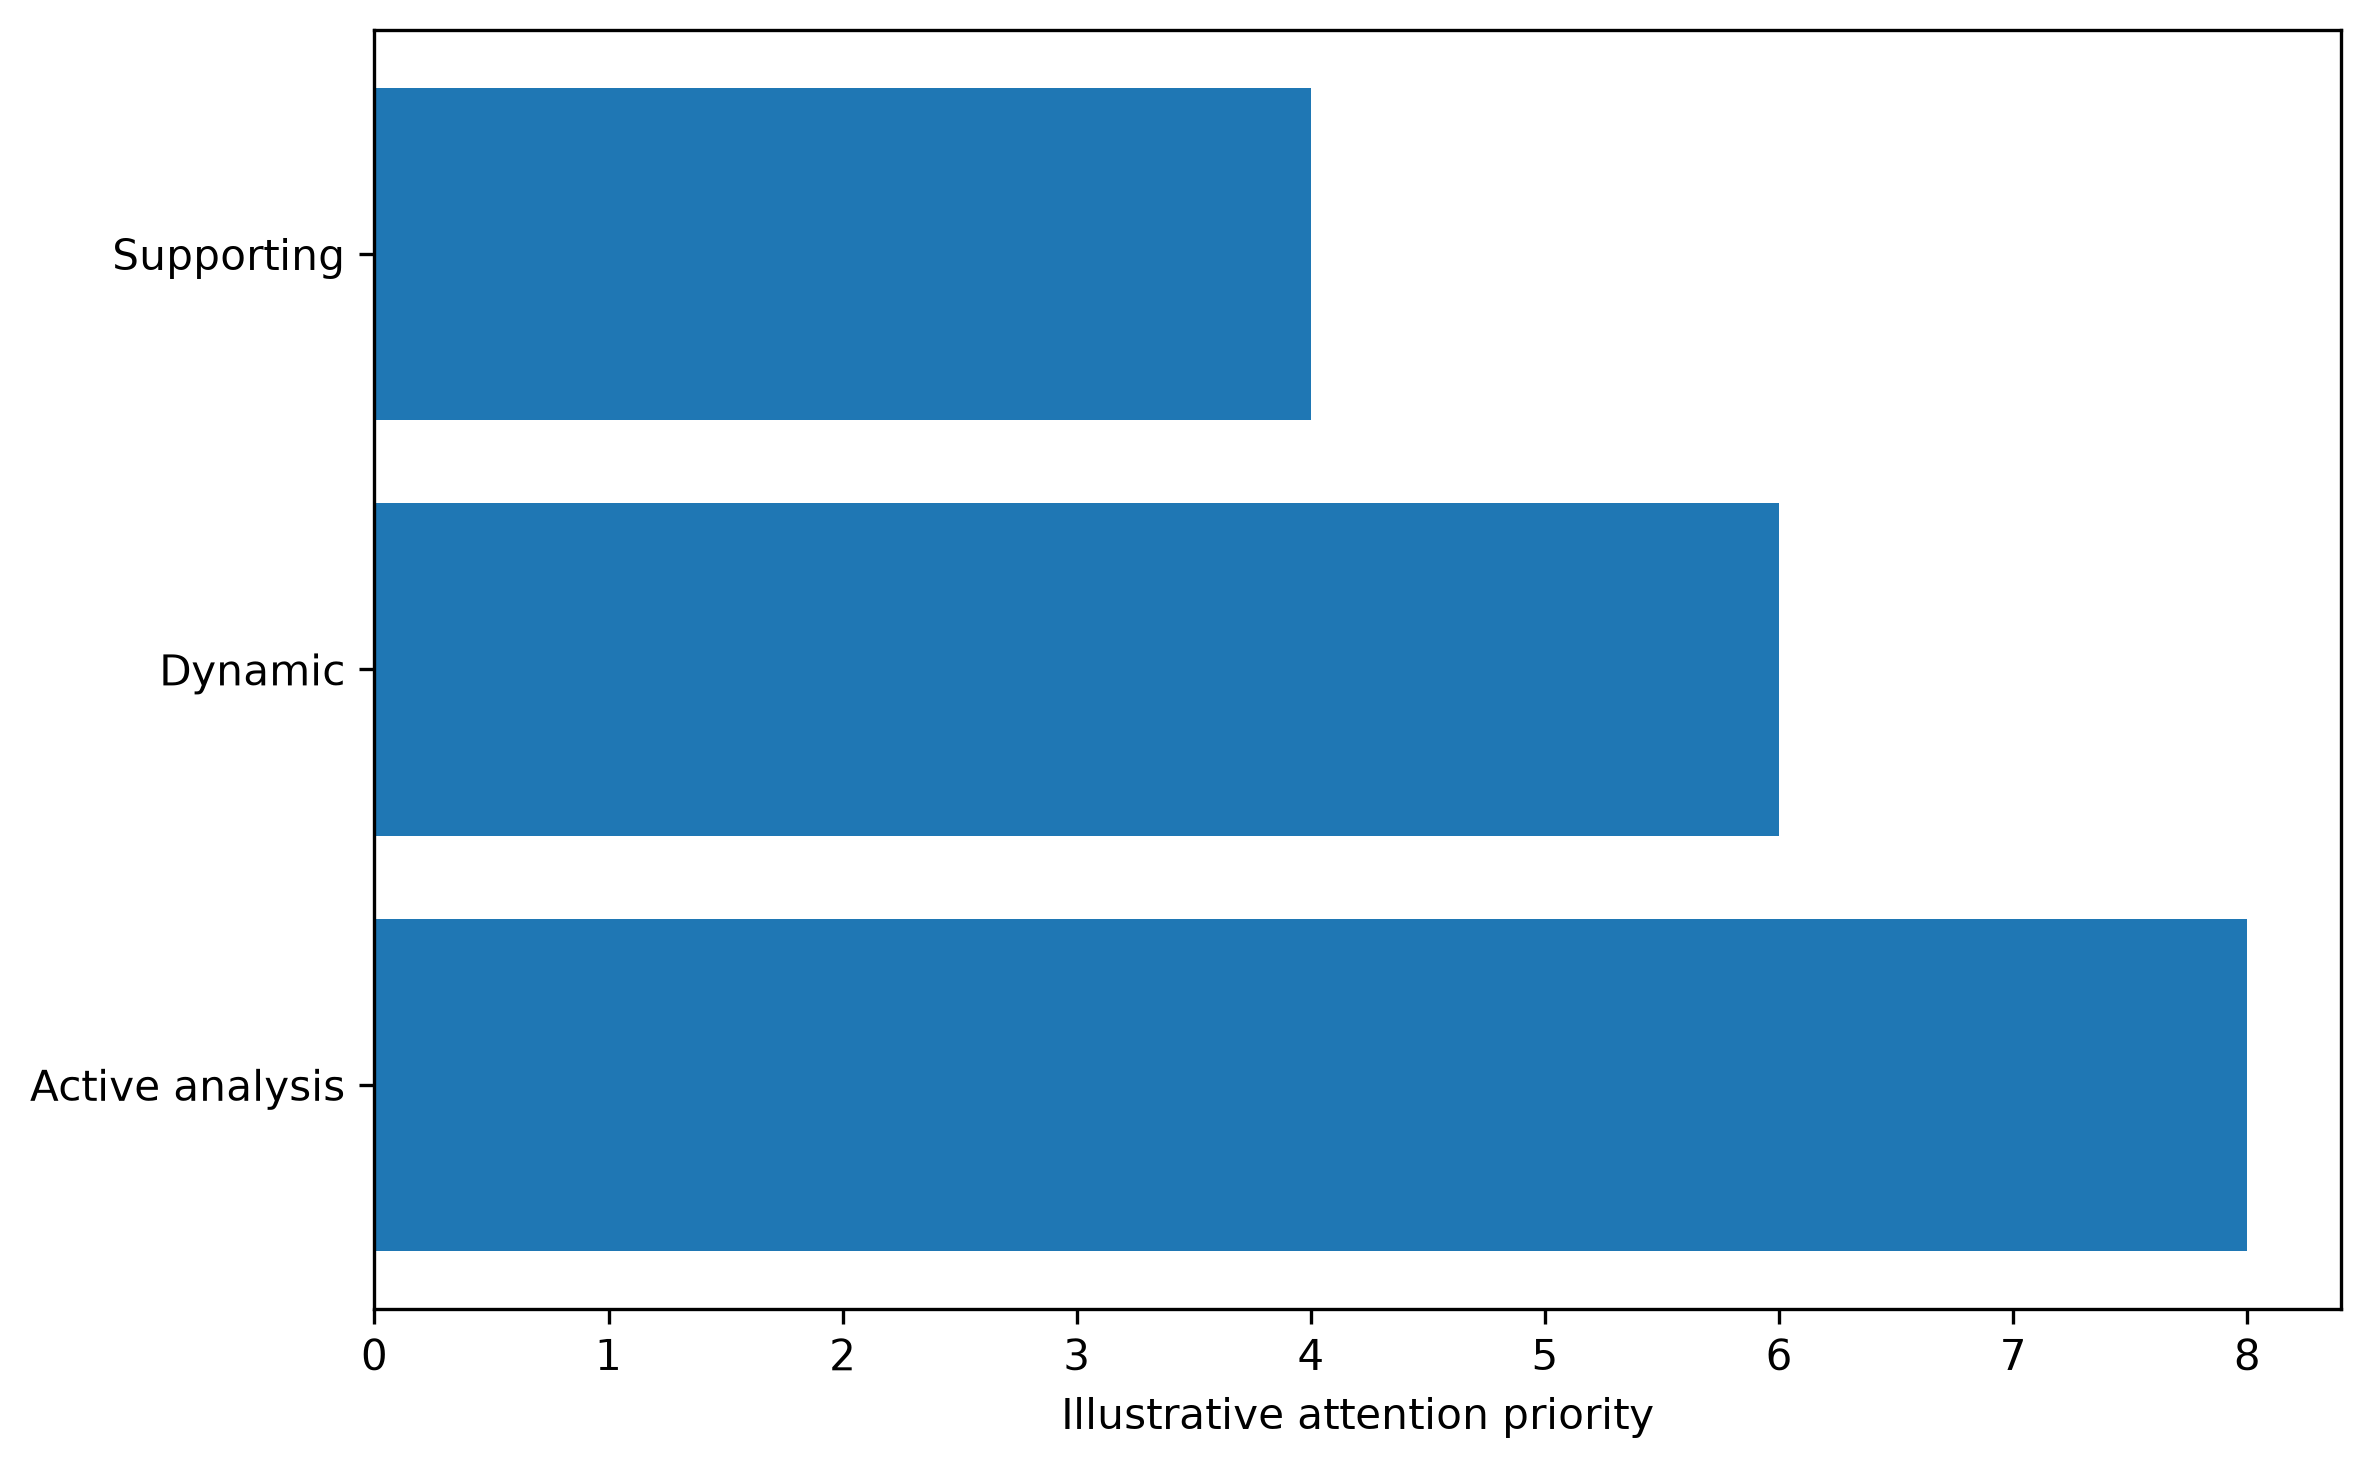


--- paper_08_poor.png (authored baseline) ---


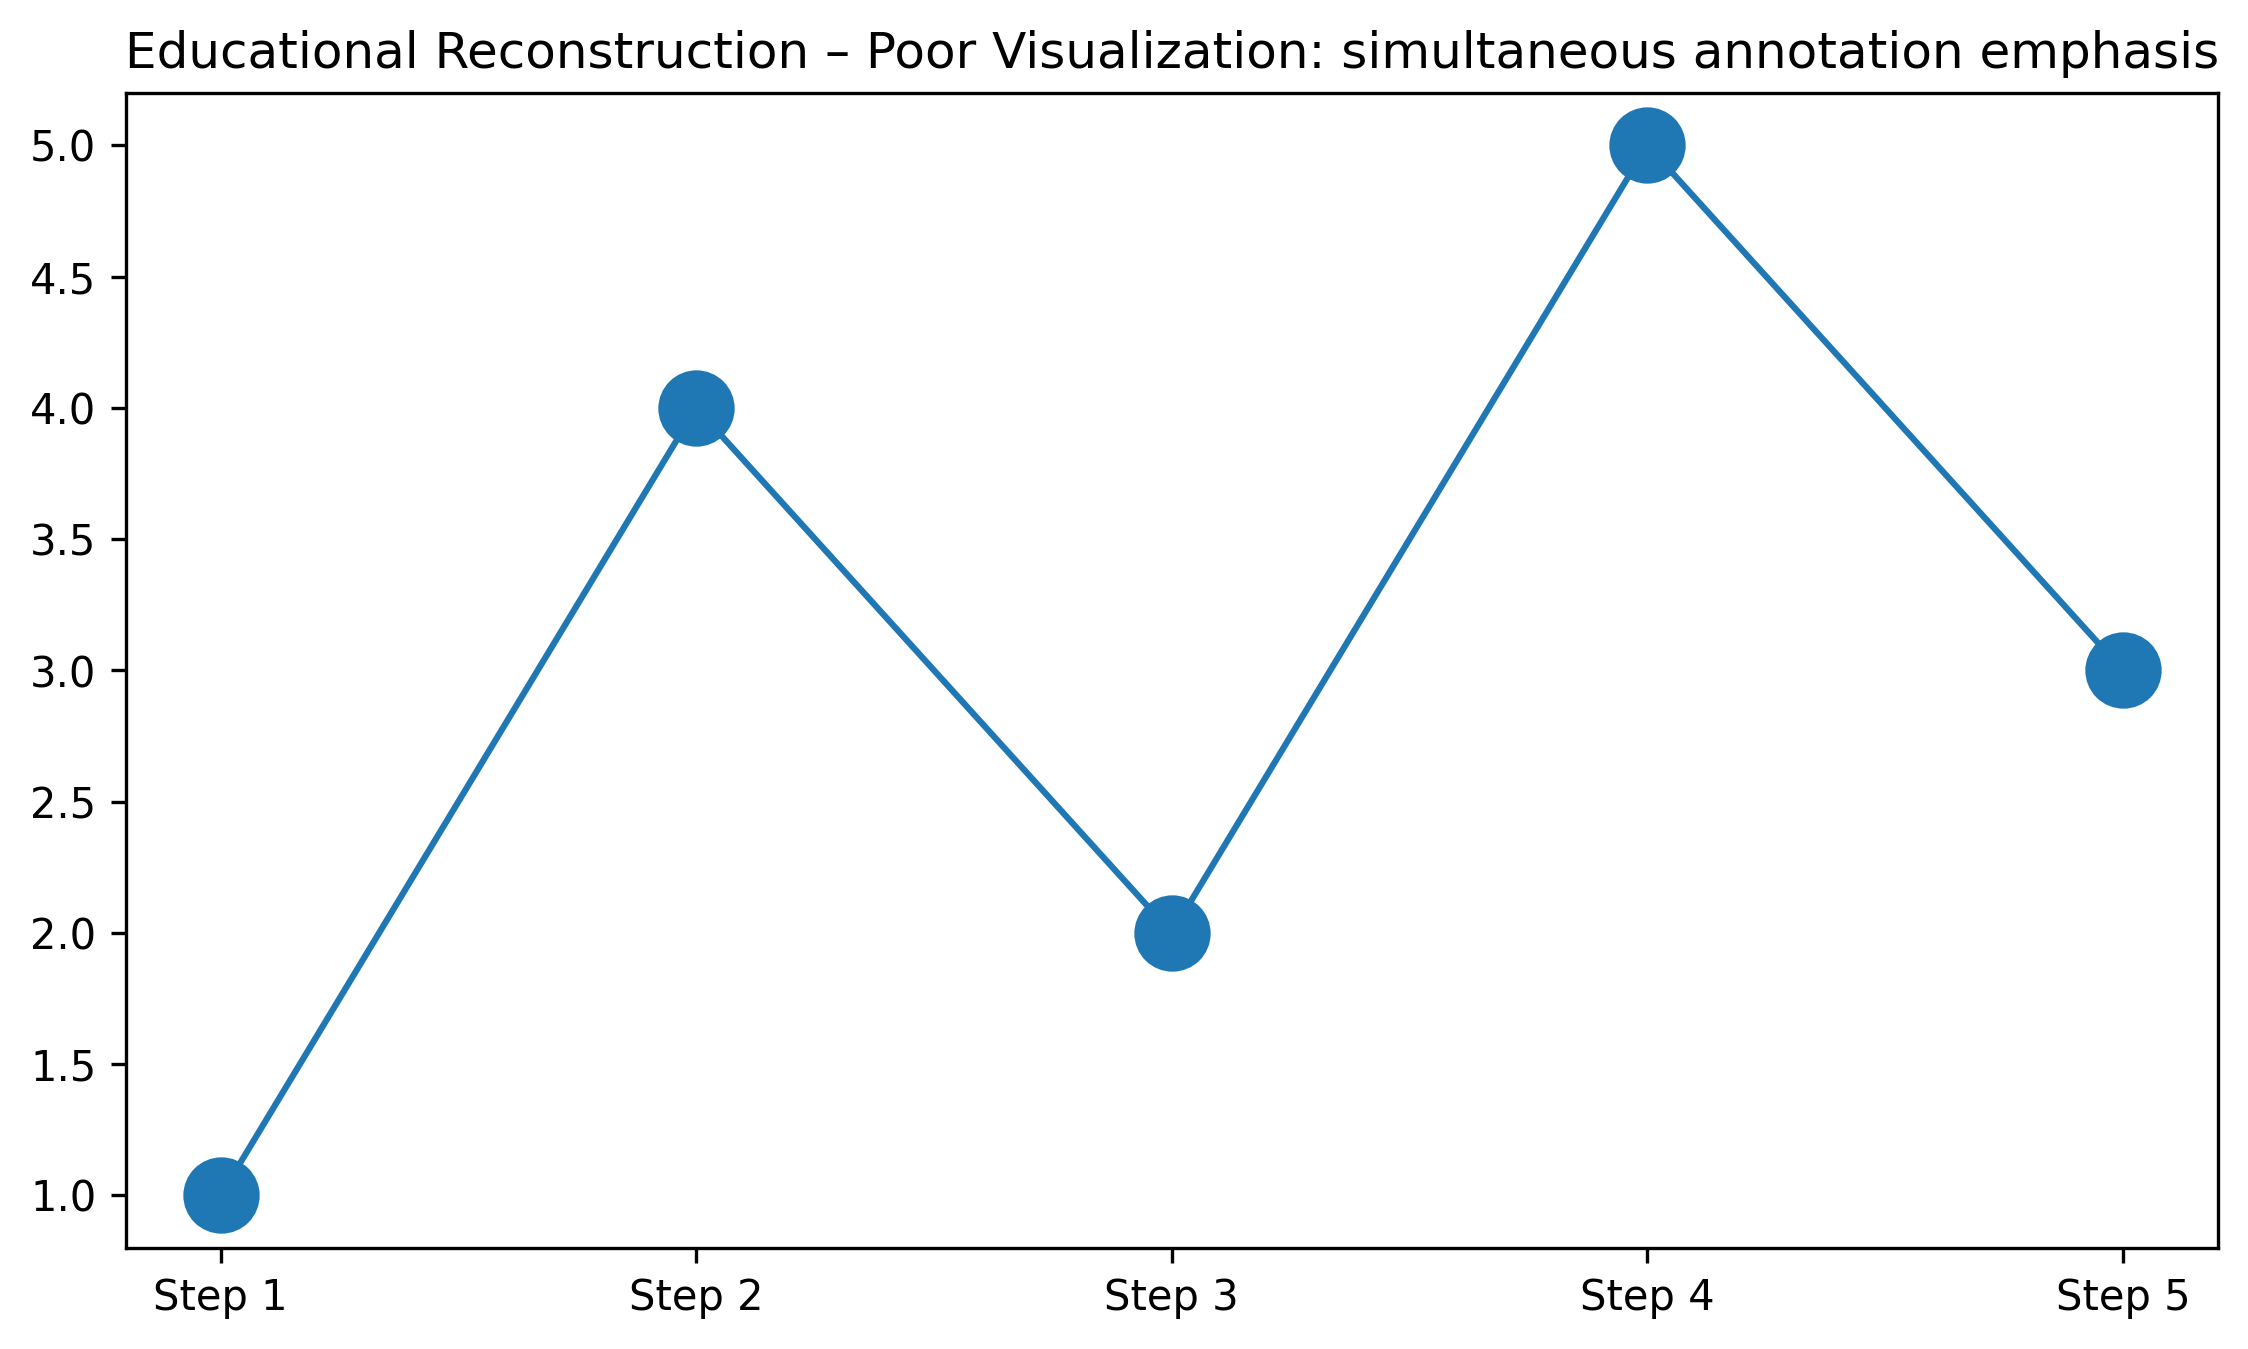

--- paper_08_improved.png (regenerated by this notebook) ---


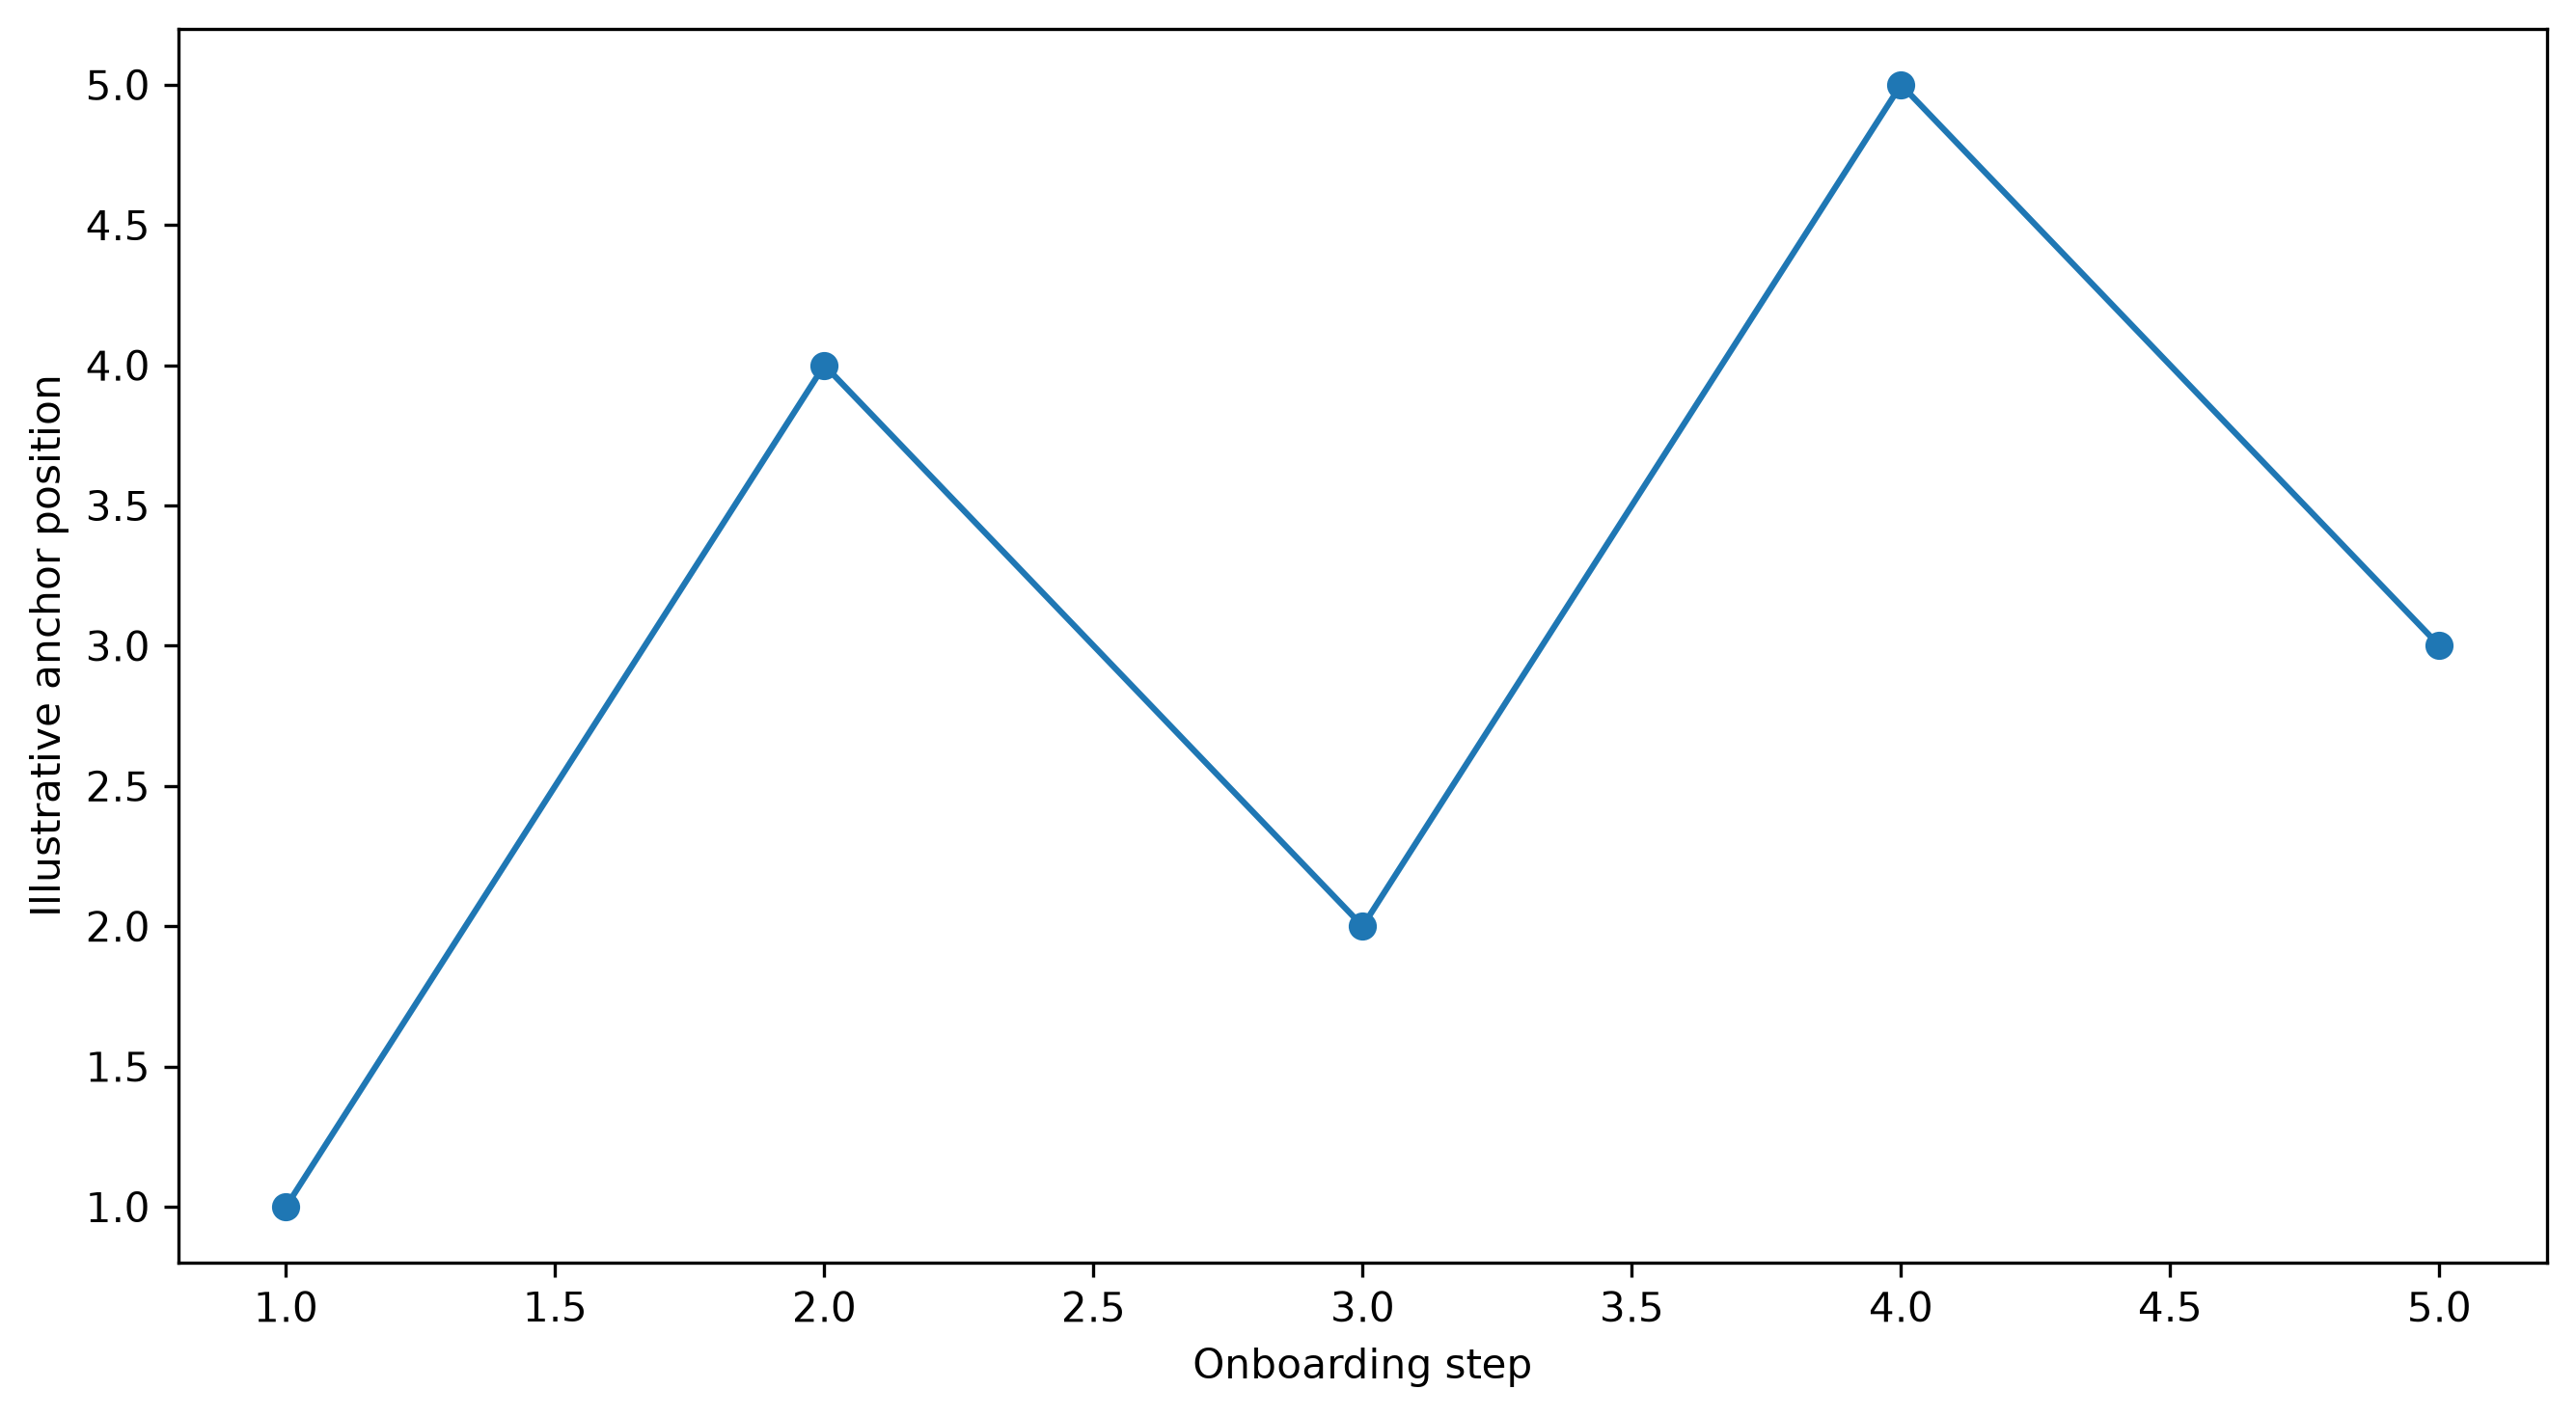


--- paper_09_poor.png (authored baseline) ---


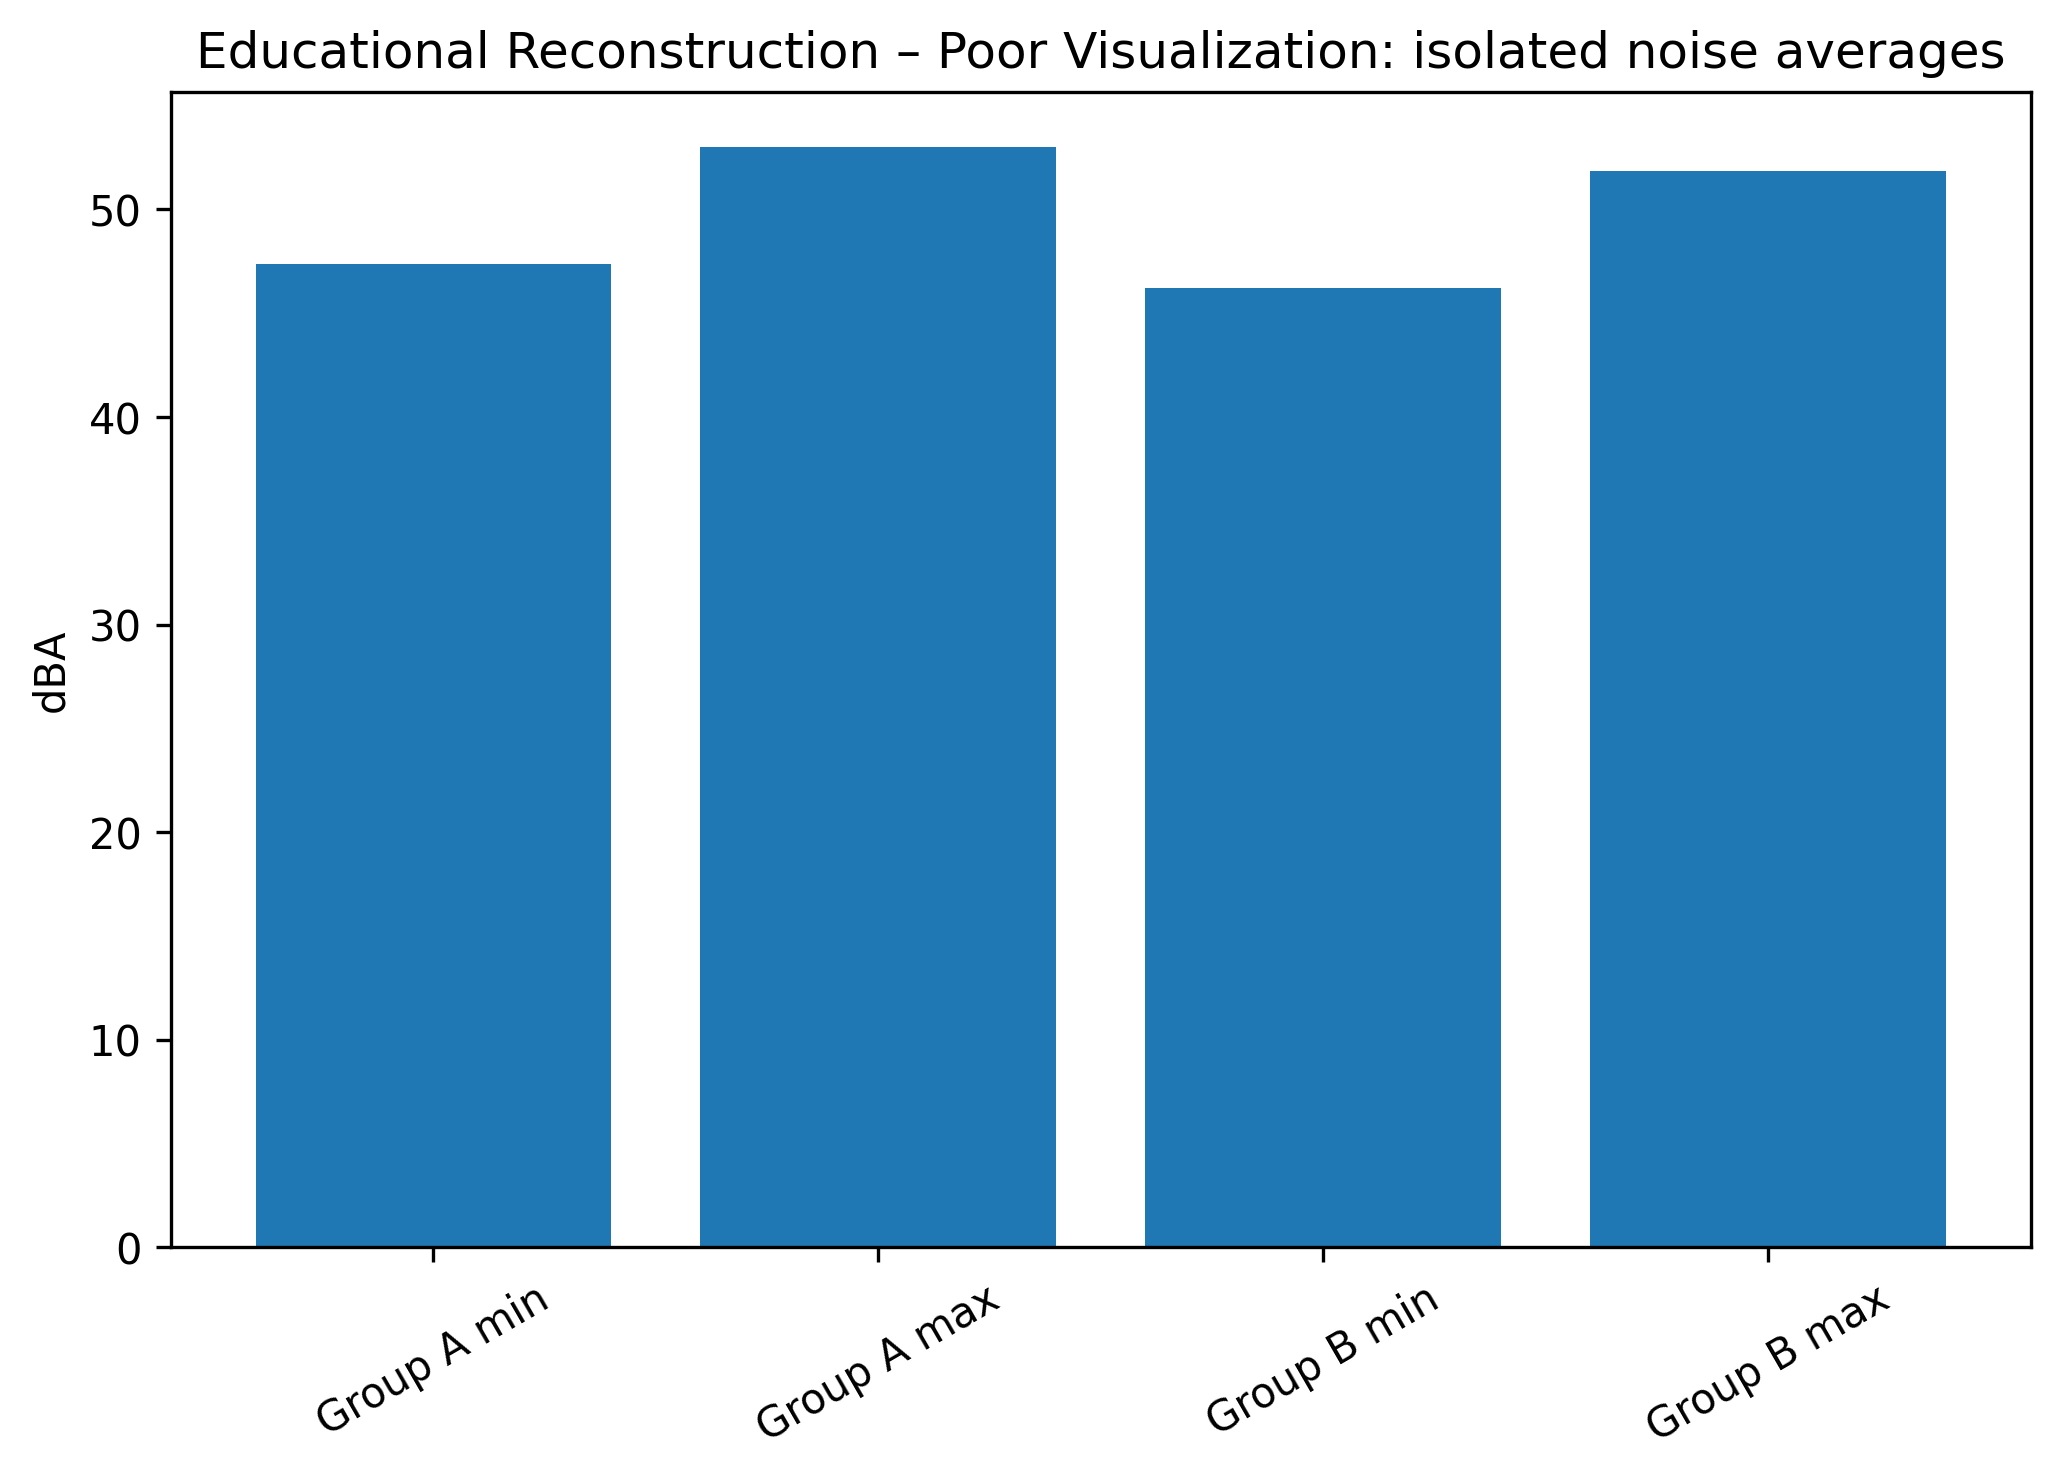

--- paper_09_improved.png (regenerated by this notebook) ---


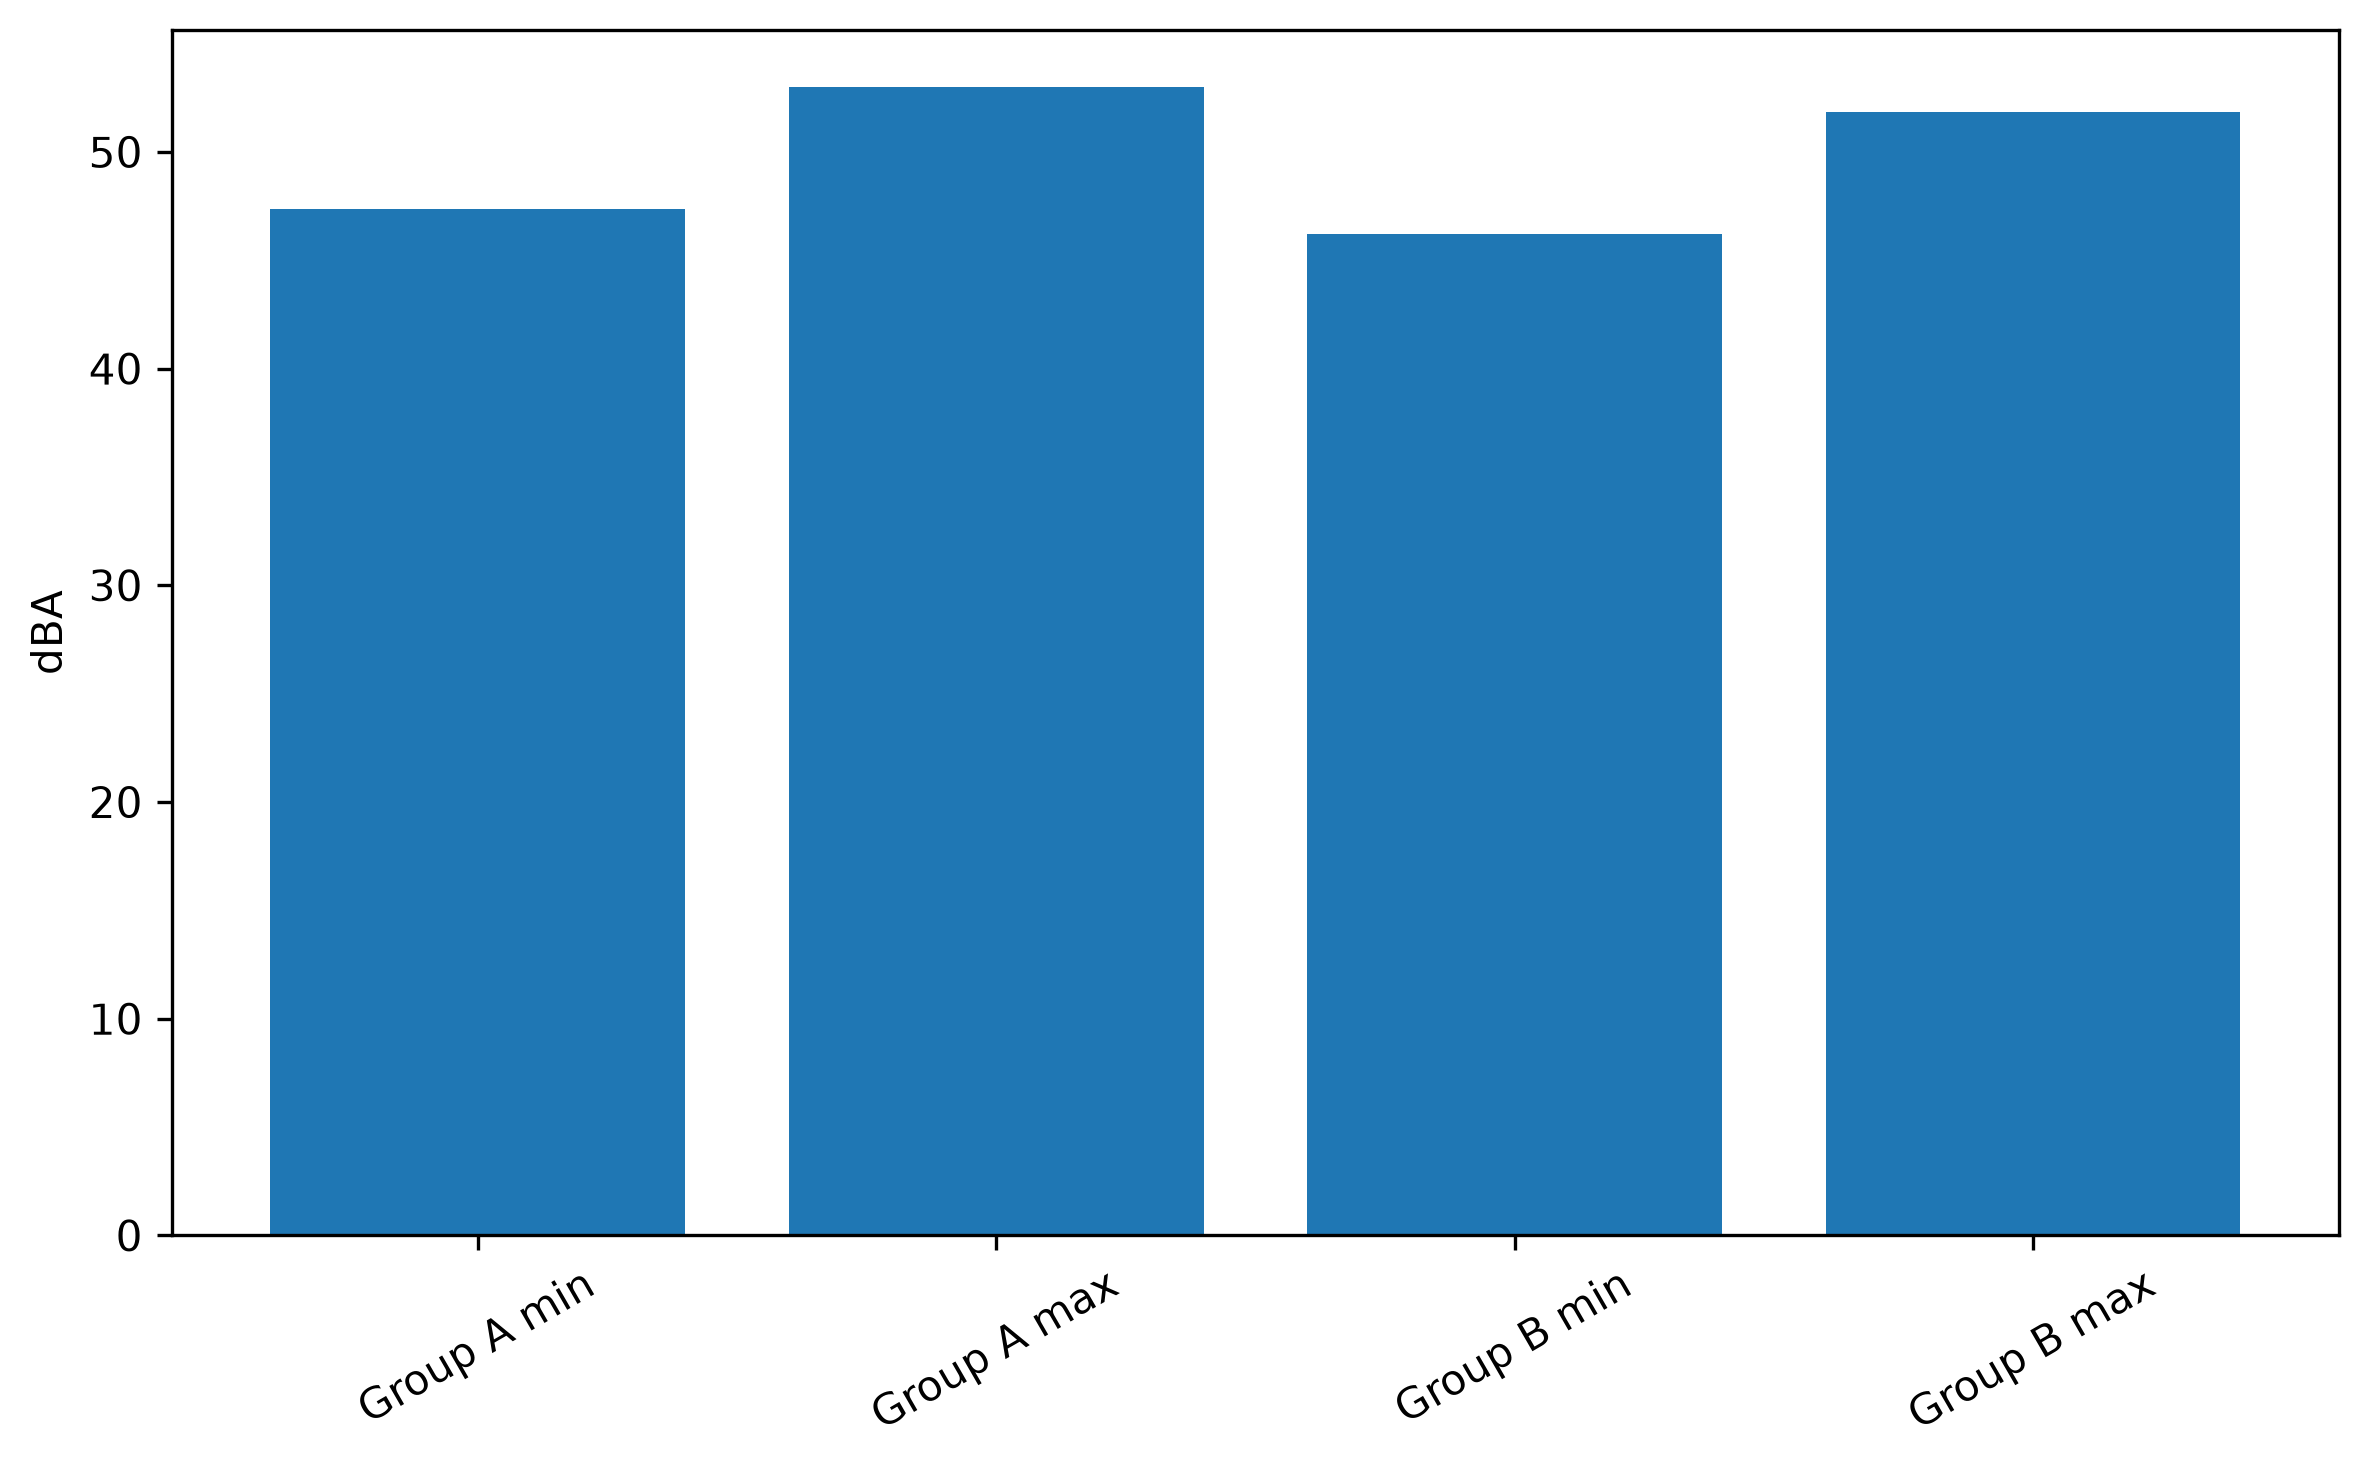


--- paper_10_poor.png (authored baseline) ---


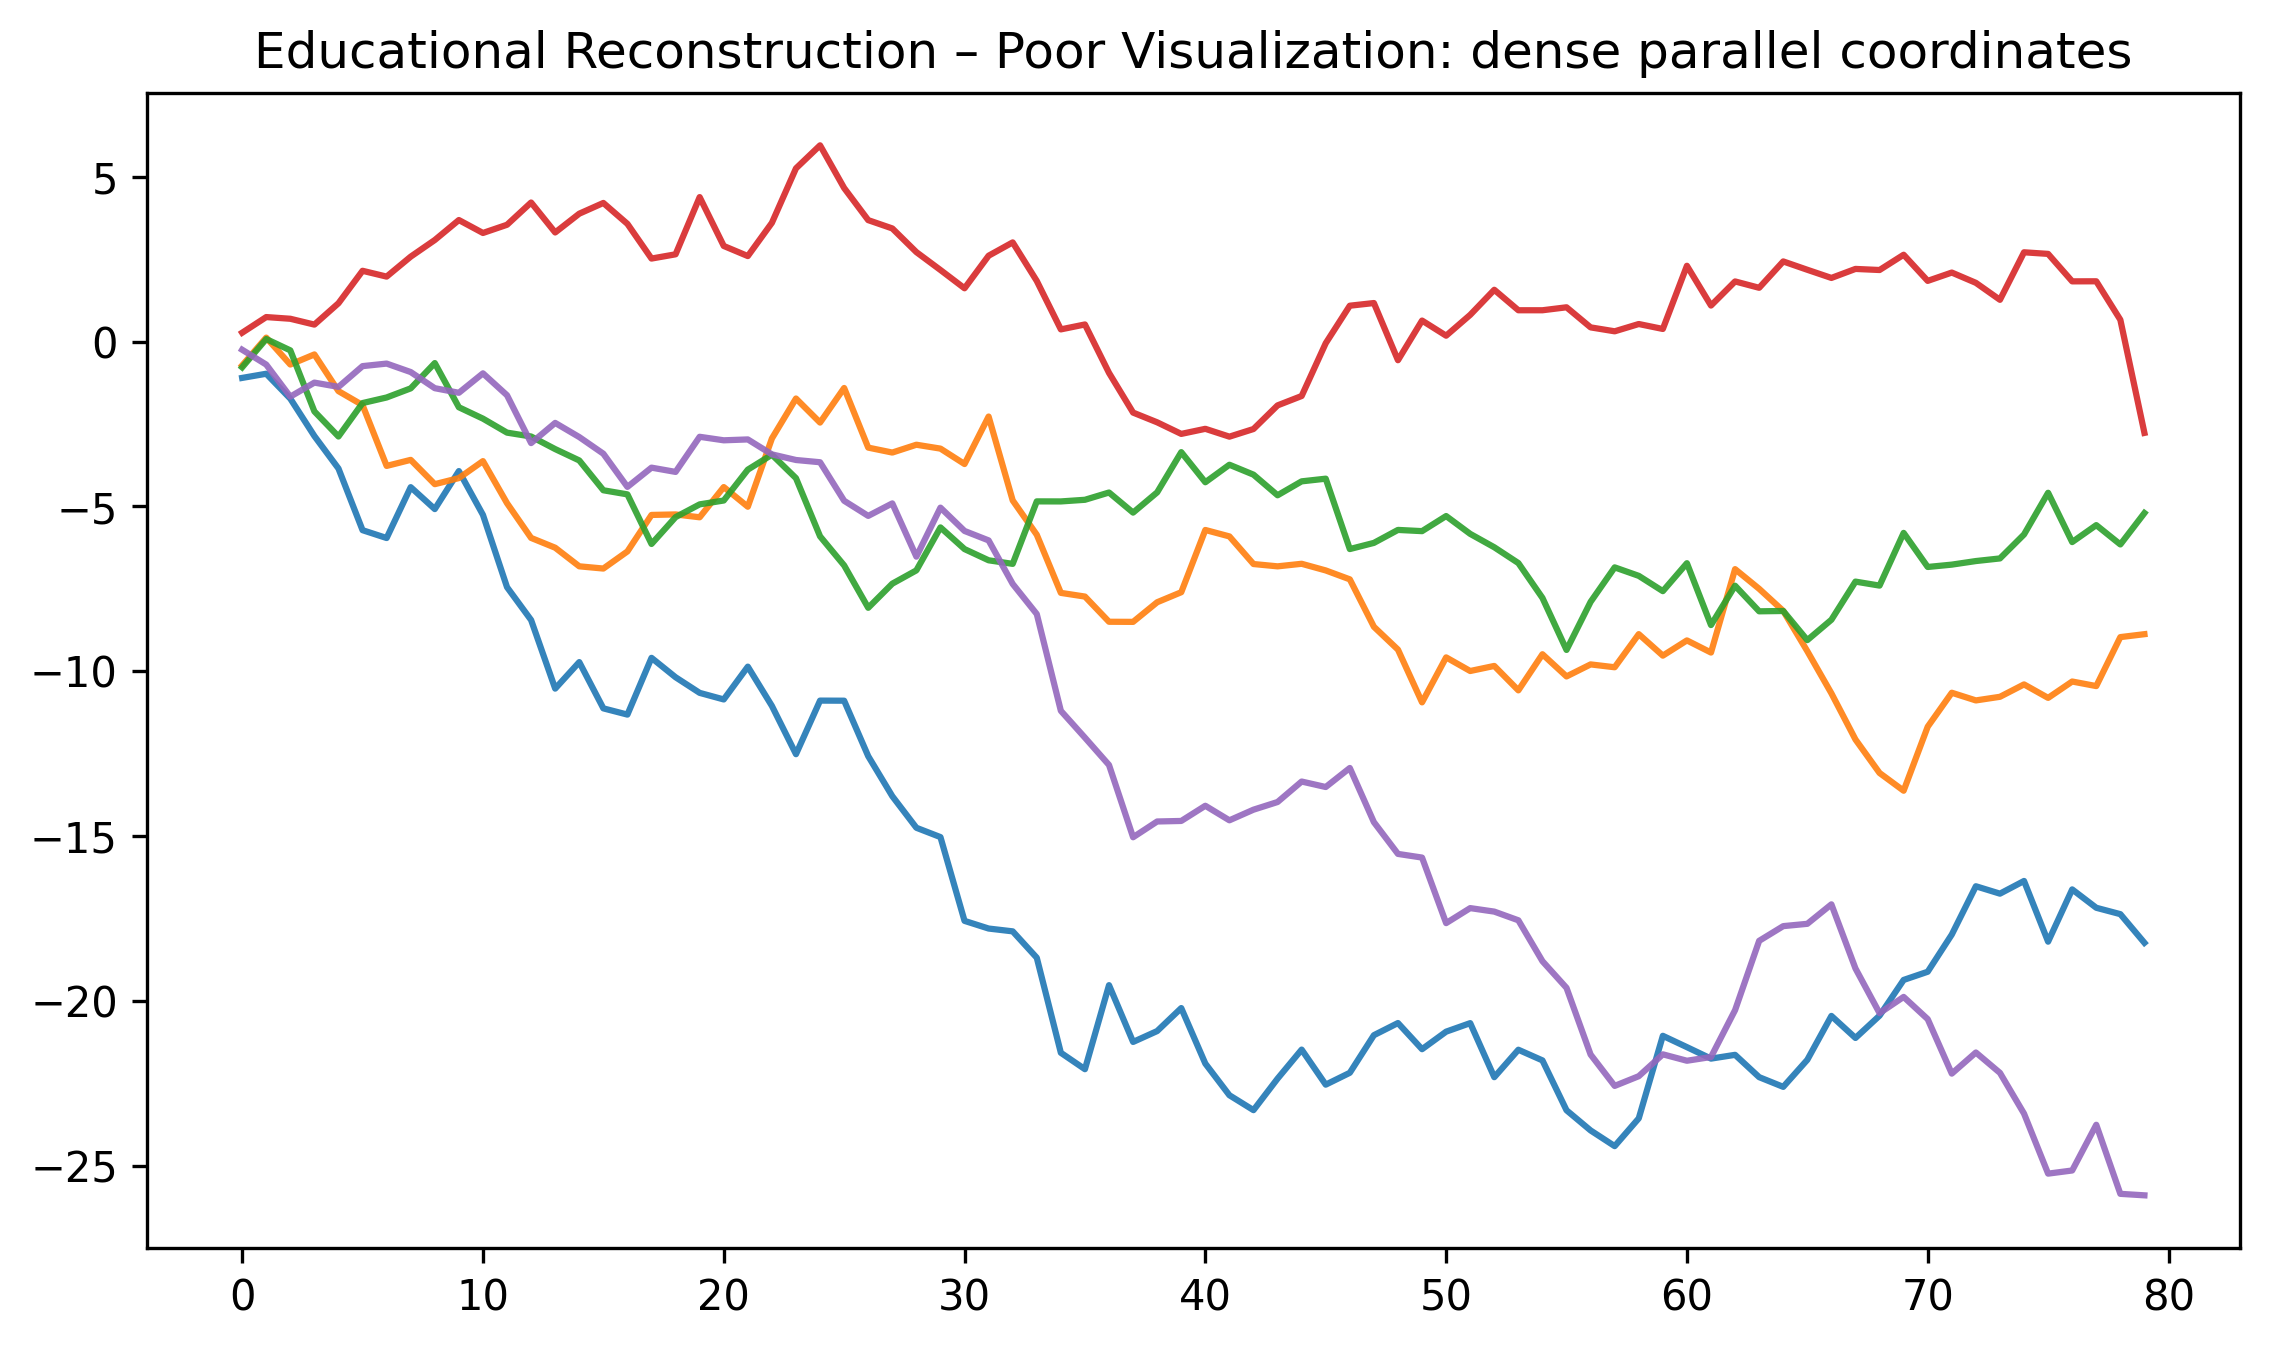

--- paper_10_improved.png (regenerated by this notebook) ---


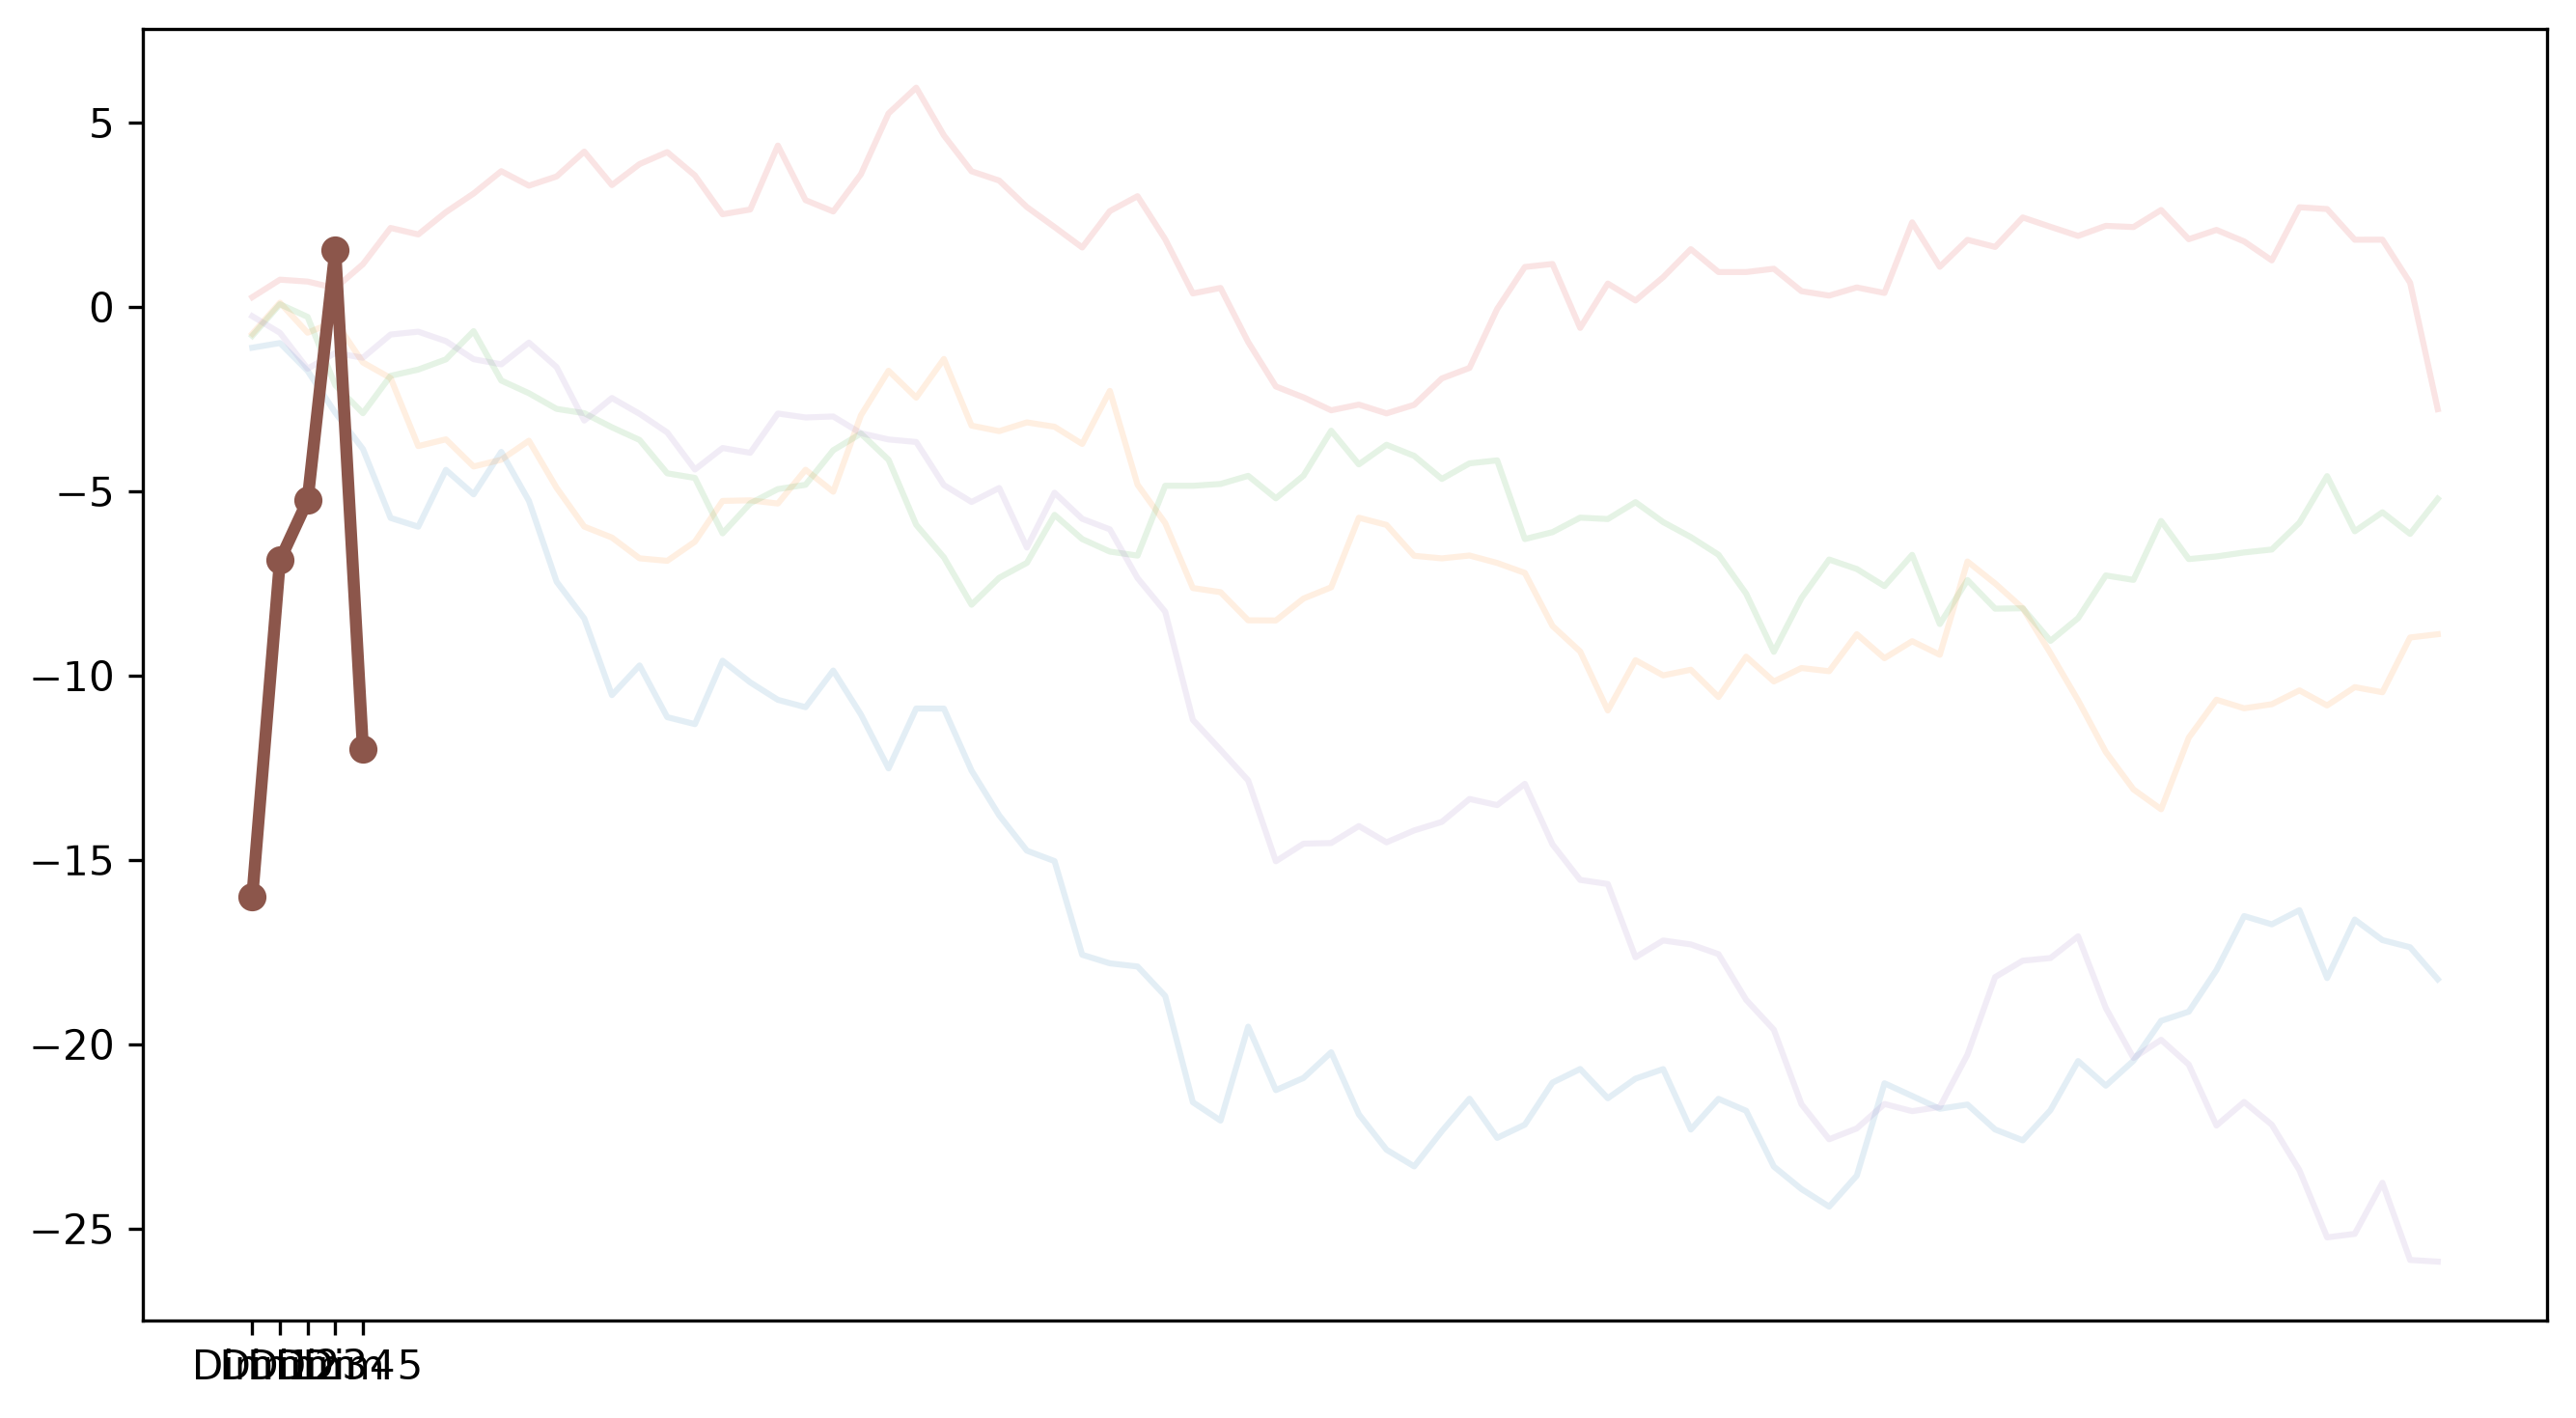


--- paper_11_poor.png (authored baseline) ---


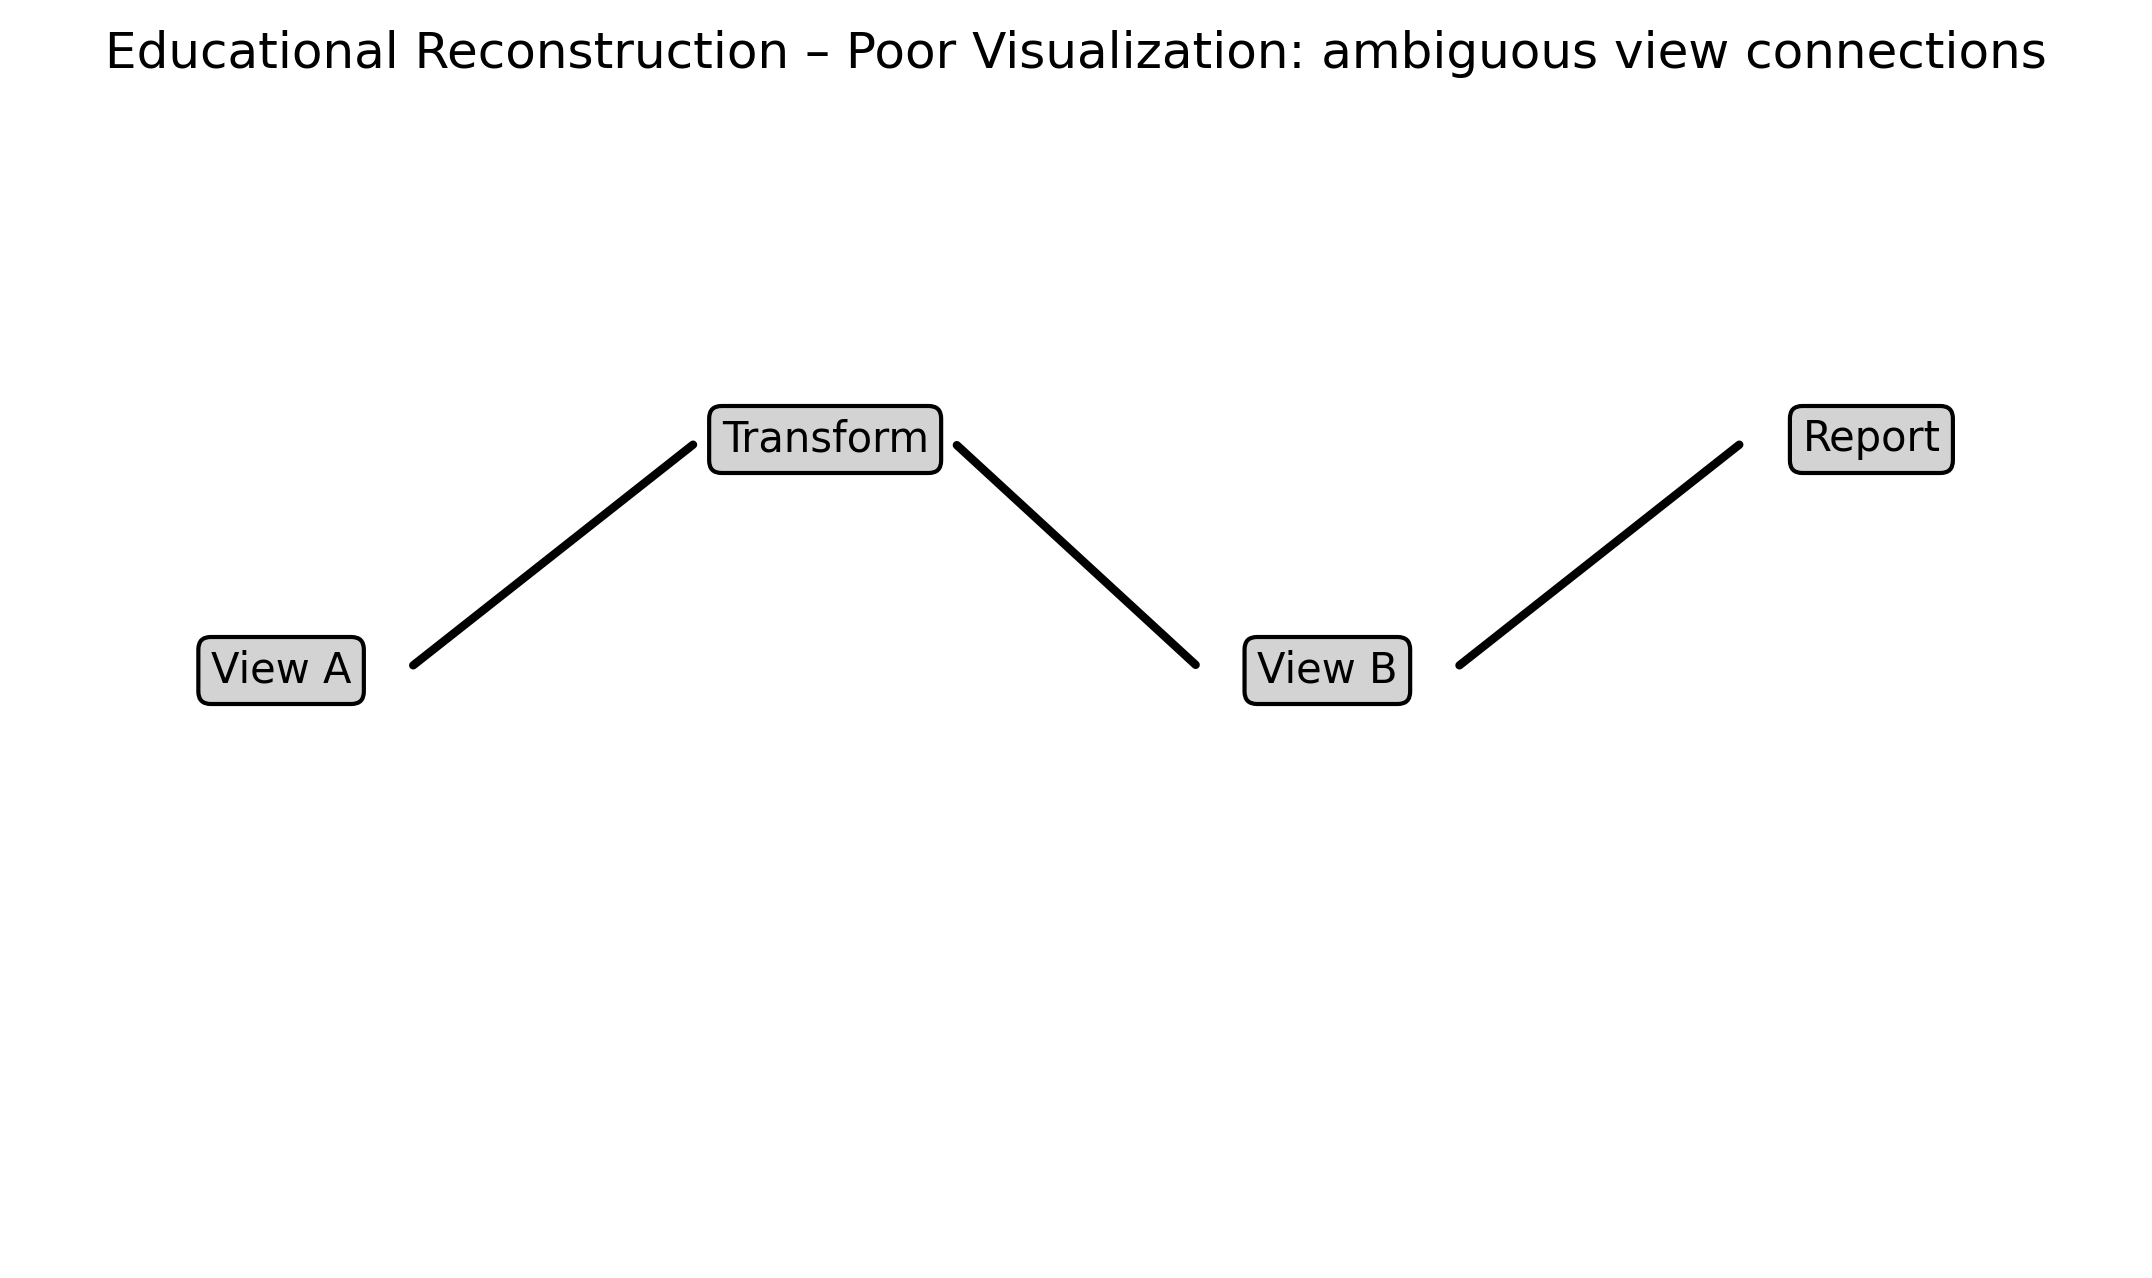

--- paper_11_improved.png (regenerated by this notebook) ---


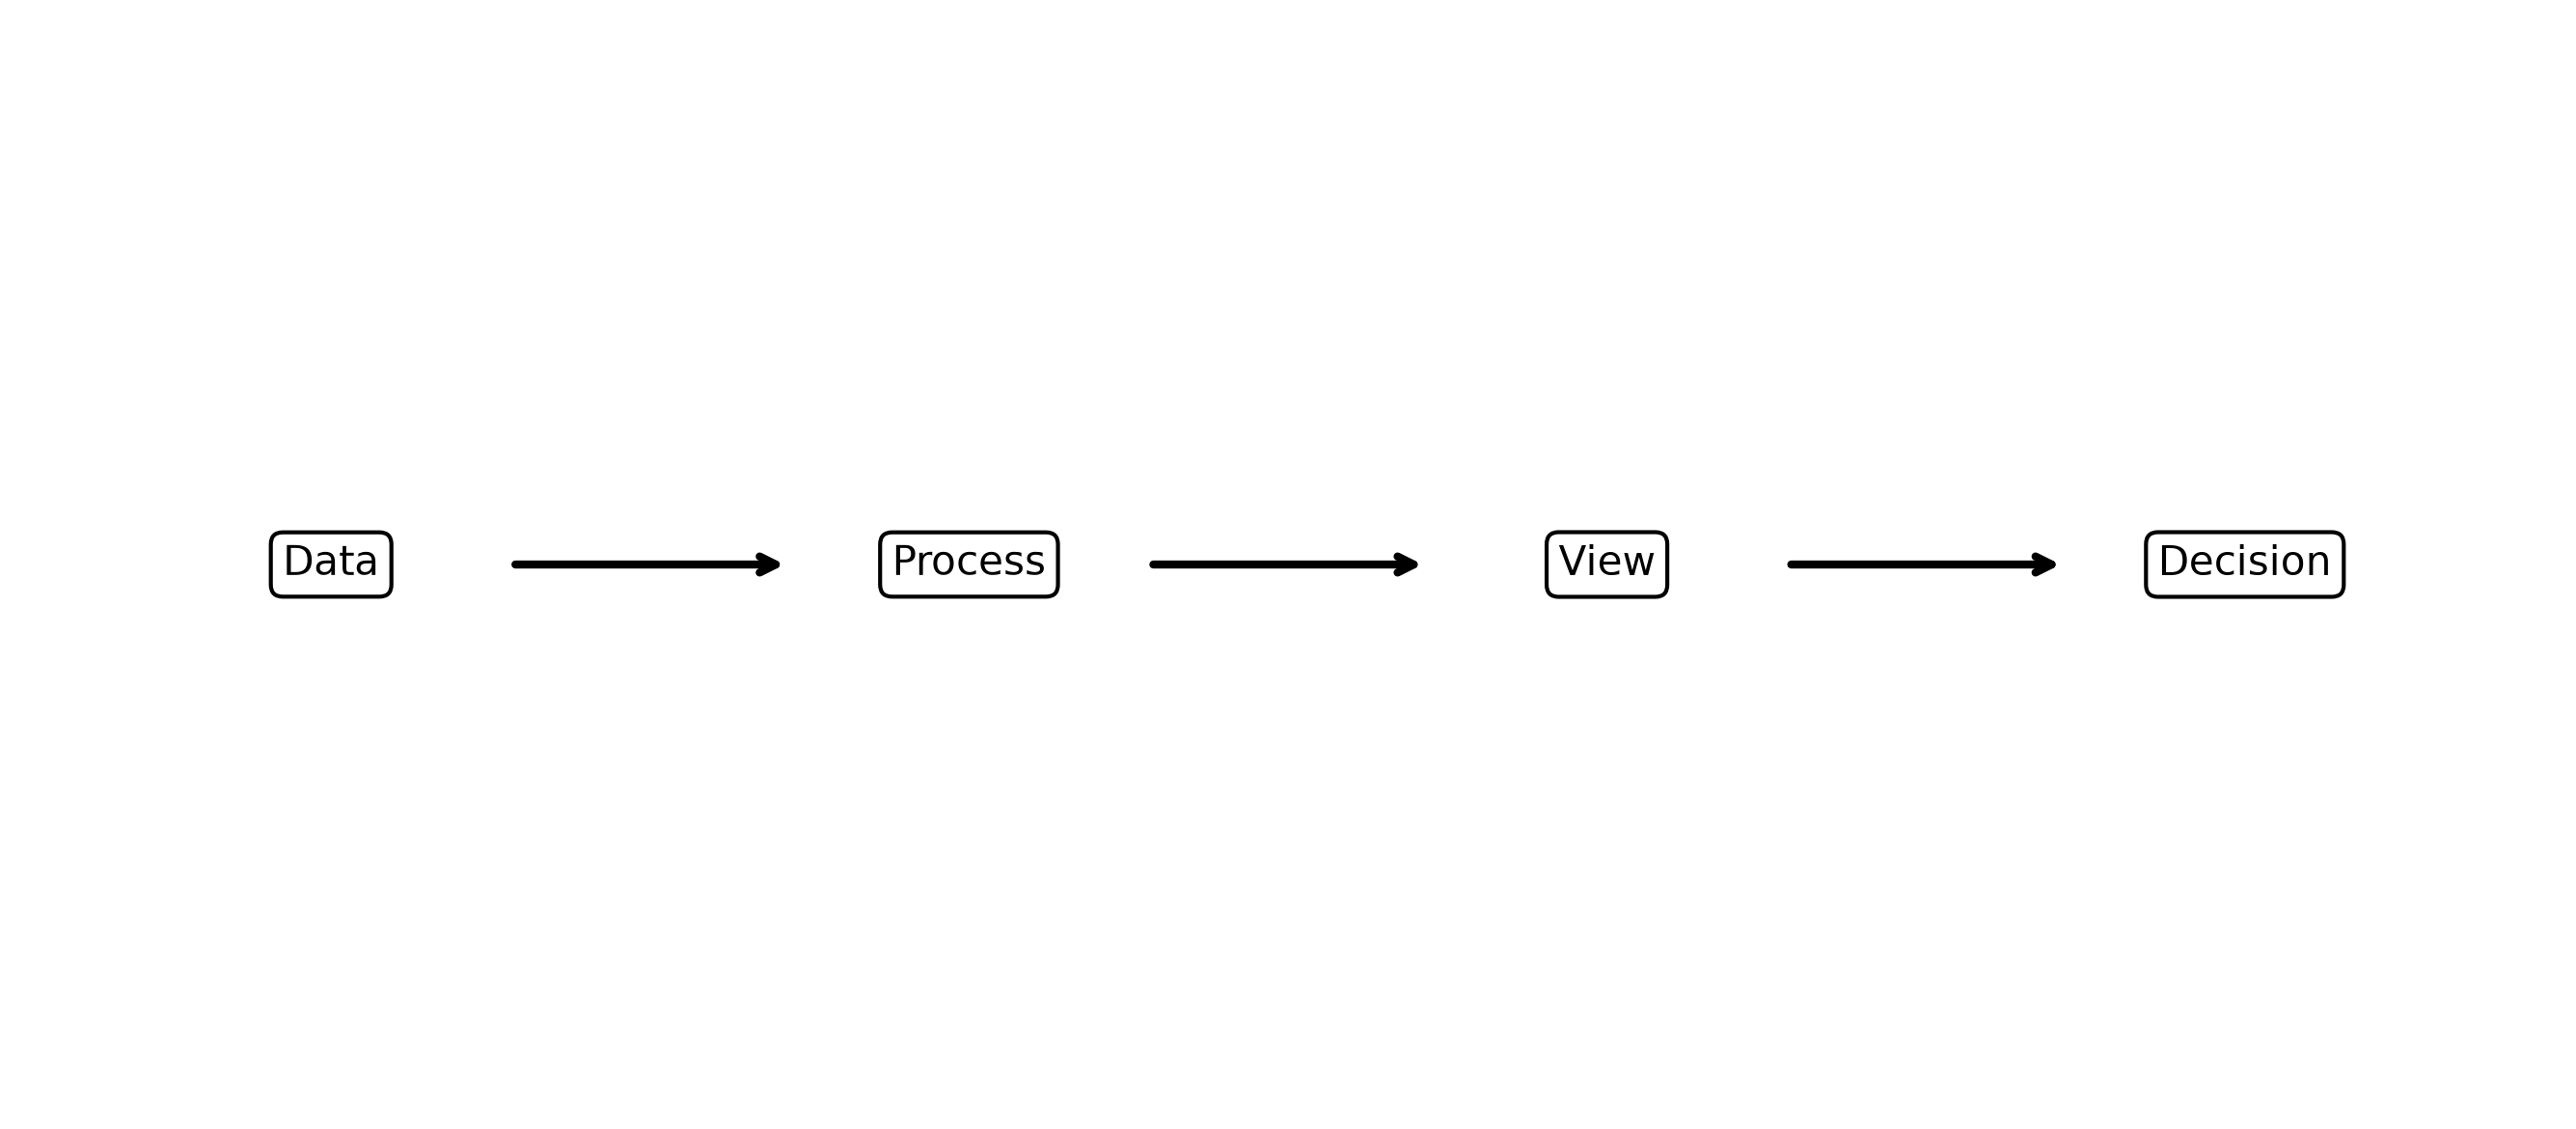


--- paper_12_poor.png (authored baseline) ---


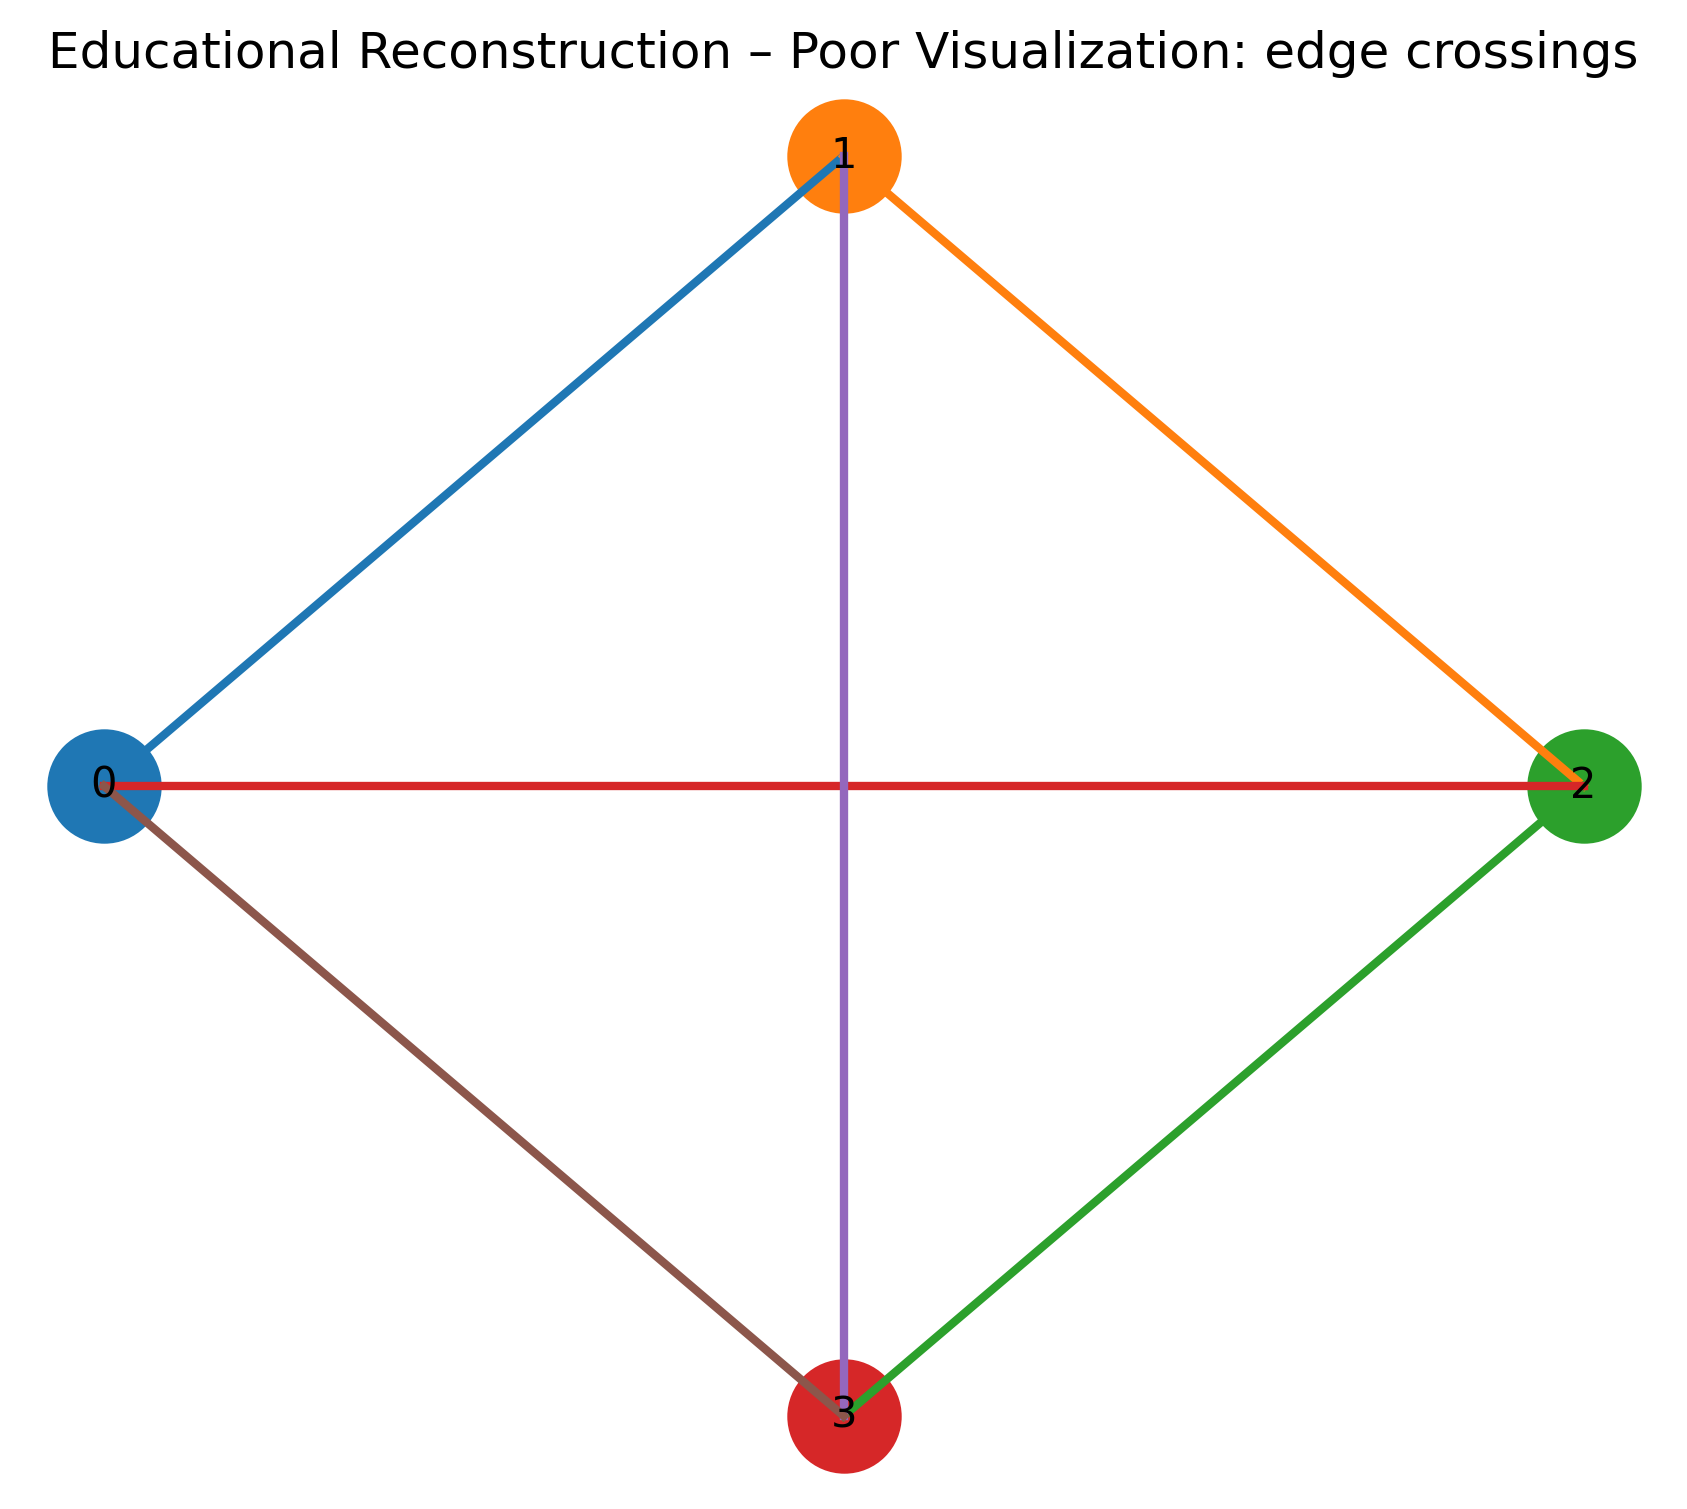

--- paper_12_improved.png (regenerated by this notebook) ---


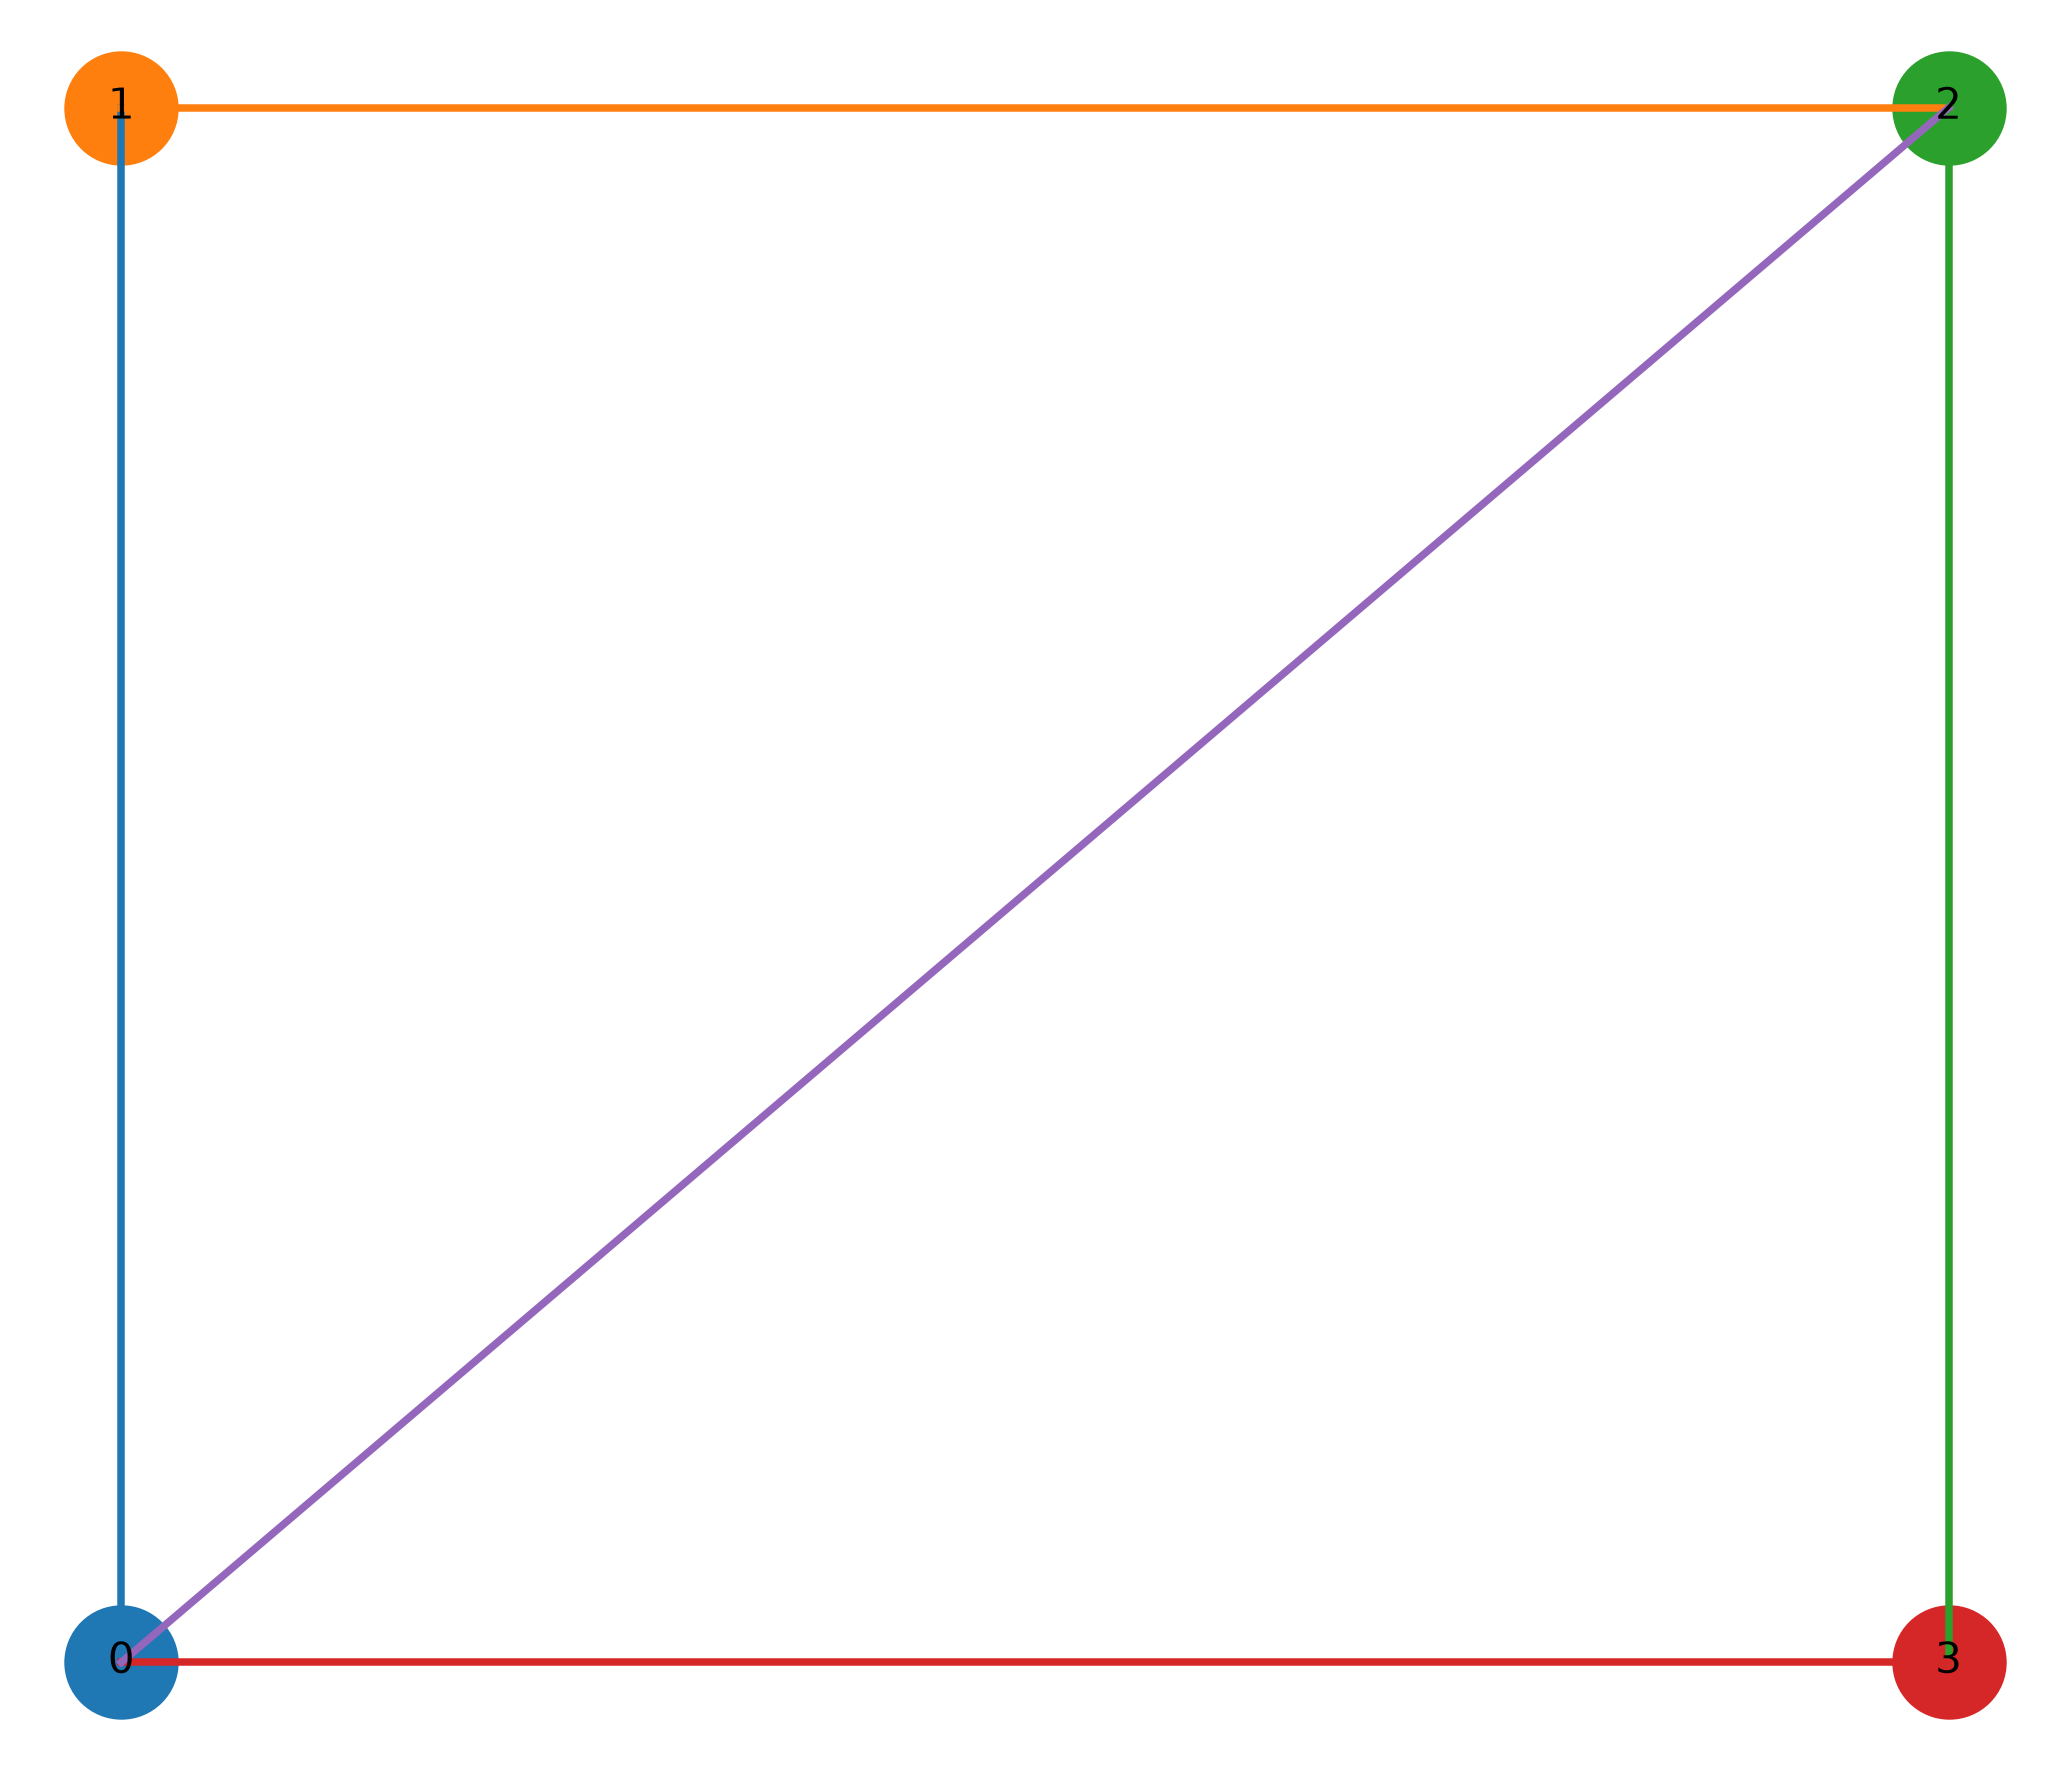


--- paper_13_poor.png (authored baseline) ---


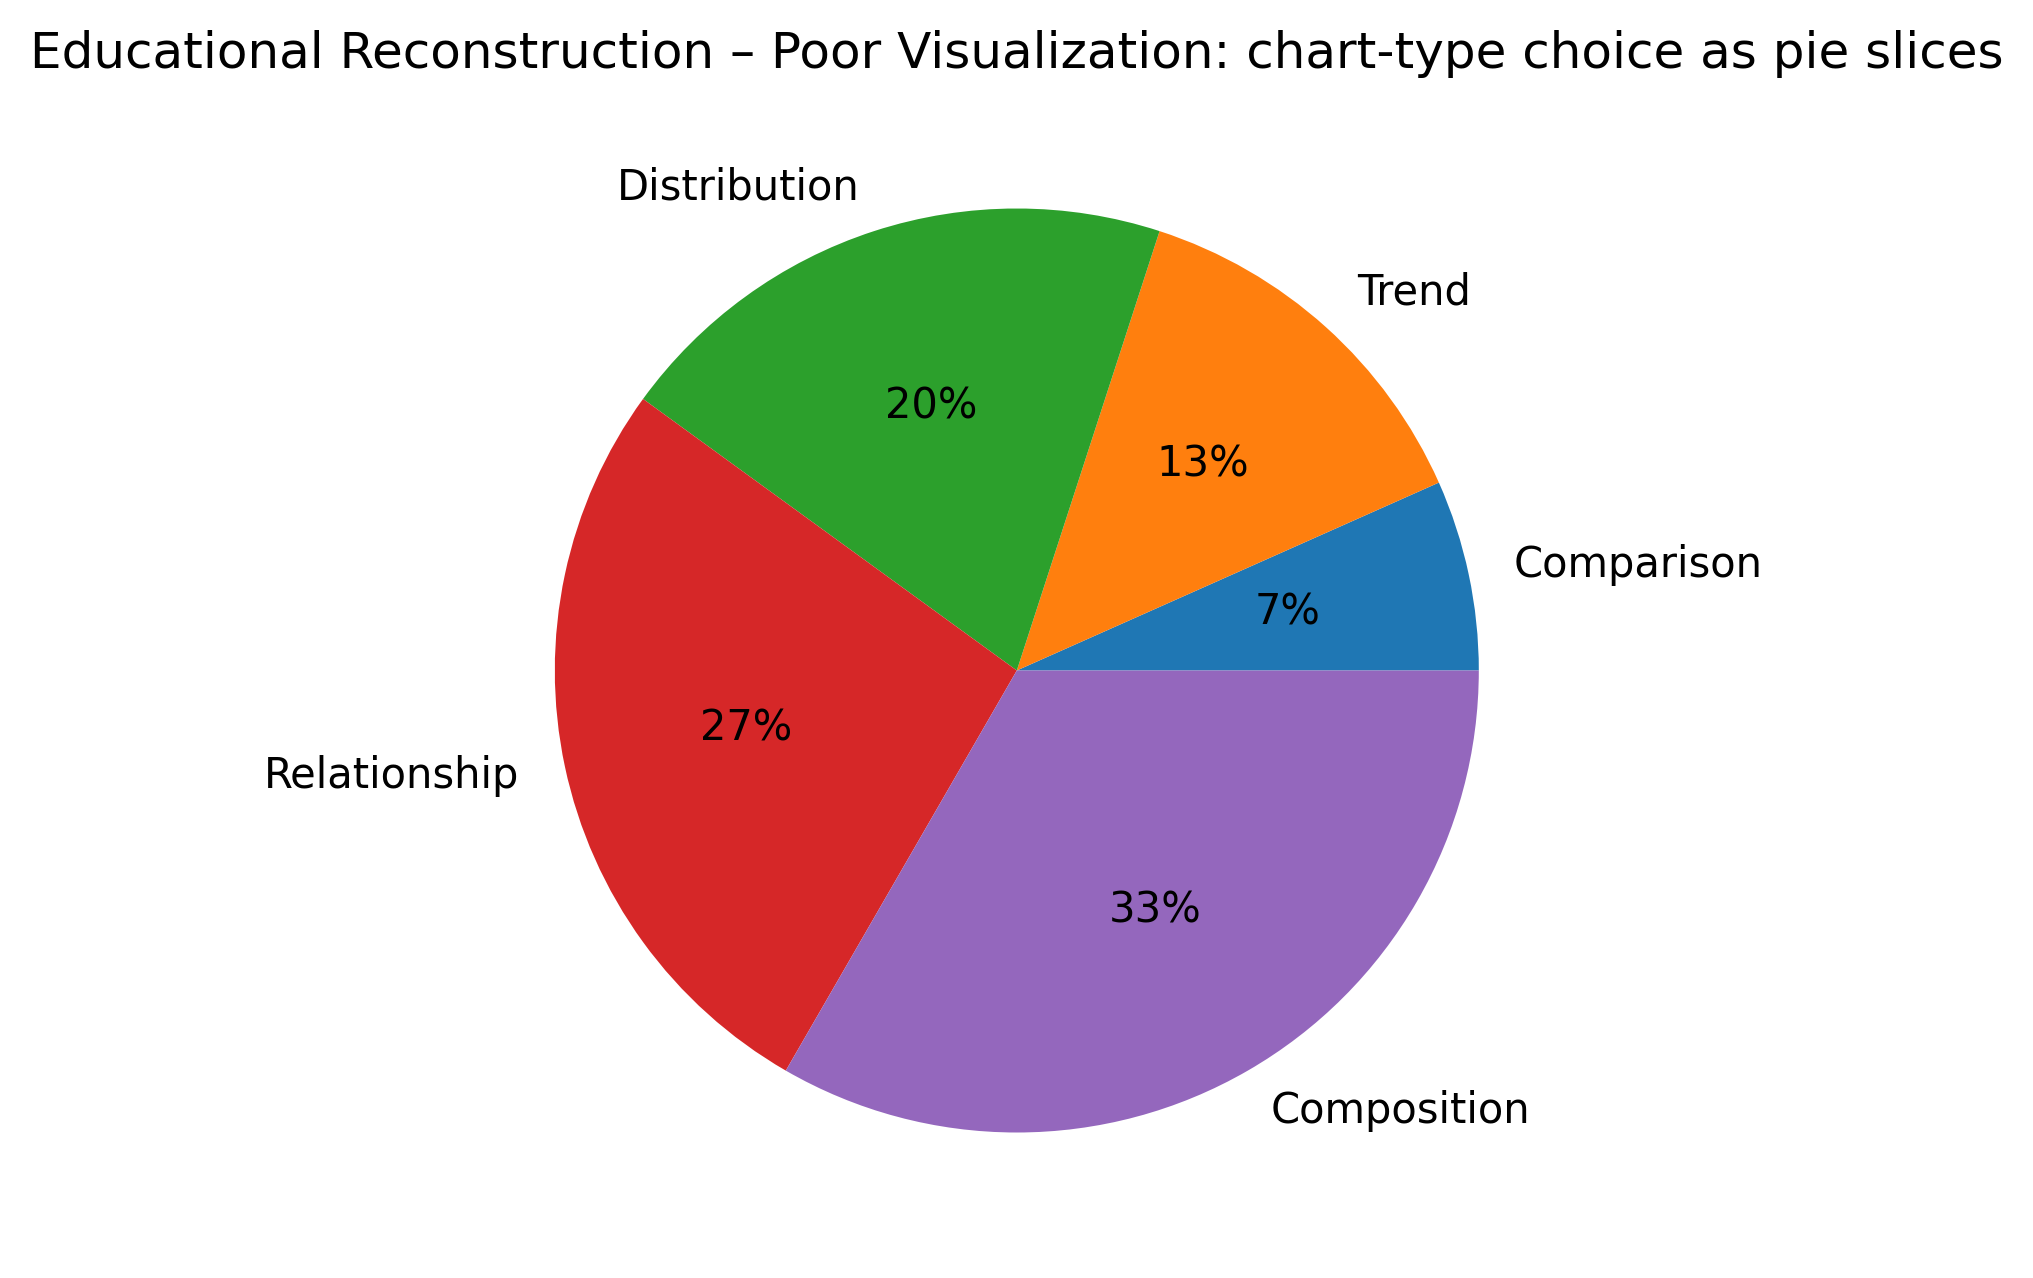

--- paper_13_improved.png (regenerated by this notebook) ---


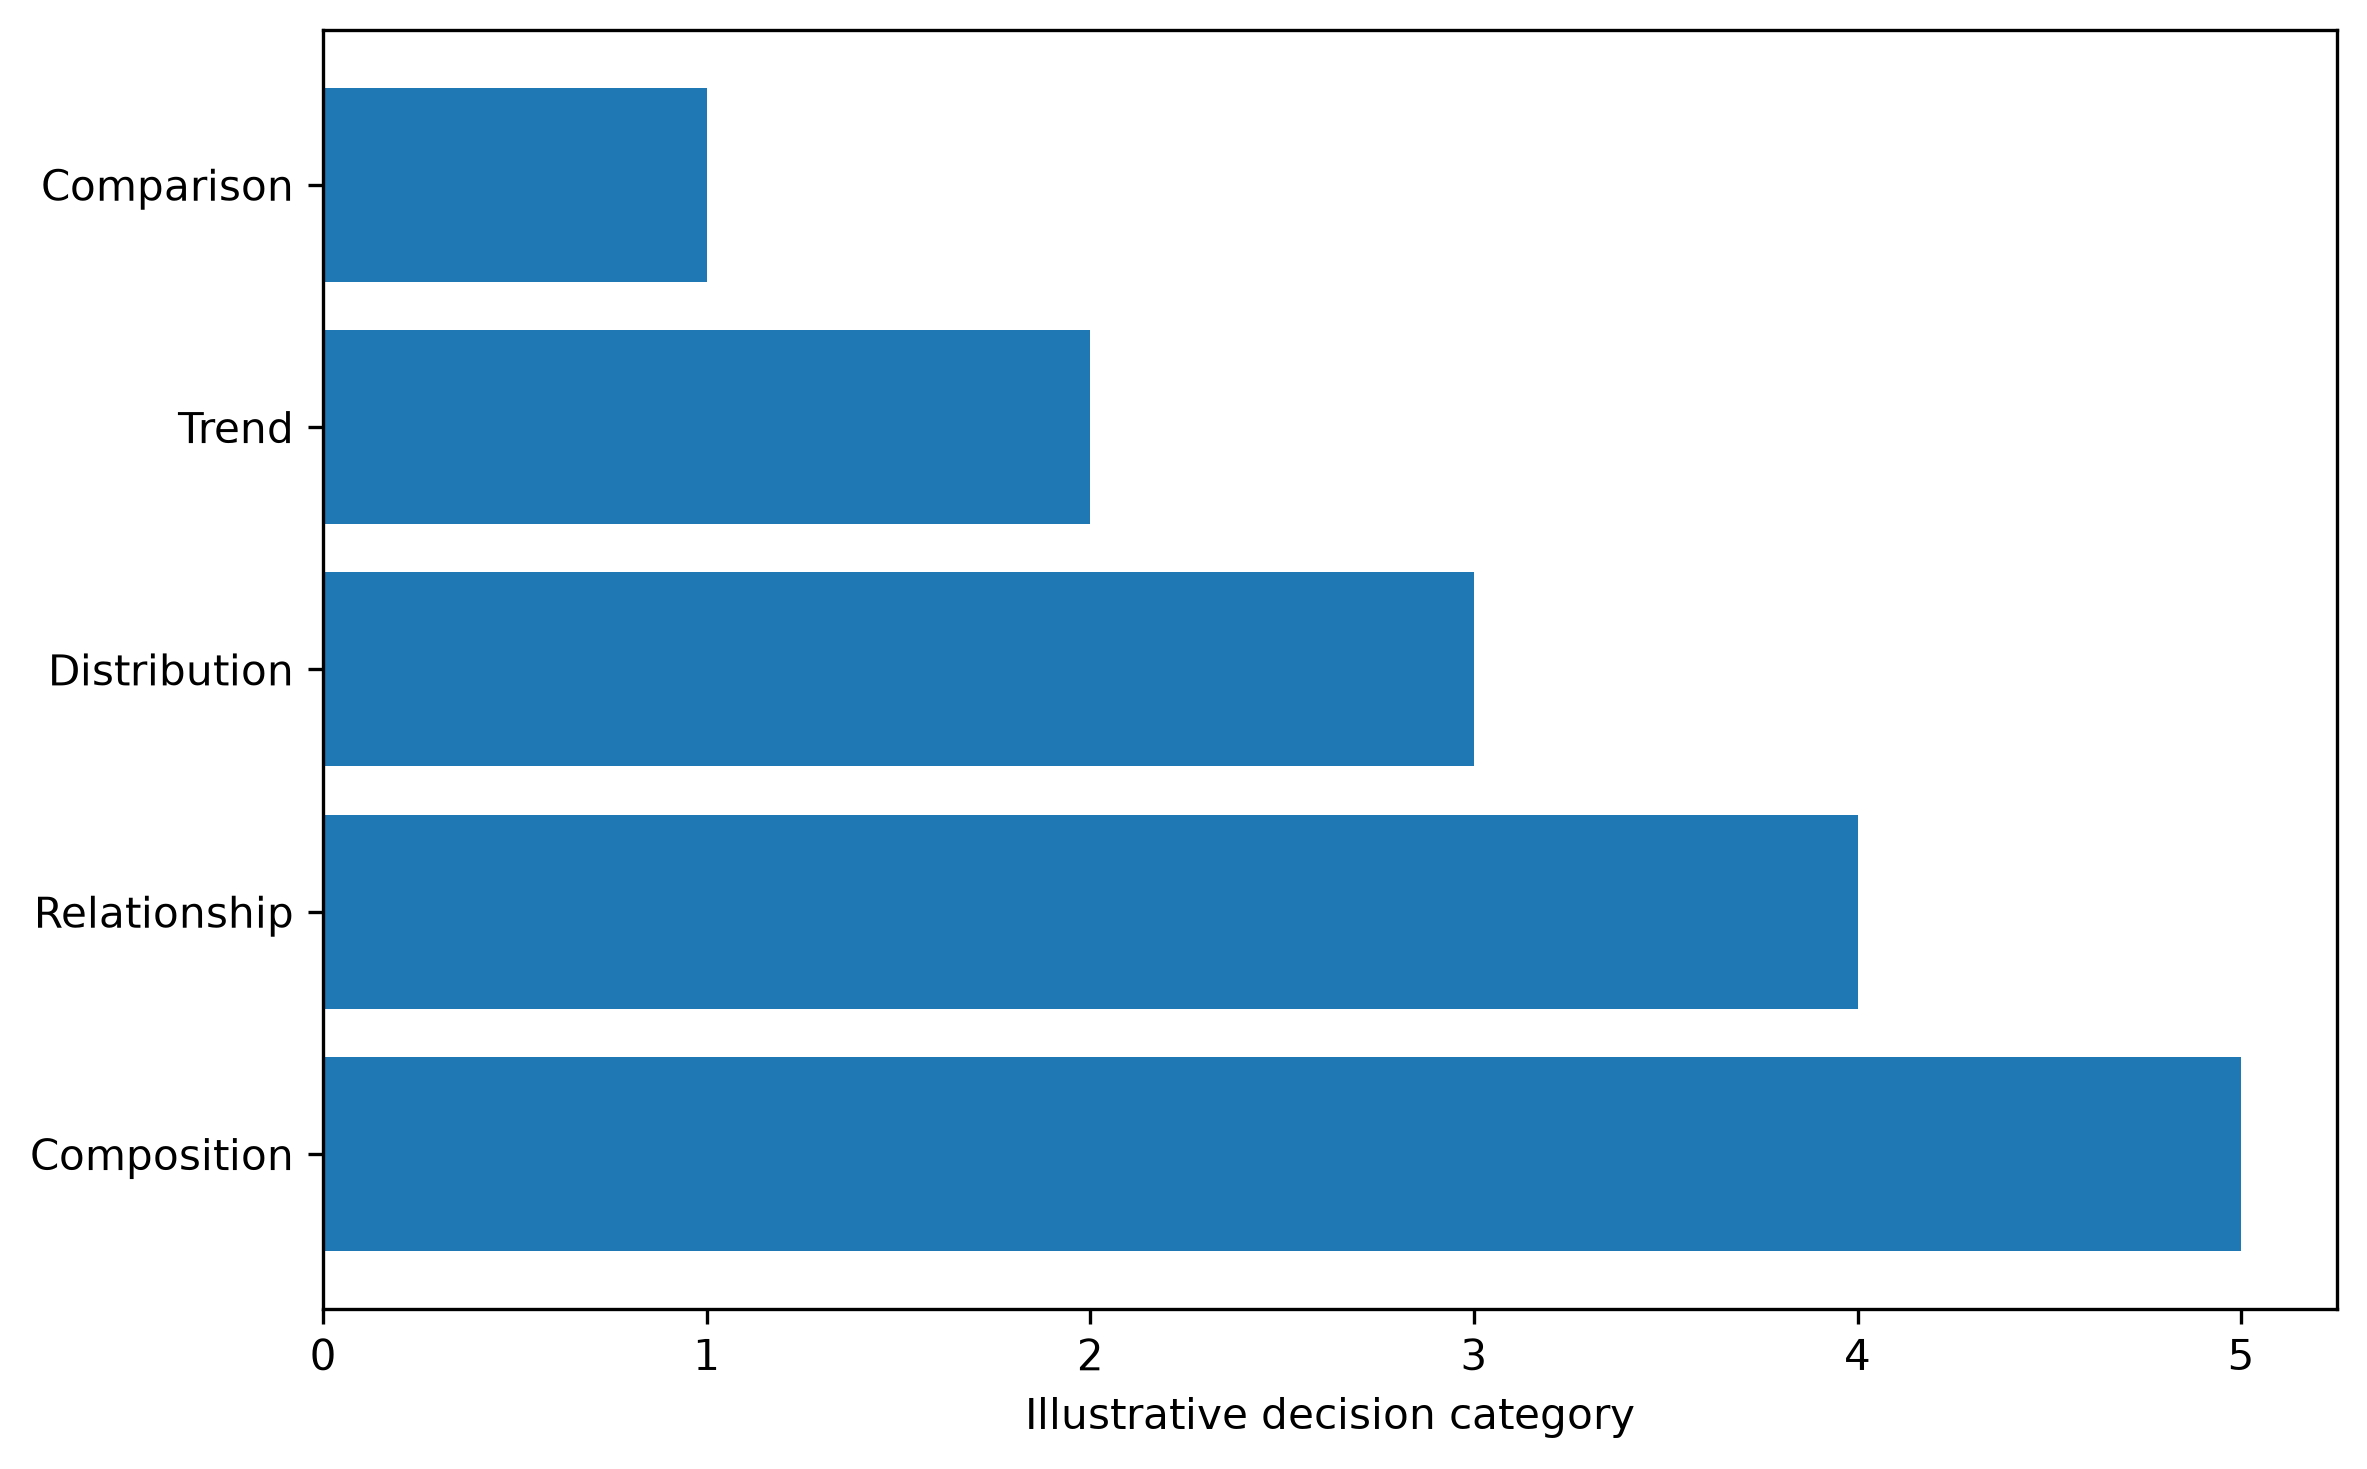


--- paper_14_poor.png (authored baseline) ---


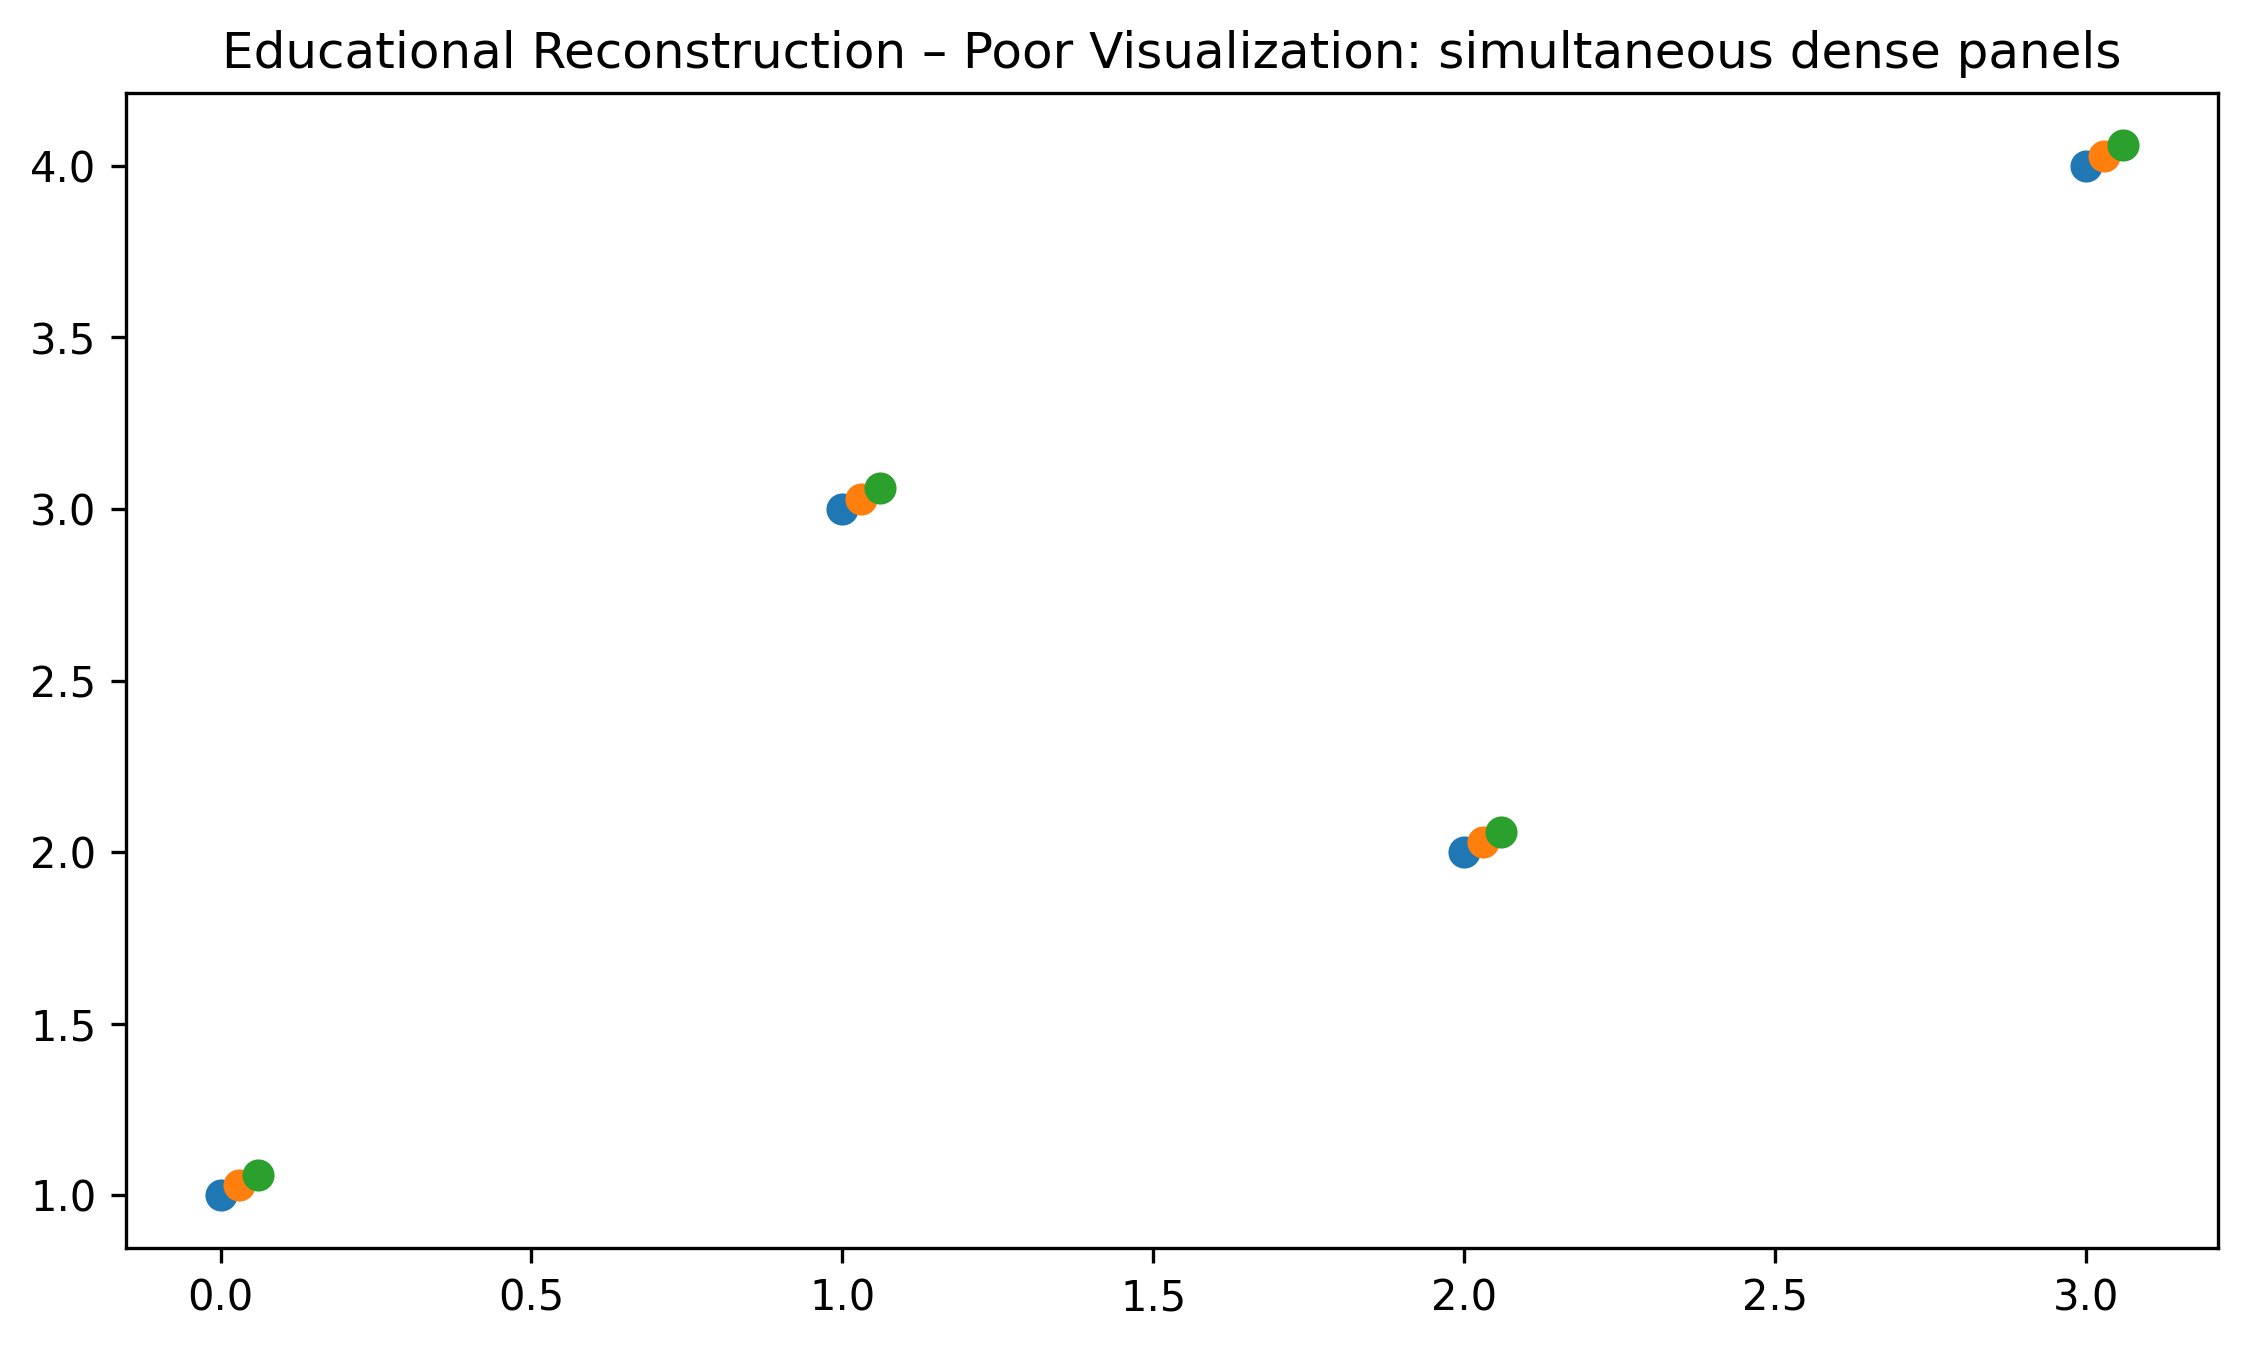

--- paper_14_improved.png (regenerated by this notebook) ---


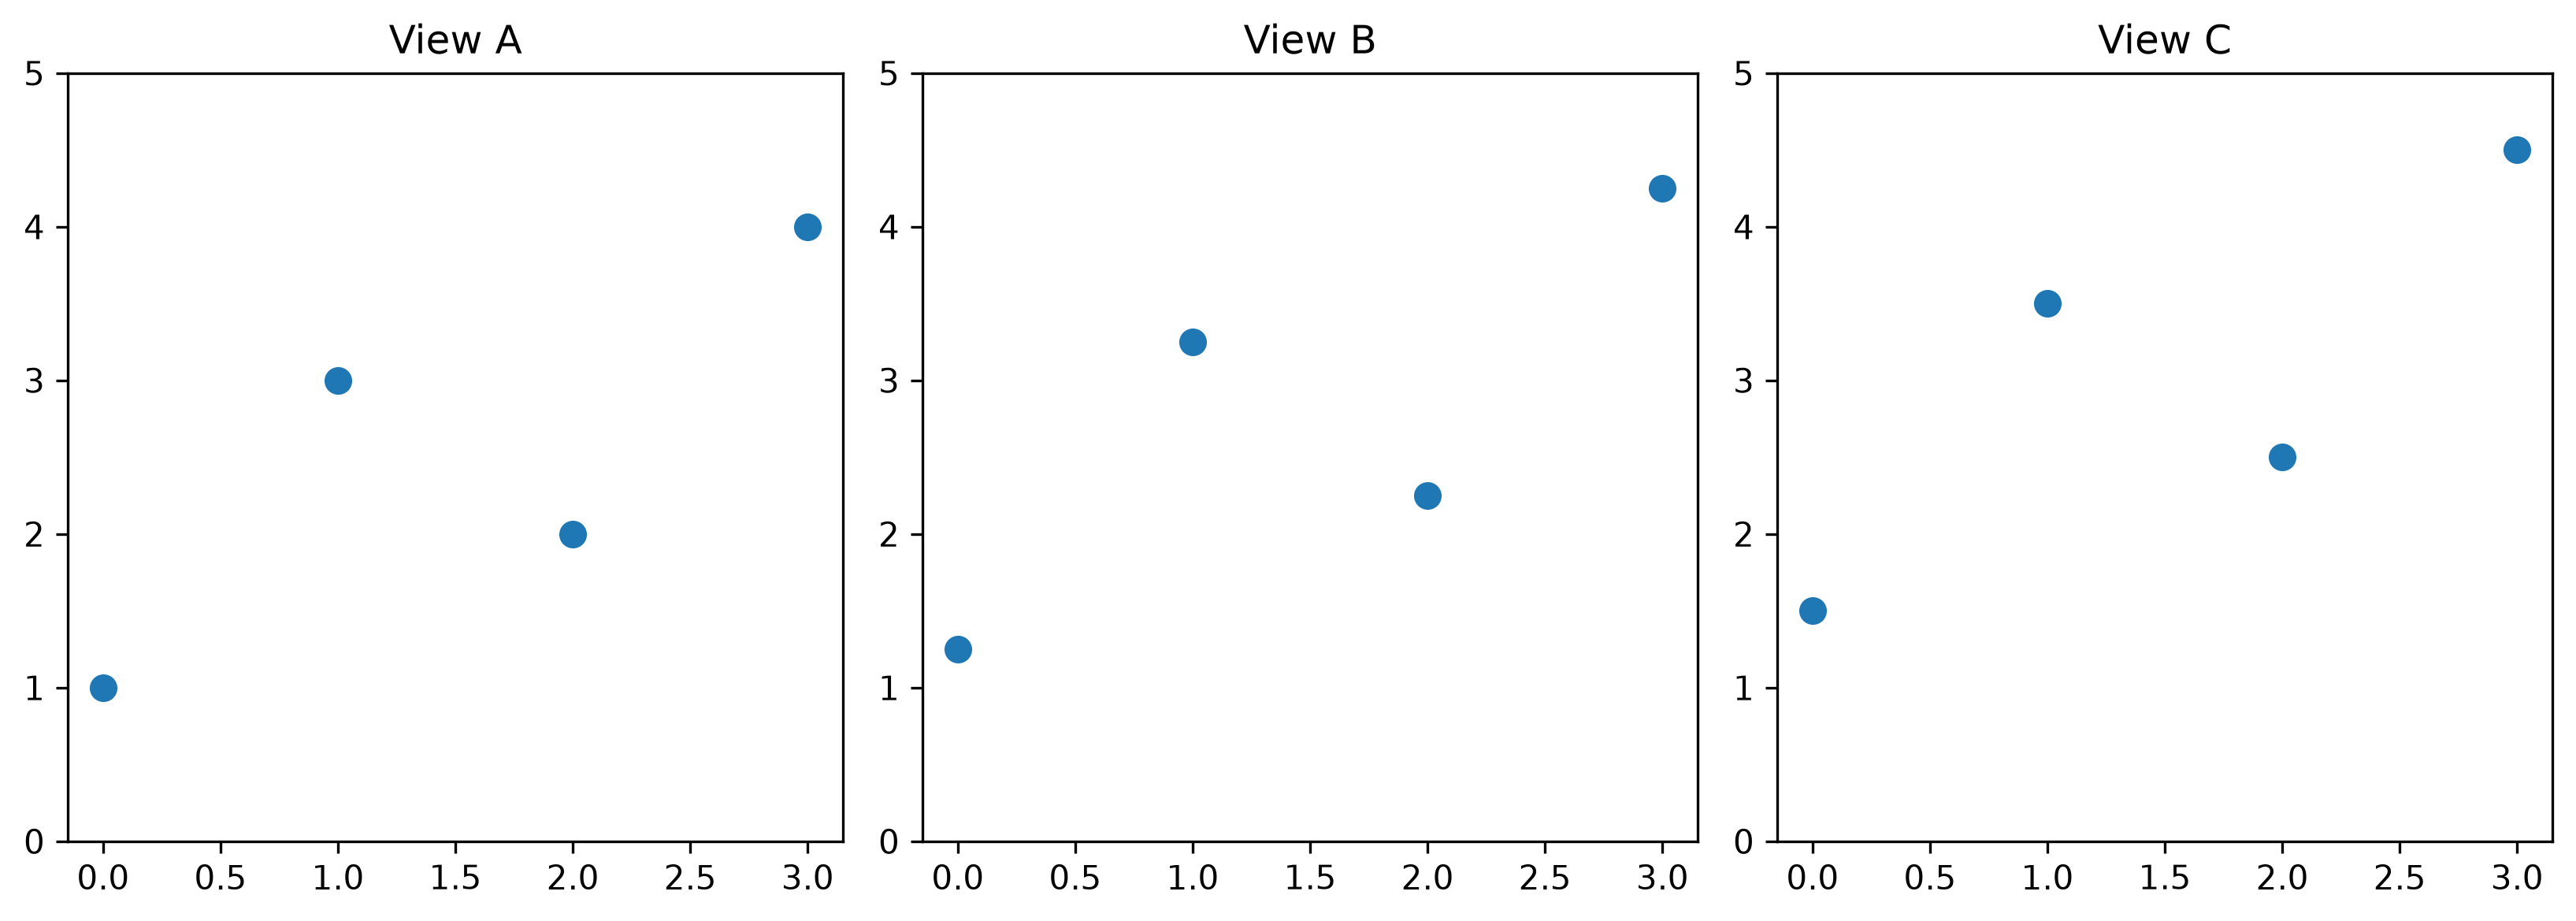


--- paper_15_poor.png (authored baseline) ---


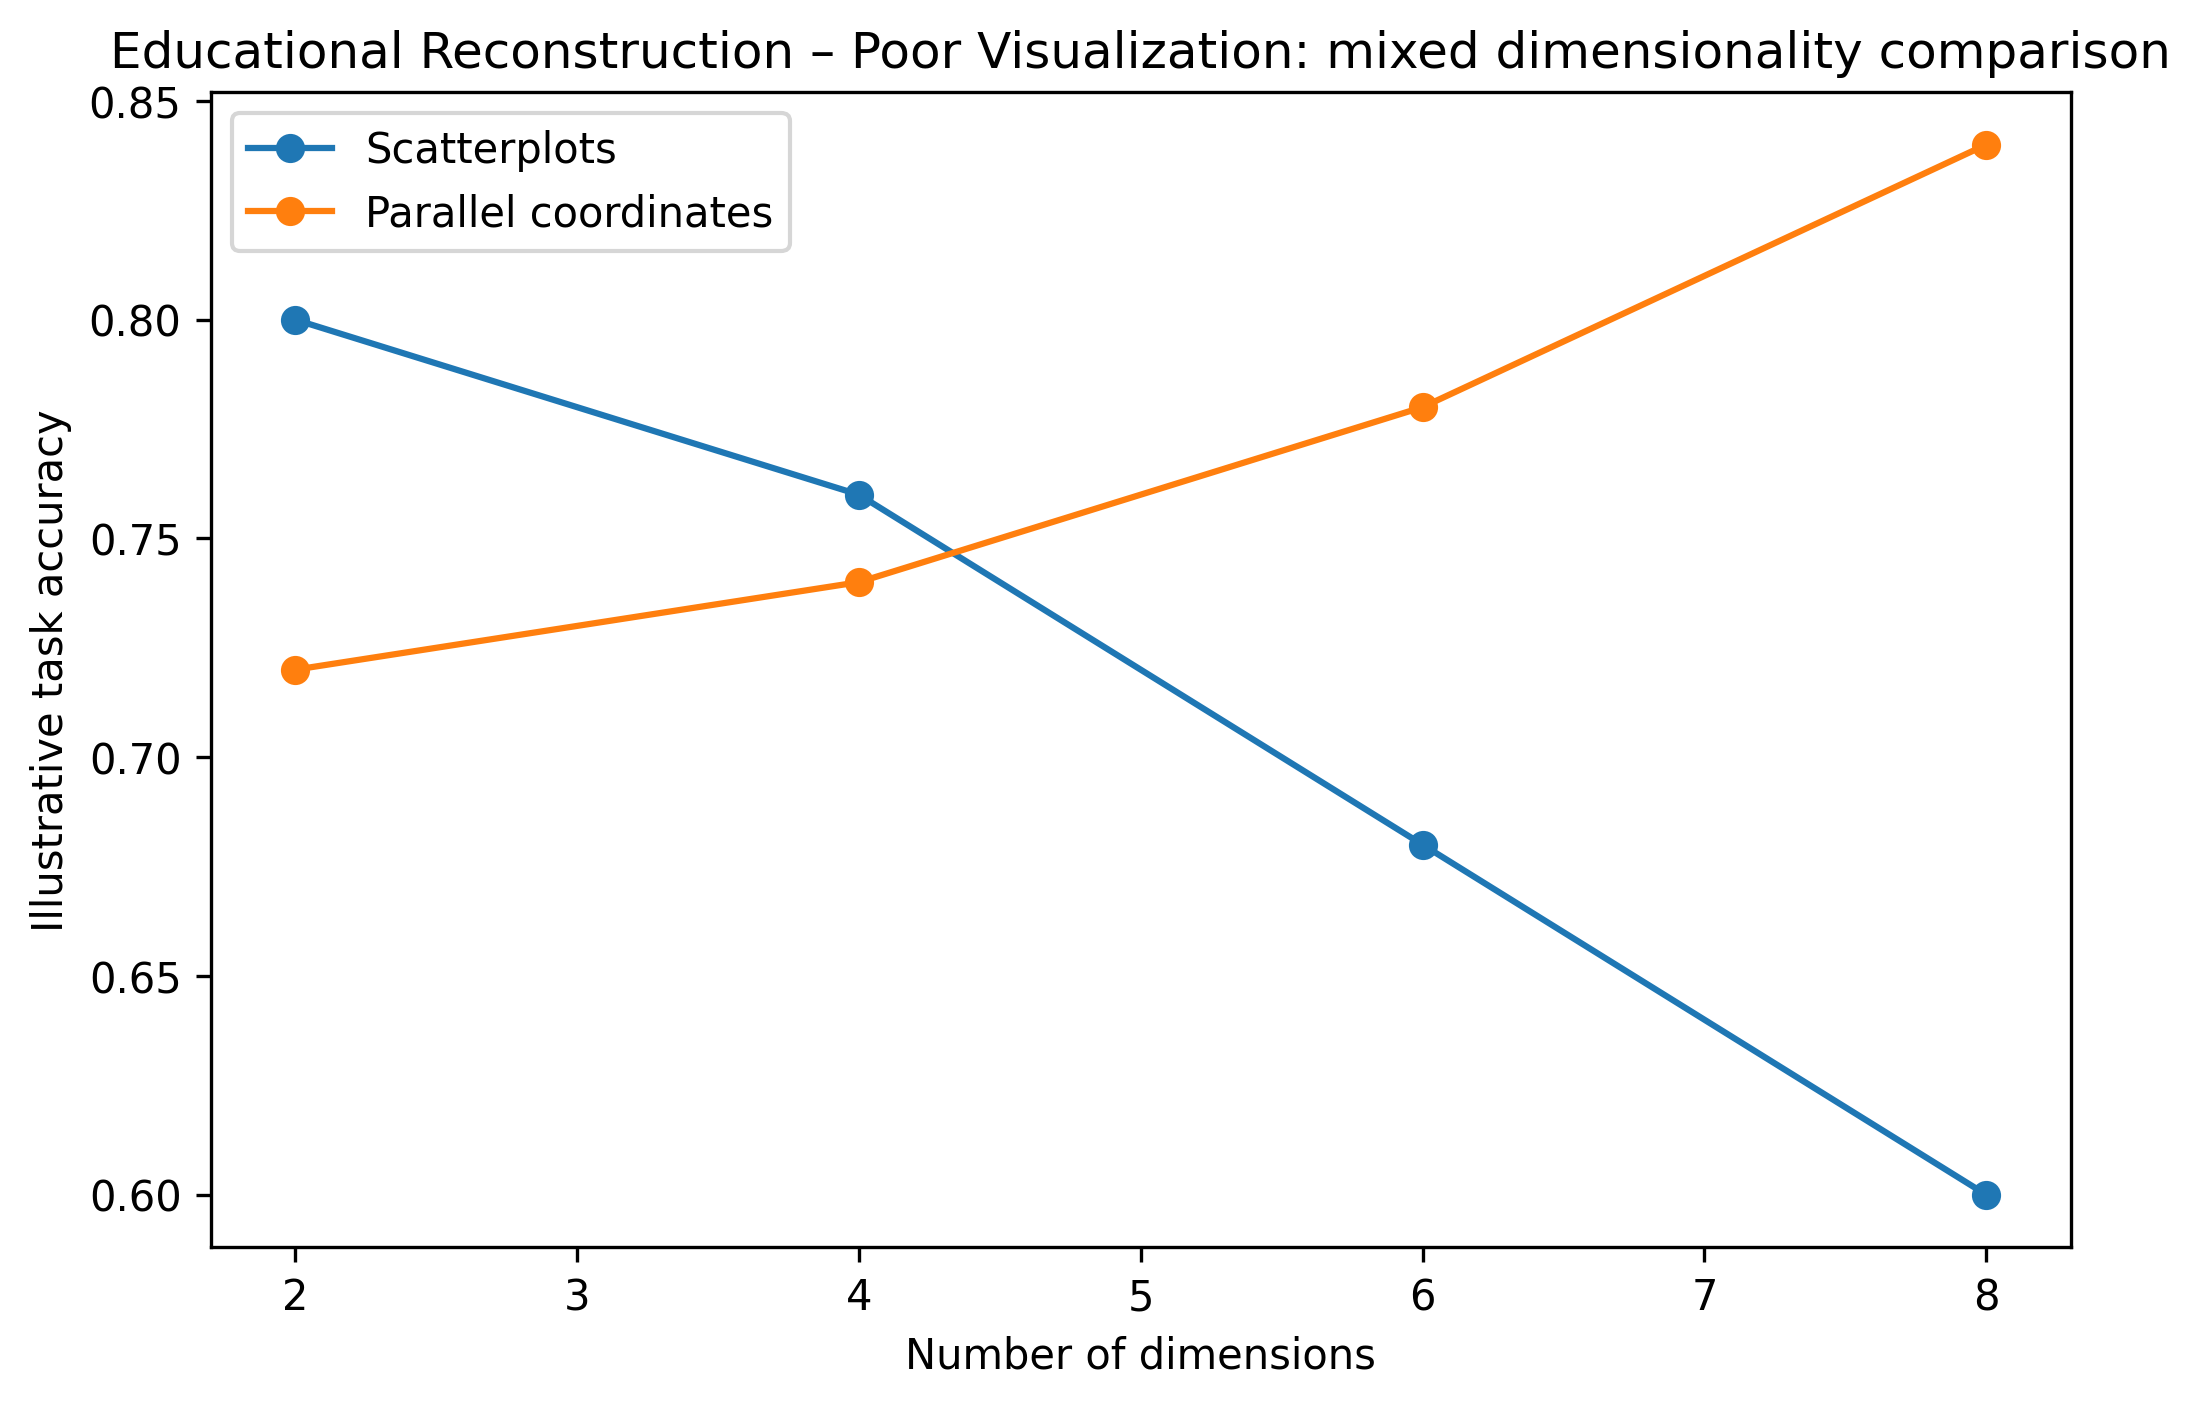

--- paper_15_improved.png (regenerated by this notebook) ---


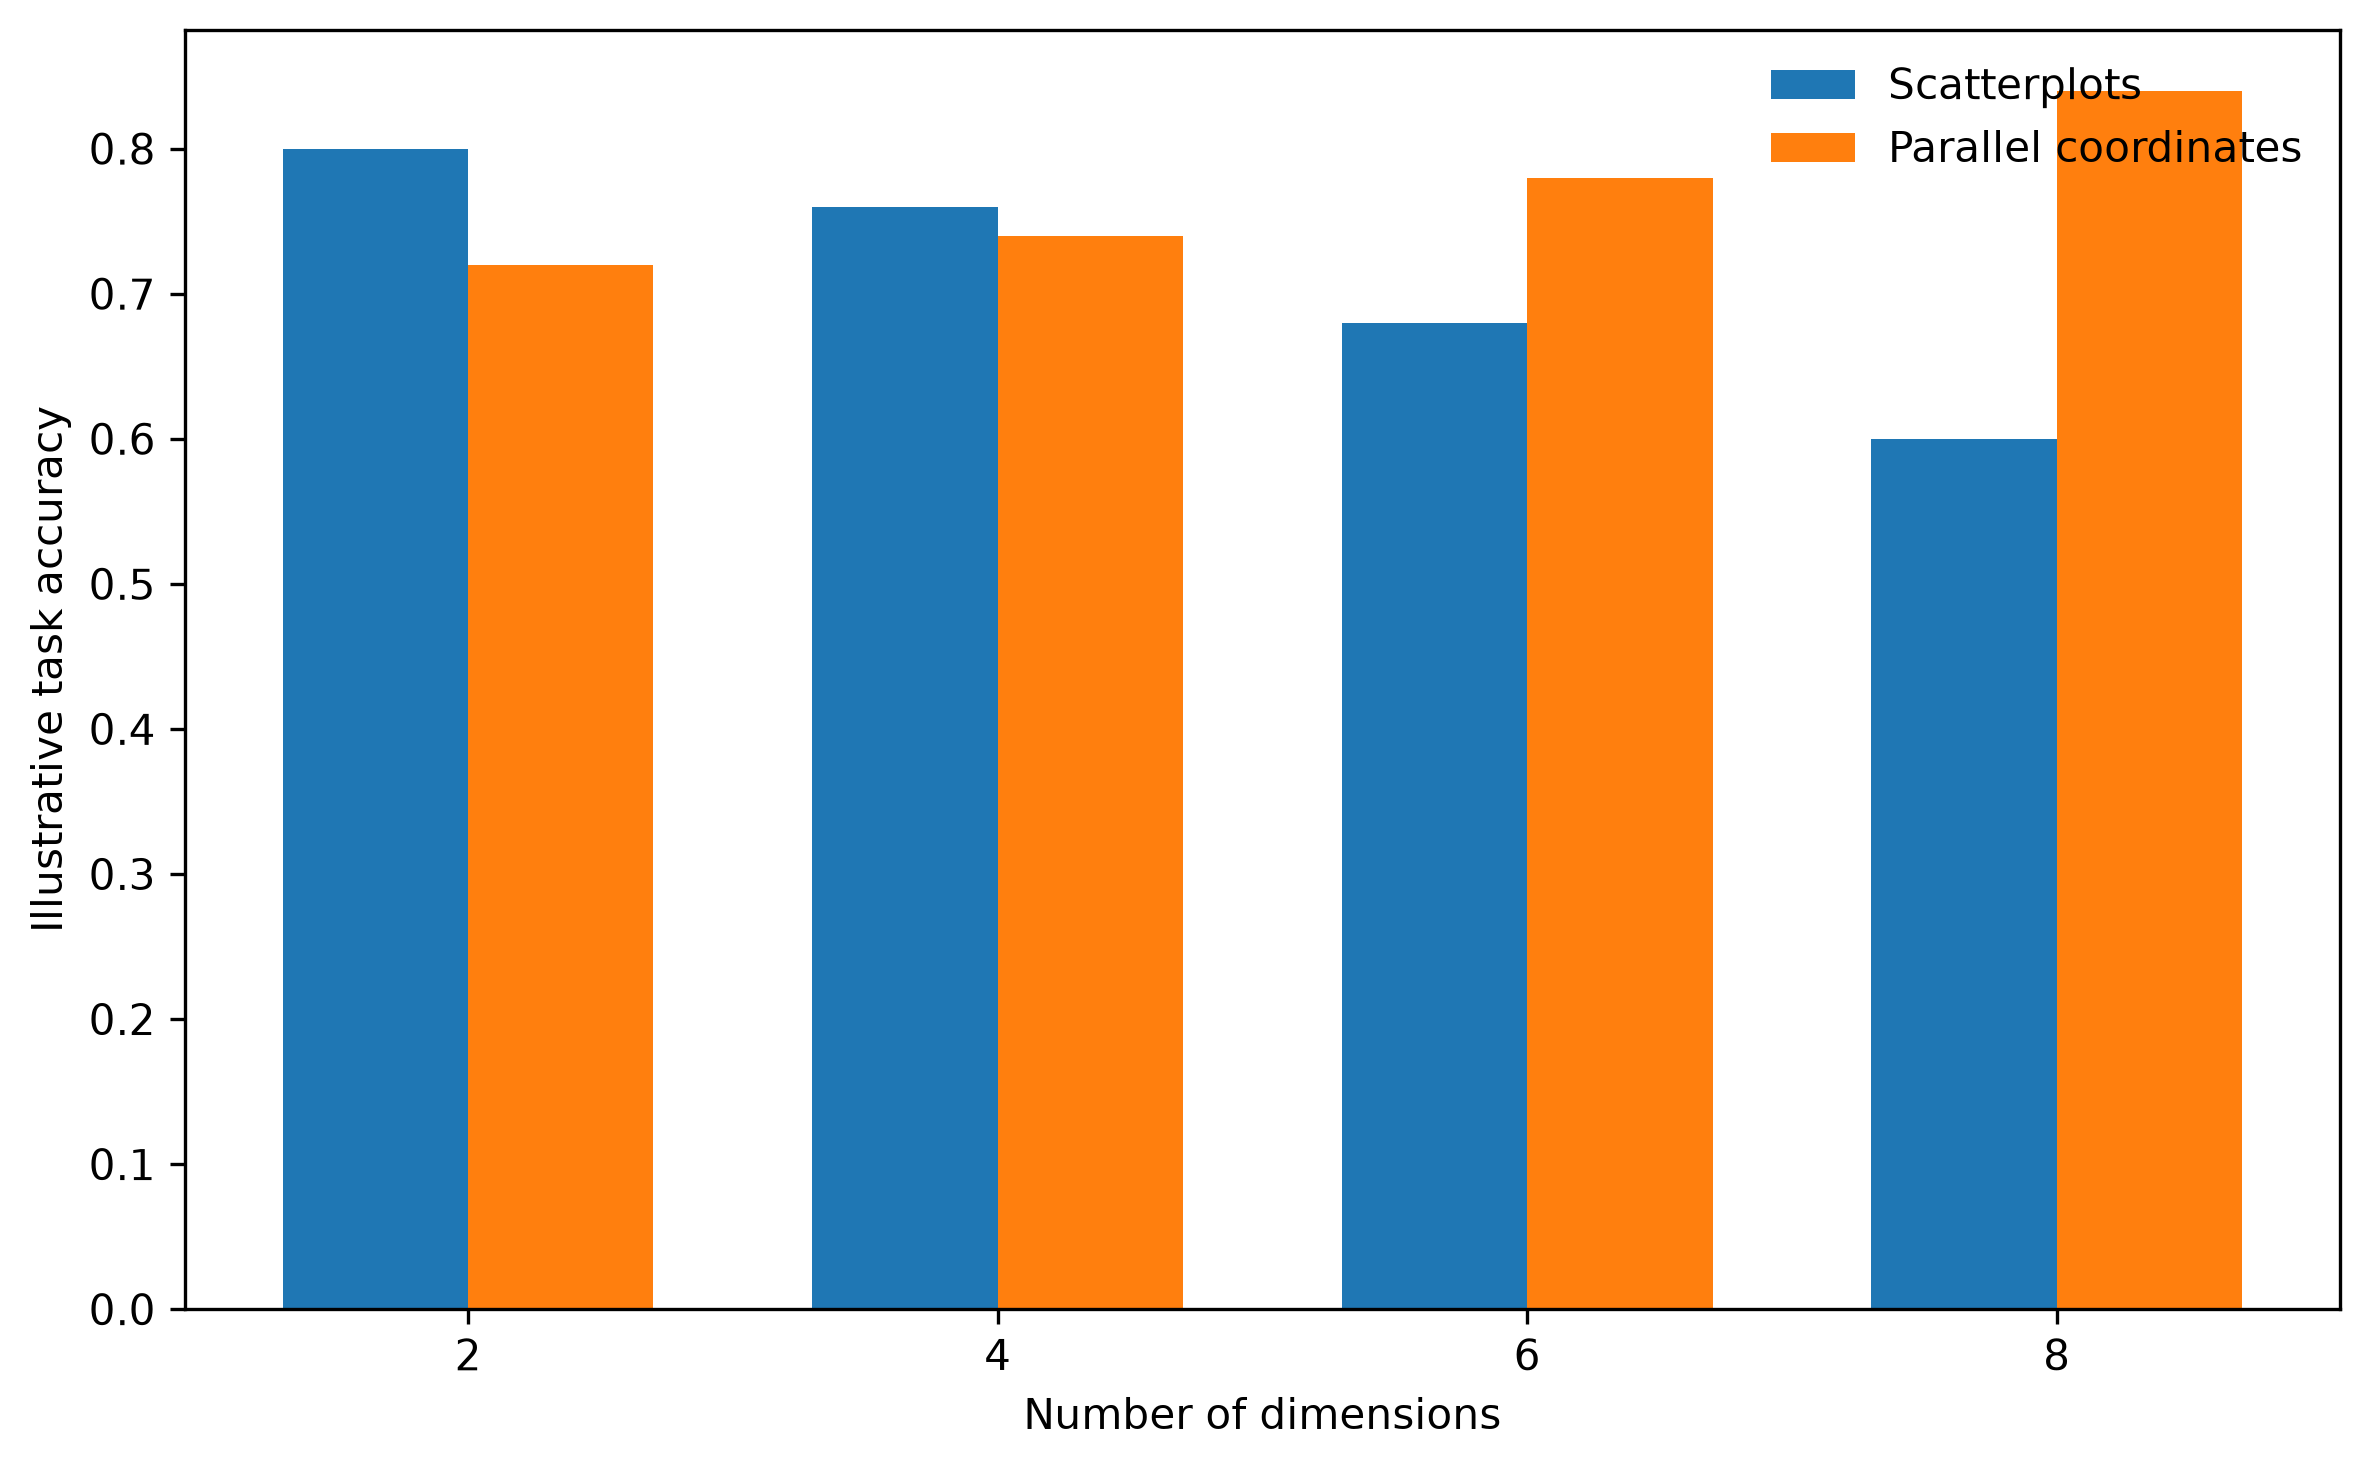

In [36]:

from IPython.display import Image, display

search_dirs = [VIS_DIR, Path.cwd() / "visualizations", Path.cwd() / "15-paper-redesign" / "visualizations"]
poor_files = {}
for d in search_dirs:
    for p in sorted(d.glob("paper_*_poor.png")):
        poor_files.setdefault(p.name, p)

if not poor_files:
    print("No pre-authored poor-baseline PNGs in this runtime.")
    print("The 15 improved redesigns above are regenerated in full by this notebook.")
else:
    print(f"{len(poor_files)} poor-baseline figure(s) found")
    for name in sorted(poor_files):
        improved = VIS_DIR / name.replace("_poor", "_improved")
        print(f"\n--- {name} (authored baseline) ---")
        display(Image(filename=str(poor_files[name]), width=760))
        if improved.exists():
            print(f"--- {improved.name} (regenerated by this notebook) ---")
            display(Image(filename=str(improved), width=760))


## 5. Results

* **18 figures** produced in total: 3 EXERCISE-2 visualizations + 15 paper redesigns,
  all generated from Python source rather than hand-drawn.
* Every improved figure keeps **one unit per axis**, prints its **values directly on the
  marks**, and uses colour only where it carries meaning.
* Each of the fifteen redesigns names the specific readability problem it removes
  (dense multi-stage flow, segment misalignment, overplotted polylines, edge
  crossings, small-multiple density, …).
* The poor/research baselines remain available as authored evidence of the *before*
  state; they are never silently re-generated.

**Reproduce locally**

```bash
cd experiment-2/15-paper-redesign
python python/run_all_visualizations.py     # writes all 15 improved PNGs
python python/research_visualization_redesigns.py
```

**Sources** — `15_paper_selection_table.csv`, `research_paper_bibliography.txt`,
`paper_download_verification.csv`, and the EXERCISE-2 record documents in
`experiment-2/records/`.
